# Modelado: combinaciones con los estadísticos de la DIF

Continuación de `03_modelado.ipynb`. Se recuperan las métricas por régimen solar de los modelos anteriores, se fija el protocolo experimental, se prueba el entrenamiento con peso nulo en las horas nocturnas y con objetivo nocturno nulo, y se combinan los estadísticos históricos de la DIF con otros bloques de variables. Junto con `03_modelado.ipynb`, corresponde a la primera fase de la Tabla A1 de la memoria. El conjunto de test no se utiliza.

**Uso en la memoria**

- Apartado 5.3.1 e hipótesis H4: combinaciones de la LSTM-DIFstats con SWD, DIR, fracción difusa y variables meteorológicas (parte 4).
- Tabla 11: los denominadores del nMAE en validación calculados en la subsección 2.2 coinciden con los de la memoria.

El resto de las partes 1 a 3 no se utiliza en la memoria. Se conserva porque genera las clasificaciones, el protocolo y las matrices de entrada que usan las siguientes.

**Nomenclatura de este cuaderno**

- M0: DIF y elevación solar.
- M1: estadísticos históricos de la DIF (DIFstats): DIF, elevación solar, desviación intraminutal y rango horario de la DIF. Son la LSTM-DIFstats y la N-BEATS-DIFstats de `03_modelado.ipynb`.
- M2: DIFstats y SWD. M3: DIFstats, SWD y DIR. M4: DIFstats, SWD, DIR y fracción difusa.
- M5: DIFstats y presión media. M6: DIFstats, terna cuadrática de temperatura y humedad y presión media.

Estos códigos no tienen relación con los modelos Ridge y HGB de `03_modelado.ipynb` (M1-Ridge-DIF, M3-HGB…).

**Ejecución**

- Lee y escribe en la misma carpeta persistente de Google Drive que las partes 5 y 6 de `03_modelado.ipynb` (`BASE_DIR`), de la que toma sus resultados. Para volver a ejecutarlo hay que apuntar `BASE_DIR` a la copia de esa carpeta incluida en el repositorio.
- Dos celdas se interrumpieron con un error y se conservan porque las siguientes usan los objetos que crearon antes de interrumpirse; cada una lleva una nota.

**Contenido**

1. Recuperación de resultados y clasificación de modelos
2. Protocolo experimental y máscara nocturna
3. Entrenamiento con máscara nocturna y objetivo nocturno nulo
4. Combinaciones de los estadísticos de la DIF con otros bloques

## 1. Recuperación de resultados y clasificación de modelos

> *Parte complementaria: no se utiliza en la memoria. Se conserva porque genera las métricas por régimen y las clasificaciones de las que parte el protocolo de la parte 2.*

### 1.1 Recuperación de métricas por régimen solar

Se recuperan, sin reentrenar, las predicciones de validación de once modelos LSTM y N-BEATS que aún no disponían de métricas por régimen solar y se calculan sus métricas en los ámbitos global, operación, completamente diurno, transición y noche. Con el mismo criterio se reconstruyen las métricas por régimen de las referencias: persistencias simple, diaria e híbrida, `Ridge G0` y HGB de 8 variables.

In [ ]:
from google.colab import drive

drive.mount("/content/drive", force_remount=False)
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
import pandas as pd
import numpy as np
import json
import re
import unicodedata

# 1. Rutas del proyecto
BASE_DIR = Path("/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado")
RESULTADOS_DIR = BASE_DIR / "resultados"
EJECUCIONES_DIR = RESULTADOS_DIR / "ejecuciones"
COMPARATIVAS_DIR = RESULTADOS_DIR / "comparativas"
assert BASE_DIR.exists(), f"No existe BASE_DIR:\n{BASE_DIR}"
assert RESULTADOS_DIR.exists(), f"No existe:\n{RESULTADOS_DIR}"
print("Entorno restaurado correctamente.")
print("BASE_DIR:", BASE_DIR)

# 2. Localizar la última comparativa relativa a los baselines
comparativas = sorted(
    COMPARATIVAS_DIR.glob("comparacion_relativa_baselines_*"), key=lambda p: p.stat().st_mtime
)
if not comparativas:
    raise FileNotFoundError(
        "No se ha encontrado ninguna carpeta 'comparacion_relativa_baselines_*'."
    )

DIR_COMPARATIVA = comparativas[-1]
print("\nComparativa recuperada:")
print(DIR_COMPARATIVA)
archivos_comparativa = {
    "decision": DIR_COMPARATIVA / "tabla_decision_dependencia_nocturna.csv",
    "relativa": DIR_COMPARATIVA / "comparacion_relativa_formato_largo.csv",
    "metricas": DIR_COMPARATIVA / "metricas_consolidadas_por_ambito.csv",
    "pendientes": DIR_COMPARATIVA / "modelos_pendientes_metricas_regimen.csv",
}
tablas = {}
for nombre, ruta in archivos_comparativa.items():
    if ruta.exists():
        tablas[nombre] = pd.read_csv(ruta)
        print(
            f"  [OK] {ruta.name}: "
            f"{tablas[nombre].shape[0]} filas × "
            f"{tablas[nombre].shape[1]} columnas"
        )
    else:
        print(f"  [NO ENCONTRADO] {ruta.name}")

# 3. Recuperar la lista de modelos pendientes
PENDIENTES_RESPALDO = [
    "LSTM-DIR",
    "LSTM-GeomT",
    "LSTM-SWD+DIR",
    "LSTM-SWD+DIR+FD",
    "LSTM-SWD+FD",
    "NBEATS-DIR",
    "NBEATS-Delta",
    "NBEATS-GeomT",
    "NBEATS-SWD+DIR",
    "NBEATS-SWD+DIR+FD",
    "NBEATS-SWD+FD",
]

def buscar_columna_modelo(df):
    for columna in df.columns:
        if "modelo" in columna.lower() or columna.lower() == "model":
            return columna
    return None

if "pendientes" in tablas:
    col_modelo = buscar_columna_modelo(tablas["pendientes"])
    if col_modelo is None:
        col_modelo = tablas["pendientes"].columns[0]

    modelos_pendientes = (
        tablas["pendientes"][col_modelo].dropna().astype(str).drop_duplicates().tolist()
    )
else:
    modelos_pendientes = PENDIENTES_RESPALDO.copy()

print("\nMODELOS PENDIENTES DE MÉTRICAS POR RÉGIMEN")
print("--------------------------------------------------")
for i, modelo in enumerate(modelos_pendientes, start=1):
    print(f"{i:02d}. {modelo}")

print(f"\nTotal pendientes: {len(modelos_pendientes)}")

# 4. Construir inventario completo de artefactos
extensiones_interes = {
    ".csv",
    ".json",
    ".npz",
    ".npy",
    ".pt",
    ".pth",
    ".keras",
    ".h5",
    ".pkl",
    ".joblib",
    ".parquet",
}
registros = []
for ruta in BASE_DIR.rglob("*"):
    if ruta.is_file() and ruta.suffix.lower() in extensiones_interes:
        stat = ruta.stat()
        registros.append(
            {
                "nombre": ruta.name,
                "extension": ruta.suffix.lower(),
                "tamano_mb": stat.st_size / (1024**2),
                "modificado": datetime.fromtimestamp(
                    stat.st_mtime, tz=ZoneInfo("Europe/Madrid")
                ).isoformat(),
                "ruta": str(ruta),
            }
        )

inventario = pd.DataFrame(registros)
if inventario.empty:
    raise RuntimeError("No se ha encontrado ningún artefacto del modelado.")

inventario = inventario.sort_values(["modificado", "ruta"], ascending=[False, True]).reset_index(
    drop=True
)
print("\nINVENTARIO GENERAL")
print("--------------------------------------------------")
print("Artefactos encontrados:", len(inventario))
print(inventario["extension"].value_counts().to_string())


# 5. Identificar archivos que contienen predicciones
def normalizar_texto(texto):
    texto = unicodedata.normalize("NFKD", str(texto))
    texto = "".join(caracter for caracter in texto if not unicodedata.combining(caracter))
    return re.sub(r"[^a-z0-9]+", "_", texto.lower()).strip("_")

aliases_real = {
    "y_true",
    "y_real",
    "real",
    "observado",
    "valor_real",
    "dif_real",
    "dif_objetivo_t1",
    "target",
    "objetivo",
}
aliases_pred = {
    "y_pred",
    "pred",
    "prediction",
    "prediccion",
    "predicho",
    "dif_predicho",
    "forecast",
}
aliases_fecha = {"instante_objetivo", "timestamp", "datetime", "fecha", "date_time"}
candidatos_predicciones = []
apariciones_modelos = []
csvs = [Path(ruta) for ruta in inventario.loc[inventario["extension"].eq(".csv"), "ruta"]]
for ruta in csvs:
    try:
        cabecera = pd.read_csv(ruta, nrows=0)
        mapa_columnas = {normalizar_texto(c): c for c in cabecera.columns}
        cols_norm = set(mapa_columnas)
        columnas_reales = sorted(cols_norm.intersection(aliases_real))
        columnas_pred = sorted(cols_norm.intersection(aliases_pred))
        columnas_fecha = sorted(cols_norm.intersection(aliases_fecha))
        if columnas_reales and columnas_pred:
            candidatos_predicciones.append(
                {
                    "tipo": "CSV",
                    "columna_real": mapa_columnas[columnas_reales[0]],
                    "columna_pred": mapa_columnas[columnas_pred[0]],
                    "columna_fecha": (mapa_columnas[columnas_fecha[0]] if columnas_fecha else None),
                    "ruta": str(ruta),
                }
            )

        columnas_modelo = [
            c
            for c in cabecera.columns
            if normalizar_texto(c) in {"modelo", "model", "nombre_modelo"}
        ]
        if columnas_modelo:
            col = columnas_modelo[0]
            valores = (
                pd.read_csv(ruta, usecols=[col])[col]
                .dropna()
                .astype(str)
                .drop_duplicates()
                .tolist()
            )
            for valor in valores[:500]:
                apariciones_modelos.append({"modelo_en_archivo": valor, "ruta": str(ruta)})

    except Exception:
        # Un CSV defectuoso no debe detener toda la auditoría
        pass

# Inspección de NPZ
npz_files = [Path(ruta) for ruta in inventario.loc[inventario["extension"].eq(".npz"), "ruta"]]
for ruta in npz_files:
    try:
        with np.load(ruta, allow_pickle=False) as datos_npz:
            claves = list(datos_npz.files)
            claves_norm = {normalizar_texto(k): k for k in claves}
            reales = set(claves_norm).intersection(aliases_real)
            predichas = set(claves_norm).intersection(aliases_pred)
            fechas = set(claves_norm).intersection(aliases_fecha)
            if reales and predichas:
                candidatos_predicciones.append(
                    {
                        "tipo": "NPZ",
                        "columna_real": claves_norm[sorted(reales)[0]],
                        "columna_pred": claves_norm[sorted(predichas)[0]],
                        "columna_fecha": (claves_norm[sorted(fechas)[0]] if fechas else None),
                        "ruta": str(ruta),
                    }
                )
    except Exception:
        pass

df_predicciones = pd.DataFrame(candidatos_predicciones)
df_apariciones = pd.DataFrame(apariciones_modelos)
print("\nARCHIVOS CON PREDICCIONES DETECTADOS")
print("--------------------------------------------------")
print(len(df_predicciones))
if not df_predicciones.empty:
    display(df_predicciones)


# 6. Relacionar cada modelo pendiente con sus posibles archivos
def tokens_modelo(nombre):
    tokens = normalizar_texto(nombre).split("_")

    # Términos que sí ayudan a identificar arquitectura/bloque
    return [token for token in tokens if token not in {"modelo", "model"}]

def puntuacion_coincidencia(modelo, ruta):
    texto = normalizar_texto(ruta)
    tokens = tokens_modelo(modelo)
    return sum(token in texto for token in tokens)

fuentes_busqueda = []

# Archivos que contienen predicciones
if not df_predicciones.empty:
    for ruta in df_predicciones["ruta"]:
        fuentes_busqueda.append({"tipo_fuente": "predicciones", "ruta": ruta})

# Archivos con pesos o modelos serializados
mask_pesos = inventario["extension"].isin([".pt", ".pth", ".keras", ".h5", ".pkl", ".joblib"])
for ruta in inventario.loc[mask_pesos, "ruta"]:
    fuentes_busqueda.append({"tipo_fuente": "pesos/modelo", "ruta": ruta})

# Apariciones en tablas
if not df_apariciones.empty:
    for _, fila in df_apariciones.iterrows():
        fuentes_busqueda.append(
            {"tipo_fuente": f"tabla: {fila['modelo_en_archivo']}", "ruta": fila["ruta"]}
        )

coincidencias = []
for modelo in modelos_pendientes:
    candidatos = []
    for fuente in fuentes_busqueda:
        texto_busqueda = str(fuente["ruta"]) + " " + str(fuente["tipo_fuente"])
        puntuacion = puntuacion_coincidencia(modelo, texto_busqueda)
        if puntuacion > 0:
            candidatos.append(
                {
                    "modelo_pendiente": modelo,
                    "puntuacion": puntuacion,
                    "tipo_fuente": fuente["tipo_fuente"],
                    "ruta": fuente["ruta"],
                }
            )

    if candidatos:
        candidatos = sorted(
            candidatos, key=lambda x: (-x["puntuacion"], x["tipo_fuente"], x["ruta"])
        )

        # Máximo 10 candidatos por modelo para que la salida sea manejable
        coincidencias.extend(candidatos[:10])
    else:
        coincidencias.append(
            {
                "modelo_pendiente": modelo,
                "puntuacion": 0,
                "tipo_fuente": "NO LOCALIZADO",
                "ruta": None,
            }
        )

df_coincidencias = pd.DataFrame(coincidencias)
print("\nCANDIDATOS PARA LOS MODELOS PENDIENTES")
print("--------------------------------------------------")
for modelo in modelos_pendientes:
    bloque = df_coincidencias[df_coincidencias["modelo_pendiente"].eq(modelo)]
    max_score = bloque["puntuacion"].max()
    print(f"\n{modelo} — mejor puntuación: {max_score}")
    display(bloque.sort_values(["puntuacion", "tipo_fuente"], ascending=[False, True]).head(5))

# 7. Mostrar las métricas ya consolidadas
if "metricas" in tablas:
    print("\nMÉTRICAS CONSOLIDADAS YA DISPONIBLES")
    print("--------------------------------------------------")
    display(tablas["metricas"])

if "decision" in tablas:
    print("\nTABLA DE DECISIÓN RECUPERADA")
    print("--------------------------------------------------")
    display(tablas["decision"])

# 8. Guardar la auditoría en Drive
marca = datetime.now(ZoneInfo("Europe/Madrid")).strftime("%Y%m%dT%H%M%S")
DIR_AUDITORIA = EJECUCIONES_DIR / f"auditoria_recuperacion_modelos_{marca}"
DIR_AUDITORIA.mkdir(parents=True, exist_ok=False)
inventario.to_csv(DIR_AUDITORIA / "inventario_artefactos.csv", index=False)
df_predicciones.to_csv(DIR_AUDITORIA / "archivos_con_predicciones.csv", index=False)
df_coincidencias.to_csv(DIR_AUDITORIA / "coincidencias_modelos_pendientes.csv", index=False)
if not df_apariciones.empty:
    df_apariciones.to_csv(DIR_AUDITORIA / "apariciones_modelos_en_tablas.csv", index=False)

resumen = {
    "fecha_auditoria": datetime.now(ZoneInfo("Europe/Madrid")).isoformat(),
    "base_dir": str(BASE_DIR),
    "comparativa_recuperada": str(DIR_COMPARATIVA),
    "n_artefactos": int(len(inventario)),
    "n_archivos_predicciones": int(len(df_predicciones)),
    "modelos_pendientes": modelos_pendientes,
}
with open(DIR_AUDITORIA / "resumen_auditoria.json", "w", encoding="utf-8") as f:
    json.dump(resumen, f, ensure_ascii=False, indent=2)

print("\nAUDITORÍA GUARDADA")
print("--------------------------------------------------")
print(DIR_AUDITORIA)

Mounted at /content/drive
Entorno restaurado correctamente.
BASE_DIR: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado

Comparativa recuperada:
/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/comparativas/comparacion_relativa_baselines_20261006T223100Z
  [OK] tabla_decision_dependencia_nocturna.csv: 22 filas × 25 columnas
  [OK] comparacion_relativa_formato_largo.csv: 110 filas × 13 columnas
  [OK] metricas_consolidadas_por_ambito.csv: 131 filas × 9 columnas
  [OK] modelos_pendientes_metricas_regimen.csv: 11 filas × 9 columnas

MODELOS PENDIENTES DE MÉTRICAS POR RÉGIMEN
--------------------------------------------------
01. LSTM-DIR
02. LSTM-GeomT
03. LSTM-SWD+DIR
04. LSTM-SWD+DIR+FD
05. LSTM-SWD+FD
06. NBEATS-DIR
07. NBEATS-Delta
08. NBEATS-GeomT
09. NBEATS-SWD+DIR
10. NBEATS-SWD+DIR+FD
11. NBEATS-SWD+FD

Total pendientes: 11

INVENTARIO GENERAL
--------------------------------------------------
Artefactos encontrad

,tipo,columna_real,columna_pred,columna_fecha,ruta
0,CSV,y_real,y_pred,instante_objetivo,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...
1,CSV,y_real,y_pred,instante_objetivo,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...
2,CSV,y_real,y_pred,instante_objetivo,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...
3,CSV,y_real,y_pred,instante_objetivo,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...
4,CSV,y_real,y_pred,instante_objetivo,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...
5,CSV,y_real,y_pred,instante_objetivo,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...
6,CSV,y_real,y_pred,instante_objetivo,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...
7,CSV,y_real,y_pred,instante_objetivo,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...



CANDIDATOS PARA LOS MODELOS PENDIENTES
--------------------------------------------------

LSTM-DIR — mejor puntuación: 2


,modelo_pendiente,puntuacion,tipo_fuente,ruta
0,LSTM-DIR,2,pesos/modelo,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...
1,LSTM-DIR,2,pesos/modelo,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...
2,LSTM-DIR,2,pesos/modelo,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...
3,LSTM-DIR,2,pesos/modelo,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...
4,LSTM-DIR,2,pesos/modelo,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...



LSTM-GeomT — mejor puntuación: 2


,modelo_pendiente,puntuacion,tipo_fuente,ruta
10,LSTM-GeomT,2,tabla: LSTM DIF+Elev+GeomT,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...
11,LSTM-GeomT,2,tabla: LSTM-GeomT,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...
12,LSTM-GeomT,2,tabla: LSTM-GeomT,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...
13,LSTM-GeomT,2,tabla: LSTM-GeomT,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...
14,LSTM-GeomT,2,tabla: LSTM-GeomT,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...


... (19 outputs left out)

,modelo,ambito,MAE,nMAE_pct,RMSE,R2,bias,fuente_comparacion,arquitectura
0,LSTM-DIFstats,global,15.699158,18.251474,31.879744,0.913057,NaN,tabla_maestra_hasta_DIFstats,LSTM
1,LSTM-SWD,global,15.867523,18.616582,32.383934,0.910285,NaN,tabla_maestra_hasta_DIFstats,LSTM
2,LSTM-SWD+DIR+FD,global,15.885435,18.637598,32.348013,0.910484,NaN,tabla_maestra_hasta_DIFstats,LSTM
3,LSTM-SWD+FD,global,16.230541,19.042494,32.715553,0.908438,NaN,tabla_maestra_hasta_DIFstats,LSTM
4,LSTM-GeomT,global,16.265980,19.084072,32.285250,0.910831,NaN,tabla_maestra_hasta_DIFstats,LSTM
...,...,...,...,...,...,...,...,...,...
126,NBEATS-LWD,noche,2.115214,NaN,NaN,NaN,NaN,derivado_exactamente_de_global_y_operacion,NBEATS
127,NBEATS-LWU,noche,1.114146,NaN,NaN,NaN,NaN,derivado_exactamente_de_global_y_operacion,NBEATS
128,NBEATS-SWD,noche,0.384017,NaN,NaN,NaN,NaN,derivado_exactamente_de_global_y_operacion,NBEATS
129,NBEATS-SWU,noche,0.916073,NaN,NaN,NaN,NaN,derivado_exactamente_de_global_y_operacion,NBEATS



TABLA DE DECISIÓN RECUPERADA
--------------------------------------------------


,modelo,arquitectura,mejora_pct_global,mejora_pct_operacion,mejora_pct_completamente_diurno,mejora_pct_transicion,mejora_pct_noche,ganancia_MAE_global,ganancia_MAE_operacion,ganancia_MAE_completamente_diurno,...,error_identidad_descomposicion,fraccion_mejora_procedente_noche_pct,concentracion_nocturna,clasificacion,descartar_por_dependencia_nocturna,mejora_en_operacion,mejora_en_completamente_diurno,mejora_en_transicion,mejora_en_noche,mejora_en_ambos_regimenes_operativos
0,LSTM-DIFstats,LSTM,6.458597,6.278522,6.140712,15.044140,19.625435,1.083953,1.721549,1.915564,...,-6.821210e-13,4.099715,0.103482,MEJORA TAMBIÉN EN OPERACIÓN,False,SÍ,SÍ,SÍ,SÍ,SÍ
1,LSTM-SWD,LSTM,5.455413,5.112118,5.276826,-5.364409,30.556677,0.915588,1.401725,1.646080,...,1.136868e-12,7.557028,0.190750,MEJORA TAMBIÉN EN OPERACIÓN,False,SÍ,SÍ,NO,SÍ,NO
2,LSTM-Pmedia,LSTM,0.930246,0.760162,0.777316,-0.330951,13.366554,0.156124,0.208434,0.242480,...,-6.536993e-13,19.386259,0.489336,MEJORA TAMBIÉN EN OPERACIÓN,False,SÍ,SÍ,NO,SÍ,NO
3,LSTM-DIF+Elevación,LSTM,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000e+00,NaN,NaN,BASELINE DE REFERENCIA,False,BASELINE,BASELINE,BASELINE,BASELINE,BASELINE
4,LSTM-LWU,LSTM,-0.344683,0.087426,1.388661,-82.679544,-31.939936,-0.057849,0.023972,0.433186,...,-7.105427e-13,NaN,NaN,NO MEJORA GLOBALMENTE,False,SÍ,SÍ,NO,NO,NO
5,LSTM-SWU,LSTM,-1.186212,0.016015,0.779959,-48.575763,-89.091459,-0.199083,0.004391,0.243304,...,-1.250555e-12,NaN,NaN,NO MEJORA GLOBALMENTE,False,SÍ,SÍ,NO,NO,NO
6,LSTM-solo DIF,LSTM,-1.544134,-2.117869,-1.678050,-30.093171,40.406533,-0.259154,-0.580712,-0.523459,...,-1.875833e-12,NaN,NaN,NO MEJORA GLOBALMENTE,False,NO,NO,NO,SÍ,NO
7,LSTM-LWD,LSTM,-1.556077,-0.863455,-0.340479,-34.128061,-52.199684,-0.261158,-0.236756,-0.106211,...,-9.094947e-13,NaN,NaN,NO MEJORA GLOBALMENTE,False,NO,NO,NO,NO,NO
8,LSTM-RHquad,LSTM,-2.984455,-2.781827,-2.527727,-18.944187,-17.800350,-0.500884,-0.762767,-0.788512,...,-6.821210e-13,NaN,NaN,NO MEJORA GLOBALMENTE,False,NO,NO,NO,NO,NO
9,LSTM-Pquad,LSTM,-3.096173,-1.868085,-1.721647,-11.182497,-92.892260,-0.519634,-0.512222,-0.537059,...,3.410605e-13,NaN,NaN,NO MEJORA GLOBALMENTE,False,NO,NO,NO,NO,NO



AUDITORÍA GUARDADA
--------------------------------------------------
/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/auditoria_recuperacion_modelos_20261007T093541


In [ ]:
from google.colab import drive

drive.mount("/content/drive", force_remount=False)
from pathlib import Path
from datetime import datetime, timezone
import zipfile
import json
import re
import unicodedata
import numpy as np
import pandas as pd
from IPython.display import display

# 1. Rutas exactas reconstruidas desde el notebook
BASE_DIR = Path("/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado")
ZIP_MAESTRO = BASE_DIR / "TFM_resultados_completos_20261005_194124.zip"
DIR_MODELOS_DIR = (
    BASE_DIR
    / "resultados"
    / "ejecuciones"
    / "reentrenamiento_nbeats_lstm_dir_mae_total_20261006_115330"
)
DIR_COMBINACIONES = (
    BASE_DIR
    / "resultados"
    / "ejecuciones"
    / "reentrenamiento_combinaciones_swd_dir_fd_20261006_122214"
)
DIR_COMPARATIVA_ANTERIOR = (
    BASE_DIR / "resultados" / "comparativas" / "comparacion_relativa_baselines_20261006T223100Z"
)
RUTA_PRED_DIR = DIR_MODELOS_DIR / "predicciones" / "predicciones_validation.csv"
RUTA_PRED_COMBINACIONES = DIR_COMBINACIONES / "predicciones_validation_combinaciones.csv"
RUTA_METRICAS_ANTERIORES = DIR_COMPARATIVA_ANTERIOR / "metricas_consolidadas_por_ambito.csv"
RUTA_PUNTERO_CHECKPOINT = BASE_DIR / "documentacion" / "ULTIMO_CHECKPOINT_MODELADO.json"
rutas_requeridas = [
    ZIP_MAESTRO,
    RUTA_PRED_DIR,
    RUTA_PRED_COMBINACIONES,
    RUTA_METRICAS_ANTERIORES,
    RUTA_PUNTERO_CHECKPOINT,
]
faltantes = [str(ruta) for ruta in rutas_requeridas if not ruta.is_file()]
if faltantes:
    raise FileNotFoundError("Faltan archivos requeridos:\n\n" + "\n".join(faltantes))

print("Fuentes exactas localizadas correctamente.")


# 2. Recuperar validation_hgb del checkpoint de continuidad
with open(RUTA_PUNTERO_CHECKPOINT, "r", encoding="utf-8") as archivo:
    puntero = json.load(archivo)

CHECKPOINT_DIR = Path(puntero["checkpoint_dir"])
ruta_validation_parquet = CHECKPOINT_DIR / "validation_hgb.parquet"
ruta_validation_pickle = CHECKPOINT_DIR / "validation_hgb.pkl"
if ruta_validation_parquet.is_file():
    validation_hgb = pd.read_parquet(ruta_validation_parquet)
elif ruta_validation_pickle.is_file():
    validation_hgb = pd.read_pickle(ruta_validation_pickle)
else:
    raise FileNotFoundError(
        "No se encuentra validation_hgb en el checkpoint:\n" f"{CHECKPOINT_DIR}"
    )

columnas_validation = {"instante_objetivo", "DIF_objetivo_t1", "regimen_solar_objetivo"}
if not columnas_validation.issubset(validation_hgb.columns):
    raise KeyError(
        "Faltan columnas en validation_hgb:\n"
        f"{columnas_validation - set(validation_hgb.columns)}"
    )

master = validation_hgb[["instante_objetivo", "DIF_objetivo_t1", "regimen_solar_objetivo"]].copy()
master["instante_objetivo"] = pd.to_datetime(master["instante_objetivo"], utc=True, errors="raise")
master = master.sort_values("instante_objetivo").reset_index(drop=True)
master.rename(columns={"DIF_objetivo_t1": "y_real"}, inplace=True)
assert len(master) == 1464
assert not master["instante_objetivo"].duplicated().any()
assert master["instante_objetivo"].min() == pd.Timestamp("2024-08-01 00:00:00", tz="UTC")
assert master["instante_objetivo"].max() == pd.Timestamp("2024-09-30 23:00:00", tz="UTC")


# 3. Canonizar los regímenes solares
def normalizar_texto(valor):
    texto = unicodedata.normalize("NFKD", str(valor))
    texto = "".join(caracter for caracter in texto if not unicodedata.combining(caracter))
    return re.sub(r"[^a-z0-9]+", "_", texto.lower()).strip("_")

def canonizar_regimen(valor):
    texto = normalizar_texto(valor)
    if "noche" in texto or "noct" in texto:
        return "noche"

    if "trans" in texto:
        return "transicion"

    if "complet" in texto or "diurn" in texto or "dia_completo" in texto:
        return "completamente_diurno"

    return "no_clasificado"

master["regimen_canonico"] = master["regimen_solar_objetivo"].map(canonizar_regimen)
if (master["regimen_canonico"] == "no_clasificado").any():
    raise ValueError(
        "Existen regímenes no clasificados:\n"
        + str(
            master.loc[
                master["regimen_canonico"] == "no_clasificado", "regimen_solar_objetivo"
            ].unique()
        )
    )

MASCARAS = {
    "global": np.ones(len(master), dtype=bool),
    "operacion": master["regimen_canonico"].isin(["completamente_diurno", "transicion"]).to_numpy(),
    "completamente_diurno": (master["regimen_canonico"] == "completamente_diurno").to_numpy(),
    "transicion": (master["regimen_canonico"] == "transicion").to_numpy(),
    "noche": (master["regimen_canonico"] == "noche").to_numpy(),
}
N_ESPERADOS = {
    "global": 1464,
    "operacion": 884,
    "completamente_diurno": 765,
    "transicion": 119,
    "noche": 580,
}
for ambito, mascara in MASCARAS.items():
    assert int(mascara.sum()) == N_ESPERADOS[ambito], (
        f"Número inesperado en {ambito}: " f"{mascara.sum()}"
    )

print("\nObservaciones por ámbito:")
for ambito, mascara in MASCARAS.items():
    print(f"{ambito:24s}: {mascara.sum():4d}")


# 4. Leer Delta y GeomT directamente dentro del ZIP
RUTA_DELTA_ZIP = (
    "resultados_content/"
    "checkpoint_secuencial_completo/"
    "tfm_secuencial_completo_NBEATS_LSTM_20261005T153752/"
    "datos_predicciones/"
    "resultados_validation_nbeats_delta.csv"
)
RUTA_GEOMT_ZIP = (
    "resultados_content/"
    "experimento_secuencial_elevacion/"
    "geometria_objetivo/"
    "predicciones_validation_geometria.csv"
)
with zipfile.ZipFile(ZIP_MAESTRO, "r") as archivo_zip:
    nombres_zip = set(archivo_zip.namelist())
    for ruta_interna in [RUTA_DELTA_ZIP, RUTA_GEOMT_ZIP]:
        if ruta_interna not in nombres_zip:
            raise FileNotFoundError("No se encuentra dentro del ZIP:\n" f"{ruta_interna}")

    with archivo_zip.open(RUTA_DELTA_ZIP) as archivo:
        pred_delta = pd.read_csv(archivo)

    with archivo_zip.open(RUTA_GEOMT_ZIP) as archivo:
        pred_geomt = pd.read_csv(archivo)

# Predicciones posteriores del día 6
pred_dir = pd.read_csv(RUTA_PRED_DIR)
pred_combinaciones = pd.read_csv(RUTA_PRED_COMBINACIONES)
print("\nTablas de predicciones cargadas:")
print("Delta:        ", pred_delta.shape)
print("GeomT:        ", pred_geomt.shape)
print("DIR:          ", pred_dir.shape)
print("Combinaciones:", pred_combinaciones.shape)


# 5. Registrar y verificar cada predicción
predicciones = {}
fuentes = {}

def registrar_predicciones(tabla, columna_fecha, columna_real, mapa_modelos, fuente):
    tabla = tabla.copy().reset_index(drop=True)
    columnas_requeridas = {columna_fecha, columna_real, *mapa_modelos.values()}
    faltantes = columnas_requeridas - set(tabla.columns)
    if faltantes:
        raise KeyError(f"Faltan columnas en {fuente}:\n" f"{sorted(faltantes)}")

    if len(tabla) != len(master):
        raise ValueError(
            f"{fuente}: se esperaban {len(master)} filas " f"y se encontraron {len(tabla)}."
        )

    fechas_fuente = pd.to_datetime(tabla[columna_fecha], utc=True, errors="coerce")
    fechas_master = master["instante_objetivo"].reset_index(drop=True)
    alineacion_temporal_valida = (
        fechas_fuente.notna().all()
        and not fechas_fuente.duplicated().any()
        and set(fechas_fuente) == set(fechas_master)
    )
    if alineacion_temporal_valida:
        tabla["instante_objetivo"] = fechas_fuente
        columnas_seleccionadas = ["instante_objetivo", columna_real, *mapa_modelos.values()]
        tabla_alineacion = tabla[columnas_seleccionadas].rename(
            columns={columna_real: "y_real_fuente"}
        )
        alineada = master[["instante_objetivo", "y_real"]].merge(
            tabla_alineacion, on="instante_objetivo", how="left", validate="one_to_one"
        )
        metodo_alineacion = "timestamp"

    else:
        # DIR y combinaciones se exportaron con el índice
        # 0...1463 bajo el nombre incorrecto 'timestamp'.
        # Se permite alineación posicional solo si el vector
        # objetivo coincide completamente, fila a fila.
        y_fuente = tabla[columna_real].to_numpy(dtype=np.float64)
        y_master = master["y_real"].to_numpy(dtype=np.float64)
        if not np.isfinite(y_fuente).all():
            raise ValueError(f"{fuente}: y_real contiene NaN o infinito.")

        if not np.allclose(y_fuente, y_master, atol=1e-5, rtol=1e-7):
            diferencia_maxima = np.max(np.abs(y_fuente - y_master))
            raise ValueError(
                f"No es posible alinear posicionalmente {fuente}. "
                "El objetivo no coincide fila a fila con "
                f"validation. Diferencia máxima: "
                f"{diferencia_maxima}"
            )

        alineada = master[["instante_objetivo", "y_real"]].copy()
        alineada["y_real_fuente"] = y_fuente
        for columna_pred in mapa_modelos.values():
            alineada[columna_pred] = tabla[columna_pred].to_numpy(dtype=np.float64)

        metodo_alineacion = "posicional_validada_por_y_real"

    # Verificación común de objetivo
    if alineada["y_real_fuente"].isna().any():
        raise ValueError(f"Faltan objetivos al alinear {fuente}")

    if not np.allclose(
        alineada["y_real"].to_numpy(dtype=np.float64),
        alineada["y_real_fuente"].to_numpy(dtype=np.float64),
        atol=1e-5,
        rtol=1e-7,
    ):
        diferencia_maxima = np.max(
            np.abs(
                alineada["y_real"].to_numpy(dtype=np.float64)
                - alineada["y_real_fuente"].to_numpy(dtype=np.float64)
            )
        )
        raise ValueError(
            f"Objetivos desalineados en {fuente}. " f"Diferencia máxima: {diferencia_maxima}"
        )

    for nombre_modelo, columna_pred in mapa_modelos.items():
        valores = alineada[columna_pred].to_numpy(dtype=np.float64)
        if len(valores) != 1464:
            raise ValueError(f"{nombre_modelo}: longitud incorrecta.")

        if not np.isfinite(valores).all():
            raise ValueError(f"{nombre_modelo}: contiene NaN o infinito.")

        predicciones[nombre_modelo] = valores
        fuentes[nombre_modelo] = fuente

    print(
        f"[OK] {fuente}\n"
        f"     alineación: {metodo_alineacion}\n"
        f"     modelos: {list(mapa_modelos)}"
    )


# NBEATS-Delta
registrar_predicciones(
    tabla=pred_delta,
    columna_fecha="instante_objetivo",
    columna_real="DIF_real",
    mapa_modelos={"NBEATS-Delta": "M4b-NBEATS-U24-DeltaTarget-MAE-Global"},
    fuente=("TFM_resultados_completos_20261005_194124.zip::NBEATS-Delta"),
)

# Geometría objetivo
registrar_predicciones(
    tabla=pred_geomt,
    columna_fecha="instante_objetivo",
    columna_real="DIF_real",
    mapa_modelos={
        "NBEATS-GeomT": "NBEATS_DIF_ElevHist_GeomT",
        "LSTM-GeomT": "LSTM_DIF_ElevHist_GeomT",
    },
    fuente=("TFM_resultados_completos_20261005_194124.zip::GeomT"),
)

# DIR
registrar_predicciones(
    tabla=pred_dir,
    columna_fecha="timestamp",
    columna_real="y_real",
    mapa_modelos={"NBEATS-DIR": "prediccion_nbeats", "LSTM-DIR": "prediccion_lstm"},
    fuente=str(RUTA_PRED_DIR),
)

# Combinaciones SWD, DIR y fracción difusa
registrar_predicciones(
    tabla=pred_combinaciones,
    columna_fecha="timestamp",
    columna_real="y_real",
    mapa_modelos={
        "NBEATS-SWD+DIR": "pred_SWD_DIR_NBEATS",
        "LSTM-SWD+DIR": "pred_SWD_DIR_LSTM",
        "NBEATS-SWD+FD": "pred_SWD_FD_NBEATS",
        "LSTM-SWD+FD": "pred_SWD_FD_LSTM",
        "NBEATS-SWD+DIR+FD": "pred_SWD_DIR_FD_NBEATS",
        "LSTM-SWD+DIR+FD": "pred_SWD_DIR_FD_LSTM",
    },
    fuente=str(RUTA_PRED_COMBINACIONES),
)
MODELOS_ESPERADOS = {
    "LSTM-DIR",
    "LSTM-GeomT",
    "LSTM-SWD+DIR",
    "LSTM-SWD+DIR+FD",
    "LSTM-SWD+FD",
    "NBEATS-DIR",
    "NBEATS-Delta",
    "NBEATS-GeomT",
    "NBEATS-SWD+DIR",
    "NBEATS-SWD+DIR+FD",
    "NBEATS-SWD+FD",
}
assert set(predicciones) == MODELOS_ESPERADOS
print("\nPredicciones recuperadas correctamente:")
for nombre in sorted(predicciones):
    print(" -", nombre)


# 6. Función de métricas idéntica a la de 03_modelado.ipynb
def calcular_metricas(y_real, y_pred):
    y_real = np.asarray(y_real, dtype=np.float64)
    y_pred = np.asarray(y_pred, dtype=np.float64)
    error = y_pred - y_real
    mae = np.mean(np.abs(error))
    rmse = np.sqrt(np.mean(error**2))
    media_absoluta = np.mean(np.abs(y_real))
    nmae = 100.0 * mae / media_absoluta if media_absoluta > 0 else np.nan
    ss_res = np.sum(error**2)
    ss_tot = np.sum((y_real - np.mean(y_real)) ** 2)
    r2 = 1.0 - ss_res / ss_tot if ss_tot > np.finfo(float).eps else np.nan
    return {
        "n": int(len(y_real)),
        "MAE": float(mae),
        "nMAE_pct": float(nmae),
        "RMSE": float(rmse),
        "R2": (float(r2) if np.isfinite(r2) else np.nan),
        "bias": float(np.mean(error)),
        "suma_error_absoluto": float(np.sum(np.abs(error))),
    }


# 7. Calcular los cinco ámbitos para los 11 modelos
y_real_total = master["y_real"].to_numpy(dtype=np.float64)
filas_metricas = []
for nombre_modelo, y_pred in predicciones.items():
    arquitectura = "LSTM" if nombre_modelo.startswith("LSTM") else "NBEATS"
    for ambito, mascara in MASCARAS.items():
        filas_metricas.append(
            {
                "modelo": nombre_modelo,
                "ambito": ambito,
                **calcular_metricas(y_real_total[mascara], y_pred[mascara]),
                "fuente_comparacion": "predicciones_recuperadas_exactas",
                "arquitectura": arquitectura,
                "fuente_predicciones": fuentes[nombre_modelo],
            }
        )

metricas_recuperadas = pd.DataFrame(filas_metricas)
assert len(metricas_recuperadas) == 11 * 5
cobertura = metricas_recuperadas.groupby("modelo")["ambito"].nunique()
assert cobertura.eq(5).all()
ORDEN_AMBITOS = ["global", "operacion", "completamente_diurno", "transicion", "noche"]
tabla_mae_recuperada = (
    metricas_recuperadas.pivot(index="modelo", columns="ambito", values="MAE")
    .reindex(columns=ORDEN_AMBITOS)
    .sort_values("global")
)
print("\nMAE DE LOS 11 MODELOS RECUPERADOS")
display(tabla_mae_recuperada.round(6))


# 8. Verificar el MAE global frente al registro anterior
metricas_anteriores = pd.read_csv(RUTA_METRICAS_ANTERIORES)
global_anterior = metricas_anteriores.loc[
    metricas_anteriores["ambito"].eq("global")
    & metricas_anteriores["modelo"].isin(MODELOS_ESPERADOS),
    ["modelo", "MAE"],
].rename(columns={"MAE": "MAE_global_anterior"})
global_recuperado = metricas_recuperadas.loc[
    metricas_recuperadas["ambito"].eq("global"), ["modelo", "MAE"]
].rename(columns={"MAE": "MAE_global_recuperado"})
auditoria_global = global_recuperado.merge(
    global_anterior, on="modelo", how="left", validate="one_to_one"
)
auditoria_global["diferencia_absoluta"] = np.abs(
    auditoria_global["MAE_global_recuperado"] - auditoria_global["MAE_global_anterior"]
)
print("\nAUDITORÍA FRENTE AL MAE GLOBAL YA REGISTRADO")
display(auditoria_global.sort_values("diferencia_absoluta").round(10))
comparables = auditoria_global["MAE_global_anterior"].notna()
if comparables.any():
    diferencia_maxima = auditoria_global.loc[comparables, "diferencia_absoluta"].max()
    if diferencia_maxima > 1e-4:
        raise ValueError(
            "La recuperación no reproduce los MAE globales "
            f"anteriores. Diferencia máxima: {diferencia_maxima}"
        )


# 9. Actualizar la consolidación sin sobrescribir la anterior
columnas_comunes = [
    "modelo",
    "ambito",
    "MAE",
    "nMAE_pct",
    "RMSE",
    "R2",
    "bias",
    "fuente_comparacion",
    "arquitectura",
]
for columna in columnas_comunes:
    if columna not in metricas_anteriores.columns:
        metricas_anteriores[columna] = np.nan

metricas_actualizadas = metricas_anteriores.loc[
    ~metricas_anteriores["modelo"].isin(MODELOS_ESPERADOS)
].copy()
metricas_actualizadas = pd.concat(
    [metricas_actualizadas[columnas_comunes], metricas_recuperadas[columnas_comunes]],
    ignore_index=True,
)
metricas_actualizadas = metricas_actualizadas.drop_duplicates(
    subset=["modelo", "ambito"], keep="last"
).reset_index(drop=True)
cobertura_actualizada = metricas_actualizadas.pivot_table(
    index=["modelo", "arquitectura"], columns="ambito", values="MAE", aggfunc="first"
).reset_index()
for ambito in ORDEN_AMBITOS:
    if ambito not in cobertura_actualizada.columns:
        cobertura_actualizada[ambito] = np.nan

cobertura_actualizada["n_ambitos_disponibles"] = (
    cobertura_actualizada[ORDEN_AMBITOS].notna().sum(axis=1)
)
pendientes_finales = cobertura_actualizada.loc[
    cobertura_actualizada["n_ambitos_disponibles"].lt(5)
].copy()
print("\nMODELOS QUE SIGUEN INCOMPLETOS")
if pendientes_finales.empty:
    print("Ninguno: todos los modelos LSTM/NBEATS tienen ya los cinco ámbitos.")
else:
    display(pendientes_finales)


# 10. Rankings preliminares por ámbito
ranking = metricas_actualizadas.copy()
ranking["ranking_MAE"] = ranking.groupby("ambito")["MAE"].rank(method="min", ascending=True)
ranking = ranking.sort_values(["ambito", "ranking_MAE", "modelo"])
for ambito in ORDEN_AMBITOS:
    print("\n" + "=" * 80)
    print(f"RANKING MAE — {ambito.upper()}")
    print("=" * 80)
    display(
        ranking.loc[
            ranking["ambito"].eq(ambito),
            ["ranking_MAE", "modelo", "arquitectura", "MAE", "nMAE_pct", "RMSE", "R2"],
        ]
        .head(20)
        .round(6)
    )


# 11. Guardar recuperación y consolidación actualizada
marca = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
DIR_SALIDA = BASE_DIR / "resultados" / "comparativas" / f"recuperacion_modelos_pendientes_{marca}"
DIR_SALIDA.mkdir(parents=True, exist_ok=False)
metricas_recuperadas.to_csv(DIR_SALIDA / "metricas_11_modelos_por_ambito.csv", index=False)
tabla_mae_recuperada.to_csv(DIR_SALIDA / "tabla_MAE_11_modelos.csv")
auditoria_global.to_csv(DIR_SALIDA / "auditoria_MAE_global.csv", index=False)
metricas_actualizadas.to_csv(DIR_SALIDA / "metricas_consolidadas_actualizadas.csv", index=False)
ranking.to_csv(DIR_SALIDA / "ranking_todos_modelos_por_ambito.csv", index=False)
cobertura_actualizada.to_csv(DIR_SALIDA / "cobertura_modelos_actualizada.csv", index=False)

# Predicciones recuperadas, con timestamp y régimen
predicciones_recuperadas = master.copy()
for nombre_modelo, valores in predicciones.items():
    predicciones_recuperadas[nombre_modelo] = valores

predicciones_recuperadas.to_parquet(
    DIR_SALIDA / "predicciones_11_modelos_validation.parquet", index=False
)
with open(DIR_SALIDA / "configuracion_recuperacion.json", "w", encoding="utf-8") as archivo:
    json.dump(
        {
            "fecha_creacion_utc": marca,
            "test_utilizado": False,
            "modelos_recuperados": sorted(MODELOS_ESPERADOS),
            "n_modelos_recuperados": 11,
            "n_validation": 1464,
            "ambitos": N_ESPERADOS,
            "zip_maestro": str(ZIP_MAESTRO),
            "ejecucion_DIR": str(DIR_MODELOS_DIR),
            "ejecucion_combinaciones": str(DIR_COMBINACIONES),
            "comparativa_anterior": str(DIR_COMPARATIVA_ANTERIOR),
        },
        archivo,
        ensure_ascii=False,
        indent=2,
    )

print("\n" + "=" * 80)
print("RECUPERACIÓN COMPLETADA")
print("=" * 80)
print("Modelos recuperados: 11")
print("Modelos reentrenados: 0")
print("Test utilizado: no")
print("Directorio:", DIR_SALIDA)

Fuentes exactas localizadas correctamente.

Observaciones por ámbito:
global                  : 1464
operacion               :  884
completamente_diurno    :  765
transicion              :  119
noche                   :  580

Tablas de predicciones cargadas:
Delta:         (1464, 11)
GeomT:         (1464, 10)
DIR:           (1464, 8)
Combinaciones: (1464, 8)
[OK] TFM_resultados_completos_20261005_194124.zip::NBEATS-Delta
     alineación: timestamp
     modelos: ['NBEATS-Delta']
[OK] TFM_resultados_completos_20261005_194124.zip::GeomT
     alineación: timestamp
     modelos: ['NBEATS-GeomT', 'LSTM-GeomT']
[OK] /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/reentrenamiento_nbeats_lstm_dir_mae_total_20261006_115330/predicciones/predicciones_validation.csv
     alineación: posicional_validada_por_y_real
     modelos: ['NBEATS-DIR', 'LSTM-DIR']
[OK] /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/

ambito,global,operacion,completamente_diurno,transicion,noche
modelo,,,,,
LSTM-SWD+DIR+FD,15.885436,25.947414,29.484658,3.207989,0.549594
LSTM-SWD+FD,16.230542,26.667416,30.127738,4.422484,0.323308
LSTM-GeomT,16.265980,26.540752,30.252763,2.677827,0.605809
LSTM-DIR,16.325879,26.373822,30.095625,2.447951,1.011426
LSTM-SWD+DIR,16.350743,26.864965,30.665322,2.434099,0.325620
NBEATS-GeomT,17.826234,28.412132,31.906418,5.948864,1.691866
NBEATS-Delta,18.039769,29.103231,32.261106,8.802606,1.177527
NBEATS-SWD+FD,18.468480,30.003304,34.034908,4.085847,0.887818
NBEATS-SWD+DIR,18.595569,29.998268,34.097759,3.644393,1.216284



AUDITORÍA FRENTE AL MAE GLOBAL YA REGISTRADO


,modelo,MAE_global_recuperado,MAE_global_anterior,diferencia_absoluta
0,NBEATS-Delta,18.039769,18.039769,5.500000e-09
2,LSTM-GeomT,16.265980,16.265980,9.210000e-08
1,NBEATS-GeomT,17.826234,17.826234,1.233000e-07
5,NBEATS-SWD+DIR,18.595569,18.595570,2.267000e-07
3,NBEATS-DIR,19.389966,19.389965,5.769000e-07
4,LSTM-DIR,16.325879,16.325878,6.124000e-07
6,LSTM-SWD+DIR,16.350743,16.350744,7.733000e-07
7,NBEATS-SWD+FD,18.468480,18.468481,9.156000e-07
10,LSTM-SWD+DIR+FD,15.885436,15.885435,9.474000e-07
9,NBEATS-SWD+DIR+FD,20.789491,20.789492,1.156300e-06



MODELOS QUE SIGUEN INCOMPLETOS


ambito,modelo,arquitectura,completamente_diurno,global,noche,operacion,transicion,n_ambitos_disponibles
0,HGB-8V,OTRA,NaN,17.034000,NaN,NaN,NaN,1
35,Persistencia diaria,OTRA,NaN,33.954598,NaN,NaN,NaN,1
36,Persistencia híbrida,OTRA,NaN,25.661801,NaN,NaN,NaN,1
37,Persistencia inmediata,OTRA,NaN,27.566062,NaN,NaN,NaN,1
38,Ridge G0,OTRA,NaN,21.504970,NaN,NaN,NaN,1


... (7 outputs left out)

,ranking_MAE,modelo,arquitectura,MAE,nMAE_pct,RMSE,R2
153,1.0,LSTM-SWD+DIR,LSTM,2.434099,33.096401,3.317000,0.781137
143,2.0,LSTM-DIR,LSTM,2.447951,33.284751,3.575676,0.745671
50,3.0,HGB-9V,OTRA,2.544995,34.975924,3.924166,0.693680
133,4.0,LSTM-GeomT,LSTM,2.677827,36.410367,3.740371,0.721702
51,5.0,LSTM-DIFstats,LSTM,2.678456,36.418919,3.811971,0.710946
52,6.0,LSTM-DIF+Elevación,LSTM,3.152761,43.328466,4.258930,0.639188
89,7.0,LSTM-Pmedia,LSTM,3.163196,43.009921,4.469598,0.602610
173,8.0,LSTM-SWD+DIR+FD,LSTM,3.207989,43.618970,4.543278,0.589400
53,9.0,LSTM-SWD,LSTM,3.321888,45.652782,4.435366,0.608673
90,10.0,LSTM-Pquad,LSTM,3.505319,47.661766,4.796747,0.542307



RANKING MAE — NOCHE


,ranking_MAE,modelo,arquitectura,MAE,nMAE_pct,RMSE,R2
105,1.0,HGB-9V,OTRA,0.115425,NaN,NaN,NaN
164,2.0,LSTM-SWD+FD,LSTM,0.323308,32.965516,0.548398,-1.988404
154,3.0,LSTM-SWD+DIR,LSTM,0.325620,33.201233,0.459821,-1.100993
112,4.0,LSTM-solo DIF,LSTM,0.340609,NaN,NaN,NaN
117,5.0,NBEATS-SWD,NBEATS,0.384017,NaN,NaN,NaN
110,6.0,LSTM-SWD,LSTM,0.396907,NaN,NaN,NaN
107,7.0,LSTM-DIFstats,LSTM,0.459385,NaN,NaN,NaN
97,8.0,LSTM-Pmedia,LSTM,0.495158,50.487820,0.668260,-3.437502
113,9.0,NBEATS-DIF+Elevación,NBEATS,0.514641,NaN,NaN,NaN
174,10.0,LSTM-SWD+DIR+FD,LSTM,0.549594,56.038282,0.651173,-3.213474



RECUPERACIÓN COMPLETADA
Modelos recuperados: 11
Modelos reentrenados: 0
Test utilizado: no
Directorio: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/comparativas/recuperacion_modelos_pendientes_20261007T075606Z


> *La ejecución de esta celda se detuvo en la comprobación de reproducibilidad de los MAE globales, con el error que se muestra al final de su salida: la variante del HGB de 8 variables cargada no era la evaluada antes. Se conserva porque la celda siguiente usa los objetos que creó y recupera la variante correcta.*

In [ ]:
from pathlib import Path
from datetime import datetime, timezone
import zipfile
import json
import numpy as np
import pandas as pd
from IPython.display import display

# 1. Recuperar variables de la celda anterior si fuera necesario
BASE_DIR = Path("/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado")
if "metricas_actualizadas" not in globals():
    carpetas_recuperacion = sorted(
        (BASE_DIR / "resultados" / "comparativas").glob("recuperacion_modelos_pendientes_*")
    )
    if not carpetas_recuperacion:
        raise FileNotFoundError("No se encuentra la recuperación anterior.")

    DIR_RECUPERACION_ANTERIOR = carpetas_recuperacion[-1]
    metricas_actualizadas = pd.read_csv(
        DIR_RECUPERACION_ANTERIOR / "metricas_consolidadas_actualizadas.csv"
    )

if "master" not in globals():
    ruta_puntero = BASE_DIR / "documentacion" / "ULTIMO_CHECKPOINT_MODELADO.json"
    with open(ruta_puntero, "r", encoding="utf-8") as archivo:
        puntero = json.load(archivo)

    checkpoint_dir = Path(puntero["checkpoint_dir"])
    ruta_parquet = checkpoint_dir / "validation_hgb.parquet"
    ruta_pickle = checkpoint_dir / "validation_hgb.pkl"
    if ruta_parquet.is_file():
        validation_hgb = pd.read_parquet(ruta_parquet)
    elif ruta_pickle.is_file():
        validation_hgb = pd.read_pickle(ruta_pickle)
    else:
        raise FileNotFoundError("No se encuentra validation_hgb.")

    master = validation_hgb[
        ["instante_objetivo", "DIF_objetivo_t1", "regimen_solar_objetivo"]
    ].copy()
    master["instante_objetivo"] = pd.to_datetime(
        master["instante_objetivo"], utc=True, errors="raise"
    )
    master = (
        master.sort_values("instante_objetivo")
        .reset_index(drop=True)
        .rename(columns={"DIF_objetivo_t1": "y_real"})
    )


# 2. Regímenes canónicos
def canonizar_regimen_benchmark(valor):
    texto = str(valor).lower()
    if "noche" in texto or "noct" in texto:
        return "noche"

    if "trans" in texto:
        return "transicion"

    if "complet" in texto or "diurn" in texto:
        return "completamente_diurno"

    return "no_clasificado"

if "regimen_canonico" not in master.columns:
    master["regimen_canonico"] = master["regimen_solar_objetivo"].map(canonizar_regimen_benchmark)

if (master["regimen_canonico"] == "no_clasificado").any():
    raise ValueError("Hay regímenes solares no clasificados.")

MASCARAS_BENCHMARK = {
    "global": np.ones(len(master), dtype=bool),
    "operacion": master["regimen_canonico"].isin(["completamente_diurno", "transicion"]).to_numpy(),
    "completamente_diurno": master["regimen_canonico"].eq("completamente_diurno").to_numpy(),
    "transicion": master["regimen_canonico"].eq("transicion").to_numpy(),
    "noche": master["regimen_canonico"].eq("noche").to_numpy(),
}
N_ESPERADOS = {
    "global": 1464,
    "operacion": 884,
    "completamente_diurno": 765,
    "transicion": 119,
    "noche": 580,
}
for ambito, mascara in MASCARAS_BENCHMARK.items():
    assert int(mascara.sum()) == (N_ESPERADOS[ambito])


# 3. Leer predicciones exactas dentro del ZIP
ZIP_DIAGNOSTICO = BASE_DIR / (
    "diagnostico_errores_M3-HGB-8V-DIF-Elevacion-Global_20261003T175558.zip"
)
ARCHIVO_INTERNO = "datos/13_predicciones_y_errores_validation.csv"
if not ZIP_DIAGNOSTICO.is_file():
    raise FileNotFoundError(f"No se encuentra:\n{ZIP_DIAGNOSTICO}")

with zipfile.ZipFile(ZIP_DIAGNOSTICO, "r") as archivo_zip:
    if ARCHIVO_INTERNO not in (archivo_zip.namelist()):
        raise FileNotFoundError("No se encuentra dentro del ZIP:\n" f"{ARCHIVO_INTERNO}")

    with archivo_zip.open(ARCHIVO_INTERNO) as archivo:
        tabla_benchmarks = pd.read_csv(archivo)

print("Tabla recuperada:", tabla_benchmarks.shape)
assert len(tabla_benchmarks) == 1464


# 4. Alinear por instante objetivo
tabla_benchmarks["instante_objetivo"] = pd.to_datetime(
    tabla_benchmarks["instante_objetivo"], utc=True, errors="raise"
)
COLUMNAS_MODELOS = {
    "Persistencia inmediata": "pred_M0_inmediata",
    "Persistencia diaria": "pred_M0_diaria",
    "Persistencia híbrida": "pred_M0_hibrida",
    "Ridge G0": "pred_M1_Ridge_G0",
    "HGB-8V": "M3-HGB-8V-DIF-Elevacion-Global",
}
columnas_requeridas = {
    "instante_objetivo",
    "DIF_objetivo_t1",
    "regimen_solar_objetivo",
    *COLUMNAS_MODELOS.values(),
}
faltantes = columnas_requeridas - set(tabla_benchmarks.columns)
if faltantes:
    raise KeyError(f"Faltan columnas:\n{sorted(faltantes)}")

tabla_fuente = tabla_benchmarks[
    ["instante_objetivo", "DIF_objetivo_t1", "regimen_solar_objetivo", *COLUMNAS_MODELOS.values()]
].copy()
tabla_fuente.rename(
    columns={"DIF_objetivo_t1": "y_real_fuente", "regimen_solar_objetivo": "regimen_fuente"},
    inplace=True,
)
alineada = master.merge(tabla_fuente, on="instante_objetivo", how="left", validate="one_to_one")
if alineada["y_real_fuente"].isna().any():
    raise ValueError("Faltan filas después de la alineación.")

if not np.allclose(
    alineada["y_real"].to_numpy(float),
    alineada["y_real_fuente"].to_numpy(float),
    atol=1e-5,
    rtol=1e-7,
):
    raise ValueError("Los objetivos del ZIP no coinciden con validation_hgb.")

regimen_fuente = alineada["regimen_fuente"].map(canonizar_regimen_benchmark)
if not np.array_equal(regimen_fuente.to_numpy(), alineada["regimen_canonico"].to_numpy()):
    raise ValueError("Las etiquetas solares del ZIP no coinciden con las del checkpoint.")

print("Alineación temporal, objetivo y régimen: OK")


# 5. Función de métricas
def calcular_metricas_benchmark(y_real, y_pred):
    y_real = np.asarray(y_real, dtype=np.float64)
    y_pred = np.asarray(y_pred, dtype=np.float64)
    error = y_pred - y_real
    mae = np.mean(np.abs(error))
    rmse = np.sqrt(np.mean(error**2))
    media_absoluta = np.mean(np.abs(y_real))
    nmae = 100.0 * mae / media_absoluta if media_absoluta > 0 else np.nan
    ss_res = np.sum(error**2)
    ss_tot = np.sum((y_real - np.mean(y_real)) ** 2)
    r2 = 1.0 - ss_res / ss_tot if ss_tot > np.finfo(float).eps else np.nan
    return {
        "n": int(len(y_real)),
        "MAE": float(mae),
        "nMAE_pct": float(nmae),
        "RMSE": float(rmse),
        "R2": (float(r2) if np.isfinite(r2) else np.nan),
        "bias": float(np.mean(error)),
        "suma_error_absoluto": float(np.sum(np.abs(error))),
    }


# 6. Calcular métricas para los cinco modelos
y_real = alineada["y_real"].to_numpy(dtype=np.float64)
filas = []
for modelo, columna in COLUMNAS_MODELOS.items():
    y_pred = alineada[columna].to_numpy(dtype=np.float64)
    if not np.isfinite(y_pred).all():
        raise ValueError(f"{modelo} contiene NaN o infinito.")

    for ambito, mascara in MASCARAS_BENCHMARK.items():
        filas.append(
            {
                "modelo": modelo,
                "ambito": ambito,
                **calcular_metricas_benchmark(y_real[mascara], y_pred[mascara]),
                "fuente_comparacion": "reconstruido_desde_predicciones_zip",
                "arquitectura": "OTRA",
            }
        )

metricas_benchmarks = pd.DataFrame(filas)
assert len(metricas_benchmarks) == 25
tabla_mae_benchmarks = (
    metricas_benchmarks.pivot(index="modelo", columns="ambito", values="MAE")
    .reindex(columns=["global", "operacion", "completamente_diurno", "transicion", "noche"])
    .sort_values("global")
)
print("\nMÉTRICAS RECONSTRUIDAS")
display(tabla_mae_benchmarks.round(6))


# 7. Verificar los MAE globales anteriores
global_anterior = metricas_actualizadas.loc[
    metricas_actualizadas["modelo"].isin(COLUMNAS_MODELOS)
    & metricas_actualizadas["ambito"].eq("global"),
    ["modelo", "MAE"],
].rename(columns={"MAE": "MAE_global_anterior"})
global_nuevo = metricas_benchmarks.loc[
    metricas_benchmarks["ambito"].eq("global"), ["modelo", "MAE"]
].rename(columns={"MAE": "MAE_global_reconstruido"})
auditoria = global_nuevo.merge(global_anterior, on="modelo", how="left", validate="one_to_one")
auditoria["diferencia_absoluta"] = np.abs(
    auditoria["MAE_global_reconstruido"] - auditoria["MAE_global_anterior"]
)
print("\nAUDITORÍA FRENTE AL REGISTRO ANTERIOR")
display(auditoria.round(10))
comparables = auditoria["MAE_global_anterior"].notna()
if comparables.any():
    diferencia_maxima = auditoria.loc[comparables, "diferencia_absoluta"].max()
    if diferencia_maxima > 1e-4:
        raise ValueError(
            "Los MAE globales no se reproducen. " f"Diferencia máxima: {diferencia_maxima}"
        )


# 8. Sustituir los registros incompletos
columnas_consolidadas = [
    "modelo",
    "ambito",
    "MAE",
    "nMAE_pct",
    "RMSE",
    "R2",
    "bias",
    "fuente_comparacion",
    "arquitectura",
]
for columna in columnas_consolidadas:
    if columna not in (metricas_actualizadas.columns):
        metricas_actualizadas[columna] = np.nan

modelos_reconstruidos = set(COLUMNAS_MODELOS)
metricas_completas = metricas_actualizadas.loc[
    ~metricas_actualizadas["modelo"].isin(modelos_reconstruidos), columnas_consolidadas
].copy()
metricas_completas = pd.concat(
    [metricas_completas, metricas_benchmarks[columnas_consolidadas]], ignore_index=True
)
metricas_completas = metricas_completas.drop_duplicates(
    subset=["modelo", "ambito"], keep="last"
).reset_index(drop=True)


# 9. Verificar cobertura final
cobertura_final = metricas_completas.pivot_table(
    index=["modelo", "arquitectura"], columns="ambito", values="MAE", aggfunc="first"
).reset_index()
ORDEN_AMBITOS = ["global", "operacion", "completamente_diurno", "transicion", "noche"]
for ambito in ORDEN_AMBITOS:
    if ambito not in cobertura_final.columns:
        cobertura_final[ambito] = np.nan

cobertura_final["n_ambitos_disponibles"] = cobertura_final[ORDEN_AMBITOS].notna().sum(axis=1)
incompletos = cobertura_final.loc[cobertura_final["n_ambitos_disponibles"].lt(5)]
print("\nCOBERTURA FINAL")
if incompletos.empty:
    print("Todos los modelos actualmente consolidados tienen los cinco ámbitos.")
else:
    display(incompletos)


# 10. Rankings actualizados
ranking_completo = metricas_completas.copy()
ranking_completo["ranking_MAE"] = ranking_completo.groupby("ambito")["MAE"].rank(
    method="min", ascending=True
)
ranking_completo = ranking_completo.sort_values(["ambito", "ranking_MAE", "modelo"]).reset_index(
    drop=True
)


# 11. Guardar sin sobrescribir resultados anteriores
marca = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
DIR_SALIDA_BENCHMARKS = (
    BASE_DIR / "resultados" / "comparativas" / f"reconstruccion_benchmarks_clasicos_{marca}"
)
DIR_SALIDA_BENCHMARKS.mkdir(parents=True, exist_ok=False)
metricas_benchmarks.to_csv(
    DIR_SALIDA_BENCHMARKS / "metricas_cinco_benchmarks_por_ambito.csv", index=False
)
tabla_mae_benchmarks.to_csv(DIR_SALIDA_BENCHMARKS / "tabla_MAE_cinco_benchmarks.csv")
auditoria.to_csv(DIR_SALIDA_BENCHMARKS / "auditoria_MAE_global.csv", index=False)
metricas_completas.to_csv(
    DIR_SALIDA_BENCHMARKS / "metricas_consolidadas_completas.csv", index=False
)
ranking_completo.to_csv(DIR_SALIDA_BENCHMARKS / "ranking_completo_por_ambito.csv", index=False)
cobertura_final.to_csv(DIR_SALIDA_BENCHMARKS / "cobertura_final_modelos.csv", index=False)
predicciones_benchmarks = alineada[
    ["instante_objetivo", "y_real", "regimen_canonico", *COLUMNAS_MODELOS.values()]
].copy()
predicciones_benchmarks.to_parquet(
    DIR_SALIDA_BENCHMARKS / "predicciones_cinco_benchmarks.parquet", index=False
)
print("\n" + "=" * 80)
print("RECONSTRUCCIÓN COMPLETADA")
print("=" * 80)
print("Modelos reconstruidos: 5")
print("Reentrenamientos: 0")
print("Inferencias nuevas: 0")
print("Test utilizado: no")
print("Directorio:", DIR_SALIDA_BENCHMARKS)

Tabla recuperada: (1464, 85)
Alineación temporal, objetivo y régimen: OK

MÉTRICAS RECONSTRUIDAS


ambito,global,operacion,completamente_diurno,transicion,noche
modelo,,,,,
HGB-8V,17.601649,28.641839,32.657534,2.826660,0.774878
Ridge G0,21.504970,32.264708,35.925982,8.727947,5.105646
Persistencia híbrida,25.661801,42.364397,48.336266,3.973810,0.204741
Persistencia inmediata,27.566062,45.032445,48.336266,23.793595,0.944885
Persistencia diaria,33.954598,56.098170,64.206403,3.973810,0.204741



AUDITORÍA FRENTE AL REGISTRO ANTERIOR


,modelo,MAE_global_reconstruido,MAE_global_anterior,diferencia_absoluta
0,Persistencia inmediata,27.566062,27.566062,1.510000e-08
1,Persistencia diaria,33.954598,33.954598,4.530000e-08
2,Persistencia híbrida,25.661801,25.661801,4.030000e-08
3,Ridge G0,21.504970,21.504970,7.800000e-09
4,HGB-8V,17.601649,17.034000,5.676494e-01


ValueError: Los MAE globales no se reproducen. Diferencia máxima: 0.5676494240248466

In [ ]:
from pathlib import Path
from datetime import datetime, timezone
import zipfile
import json
import numpy as np
import pandas as pd
from IPython.display import display

# 1. Comprobar que se conserva el estado de la celda fallida
variables_necesarias = [
    "BASE_DIR",
    "master",
    "MASCARAS_BENCHMARK",
    "metricas_benchmarks",
    "metricas_actualizadas",
    "calcular_metricas_benchmark",
]
faltantes = [nombre for nombre in variables_necesarias if nombre not in globals()]
if faltantes:
    raise RuntimeError(
        "Faltan variables de la celda anterior:\n"
        f"{faltantes}\n"
        "En ese caso habría que volver a ejecutar "
        "la celda anterior hasta el error."
    )


# 2. Recuperar la variante HGB-8V correcta
ZIP_HGB_LOSS = BASE_DIR / "experimento_HGB_loss_deltas_20261005T084418.zip"
ARCHIVO_HGB_LOSS = "datos/12_predicciones_validation.csv"
COLUMNA_HGB8_CORRECTA = "M3-HGB-8V-DIF-Elevacion-AbsoluteError-Global"
if not ZIP_HGB_LOSS.is_file():
    raise FileNotFoundError(f"No se encuentra:\n{ZIP_HGB_LOSS}")

with zipfile.ZipFile(ZIP_HGB_LOSS, "r") as archivo_zip:
    if ARCHIVO_HGB_LOSS not in (archivo_zip.namelist()):
        raise FileNotFoundError("No se encuentra dentro del ZIP:\n" f"{ARCHIVO_HGB_LOSS}")

    with archivo_zip.open(ARCHIVO_HGB_LOSS) as archivo:
        tabla_hgb_loss = pd.read_csv(archivo)

columnas_requeridas = {
    "instante_objetivo",
    "DIF_objetivo_t1",
    "regimen_solar_objetivo",
    COLUMNA_HGB8_CORRECTA,
}
faltantes = columnas_requeridas - set(tabla_hgb_loss.columns)
if faltantes:
    raise KeyError(f"Faltan columnas:\n{sorted(faltantes)}")

tabla_hgb_loss["instante_objetivo"] = pd.to_datetime(
    tabla_hgb_loss["instante_objetivo"], utc=True, errors="raise"
)
hgb8_alineado = master[["instante_objetivo", "y_real", "regimen_canonico"]].merge(
    tabla_hgb_loss[
        ["instante_objetivo", "DIF_objetivo_t1", "regimen_solar_objetivo", COLUMNA_HGB8_CORRECTA]
    ],
    on="instante_objetivo",
    how="left",
    validate="one_to_one",
)
assert len(hgb8_alineado) == 1464
if hgb8_alineado[COLUMNA_HGB8_CORRECTA].isna().any():
    raise ValueError("Faltan predicciones HGB-8V.")

if not np.allclose(
    hgb8_alineado["y_real"].to_numpy(float),
    hgb8_alineado["DIF_objetivo_t1"].to_numpy(float),
    atol=1e-5,
    rtol=1e-7,
):
    raise ValueError("El objetivo de HGB-8V no coincide con validation.")

pred_hgb8_correcta = hgb8_alineado[COLUMNA_HGB8_CORRECTA].to_numpy(dtype=np.float64)
print("HGB-8V correcto recuperado:", COLUMNA_HGB8_CORRECTA)


# 3. Recalcular las cinco métricas de HGB-8V
y_real = master["y_real"].to_numpy(dtype=np.float64)
filas_hgb8 = []
for ambito, mascara in MASCARAS_BENCHMARK.items():
    filas_hgb8.append(
        {
            "modelo": "HGB-8V",
            "ambito": ambito,
            **calcular_metricas_benchmark(y_real[mascara], pred_hgb8_correcta[mascara]),
            "fuente_comparacion": ("prediccion_exacta_HGB8_absolute_error"),
            "arquitectura": "OTRA",
        }
    )

metricas_hgb8_correcta = pd.DataFrame(filas_hgb8)
metricas_benchmarks = pd.concat(
    [metricas_benchmarks.loc[~metricas_benchmarks["modelo"].eq("HGB-8V")], metricas_hgb8_correcta],
    ignore_index=True,
)
tabla_mae_benchmarks = (
    metricas_benchmarks.pivot(index="modelo", columns="ambito", values="MAE")
    .reindex(columns=["global", "operacion", "completamente_diurno", "transicion", "noche"])
    .sort_values("global")
)
print("\nMÉTRICAS CORREGIDAS")
display(tabla_mae_benchmarks.round(6))


# 4. Auditoría del registro histórico
modelos_benchmark = [
    "Persistencia inmediata",
    "Persistencia diaria",
    "Persistencia híbrida",
    "Ridge G0",
    "HGB-8V",
]
global_anterior = metricas_actualizadas.loc[
    metricas_actualizadas["modelo"].isin(modelos_benchmark)
    & metricas_actualizadas["ambito"].eq("global"),
    ["modelo", "MAE"],
].rename(columns={"MAE": "MAE_global_anterior"})
global_reconstruido = metricas_benchmarks.loc[
    metricas_benchmarks["ambito"].eq("global"), ["modelo", "MAE"]
].rename(columns={"MAE": "MAE_global_reconstruido"})
auditoria = global_reconstruido.merge(
    global_anterior, on="modelo", how="left", validate="one_to_one"
)
auditoria["diferencia_absoluta"] = np.abs(
    auditoria["MAE_global_reconstruido"] - auditoria["MAE_global_anterior"]
)
auditoria["resultado_auditoria"] = np.where(
    auditoria["modelo"].eq("HGB-8V"),
    ("CORREGIDO: valor anterior introducido manualmente"),
    np.where(auditoria["diferencia_absoluta"] <= 1e-4, "REPRODUCIDO", "REVISAR"),
)
print("\nAUDITORÍA CORREGIDA")
display(auditoria.round(10))

# Los otros cuatro deben reproducirse exactamente.
otros_cuatro = auditoria.loc[
    ~auditoria["modelo"].eq("HGB-8V") & auditoria["MAE_global_anterior"].notna()
]
if (otros_cuatro["diferencia_absoluta"] > 1e-4).any():
    raise ValueError("Alguno de los otros cuatro benchmarks no reproduce su MAE anterior.")


# 5. Actualizar la consolidación
columnas_consolidadas = [
    "modelo",
    "ambito",
    "MAE",
    "nMAE_pct",
    "RMSE",
    "R2",
    "bias",
    "fuente_comparacion",
    "arquitectura",
]
for columna in columnas_consolidadas:
    if columna not in (metricas_actualizadas.columns):
        metricas_actualizadas[columna] = np.nan

metricas_completas = metricas_actualizadas.loc[
    ~metricas_actualizadas["modelo"].isin(modelos_benchmark), columnas_consolidadas
].copy()
metricas_completas = pd.concat(
    [metricas_completas, metricas_benchmarks[columnas_consolidadas]], ignore_index=True
)
metricas_completas = metricas_completas.drop_duplicates(
    subset=["modelo", "ambito"], keep="last"
).reset_index(drop=True)


# 6. Comprobar que ya no quedan modelos incompletos
ORDEN_AMBITOS = ["global", "operacion", "completamente_diurno", "transicion", "noche"]
cobertura_final = metricas_completas.pivot_table(
    index=["modelo", "arquitectura"], columns="ambito", values="MAE", aggfunc="first"
).reset_index()
for ambito in ORDEN_AMBITOS:
    if ambito not in cobertura_final.columns:
        cobertura_final[ambito] = np.nan

cobertura_final["n_ambitos_disponibles"] = cobertura_final[ORDEN_AMBITOS].notna().sum(axis=1)
incompletos = cobertura_final.loc[cobertura_final["n_ambitos_disponibles"].lt(5)]
print("\nCOBERTURA FINAL")
if incompletos.empty:
    print("Todos los modelos actualmente consolidados tienen los cinco ámbitos.")
else:
    display(incompletos)


# 7. Rankings actualizados
ranking_completo = metricas_completas.copy()
ranking_completo["ranking_MAE"] = ranking_completo.groupby("ambito")["MAE"].rank(
    method="min", ascending=True
)
ranking_completo = ranking_completo.sort_values(["ambito", "ranking_MAE", "modelo"]).reset_index(
    drop=True
)


# 8. Predicciones consolidadas de los cinco benchmarks
predicciones_benchmarks = master[["instante_objetivo", "y_real", "regimen_canonico"]].copy()
columnas_fuente = {
    "Persistencia inmediata": "pred_M0_inmediata",
    "Persistencia diaria": "pred_M0_diaria",
    "Persistencia híbrida": "pred_M0_hibrida",
    "Ridge G0": "pred_M1_Ridge_G0",
}
for nombre_modelo, columna in columnas_fuente.items():
    predicciones_benchmarks[nombre_modelo] = alineada[columna].to_numpy(dtype=np.float64)

predicciones_benchmarks["HGB-8V"] = pred_hgb8_correcta


# 9. Guardar resultados corregidos
marca = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
DIR_SALIDA_BENCHMARKS = (
    BASE_DIR / "resultados" / "comparativas" / f"reconstruccion_benchmarks_clasicos_{marca}"
)
DIR_SALIDA_BENCHMARKS.mkdir(parents=True, exist_ok=False)
metricas_benchmarks.to_csv(
    DIR_SALIDA_BENCHMARKS / "metricas_cinco_benchmarks_por_ambito.csv", index=False
)
tabla_mae_benchmarks.to_csv(DIR_SALIDA_BENCHMARKS / "tabla_MAE_cinco_benchmarks.csv")
auditoria.to_csv(DIR_SALIDA_BENCHMARKS / "auditoria_MAE_global.csv", index=False)
metricas_completas.to_csv(
    DIR_SALIDA_BENCHMARKS / "metricas_consolidadas_completas.csv", index=False
)
ranking_completo.to_csv(DIR_SALIDA_BENCHMARKS / "ranking_completo_por_ambito.csv", index=False)
cobertura_final.to_csv(DIR_SALIDA_BENCHMARKS / "cobertura_final_modelos.csv", index=False)
predicciones_benchmarks.to_parquet(
    DIR_SALIDA_BENCHMARKS / "predicciones_cinco_benchmarks.parquet", index=False
)
with open(DIR_SALIDA_BENCHMARKS / "correccion_HGB8.json", "w", encoding="utf-8") as archivo:
    json.dump(
        {
            "modelo_canonico": "HGB-8V",
            "modelo_fuente": COLUMNA_HGB8_CORRECTA,
            "loss": "absolute_error",
            "MAE_anterior_manual": 17.0340,
            "MAE_reconstruido": float(
                metricas_hgb8_correcta.loc[
                    metricas_hgb8_correcta["ambito"].eq("global"), "MAE"
                ].iloc[0]
            ),
            "motivo": (
                "El MAE anterior fue introducido "
                "manualmente y no coincide con las "
                "predicciones conservadas. RMSE y R2 "
                "identifican inequívocamente la variante "
                "AbsoluteError."
            ),
            "test_utilizado": False,
        },
        archivo,
        ensure_ascii=False,
        indent=2,
    )

print("\n" + "=" * 80)
print("RECONSTRUCCIÓN CORREGIDA Y COMPLETADA")
print("=" * 80)
print("Modelos reconstruidos: 5")
print("HGB-8V utilizado: AbsoluteError")
print("Reentrenamientos: 0")
print("Test utilizado: no")
print("Directorio:", DIR_SALIDA_BENCHMARKS)

HGB-8V correcto recuperado: M3-HGB-8V-DIF-Elevacion-AbsoluteError-Global

MÉTRICAS CORREGIDAS


ambito,global,operacion,completamente_diurno,transicion,noche
modelo,,,,,
HGB-8V,17.013532,28.101487,32.077996,2.538215,0.113960
Ridge G0,21.504970,32.264708,35.925982,8.727947,5.105646
Persistencia híbrida,25.661801,42.364397,48.336266,3.973810,0.204741
Persistencia inmediata,27.566062,45.032445,48.336266,23.793595,0.944885
Persistencia diaria,33.954598,56.098170,64.206403,3.973810,0.204741



AUDITORÍA CORREGIDA


,modelo,MAE_global_reconstruido,MAE_global_anterior,diferencia_absoluta,resultado_auditoria
0,Persistencia inmediata,27.566062,27.566062,1.510000e-08,REPRODUCIDO
1,Persistencia diaria,33.954598,33.954598,4.530000e-08,REPRODUCIDO
2,Persistencia híbrida,25.661801,25.661801,4.030000e-08,REPRODUCIDO
3,Ridge G0,21.504970,21.504970,7.800000e-09,REPRODUCIDO
4,HGB-8V,17.013532,17.034000,2.046785e-02,CORREGIDO: valor anterior introducido manualmente



COBERTURA FINAL
Todos los modelos actualmente consolidados tienen los cinco ámbitos.

RECONSTRUCCIÓN CORREGIDA Y COMPLETADA
Modelos reconstruidos: 5
HGB-8V utilizado: AbsoluteError
Reentrenamientos: 0
Test utilizado: no
Directorio: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/comparativas/reconstruccion_benchmarks_clasicos_20261007T081828Z


**Resultados.** En los once modelos recuperados, el MAE global recalculado reproduce el valor registrado; entre ellos, `LSTM-SWD+DIR+FD` presenta el menor MAE global (15,89 W/m²) y `NBEATS-SWD+DIR+FD`, el mayor (20,79 W/m²). Las persistencias y `Ridge G0` reproducen también su MAE global; la HGB de 8 variables se reconstruye con la variante de pérdida absoluta, con un MAE global de 17,01 W/m² frente al valor de 17,03 W/m² introducido manualmente en el registro anterior. En transición, la persistencia simple alcanza un MAE de 23,79 W/m², frente a 3,97 W/m² de las persistencias diaria e híbrida.

### 1.2 Clasificación de los modelos por ámbito

Se ordenan por MAE de validación los 39 modelos consolidados (LSTM, N-BEATS, HGB, Ridge y persistencias) en cinco ámbitos: global, operación, completamente diurno, transición y noche. Para cada ámbito se muestran también nMAE, RMSE, R² y sesgo; la clasificación nocturna se conserva solo como diagnóstico.

Consolidación cargada:
/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/comparativas/reconstruccion_benchmarks_clasicos_20261007T081828Z

AUDITORÍA
Modelos: 39
Filas: 195
Ámbitos: ['completamente_diurno', 'global', 'noche', 'operacion', 'transicion']
Perfiles completos: 39

RANKING COMPLETO — GLOBAL


,ranking_MAE,modelo,familia,MAE,nMAE_pct,RMSE,R2,bias,ranking_RMSE,ranking_R2,diferencia_MAE_mejor,diferencia_pct_mejor
0,1,LSTM-DIFstats,LSTM,15.699158,18.2515,31.879744,0.913057,nan,1,1,0.000000,0.000%
1,2,LSTM-SWD,LSTM,15.867523,18.6166,32.383934,0.910285,nan,4,4,0.168365,1.072%
2,3,LSTM-SWD+DIR+FD,LSTM,15.885436,18.4680,32.348012,0.910484,-1.134845,3,3,0.186279,1.187%
3,4,LSTM-SWD+FD,LSTM,16.230542,18.8692,32.715552,0.908438,1.256038,5,5,0.531385,3.385%
4,5,LSTM-GeomT,LSTM,16.265980,18.9104,32.285250,0.910831,0.640672,2,2,0.566822,3.611%
5,6,LSTM-DIR,LSTM,16.325879,18.9801,32.826324,0.907817,0.872132,6,6,0.626721,3.992%
6,7,LSTM-SWD+DIR,LSTM,16.350743,19.0090,33.400176,0.904566,0.766572,17,17,0.651586,4.150%
7,8,HGB-9V,HGB,16.562404,19.4319,33.042724,0.906598,nan,12,12,0.863247,5.499%
8,9,LSTM-Pmedia,LSTM,16.626987,19.3301,32.917950,0.907302,-2.324406,7,7,0.927829,5.910%
9,10,LSTM-DIF+Elevación,LSTM,16.783111,19.6908,33.068067,0.906455,nan,14,14,1.083953,6.905%



RANKING COMPLETO — OPERACION


,ranking_MAE,modelo,familia,MAE,nMAE_pct,RMSE,R2,bias,ranking_RMSE,ranking_R2,diferencia_MAE_mejor,diferencia_pct_mejor
39,1,LSTM-DIFstats,LSTM,25.698103,18.1217,41.023266,0.850845,-1.299884,1,1,0.000000,0.000%
40,2,LSTM-SWD+DIR+FD,LSTM,25.947414,18.2976,41.625277,0.846435,-2.188193,3,3,0.249311,0.970%
41,3,LSTM-SWD,LSTM,26.017927,18.3486,41.671803,0.846092,-1.588530,4,4,0.319824,1.245%
42,4,LSTM-DIR,LSTM,26.373822,18.5982,42.235251,0.841902,0.811053,6,6,0.675719,2.629%
43,5,LSTM-GeomT,LSTM,26.540752,18.7160,41.544248,0.847033,0.691138,2,2,0.842649,3.279%
44,6,LSTM-SWD+FD,LSTM,26.667416,18.8053,42.099262,0.842918,1.967329,5,5,0.969312,3.772%
45,7,LSTM-SWD+DIR,LSTM,26.864965,18.9446,42.981033,0.836269,1.203798,17,17,1.166861,4.541%
46,8,LSTM-Pmedia,LSTM,27.211218,19.1888,42.358613,0.840977,-3.796468,7,7,1.513115,5.888%
47,9,HGB-9V,HGB,27.353409,19.2905,42.521985,0.839748,0.046495,12,12,1.655305,6.441%
48,10,LSTM-LWU,LSTM,27.395680,nan,43.004271,0.836092,-0.888516,18,18,1.697577,6.606%



RANKING COMPLETO — COMPLETAMENTE_DIURNO


,ranking_MAE,modelo,familia,MAE,nMAE_pct,RMSE,R2,bias,ranking_RMSE,ranking_R2,diferencia_MAE_mejor,diferencia_pct_mejor
78,1,LSTM-DIFstats,LSTM,29.278937,17.9931,44.073050,0.801336,-1.399454,1,1,0.000000,0.000%
79,2,LSTM-SWD+DIR+FD,LSTM,29.484658,18.1195,44.709935,0.795552,-2.854772,3,3,0.205720,0.703%
80,3,LSTM-SWD,LSTM,29.548422,18.1587,44.761673,0.795079,-2.113425,4,4,0.269485,0.920%
81,4,LSTM-DIR,LSTM,30.095625,18.4950,45.379623,0.789382,0.824295,6,6,0.816687,2.789%
82,5,LSTM-SWD+FD,LSTM,30.127738,18.5147,45.201313,0.791034,1.658785,5,5,0.848801,2.899%
83,6,LSTM-GeomT,LSTM,30.252763,18.5916,44.634352,0.796243,0.885121,2,2,0.973826,3.326%
84,7,LSTM-SWD+DIR,LSTM,30.665322,18.8451,46.184697,0.781842,1.345655,18,18,1.386384,4.735%
85,8,LSTM-LWU,LSTM,30.761316,nan,46.131880,0.782341,-1.793547,17,17,1.482379,5.063%
86,9,LSTM-SWU,LSTM,30.951198,19.0208,45.587022,0.787452,-7.259821,11,11,1.672260,5.711%
87,10,LSTM-Pmedia,LSTM,30.952022,19.0213,45.500005,0.788263,-4.676570,8,8,1.673084,5.714%


... (7 outputs left out)

ambito,global,operacion,completamente_diurno,transicion,noche
modelo,,,,,
LSTM-DIFstats,1,1,1,6,10
LSTM-SWD,2,3,3,10,9
LSTM-SWD+DIR+FD,3,2,2,9,13
LSTM-SWD+FD,4,6,5,24,5
LSTM-GeomT,5,5,6,5,15
LSTM-DIR,6,4,4,2,24
LSTM-SWD+DIR,7,7,7,1,6
HGB-9V,8,9,12,4,2
LSTM-Pmedia,9,8,10,8,11



TOP 10 POR ÁMBITO


,ambito,ranking_MAE,modelo,familia,MAE,RMSE,R2
78,completamente_diurno,1,LSTM-DIFstats,LSTM,29.278937,44.073050,0.801336
79,completamente_diurno,2,LSTM-SWD+DIR+FD,LSTM,29.484658,44.709935,0.795552
80,completamente_diurno,3,LSTM-SWD,LSTM,29.548422,44.761673,0.795079
81,completamente_diurno,4,LSTM-DIR,LSTM,30.095625,45.379623,0.789382
82,completamente_diurno,5,LSTM-SWD+FD,LSTM,30.127738,45.201313,0.791034
83,completamente_diurno,6,LSTM-GeomT,LSTM,30.252763,44.634352,0.796243
84,completamente_diurno,7,LSTM-SWD+DIR,LSTM,30.665322,46.184697,0.781842
85,completamente_diurno,8,LSTM-LWU,LSTM,30.761316,46.131880,0.782341
86,completamente_diurno,9,LSTM-SWU,LSTM,30.951198,45.587022,0.787452
87,completamente_diurno,10,LSTM-Pmedia,LSTM,30.952022,45.500005,0.788263



RANKINGS COMPLETADOS
Modelos: 39
Ámbitos: 5
Test utilizado: no
Directorio: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/comparativas/rankings_completos_modelos_20261007T082325Z


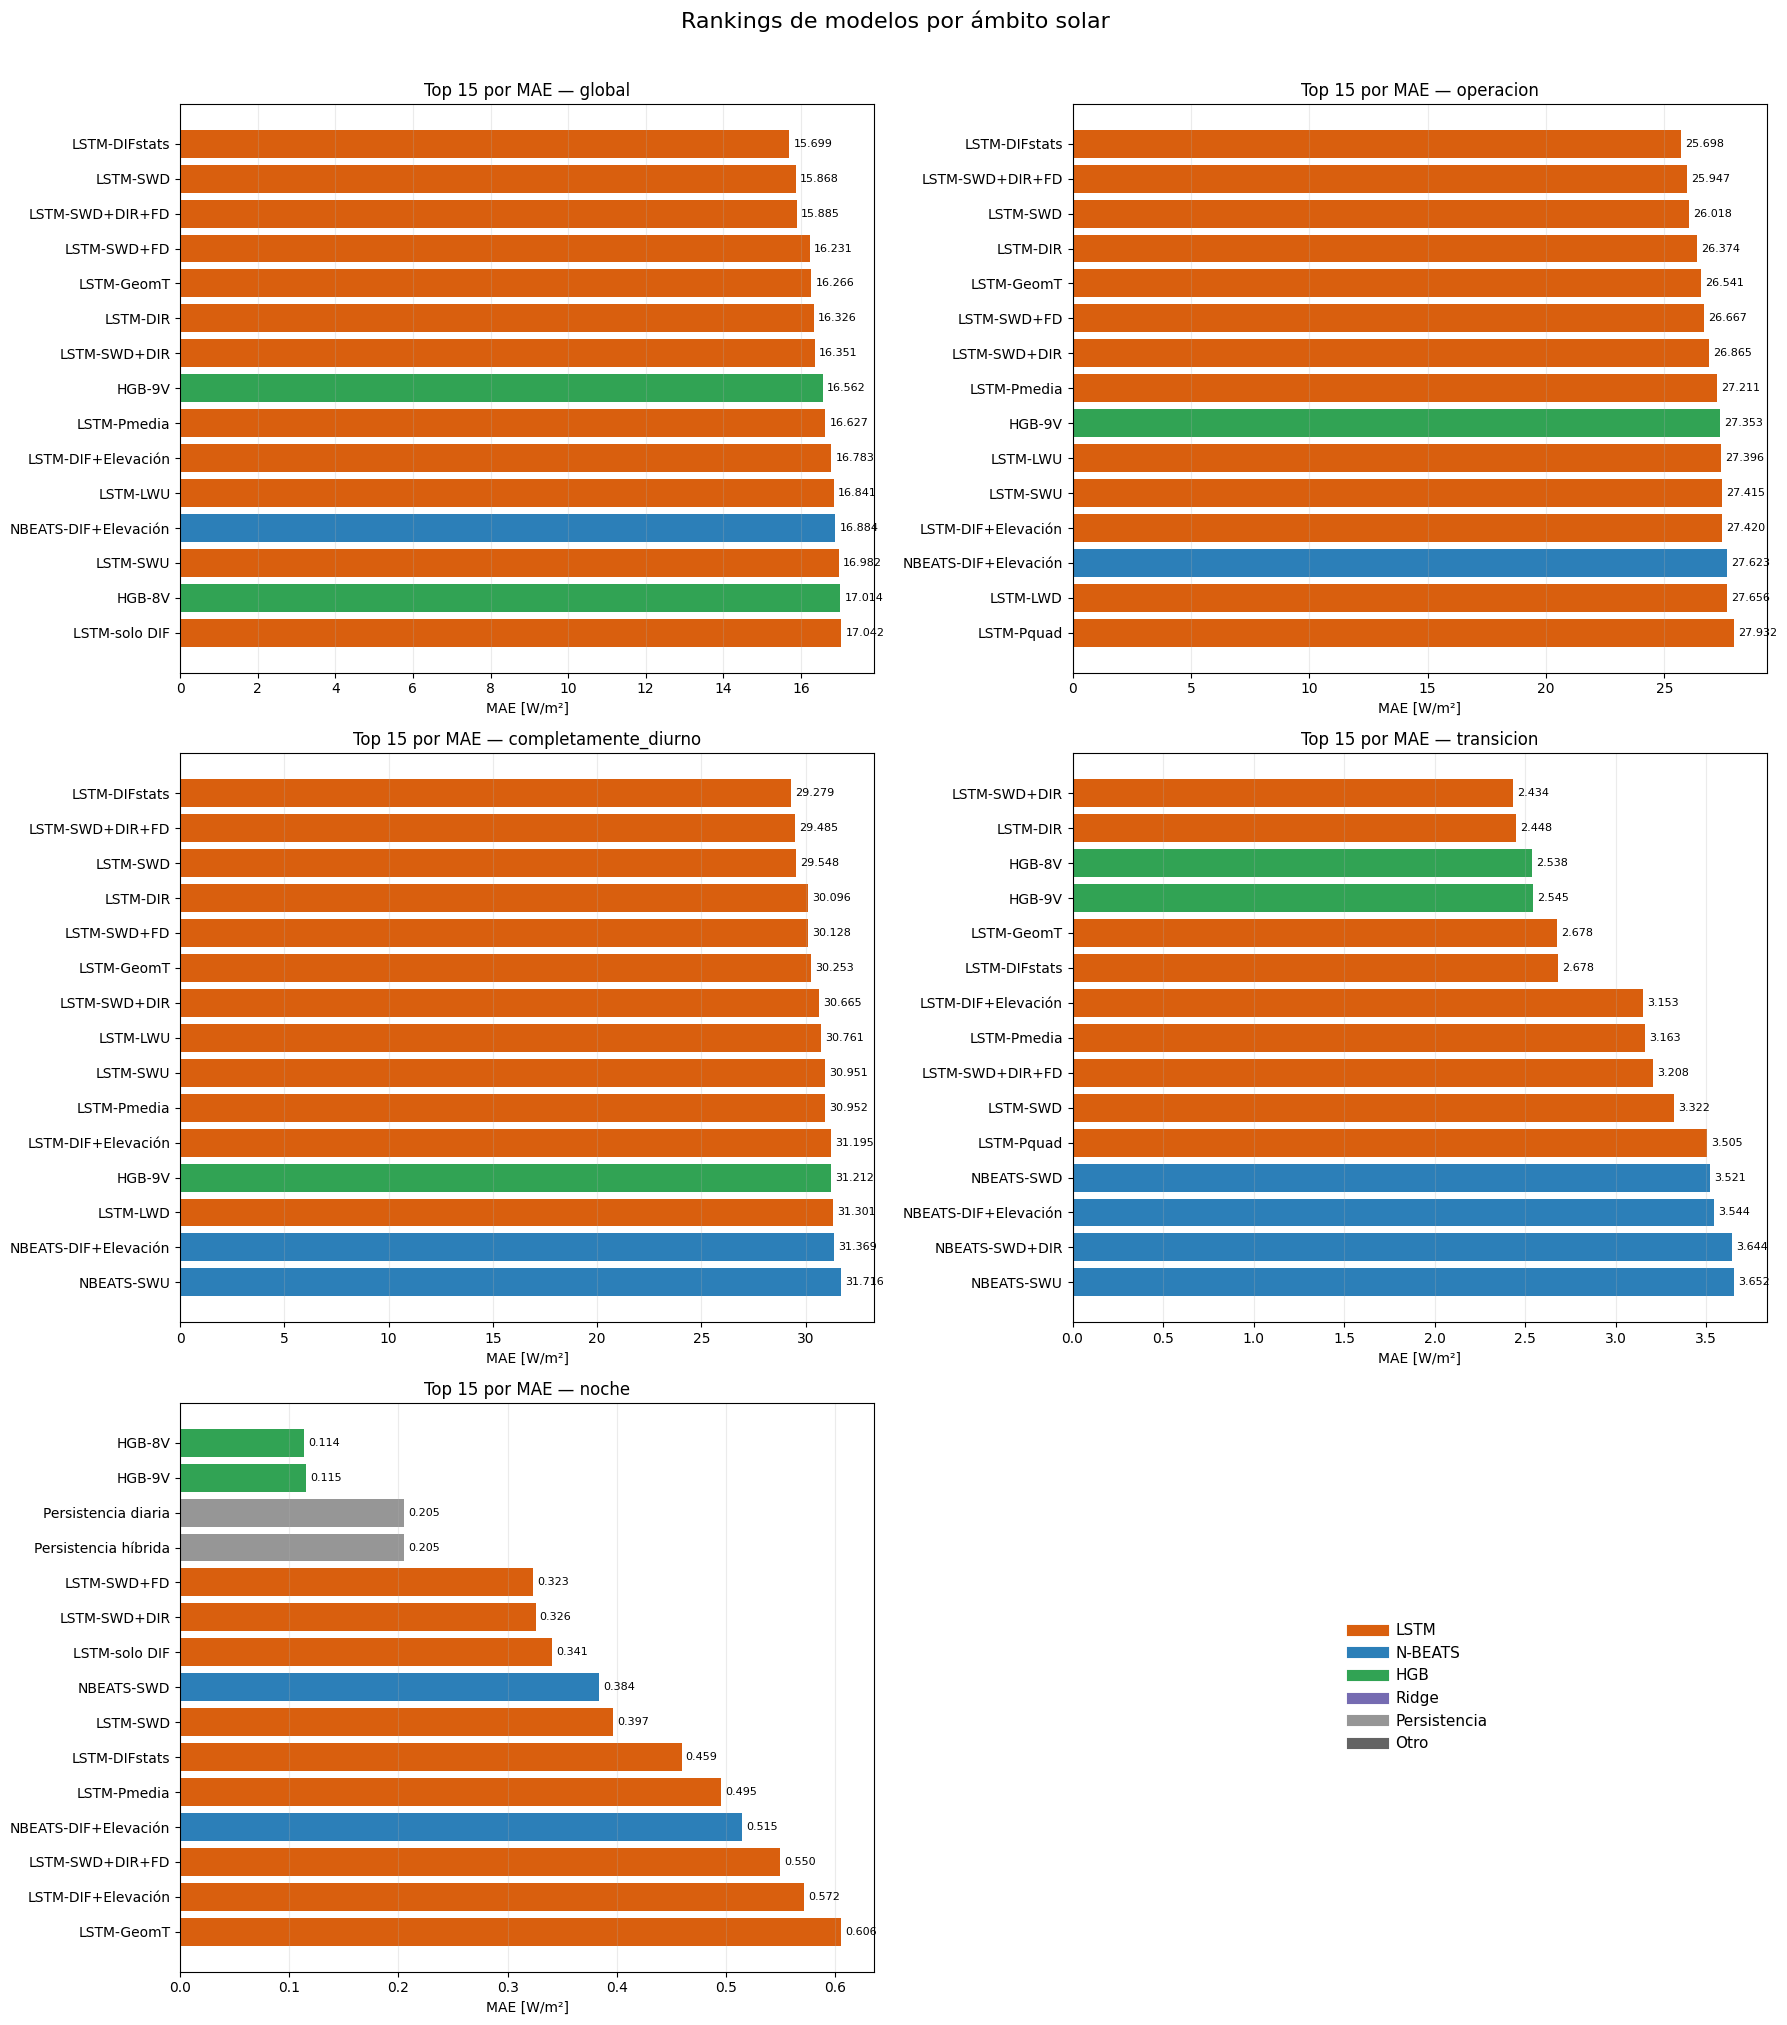

In [ ]:
from pathlib import Path
from datetime import datetime, timezone
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# 1. Localizar la última consolidación corregida
BASE_DIR = Path("/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado")
DIR_COMPARATIVAS = BASE_DIR / "resultados" / "comparativas"
carpetas_benchmarks = sorted(
    DIR_COMPARATIVAS.glob("reconstruccion_benchmarks_clasicos_*"),
    key=lambda ruta: ruta.stat().st_mtime,
)
if not carpetas_benchmarks:
    raise FileNotFoundError("No se encuentra la consolidación corregida de benchmarks.")

DIR_CONSOLIDACION = carpetas_benchmarks[-1]
RUTA_METRICAS = DIR_CONSOLIDACION / "metricas_consolidadas_completas.csv"
if not RUTA_METRICAS.is_file():
    raise FileNotFoundError(f"No se encuentra:\n{RUTA_METRICAS}")

metricas = pd.read_csv(RUTA_METRICAS)
print("Consolidación cargada:")
print(DIR_CONSOLIDACION)


# 2. Auditoría previa
ORDEN_AMBITOS = ["global", "operacion", "completamente_diurno", "transicion", "noche"]
COLUMNAS_REQUERIDAS = {"modelo", "ambito", "MAE", "nMAE_pct", "RMSE", "R2", "bias", "arquitectura"}
faltantes = COLUMNAS_REQUERIDAS - set(metricas.columns)
if faltantes:
    raise KeyError(f"Faltan columnas:\n{sorted(faltantes)}")

columnas_numericas = ["MAE", "nMAE_pct", "RMSE", "R2", "bias"]
for columna in columnas_numericas:
    metricas[columna] = pd.to_numeric(metricas[columna], errors="coerce")

if metricas.duplicated(subset=["modelo", "ambito"]).any():
    duplicados = metricas.loc[metricas.duplicated(subset=["modelo", "ambito"], keep=False)]
    display(duplicados)
    raise ValueError("Existen duplicados modelo-ámbito.")

modelos = sorted(metricas["modelo"].unique())
n_modelos = len(modelos)
cobertura = metricas.groupby("modelo")["ambito"].nunique()
if not cobertura.eq(5).all():
    raise ValueError("No todos los modelos tienen los cinco ámbitos.")

if n_modelos != 39:
    print(f"AVISO: se esperaban 39 modelos y " f"se han encontrado {n_modelos}.")

print("\nAUDITORÍA")
print("Modelos:", n_modelos)
print("Filas:", len(metricas))
print("Ámbitos:", sorted(metricas["ambito"].unique()))
print("Perfiles completos:", cobertura.eq(5).sum())
assert len(metricas) == n_modelos * 5


# 3. Homogeneizar la familia de modelo
def obtener_familia(fila):
    modelo = str(fila["modelo"]).upper()
    arquitectura = str(fila["arquitectura"]).upper()
    if modelo.startswith("LSTM"):
        return "LSTM"

    if modelo.startswith("NBEATS"):
        return "N-BEATS"

    if modelo.startswith("HGB"):
        return "HGB"

    if modelo.startswith("RIDGE"):
        return "Ridge"

    if "PERSISTENCIA" in modelo:
        return "Persistencia"

    if arquitectura not in {"", "NAN", "OTRA"}:
        return arquitectura

    return "Otro"

metricas["familia"] = metricas.apply(obtener_familia, axis=1)


# 4. Construir rankings independientes
rankings = []
for ambito in ORDEN_AMBITOS:
    tabla = metricas.loc[metricas["ambito"].eq(ambito)].copy()
    tabla["ranking_MAE"] = tabla["MAE"].rank(method="min", ascending=True).astype("Int64")
    tabla["ranking_RMSE"] = tabla["RMSE"].rank(method="min", ascending=True).astype("Int64")
    tabla["ranking_R2"] = tabla["R2"].rank(method="min", ascending=False).astype("Int64")
    mejor_mae = tabla["MAE"].min()
    tabla["diferencia_MAE_mejor"] = tabla["MAE"] - mejor_mae
    tabla["diferencia_pct_mejor"] = 100.0 * (tabla["MAE"] - mejor_mae) / mejor_mae
    tabla["grupo_ranking_MAE"] = pd.cut(
        tabla["ranking_MAE"].astype(float),
        bins=[0, 3, 5, 10, np.inf],
        labels=["Top 3", "Top 5", "Top 10", "Resto"],
        include_lowest=True,
    )
    tabla = tabla.sort_values(["ranking_MAE", "RMSE", "modelo"]).reset_index(drop=True)
    rankings.append(tabla)

ranking_completo = pd.concat(rankings, ignore_index=True)


# 5. Mostrar los rankings completos
COLUMNAS_MOSTRAR = [
    "ranking_MAE",
    "modelo",
    "familia",
    "MAE",
    "nMAE_pct",
    "RMSE",
    "R2",
    "bias",
    "ranking_RMSE",
    "ranking_R2",
    "diferencia_MAE_mejor",
    "diferencia_pct_mejor",
]
for ambito in ORDEN_AMBITOS:
    tabla = ranking_completo.loc[ranking_completo["ambito"].eq(ambito), COLUMNAS_MOSTRAR]
    print("\n" + "=" * 100)
    print(f"RANKING COMPLETO — " f"{ambito.upper()}")
    print("=" * 100)
    with pd.option_context(
        "display.max_rows", None, "display.max_columns", None, "display.width", 200
    ):
        display(
            tabla.style.format(
                {
                    "MAE": "{:.6f}",
                    "nMAE_pct": "{:.4f}",
                    "RMSE": "{:.6f}",
                    "R2": "{:.6f}",
                    "bias": "{:.6f}",
                    "diferencia_MAE_mejor": "{:.6f}",
                    "diferencia_pct_mejor": "{:.3f}%",
                }
            )
        )


# 6. Tablas anchas: MAE y posiciones
tabla_MAE_ancha = (
    ranking_completo.pivot(index="modelo", columns="ambito", values="MAE")
    .reindex(columns=ORDEN_AMBITOS)
    .sort_values("global")
)
tabla_ranking_ancha = ranking_completo.pivot(
    index="modelo", columns="ambito", values="ranking_MAE"
).reindex(columns=ORDEN_AMBITOS)
tabla_ranking_ancha = tabla_ranking_ancha.loc[tabla_MAE_ancha.index]
print("\n" + "=" * 100)
print("MAE DE TODOS LOS MODELOS POR ÁMBITO")
print("=" * 100)
with pd.option_context("display.max_rows", None):
    display(tabla_MAE_ancha.style.format("{:.6f}"))

print("\n" + "=" * 100)
print("POSICIÓN DE CADA MODELO POR ÁMBITO")
print("=" * 100)
with pd.option_context("display.max_rows", None):
    display(tabla_ranking_ancha)


# 7. Resumen Top 10 por ámbito
top10 = ranking_completo.loc[ranking_completo["ranking_MAE"].le(10)].sort_values(
    ["ambito", "ranking_MAE"]
)
resumen_top10 = top10[["ambito", "ranking_MAE", "modelo", "familia", "MAE", "RMSE", "R2"]].copy()
print("\n" + "=" * 100)
print("TOP 10 POR ÁMBITO")
print("=" * 100)
display(resumen_top10.style.format({"MAE": "{:.6f}", "RMSE": "{:.6f}", "R2": "{:.6f}"}))


# 8. Gráficas Top 15 de MAE
COLORES = {
    "LSTM": "#D95F0E",
    "N-BEATS": "#2C7FB8",
    "HGB": "#31A354",
    "Ridge": "#756BB1",
    "Persistencia": "#969696",
    "Otro": "#636363",
}
fig, axes = plt.subplots(3, 2, figsize=(18, 20))
for ax, ambito in zip(axes.ravel(), ORDEN_AMBITOS):
    tabla = (
        ranking_completo.loc[ranking_completo["ambito"].eq(ambito)]
        .nsmallest(15, "MAE")
        .sort_values("MAE", ascending=False)
    )
    colores = tabla["familia"].map(COLORES).fillna("#636363")
    barras = ax.barh(tabla["modelo"], tabla["MAE"], color=colores)
    ax.bar_label(barras, fmt="%.3f", padding=3, fontsize=8)
    ax.set_title(f"Top 15 por MAE — {ambito}")
    ax.set_xlabel("MAE [W/m²]")
    ax.grid(axis="x", alpha=0.25)

# El sexto panel se usa como leyenda
axes.ravel()[-1].axis("off")
leyenda = [
    plt.Line2D([0], [0], color=color, lw=8, label=familia) for familia, color in COLORES.items()
]
axes.ravel()[-1].legend(handles=leyenda, loc="center", frameon=False, fontsize=11)
fig.suptitle("Rankings de modelos por ámbito solar", fontsize=16, y=1.01)
plt.tight_layout()


# 9. Guardar resultados
marca = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
DIR_RANKINGS = DIR_COMPARATIVAS / f"rankings_completos_modelos_{marca}"
DIR_RANKINGS.mkdir(parents=True, exist_ok=False)
ranking_completo.to_csv(DIR_RANKINGS / "ranking_completo_formato_largo.csv", index=False)
tabla_MAE_ancha.to_csv(DIR_RANKINGS / "tabla_MAE_todos_ambitos.csv")
tabla_ranking_ancha.to_csv(DIR_RANKINGS / "tabla_posiciones_MAE_todos_ambitos.csv")
resumen_top10.to_csv(DIR_RANKINGS / "top10_por_ambito.csv", index=False)
for ambito in ORDEN_AMBITOS:
    (
        ranking_completo.loc[ranking_completo["ambito"].eq(ambito)]
        .sort_values("ranking_MAE")
        .to_csv(DIR_RANKINGS / f"ranking_{ambito}.csv", index=False)
    )

fig.savefig(DIR_RANKINGS / "top15_MAE_por_ambito.png", dpi=180, bbox_inches="tight")
configuracion = {
    "fecha_creacion_utc": marca,
    "directorio_fuente": str(DIR_CONSOLIDACION),
    "n_modelos": int(n_modelos),
    "ambitos": ORDEN_AMBITOS,
    "criterio_principal": ("MAE ascendente"),
    "criterios_diagnosticos": ["nMAE_pct", "RMSE", "R2", "bias"],
    "nota_noche": ("El ranking nocturno es descriptivo y no determina la selección operativa."),
    "test_utilizado": False,
}
with open(DIR_RANKINGS / "configuracion_rankings.json", "w", encoding="utf-8") as archivo:
    json.dump(configuracion, archivo, ensure_ascii=False, indent=2)

print("\n" + "=" * 100)
print("RANKINGS COMPLETADOS")
print("=" * 100)
print("Modelos:", n_modelos)
print("Ámbitos:", len(ORDEN_AMBITOS))
print("Test utilizado: no")
print("Directorio:", DIR_RANKINGS)

**Resultados.** Las primeras posiciones en los ámbitos global, operación y completamente diurno corresponden a variantes LSTM.

- La LSTM-DIFstats ocupa el primer puesto en MAE global (15,70 W/m²), en operación (25,70 W/m²) y en horas completamente diurnas (29,28 W/m²).
- En transición destacan `LSTM-SWD+DIR` (2,43 W/m²) y `LSTM-DIR` (2,45 W/m²); la LSTM-DIFstats queda sexta (2,68 W/m²).
- En noche, el menor MAE corresponde a las dos HGB (0,11 y 0,12 W/m²) y el mayor, a `Ridge G0` (5,11 W/m²).
- La primera N-BEATS de la clasificación global es `NBEATS-DIF+Elevación` (puesto 12; 16,88 W/m²); las persistencias ocupan los tres últimos puestos.

## 2. Protocolo experimental y máscara nocturna

> *Fija el protocolo y construye la máscara nocturna y los denominadores del nMAE que usan las partes siguientes.*

### 2.1 Congelación del protocolo experimental

Antes de entrenar nuevos modelos se fijan las particiones temporales (entrenamiento del 30 de diciembre de 2023 al 31 de julio de 2024, validación en agosto y septiembre de 2024 y test cerrado hasta la selección definitiva) y el procedimiento de entrenamiento: selección de épocas en una partición cronológica interna del conjunto de entrenamiento con parada temprana (paciencia de 25 épocas), reentrenamiento con todo el conjunto de entrenamiento y semilla 42 para el cribado. Se mantienen las arquitecturas e hiperparámetros anteriores de LSTM y N-BEATS, y las clasificaciones por ámbito de la sección anterior se registran como punto de partida.

In [ ]:
from google.colab import drive

drive.mount("/content/drive", force_remount=False)
from pathlib import Path
from datetime import datetime, timezone
from importlib.metadata import version, PackageNotFoundError
import pandas as pd
import numpy as np
import hashlib
import platform
import random
import json
import sys
import os

# 1. Rutas principales
BASE_DIR = Path("/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado")
RESULTADOS_DIR = BASE_DIR / "resultados"
EJECUCIONES_DIR = RESULTADOS_DIR / "ejecuciones"
COMPARATIVAS_DIR = RESULTADOS_DIR / "comparativas"
RANKINGS_ORIGEN_DIR = COMPARATIVAS_DIR / "rankings_completos_modelos_20261007T082325Z"
rutas_obligatorias = {
    "BASE_DIR": BASE_DIR,
    "RESULTADOS_DIR": RESULTADOS_DIR,
    "EJECUCIONES_DIR": EJECUCIONES_DIR,
    "COMPARATIVAS_DIR": COMPARATIVAS_DIR,
    "RANKINGS_ORIGEN_DIR": RANKINGS_ORIGEN_DIR,
}
print("=== COMPROBACIÓN DE RUTAS ===")
for nombre, ruta in rutas_obligatorias.items():
    existe = ruta.exists()
    print(f"{nombre}: {ruta}")
    print(f"  Existe: {existe}")
    if not existe:
        raise FileNotFoundError(f"No se encuentra la ruta obligatoria: {ruta}")

# 2. Crear ejecución persistente
TIMESTAMP_UTC = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
RUN_DIR = EJECUCIONES_DIR / f"ingenieria_caracteristicas_operacional_{TIMESTAMP_UTC}"
PROTOCOLO_DIR = RUN_DIR / "00_protocolo"
DATOS_DIR = RUN_DIR / "01_datos"
SUBTRAIN_DIR = RUN_DIR / "02_seleccion_epocas"
MODELOS_DIR = RUN_DIR / "03_modelos"
PREDICCIONES_DIR = RUN_DIR / "04_predicciones"
METRICAS_DIR = RUN_DIR / "05_metricas"
FIGURAS_DIR = RUN_DIR / "06_figuras"
COMPARACIONES_DIR = RUN_DIR / "07_comparaciones"
LOGS_DIR = RUN_DIR / "08_logs"
for ruta in [
    PROTOCOLO_DIR,
    DATOS_DIR,
    SUBTRAIN_DIR,
    MODELOS_DIR,
    PREDICCIONES_DIR,
    METRICAS_DIR,
    FIGURAS_DIR,
    COMPARACIONES_DIR,
    LOGS_DIR,
]:
    ruta.mkdir(parents=True, exist_ok=False)

# Puntero para recuperar fácilmente esta ejecución en futuras sesiones
PUNTERO_EJECUCION = EJECUCIONES_DIR / "ULTIMA_INGENIERIA_OPERACIONAL.json"

# 3. Particiones temporales congeladas
SPLITS = {
    "train": {
        "inicio": "2023-12-30 00:00:00",
        "fin": "2024-07-31 23:00:00",
        "filas_historicas": 5149,
        "uso": "ajuste y selección interna cronológica",
    },
    "validation": {
        "inicio": "2024-08-01 00:00:00",
        "fin": "2024-09-30 23:00:00",
        "filas_historicas": 1464,
        "uso": "evaluación externa y comparación de modelos",
    },
    "test": {
        "inicio": "2024-10-01 00:00:00",
        "fin": "2024-11-30 23:00:00",
        "filas_historicas": None,
        "uso": "CERRADO hasta la selección definitiva",
    },
}
tabla_splits = pd.DataFrame([{"particion": nombre, **datos} for nombre, datos in SPLITS.items()])
tabla_splits.to_csv(PROTOCOLO_DIR / "particiones_temporales.csv", index=False)
print("\n=== PARTICIONES TEMPORALES CONGELADAS ===")
display(tabla_splits)

# 4. Semillas y reproducibilidad
SEMILLA_CRIBADO = 42
SEMILLAS_FINALISTAS = [42, 123, 456, 789, 2026]

def fijar_semilla(semilla=42):
    """
    Fija las fuentes de aleatoriedad disponibles.
    Debe llamarse antes de construir cada modelo.
    """
    os.environ["PYTHONHASHSEED"] = str(semilla)
    random.seed(semilla)
    np.random.seed(semilla)
    try:
        import tensorflow as tf
        tf.keras.utils.set_random_seed(semilla)
        try:
            tf.config.experimental.enable_op_determinism()
        except Exception as exc:
            print("Aviso: no se pudo activar determinismo completo " f"en TensorFlow: {exc}")

    except ImportError:
        pass

    try:
        import torch
        torch.manual_seed(semilla)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(semilla)

        try:
            torch.use_deterministic_algorithms(True, warn_only=True)
        except Exception:
            pass

    except ImportError:
        pass

fijar_semilla(SEMILLA_CRIBADO)

# 5. Protocolo experimental
PROTOCOLO = {
    "nombre": "ingenieria_caracteristicas_operacional",
    "timestamp_creacion_utc": TIMESTAMP_UTC,
    "directorio_ejecucion": str(RUN_DIR),
    "objetivo": (
        "Mejorar la predicción durante operación, especialmente "
        "en transiciones solares y rampas diurnas."
    ),
    "variable_objetivo": "DIF_objetivo_t1",
    "horizonte_prediccion_horas": 1,
    "particiones": SPLITS,
    "seleccion_epocas": {
        "procedimiento": "subtrain cronológico + validación interna",
        "early_stopping": True,
        "patience": 25,
        "monitor": "val_loss",
        "mode": "min",
        "restore_best_weights": True,
        "reentrenamiento_final": ("desde cero con todo train durante la época seleccionada"),
        "validation_externa_para_epocas": False,
    },
    "semillas": {"cribado_inicial": SEMILLA_CRIBADO, "finalistas": SEMILLAS_FINALISTAS},
    "arquitecturas": ["LSTM", "NBEATS"],
    "restriccion_arquitecturas": (
        "Reutilizar exactamente las arquitecturas, optimizadores, "
        "escalado y configuración histórica. No modificar arquitectura "
        "y variables simultáneamente."
    ),
    "metricas_principales": ["MAE", "nMAE_historico", "RMSE", "R2", "sesgo"],
    "ambitos_evaluacion": [
        "total_con_mascara_nocturna",
        "operacion",
        "completamente_diurno",
        "transicion",
        "amanecer",
        "atardecer",
        "noche_control",
        "rampas_diurnas",
    ],
    "criterio_principal_seleccion": "MAE_operacion",
    "criterios_secundarios": [
        "MAE_transicion",
        "MAE_completamente_diurno",
        "MAE_rampas",
        "RMSE_operacion",
        "sesgo",
        "estabilidad_entre_semillas",
        "coste_computacional",
    ],
    "test_cerrado": True,
    "regla_test": (
        "No cargar, consultar, transformar ni evaluar test hasta "
        "haber seleccionado definitivamente modelos y variables."
    ),
    "ranking_origen": str(RANKINGS_ORIGEN_DIR),
    "modelos_planificados": {
        "M0": "DIF + Elevacion",
        "M1": "DIFstats",
        "M2": "DIFstats + SWD",
        "M3": "DIFstats + SWD + DIR",
        "M4": "DIFstats + SWD + DIR + FD",
        "M5": "Mejor de M2-M4 + kt",
        "M6": "Mejor de M2-M4 + Pmedia",
        "M7": "Mejor de M2-M4 + kt + Pmedia, solo si procede",
    },
    "variables_aparcadas": ["LWD", "LWU", "SWU", "T2quad", "RHquad", "Pquad"],
}
with open(PROTOCOLO_DIR / "protocolo_experimental.json", "w", encoding="utf-8") as archivo:
    json.dump(PROTOCOLO, archivo, ensure_ascii=False, indent=2)

# 6. Inventario y huellas de los rankings de partida
def sha256_archivo(ruta, bloque=1024 * 1024):
    hash_obj = hashlib.sha256()
    with open(ruta, "rb") as archivo:
        while True:
            fragmento = archivo.read(bloque)
            if not fragmento:
                break

            hash_obj.update(fragmento)

    return hash_obj.hexdigest()

archivos_ranking = sorted(ruta for ruta in RANKINGS_ORIGEN_DIR.rglob("*") if ruta.is_file())
inventario_rankings = []
for ruta in archivos_ranking:
    inventario_rankings.append(
        {
            "archivo": ruta.name,
            "ruta": str(ruta),
            "extension": ruta.suffix.lower(),
            "bytes": ruta.stat().st_size,
            "sha256": sha256_archivo(ruta),
        }
    )

df_inventario_rankings = pd.DataFrame(inventario_rankings)
df_inventario_rankings.to_csv(PROTOCOLO_DIR / "inventario_rankings_origen.csv", index=False)
print("\n=== ARCHIVOS DE LOS RANKINGS DE PARTIDA ===")
display(df_inventario_rankings)

# 7. Localizar configuraciones históricas existentes
patrones_configuracion = [
    "*config*.json",
    "*config*.csv",
    "*config*.yaml",
    "*config*.yml",
    "*protocolo*.json",
    "*arquitectura*.json",
]
configuraciones_encontradas = set()
for patron in patrones_configuracion:
    configuraciones_encontradas.update(
        ruta
        for ruta in RESULTADOS_DIR.rglob(patron)
        if ruta.is_file() and RUN_DIR not in ruta.parents
    )

inventario_configuraciones = []
for ruta in sorted(configuraciones_encontradas):
    inventario_configuraciones.append(
        {
            "archivo": ruta.name,
            "ruta": str(ruta),
            "extension": ruta.suffix.lower(),
            "bytes": ruta.stat().st_size,
            "modificacion_utc": datetime.fromtimestamp(
                ruta.stat().st_mtime, tz=timezone.utc
            ).isoformat(),
        }
    )

df_configuraciones = pd.DataFrame(inventario_configuraciones)
df_configuraciones.to_csv(PROTOCOLO_DIR / "inventario_configuraciones_historicas.csv", index=False)
print("\n=== CONFIGURACIONES HISTÓRICAS LOCALIZADAS ===")
if len(df_configuraciones):
    display(df_configuraciones.sort_values("modificacion_utc", ascending=False).head(50))
else:
    print(
        "No se localizaron archivos de configuración con los "
        "patrones buscados. Las arquitecturas deberán recuperarse "
        "de las funciones ya definidas en el notebook."
    )

# 8. Registrar entorno computacional
def version_paquete(nombre):
    try:
        return version(nombre)
    except PackageNotFoundError:
        return None

ENTORNO = {
    "timestamp_utc": TIMESTAMP_UTC,
    "python": sys.version,
    "sistema": platform.platform(),
    "procesador": platform.processor(),
    "numpy": version_paquete("numpy"),
    "pandas": version_paquete("pandas"),
    "scikit_learn": version_paquete("scikit-learn"),
    "tensorflow": version_paquete("tensorflow"),
    "keras": version_paquete("keras"),
    "torch": version_paquete("torch"),
}
try:
    import tensorflow as tf
    ENTORNO["tensorflow_dispositivos"] = [
        dispositivo.name for dispositivo in tf.config.list_physical_devices()
    ]
except Exception as exc:
    ENTORNO["tensorflow_dispositivos"] = []
    ENTORNO["tensorflow_error"] = str(exc)

try:
    import torch
    ENTORNO["torch_cuda_disponible"] = torch.cuda.is_available()
    ENTORNO["torch_gpu"] = torch.cuda.get_device_name(0) if torch.cuda.is_available() else None
except Exception as exc:
    ENTORNO["torch_cuda_disponible"] = False
    ENTORNO["torch_error"] = str(exc)

with open(PROTOCOLO_DIR / "entorno_computacional.json", "w", encoding="utf-8") as archivo:
    json.dump(ENTORNO, archivo, ensure_ascii=False, indent=2)

# 9. Guardar puntero de recuperación
PUNTERO = {
    "timestamp_utc": TIMESTAMP_UTC,
    "run_dir": str(RUN_DIR),
    "protocolo_dir": str(PROTOCOLO_DIR),
    "estado": "fase_0_completada",
    "siguiente_fase": ("fase_1_definicion_y_validacion_mascara_nocturna"),
}
with open(PUNTERO_EJECUCION, "w", encoding="utf-8") as archivo:
    json.dump(PUNTERO, archivo, ensure_ascii=False, indent=2)

# 10. Resumen final
print("\n" + "=" * 70)
print("FASE 0 COMPLETADA")
print("=" * 70)
print(f"\nDirectorio de ejecución:\n{RUN_DIR}")
print(f"\nProtocolo:\n{PROTOCOLO_DIR / 'protocolo_experimental.json'}")
print(f"\nPuntero de recuperación:\n{PUNTERO_EJECUCION}")
print("\nSemilla de cribado:", SEMILLA_CRIBADO)
print("Semillas finalistas:", SEMILLAS_FINALISTAS)
print("Patience:", PROTOCOLO["seleccion_epocas"]["patience"])
print("Test cerrado:", PROTOCOLO["test_cerrado"])
print("\nSiguiente paso:")
print("Fase 1 — construir y validar la máscara nocturna sin pisar transiciones.")

=== COMPROBACIÓN DE RUTAS ===
BASE_DIR: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado
  Existe: True
RESULTADOS_DIR: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados
  Existe: True
EJECUCIONES_DIR: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones
  Existe: True
COMPARATIVAS_DIR: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/comparativas
  Existe: True
RANKINGS_ORIGEN_DIR: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/comparativas/rankings_completos_modelos_20261007T082325Z
  Existe: True

=== PARTICIONES TEMPORALES CONGELADAS ===


,particion,inicio,fin,filas_historicas,uso
0,train,2023-12-30 00:00:00,2024-07-31 23:00:00,5149.0,ajuste y selección interna cronológica
1,validation,2024-08-01 00:00:00,2024-09-30 23:00:00,1464.0,evaluación externa y comparación de modelos
2,test,2024-10-01 00:00:00,2024-11-30 23:00:00,NaN,CERRADO hasta la selección definitiva



=== ARCHIVOS DE LOS RANKINGS DE PARTIDA ===


,archivo,ruta,extension,bytes,sha256
0,configuracion_rankings.json,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...,.json,601,1920debaca54c5147ab8aeab0820a6a3ccea0fd45032e1...
1,ranking_completamente_diurno.csv,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...,.csv,8756,5aa1fee95bcb516a2dea96435c4b1d9d34cb495907daf3...
2,ranking_completo_formato_largo.csv,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...,.csv,39868,3bcdbe14461c70aaf839cdbcf050d32e78321fa8f0dad2...
3,ranking_global.csv,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...,.csv,7779,e553ea512717b266b3e64b325280d31daf5b21b10f352b...
4,ranking_noche.csv,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...,.csv,7357,b7151fdc8e31964a0bdc663e3532ca7834cf9fccc3760f...
5,ranking_operacion.csv,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...,.csv,8329,4ee0615ad07fa8ca5e5de7e66cead9d21acb4b27e893ee...
6,ranking_transicion.csv,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...,.csv,8351,73425146089c74acff2032bd9ebb2816bfad320dd49c9d...
7,tabla_MAE_todos_ambitos.csv,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...,.csv,4092,73c278c2026fe42f5bd35ad443e60ea1f4e68da56a8ddd...
8,tabla_posiciones_MAE_todos_ambitos.csv,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...,.csv,1119,873740464226abf5859a9cf961916c7307b47a56d9f25f...
9,top10_por_ambito.csv,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...,.csv,4085,c2430c7a9af32648e8f059b436555dc9154b22bf25fa1a...



=== CONFIGURACIONES HISTÓRICAS LOCALIZADAS ===


,archivo,ruta,extension,bytes,modificacion_utc
1,configuracion_rankings.json,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...,.json,601,2026-10-07T08:23:29+00:00
2,configuracion_recuperacion.json,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...,.json,1209,2026-10-07T07:56:06+00:00
0,configuracion_comparacion.json,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...,.json,790,2026-10-06T22:31:03+00:00
21,configuracion_analisis_regimenes.json,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...,.json,669,2026-10-06T22:16:14+00:00
22,configuracion_reentrenamiento.json,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...,.json,717,2026-10-06T22:08:56+00:00
37,configuracion_global.json,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...,.json,770,2026-10-06T21:59:44+00:00
30,configuracion.json,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...,.json,624,2026-10-06T21:59:43+00:00
34,configuracion.json,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...,.json,632,2026-10-06T21:58:31+00:00
29,configuracion.json,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...,.json,592,2026-10-06T21:58:05+00:00
33,configuracion.json,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...,.json,594,2026-10-06T21:56:30+00:00



FASE 0 COMPLETADA

Directorio de ejecución:
/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/ingenieria_caracteristicas_operacional_20261007T091724Z

Protocolo:
/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/ingenieria_caracteristicas_operacional_20261007T091724Z/00_protocolo/protocolo_experimental.json

Puntero de recuperación:
/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/ULTIMA_INGENIERIA_OPERACIONAL.json

Semilla de cribado: 42
Semillas finalistas: [42, 123, 456, 789, 2026]
Patience: 25
Test cerrado: True

Siguiente paso:
Fase 1 — construir y validar la máscara nocturna sin pisar transiciones.


### 2.2 Máscara nocturna y denominadores del nMAE

Cada hora objetivo se clasifica en noche, transición o completamente diurna a partir de la elevación solar aparente calculada minuto a minuto con pvlib; la máscara asigna peso nulo a las horas nocturnas durante el entrenamiento y fija a cero su predicción, sin alterar las horas de transición. Además, se toma como denominador del nMAE de cada ámbito la DIF media observada en validación.

> *Los denominadores del nMAE en validación (141,80, 162,72 y 7,28 W/m² en horas con sol, completamente diurnas y de transición) coinciden con los de la Tabla 11 de la memoria.*

Ejecución operacional:
/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/ingenieria_caracteristicas_operacional_20261007T091724Z

Checkpoint histórico:
/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/documentacion/checkpoint_continuidad_modelado_20261006_125123

Tablas recuperadas:
Train: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/documentacion/checkpoint_continuidad_modelado_20261006_125123/train_hgb.parquet
Validation: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/documentacion/checkpoint_continuidad_modelado_20261006_125123/validation_hgb.parquet

Dimensiones:
train_hgb: (5149, 21)
validation_hgb: (1464, 21)

Intervalo de geometría solar:
Inicio: 2023-12-30 00:00:00+00:00
Final: 2024-09-30 23:59:00+00:00
Minutos: 397440

=== PVLIB FRENTE A CLASIFICACIÓN HISTÓRICA ===


,split,n,coincidencias,discrepancias
0,train,5149,5149,0
1,validation,1464,1464,0



=== REGÍMENES EN VALIDATION ===


,obtenido,esperado
completamente_diurno,765,765
transicion,119,119
noche,580,580



=== RESUMEN POR RÉGIMEN ===


,split,regimen_pvlib,n,DIF_media,DIF_mediana,DIF_std,DIF_max,elevacion_media,fraccion_diurna_media
0,train,completamente_diurno,2603,158.543198,132.300000,111.792382,555.150000,29.292350,1.000000
1,train,noche,2122,-0.842892,-1.000000,0.325431,0.366667,-24.599685,0.000000
2,train,transicion,424,5.990578,3.616667,6.570977,29.750000,-0.380345,0.498192
3,validation,completamente_diurno,765,162.723079,145.683333,98.945723,507.100000,29.685010,1.000000
4,validation,noche,580,-0.978506,-1.000000,0.317505,0.400000,-21.197895,0.000000
5,validation,transicion,119,7.276421,4.850000,7.120201,31.816667,-0.250564,0.513165



=== EFECTO DE FORZAR DIF=0 DE NOCHE ===


,split,n_noche,MAE_si_prediccion_cero,RMSE_si_prediccion_cero,DIF_media_noche,DIF_max_noche
0,train,2122,0.843473,0.903506,-0.842892,0.366667
1,validation,580,0.980747,1.028644,-0.978506,0.400000


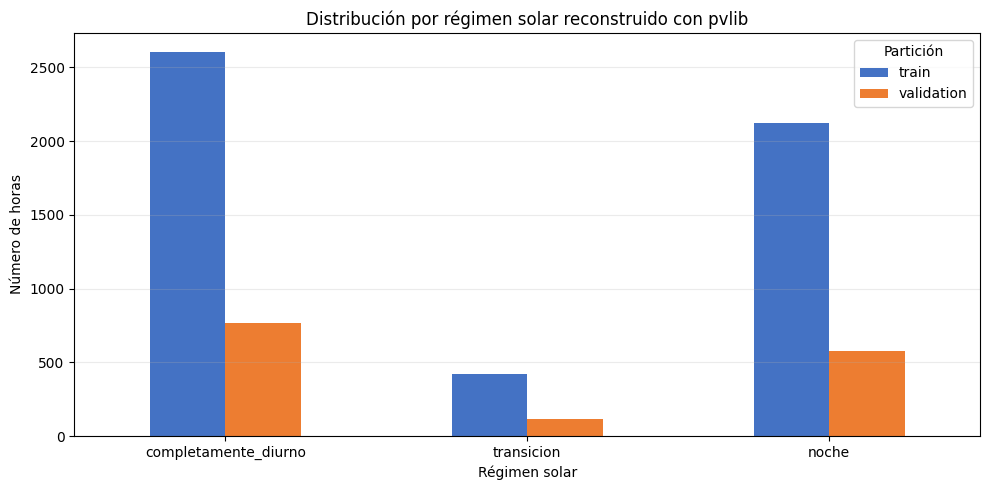


FASE 1 COMPLETADA CORRECTAMENTE
Configuración solar: {'latitud': 51.971, 'longitud': 4.927, 'altitud_m': 0, 'zona_horaria': 'UTC', 'metodo_pvlib': 'nrel_numpy', 'elevacion_utilizada': 'apparent_elevation', 'frecuencia': '1min', 'umbral_diurno': 'apparent_elevation > 0'}
Train: 5149
Validation: 1464
Operación validation: 884
Completamente diurno: 765
Transición: 119
Noche: 580

Máscaras guardadas en:
/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/ingenieria_caracteristicas_operacional_20261007T091724Z/01_datos

Siguiente paso:
Fase 2 — preparación operacional de M0 y M1.


In [ ]:
from google.colab import drive

drive.mount("/content/drive", force_remount=False)
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import unicodedata
import subprocess
import sys
import json
try:
    import pvlib
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "pvlib"])
    import pvlib

# 1. Rutas
BASE_DIR = Path("/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado")
RESULTADOS_DIR = BASE_DIR / "resultados"
EJECUCIONES_DIR = RESULTADOS_DIR / "ejecuciones"
DOCUMENTACION_DIR = BASE_DIR / "documentacion"
PUNTERO_OPERACIONAL = EJECUCIONES_DIR / "ULTIMA_INGENIERIA_OPERACIONAL.json"
PUNTERO_CHECKPOINT = DOCUMENTACION_DIR / "ULTIMO_CHECKPOINT_MODELADO.json"
if not PUNTERO_OPERACIONAL.exists():
    raise FileNotFoundError(f"No existe:\n{PUNTERO_OPERACIONAL}")

if not PUNTERO_CHECKPOINT.exists():
    raise FileNotFoundError(f"No existe:\n{PUNTERO_CHECKPOINT}")

with open(PUNTERO_OPERACIONAL, "r", encoding="utf-8") as archivo:
    puntero_operacional = json.load(archivo)

with open(PUNTERO_CHECKPOINT, "r", encoding="utf-8") as archivo:
    puntero_checkpoint = json.load(archivo)

RUN_DIR = Path(puntero_operacional["run_dir"])
CHECKPOINT_DIR = Path(puntero_checkpoint["checkpoint_dir"])
DATOS_DIR = RUN_DIR / "01_datos"
FIGURAS_DIR = RUN_DIR / "06_figuras"
DATOS_DIR.mkdir(parents=True, exist_ok=True)
FIGURAS_DIR.mkdir(parents=True, exist_ok=True)
if not CHECKPOINT_DIR.exists():
    raise FileNotFoundError(f"No existe el checkpoint:\n{CHECKPOINT_DIR}")

print("Ejecución operacional:")
print(RUN_DIR)
print("\nCheckpoint histórico:")
print(CHECKPOINT_DIR)

# 2. Recuperar train_hgb y validation_hgb
def cargar_tabla_checkpoint(nombre):
    ruta_parquet = CHECKPOINT_DIR / f"{nombre}.parquet"
    ruta_pickle = CHECKPOINT_DIR / f"{nombre}.pkl"
    if ruta_parquet.exists():
        tabla = pd.read_parquet(ruta_parquet)
        ruta_utilizada = ruta_parquet

    elif ruta_pickle.exists():
        tabla = pd.read_pickle(ruta_pickle)
        ruta_utilizada = ruta_pickle

    else:
        raise FileNotFoundError(
            f"No se encontró {nombre}.parquet ni " f"{nombre}.pkl dentro de:\n{CHECKPOINT_DIR}"
        )

    columnas_necesarias = {"instante_objetivo", "DIF_objetivo_t1", "regimen_solar_objetivo"}
    faltantes = columnas_necesarias.difference(tabla.columns)
    if faltantes:
        raise ValueError(f"{nombre} no contiene las columnas: " f"{sorted(faltantes)}")

    tabla = tabla.copy()
    tabla["instante_objetivo"] = pd.to_datetime(tabla["instante_objetivo"], utc=True)
    tabla = tabla.sort_values("instante_objetivo").reset_index(drop=True)
    return tabla, ruta_utilizada

train_hgb, ruta_train_hgb = cargar_tabla_checkpoint("train_hgb")
validation_hgb, ruta_validation_hgb = cargar_tabla_checkpoint("validation_hgb")
print("\nTablas recuperadas:")
print("Train:", ruta_train_hgb)
print("Validation:", ruta_validation_hgb)
print("\nDimensiones:")
print("train_hgb:", train_hgb.shape)
print("validation_hgb:", validation_hgb.shape)
if len(train_hgb) != 5149:
    raise AssertionError(f"Train debería contener 5149 filas y contiene " f"{len(train_hgb)}.")

if len(validation_hgb) != 1464:
    raise AssertionError(
        f"Validation debería contener 1464 filas y contiene " f"{len(validation_hgb)}."
    )

# 3. Configuración solar histórica exacta
LATITUD = 51.971
LONGITUD = 4.927
ALTITUD = 0
ZONA_HORARIA = "UTC"
CONFIGURACION_SOLAR = {
    "latitud": LATITUD,
    "longitud": LONGITUD,
    "altitud_m": ALTITUD,
    "zona_horaria": ZONA_HORARIA,
    "metodo_pvlib": "nrel_numpy",
    "elevacion_utilizada": "apparent_elevation",
    "frecuencia": "1min",
    "umbral_diurno": "apparent_elevation > 0",
}

# 4. Generar geometría minutal necesaria
todos_objetivos = pd.concat(
    [train_hgb["instante_objetivo"], validation_hgb["instante_objetivo"]], ignore_index=True
)
inicio_minutal = todos_objetivos.min().floor("h")
fin_exclusivo = todos_objetivos.max().floor("h") + pd.Timedelta(hours=1)
tiempos_minutales = pd.date_range(
    start=inicio_minutal, end=fin_exclusivo, freq="min", inclusive="left", tz=ZONA_HORARIA
)
print("\nIntervalo de geometría solar:")
print("Inicio:", tiempos_minutales.min())
print("Final:", tiempos_minutales.max())
print("Minutos:", len(tiempos_minutales))
posicion_solar = pvlib.solarposition.get_solarposition(
    time=tiempos_minutales,
    latitude=LATITUD,
    longitude=LONGITUD,
    altitude=ALTITUD,
    method="nrel_numpy",
)
geometria_minutal = pd.DataFrame(
    {"elevacion_solar": (posicion_solar["apparent_elevation"].to_numpy())}, index=tiempos_minutales
)
geometria_minutal["minuto_diurno"] = (geometria_minutal["elevacion_solar"] > 0).astype(float)

# 5. Agregación por hora objetivo
geometria_horaria = geometria_minutal.resample("h", closed="left", label="left").agg(
    elevacion_media_objetivo=("elevacion_solar", "mean"),
    elevacion_minima_objetivo=("elevacion_solar", "min"),
    elevacion_maxima_objetivo=("elevacion_solar", "max"),
    fraccion_diurna_objetivo=("minuto_diurno", "mean"),
    numero_minutos=("elevacion_solar", "size"),
)
if not (geometria_horaria["numero_minutos"] == 60).all():
    raise AssertionError("La geometría contiene horas con un número distinto de 60 minutos.")

geometria_horaria["regimen_pvlib"] = np.select(
    [
        geometria_horaria["fraccion_diurna_objetivo"].eq(0),
        geometria_horaria["fraccion_diurna_objetivo"].eq(1),
    ],
    ["noche", "completamente_diurno"],
    default="transicion",
)
geometria_horaria = geometria_horaria.reset_index().rename(columns={"index": "instante_objetivo"})

# 6. Obtener la máscara en el orden exacto de cada tabla
def normalizar_texto(valor):
    texto = str(valor).strip().lower()
    texto = "".join(
        caracter
        for caracter in unicodedata.normalize("NFD", texto)
        if unicodedata.category(caracter) != "Mn"
    )
    return texto.replace("-", "_").replace(" ", "_")

def normalizar_regimen(valor):
    texto = normalizar_texto(valor)
    if "noche" in texto or "night" in texto:
        return "noche"

    if "trans" in texto:
        return "transicion"

    if "diurn" in texto or "daylight" in texto:
        return "completamente_diurno"

    return "desconocido"

def construir_mascara(tabla, split):
    columnas_geometria = [
        "instante_objetivo",
        "elevacion_media_objetivo",
        "elevacion_minima_objetivo",
        "elevacion_maxima_objetivo",
        "fraccion_diurna_objetivo",
        "numero_minutos",
        "regimen_pvlib",
    ]
    resultado = tabla[["instante_objetivo", "DIF_objetivo_t1", "regimen_solar_objetivo"]].merge(
        geometria_horaria[columnas_geometria],
        on="instante_objetivo",
        how="left",
        validate="one_to_one",
    )
    if resultado["regimen_pvlib"].isna().any():
        faltantes = resultado.loc[resultado["regimen_pvlib"].isna(), "instante_objetivo"]
        raise ValueError(f"No se encontró geometría para {split}:\n" f"{faltantes.tolist()[:20]}")

    resultado["regimen_historico_normalizado"] = resultado["regimen_solar_objetivo"].map(
        normalizar_regimen
    )
    desconocidos = resultado.loc[
        resultado["regimen_historico_normalizado"] == "desconocido", "regimen_solar_objetivo"
    ].unique()
    if len(desconocidos):
        raise ValueError(
            f"Regímenes históricos desconocidos en {split}: " f"{desconocidos.tolist()}"
        )

    resultado["coincide_regimen"] = (
        resultado["regimen_pvlib"] == resultado["regimen_historico_normalizado"]
    )
    resultado["es_noche_completa"] = resultado["regimen_pvlib"] == "noche"
    resultado["es_transicion"] = resultado["regimen_pvlib"] == "transicion"
    resultado["es_completamente_diurno"] = resultado["regimen_pvlib"] == "completamente_diurno"
    resultado["es_operacion"] = ~resultado["es_noche_completa"]
    resultado["peso_entrenamiento"] = resultado["es_operacion"].astype(np.float32)
    resultado["forzar_prediccion_cero"] = resultado["es_noche_completa"]
    resultado["split"] = split
    return resultado

mascara_train = construir_mascara(train_hgb, "train")
mascara_validation = construir_mascara(validation_hgb, "validation")

# 7. Validaciones estrictas
comparacion_regimenes = (
    pd.concat([mascara_train, mascara_validation], ignore_index=True)
    .groupby("split")
    .agg(
        n=("instante_objetivo", "size"),
        coincidencias=("coincide_regimen", "sum"),
        discrepancias=("coincide_regimen", lambda x: (~x).sum()),
    )
    .reset_index()
)
print("\n=== PVLIB FRENTE A CLASIFICACIÓN HISTÓRICA ===")
display(comparacion_regimenes)
if not mascara_train["coincide_regimen"].all():
    discrepancias = mascara_train.loc[~mascara_train["coincide_regimen"]]
    display(discrepancias.head(20))
    raise AssertionError("La reconstrucción pvlib no coincide con train.")

if not mascara_validation["coincide_regimen"].all():
    discrepancias = mascara_validation.loc[~mascara_validation["coincide_regimen"]]
    display(discrepancias.head(20))
    raise AssertionError("La reconstrucción pvlib no coincide con validation.")

conteos_validation = (
    mascara_validation["regimen_pvlib"]
    .value_counts()
    .reindex(["completamente_diurno", "transicion", "noche"], fill_value=0)
)
conteos_esperados = pd.Series({"completamente_diurno": 765, "transicion": 119, "noche": 580})
print("\n=== REGÍMENES EN VALIDATION ===")
display(
    pd.concat([conteos_validation.rename("obtenido"), conteos_esperados.rename("esperado")], axis=1)
)
if not conteos_validation.equals(conteos_esperados):
    raise AssertionError("Los conteos de validation no coinciden con los resultados históricos.")

if int(mascara_validation["es_operacion"].sum()) != 884:
    raise AssertionError("Validation debería contener 884 horas de operación.")

# 8. Diagnóstico de la predicción cero nocturna
mascaras_conjuntas = pd.concat([mascara_train, mascara_validation], ignore_index=True)
resumen_regimenes = (
    mascaras_conjuntas.groupby(["split", "regimen_pvlib"], observed=True)
    .agg(
        n=("DIF_objetivo_t1", "size"),
        DIF_media=("DIF_objetivo_t1", "mean"),
        DIF_mediana=("DIF_objetivo_t1", "median"),
        DIF_std=("DIF_objetivo_t1", "std"),
        DIF_max=("DIF_objetivo_t1", "max"),
        elevacion_media=("elevacion_media_objetivo", "mean"),
        fraccion_diurna_media=("fraccion_diurna_objetivo", "mean"),
    )
    .reset_index()
)
diagnostico_noche = (
    mascaras_conjuntas.loc[mascaras_conjuntas["es_noche_completa"]]
    .groupby("split")
    .agg(
        n_noche=("DIF_objetivo_t1", "size"),
        MAE_si_prediccion_cero=("DIF_objetivo_t1", lambda x: float(np.mean(np.abs(x)))),
        RMSE_si_prediccion_cero=(
            "DIF_objetivo_t1",
            lambda x: float(np.sqrt(np.mean(np.square(x)))),
        ),
        DIF_media_noche=("DIF_objetivo_t1", "mean"),
        DIF_max_noche=("DIF_objetivo_t1", "max"),
    )
    .reset_index()
)
print("\n=== RESUMEN POR RÉGIMEN ===")
display(resumen_regimenes)
print("\n=== EFECTO DE FORZAR DIF=0 DE NOCHE ===")
display(diagnostico_noche)

# 9. Guardar máscaras
ruta_mascara_train = DATOS_DIR / "mascara_operacional_train_5149.csv"
ruta_mascara_validation = DATOS_DIR / "mascara_operacional_validation_1464.csv"
mascara_train.to_csv(ruta_mascara_train, index=False)
mascara_validation.to_csv(ruta_mascara_validation, index=False)
resumen_regimenes.to_csv(DATOS_DIR / "resumen_mascara_por_regimen.csv", index=False)
diagnostico_noche.to_csv(DATOS_DIR / "diagnostico_cero_nocturno.csv", index=False)
with open(DATOS_DIR / "configuracion_solar_pvlib.json", "w", encoding="utf-8") as archivo:
    json.dump(CONFIGURACION_SOLAR, archivo, ensure_ascii=False, indent=2)

# 10. Figura
tabla_figura = resumen_regimenes.pivot(index="regimen_pvlib", columns="split", values="n").reindex(
    ["completamente_diurno", "transicion", "noche"]
)
ax = tabla_figura.plot(kind="bar", figsize=(10, 5), color=["#4472C4", "#ED7D31"])
ax.set_title("Distribución por régimen solar reconstruido con pvlib")
ax.set_xlabel("Régimen solar")
ax.set_ylabel("Número de horas")
ax.grid(axis="y", alpha=0.25)
ax.legend(title="Partición")
plt.xticks(rotation=0)
plt.tight_layout()
ruta_figura = FIGURAS_DIR / "distribucion_regimenes_pvlib.png"
plt.savefig(ruta_figura, dpi=180, bbox_inches="tight")
plt.show()

# 11. Actualizar puntero
puntero_operacional["estado"] = "fase_1_mascara_pvlib_validada"
puntero_operacional["siguiente_fase"] = "fase_2_preparacion_operacional_M0_M1"
puntero_operacional["checkpoint_historico"] = str(CHECKPOINT_DIR)
puntero_operacional["mascara_train"] = str(ruta_mascara_train)
puntero_operacional["mascara_validation"] = str(ruta_mascara_validation)
puntero_operacional["configuracion_solar"] = CONFIGURACION_SOLAR
with open(PUNTERO_OPERACIONAL, "w", encoding="utf-8") as archivo:
    json.dump(puntero_operacional, archivo, ensure_ascii=False, indent=2)

print("\n" + "=" * 72)
print("FASE 1 COMPLETADA CORRECTAMENTE")
print("=" * 72)
print("Configuración solar:", CONFIGURACION_SOLAR)
print("Train:", len(mascara_train))
print("Validation:", len(mascara_validation))
print("Operación validation:", int(mascara_validation["es_operacion"].sum()))
print("Completamente diurno:", int(mascara_validation["es_completamente_diurno"].sum()))
print("Transición:", int(mascara_validation["es_transicion"].sum()))
print("Noche:", int(mascara_validation["es_noche_completa"].sum()))
print("\nMáscaras guardadas en:")
print(DATOS_DIR)
print("\nSiguiente paso:")
print("Fase 2 — preparación operacional de M0 y M1.")

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
import json

if "PUNTERO_OPERACIONAL" not in globals():
    BASE_DIR = Path(
        "/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado"
    )
    PUNTERO_OPERACIONAL = (
        BASE_DIR / "resultados" / "ejecuciones" / "ULTIMA_INGENIERIA_OPERACIONAL.json"
    )

if "puntero_operacional" not in globals():
    with open(PUNTERO_OPERACIONAL, "r", encoding="utf-8") as archivo:
        puntero_operacional = json.load(archivo)

if "RUN_DIR" not in globals():
    RUN_DIR = Path(puntero_operacional["run_dir"])

DATOS_DIR = RUN_DIR / "01_datos"
PROTOCOLO_DIR = RUN_DIR / "00_protocolo"
if "mascara_validation" not in globals():
    ruta_mascara = Path(puntero_operacional["mascara_validation"])
    mascara_validation = pd.read_csv(ruta_mascara, parse_dates=["instante_objetivo"])

y_val = mascara_validation["DIF_objetivo_t1"].to_numpy(dtype=float)
ambitos = {
    "total_con_mascara_nocturna": np.ones(len(mascara_validation), dtype=bool),
    "operacion": (mascara_validation["es_operacion"].astype(bool).to_numpy()),
    "completamente_diurno": (mascara_validation["es_completamente_diurno"].astype(bool).to_numpy()),
    "transicion": (mascara_validation["es_transicion"].astype(bool).to_numpy()),
    "noche": (mascara_validation["es_noche_completa"].astype(bool).to_numpy()),
}
filas = []
for ambito, mascara in ambitos.items():
    valores = y_val[mascara]
    dif_media = float(np.mean(valores))
    dif_mediana = float(np.median(valores))

    # nMAE no es interpretable si el denominador
    # es nulo, negativo o demasiado próximo a cero.
    nmae_interpretable = ambito != "noche" and dif_media > 1.0
    filas.append(
        {
            "ambito": ambito,
            "n": len(valores),
            "DIF_media": dif_media,
            "DIF_mediana": dif_mediana,
            "DIF_std": float(np.std(valores, ddof=1)),
            "DIF_min": float(np.min(valores)),
            "DIF_max": float(np.max(valores)),
            "denominador_nMAE": (dif_media if nmae_interpretable else np.nan),
            "nMAE_interpretable": nmae_interpretable,
            "motivo_no_interpretable": (
                "" if nmae_interpretable else ("DIF media nocturna negativa o próxima a cero")
            ),
        }
    )

tabla_denominadores = pd.DataFrame(filas)
print("=== DENOMINADORES OFICIALES DE nMAE ===")
display(tabla_denominadores)
ruta_denominadores = DATOS_DIR / "denominadores_nMAE_validation.csv"
tabla_denominadores.to_csv(ruta_denominadores, index=False)

def calcular_metricas_con_nmae(y_real, y_predicho, ambito):
    """
    Función oficial para las tablas futuras.
    """
    y_real = np.asarray(y_real, dtype=float).reshape(-1)
    y_predicho = np.asarray(y_predicho, dtype=float).reshape(-1)
    if len(y_real) != len(y_predicho):
        raise ValueError("y_real e y_predicho tienen longitudes diferentes.")

    errores = y_real - y_predicho
    mae = float(np.mean(np.abs(errores)))
    rmse = float(np.sqrt(np.mean(errores**2)))
    sesgo = float(np.mean(y_predicho - y_real))
    suma_cuadrados_residuos = np.sum(errores**2)
    suma_cuadrados_total = np.sum((y_real - np.mean(y_real)) ** 2)
    r2 = (
        float(1 - suma_cuadrados_residuos / suma_cuadrados_total)
        if suma_cuadrados_total > 0
        else np.nan
    )
    dif_media = float(np.mean(y_real))
    dif_mediana = float(np.median(y_real))
    nmae_interpretable = ambito != "noche" and dif_media > 1.0
    nmae = float(100 * mae / dif_media) if nmae_interpretable else np.nan
    return {
        "ambito": ambito,
        "n": len(y_real),
        "DIF_media": dif_media,
        "DIF_mediana": dif_mediana,
        "MAE": mae,
        "nMAE_pct": nmae,
        "RMSE": rmse,
        "R2": r2,
        "sesgo": sesgo,
        "nMAE_interpretable": nmae_interpretable,
    }

definicion_nmae = {
    "formula": ("100 * MAE / media(DIF_observada_del_ambito)"),
    "denominador": ("Media de DIF observada dentro del mismo conjunto y régimen evaluado"),
    "mediana": (
        "Se muestra como información descriptiva, pero no se utiliza como denominador oficial"
    ),
    "noche": ("nMAE no informado porque la media de DIF es negativa o próxima a cero"),
    "ambito_principal": "operacion",
}
with open(PROTOCOLO_DIR / "definicion_oficial_nMAE.json", "w", encoding="utf-8") as archivo:
    json.dump(definicion_nmae, archivo, ensure_ascii=False, indent=2)

puntero_operacional["denominadores_nMAE"] = str(ruta_denominadores)
puntero_operacional["definicion_nMAE"] = definicion_nmae
with open(PUNTERO_OPERACIONAL, "w", encoding="utf-8") as archivo:
    json.dump(puntero_operacional, archivo, ensure_ascii=False, indent=2)

print("\nDefinición de nMAE registrada.")
print("Tabla guardada en:")
print(ruta_denominadores)

=== DENOMINADORES OFICIALES DE nMAE ===


,ambito,n,DIF_media,DIF_mediana,DIF_std,DIF_min,DIF_max,denominador_nMAE,nMAE_interpretable,motivo_no_interpretable
0,total_con_mascara_nocturna,1464,85.233276,30.591667,108.154838,-3.000000,507.100000,85.233276,True,
1,operacion,884,141.797567,127.733333,106.281378,-1.066667,507.100000,141.797567,True,
2,completamente_diurno,765,162.723079,145.683333,98.945723,3.150000,507.100000,162.723079,True,
3,transicion,119,7.276421,4.850000,7.120201,-1.066667,31.816667,7.276421,True,
4,noche,580,-0.978506,-1.000000,0.317505,-3.000000,0.400000,NaN,False,DIF media nocturna negativa o próxima a cero



Definición de nMAE registrada.
Tabla guardada en:
/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/ingenieria_caracteristicas_operacional_20261007T091724Z/01_datos/denominadores_nMAE_validation.csv


**Resultados.** La clasificación obtenida con pvlib coincide con la histórica en todas las horas (5.149 de entrenamiento y 1.464 de validación). En validación hay 765 horas completamente diurnas, 119 de transición y 580 nocturnas. La DIF nocturna observada tiene media −0,98 W/m² y máximo 0,40 W/m², de modo que una predicción nula en esas horas produce un MAE de 0,98 W/m². Los denominadores del nMAE son 85,23 W/m² (total), 141,80 W/m² (operación), 162,72 W/m² (completamente diurno) y 7,28 W/m² (transición); en noche el nMAE no se calcula porque la DIF media es negativa.

## 3. Entrenamiento con máscara nocturna y objetivo nocturno nulo

> *Análisis de sensibilidad no recogido en la memoria. Su efecto no fue uniforme entre modelos y la parte 4 mantiene las ventanas y el objetivo originales, con los valores nocturnos registrados. Se conserva porque prepara y guarda las matrices de M0 y M1 que usa la parte 4.*

### 3.1 Ventanas de entrada para el análisis nocturno

Las secciones siguientes constituyen un análisis de sensibilidad sobre el tratamiento de las horas nocturnas; las combinaciones de variables posteriores se entrenan con el protocolo original, sin máscara. Se preparan ventanas de 24 horas para dos configuraciones: M0, con la DIF y la elevación solar, y M1, con los estadísticos históricos de la DIF (DIFstats: DIF, elevación, desviación intraminutal y rango horario de la DIF).

In [ ]:
from google.colab import drive

drive.mount("/content/drive", force_remount=False)
from pathlib import Path
from IPython.display import display
import pandas as pd
import numpy as np
import zipfile
import io
import json

# 1. Rutas y ejecución activa
BASE_DIR = Path("/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado")
RESULTADOS_DIR = BASE_DIR / "resultados"
EJECUCIONES_DIR = RESULTADOS_DIR / "ejecuciones"
DOCUMENTACION_DIR = BASE_DIR / "documentacion"
PUNTERO_OPERACIONAL = EJECUCIONES_DIR / "ULTIMA_INGENIERIA_OPERACIONAL.json"
PUNTERO_CHECKPOINT = DOCUMENTACION_DIR / "ULTIMO_CHECKPOINT_MODELADO.json"
with open(PUNTERO_OPERACIONAL, "r", encoding="utf-8") as archivo:
    puntero_operacional = json.load(archivo)

with open(PUNTERO_CHECKPOINT, "r", encoding="utf-8") as archivo:
    puntero_checkpoint = json.load(archivo)

RUN_DIR = Path(puntero_operacional["run_dir"])
CHECKPOINT_DIR = Path(puntero_checkpoint["checkpoint_dir"])
DATOS_DIR = RUN_DIR / "01_datos"
LOGS_DIR = RUN_DIR / "08_logs"
DATOS_DIR.mkdir(parents=True, exist_ok=True)
LOGS_DIR.mkdir(parents=True, exist_ok=True)
print("Ejecución activa:")
print(RUN_DIR)

# 2. Recuperar train_hgb y validation_hgb
def cargar_tabla_checkpoint(nombre):
    ruta_parquet = CHECKPOINT_DIR / f"{nombre}.parquet"
    ruta_pickle = CHECKPOINT_DIR / f"{nombre}.pkl"
    if ruta_parquet.exists():
        tabla = pd.read_parquet(ruta_parquet)
        origen = ruta_parquet

    elif ruta_pickle.exists():
        tabla = pd.read_pickle(ruta_pickle)
        origen = ruta_pickle

    else:
        raise FileNotFoundError(f"No se encontró {nombre} en:\n" f"{CHECKPOINT_DIR}")

    tabla = tabla.copy()
    tabla["instante_objetivo"] = pd.to_datetime(tabla["instante_objetivo"], utc=True)
    tabla = tabla.sort_values("instante_objetivo").reset_index(drop=True)
    return tabla, origen

train_hgb, origen_train_hgb = cargar_tabla_checkpoint("train_hgb")
validation_hgb, origen_validation_hgb = cargar_tabla_checkpoint("validation_hgb")
assert len(train_hgb) == 5149
assert len(validation_hgb) == 1464
print("\nTablas base:")
print("Train:", origen_train_hgb)
print("Validation:", origen_validation_hgb)

# 3. Localizar la preparación histórica de DIFstats
NOMBRE_NPZ = "matrices_dif_elev_difstats.npz"
candidatos_directos = sorted(
    BASE_DIR.rglob(NOMBRE_NPZ), key=lambda ruta: ruta.stat().st_mtime, reverse=True
)
datos_npz = None
origen_difstats = None
if candidatos_directos:
    ruta_difstats = candidatos_directos[0]
    with np.load(ruta_difstats, allow_pickle=False) as archivo:
        datos_npz = {clave: archivo[clave].copy() for clave in archivo.files}

    origen_difstats = str(ruta_difstats)

else:
    print("\nNo se encontró el NPZ directamente. Buscando dentro de los ZIP...")
    zips = sorted(BASE_DIR.rglob("*.zip"), key=lambda ruta: ruta.stat().st_mtime, reverse=True)
    for ruta_zip in zips:
        try:
            with zipfile.ZipFile(ruta_zip, "r") as archivo_zip:
                miembros = [
                    miembro for miembro in archivo_zip.namelist() if miembro.endswith(NOMBRE_NPZ)
                ]
                if not miembros:
                    continue

                miembro = miembros[0]
                contenido = archivo_zip.read(miembro)
                with np.load(io.BytesIO(contenido), allow_pickle=False) as archivo:
                    datos_npz = {clave: archivo[clave].copy() for clave in archivo.files}

                origen_difstats = f"{ruta_zip}::{miembro}"
                break

        except zipfile.BadZipFile:
            continue

if datos_npz is None:
    raise FileNotFoundError(
        "No se encontró matrices_dif_elev_difstats.npz ni directamente ni dentro de los ZIP."
    )

print("\nDIFstats recuperado desde:")
print(origen_difstats)
print("\nClaves disponibles:")
print(sorted(datos_npz.keys()))

# 4. Extraer las matrices históricas exactas
claves_necesarias = {
    "X_train_DIF_elev_DIFstats_raw",
    "X_validation_DIF_elev_DIFstats_raw",
    "y_train_difstats",
    "y_validation_difstats",
    "fechas_train",
    "fechas_validation",
}
faltantes = claves_necesarias.difference(datos_npz.keys())
if faltantes:
    raise KeyError(f"Faltan claves en el NPZ: {sorted(faltantes)}")

X_train_M1_raw = np.asarray(datos_npz["X_train_DIF_elev_DIFstats_raw"], dtype=np.float32)
X_validation_M1_raw = np.asarray(datos_npz["X_validation_DIF_elev_DIFstats_raw"], dtype=np.float32)
y_train = np.asarray(datos_npz["y_train_difstats"], dtype=np.float32).reshape(-1)
y_validation = np.asarray(datos_npz["y_validation_difstats"], dtype=np.float32).reshape(-1)

# M0 son exactamente los dos primeros canales de M1
X_train_M0_raw = X_train_M1_raw[:, :, :2].copy()
X_validation_M0_raw = X_validation_M1_raw[:, :, :2].copy()
CANALES_M0 = ["DIF_media", "elevacion"]
CANALES_M1 = ["DIF_media", "elevacion", "DIF_std", "DIF_rango"]

# 5. Normalizar timestamps sin modificar la hora
def normalizar_fechas_guardadas(valores):
    fechas = pd.DatetimeIndex(pd.to_datetime(valores))
    if fechas.tz is not None:
        fechas = fechas.tz_convert("UTC").tz_localize(None)

    return fechas

fechas_train = normalizar_fechas_guardadas(datos_npz["fechas_train"])
fechas_validation = normalizar_fechas_guardadas(datos_npz["fechas_validation"])
fechas_train_hgb = (
    pd.DatetimeIndex(train_hgb["instante_objetivo"]).tz_convert("UTC").tz_localize(None)
)
fechas_validation_hgb = (
    pd.DatetimeIndex(validation_hgb["instante_objetivo"]).tz_convert("UTC").tz_localize(None)
)

# 6. Comprobaciones de formas, fechas y objetivos
assert X_train_M0_raw.shape == (5149, 24, 2)
assert X_validation_M0_raw.shape == (1464, 24, 2)
assert X_train_M1_raw.shape == (5149, 24, 4)
assert X_validation_M1_raw.shape == (1464, 24, 4)
assert y_train.shape == (5149,)
assert y_validation.shape == (1464,)
assert fechas_train.equals(
    fechas_train_hgb
), "Las fechas de train del NPZ no coinciden con train_hgb."
assert fechas_validation.equals(fechas_validation_hgb), (
    "Las fechas de validation del NPZ no coinciden con validation_hgb."
)
assert np.allclose(
    y_train, train_hgb["DIF_objetivo_t1"].to_numpy(dtype=np.float32), rtol=1e-7, atol=1e-6
)
assert np.allclose(
    y_validation, validation_hgb["DIF_objetivo_t1"].to_numpy(dtype=np.float32), rtol=1e-7, atol=1e-6
)
for nombre, matriz in {
    "X_train_M0": X_train_M0_raw,
    "X_validation_M0": X_validation_M0_raw,
    "X_train_M1": X_train_M1_raw,
    "X_validation_M1": X_validation_M1_raw,
}.items():
    if not np.isfinite(matriz).all():
        raise AssertionError(f"{nombre} contiene NaN o infinitos.")

assert np.isfinite(y_train).all()
assert np.isfinite(y_validation).all()

# 7. Validar el orden temporal T-24 ... T-1
comprobaciones_lags = [
    (X_train_M0_raw[:, 0, 0], train_hgb["DIF_lag_24"], "train DIF T-24"),
    (X_train_M0_raw[:, -1, 0], train_hgb["DIF_lag_1"], "train DIF T-1"),
    (X_train_M0_raw[:, 0, 1], train_hgb["elevacion_media_lag24"], "train elevación T-24"),
    (X_train_M0_raw[:, -1, 1], train_hgb["elevacion_media_lag1"], "train elevación T-1"),
    (X_validation_M0_raw[:, 0, 0], validation_hgb["DIF_lag_24"], "validation DIF T-24"),
    (X_validation_M0_raw[:, -1, 0], validation_hgb["DIF_lag_1"], "validation DIF T-1"),
    (
        X_validation_M0_raw[:, 0, 1],
        validation_hgb["elevacion_media_lag24"],
        "validation elevación T-24",
    ),
    (
        X_validation_M0_raw[:, -1, 1],
        validation_hgb["elevacion_media_lag1"],
        "validation elevación T-1",
    ),
]
auditoria_lags = []
for observado, esperado, descripcion in comprobaciones_lags:
    esperado = np.asarray(esperado, dtype=np.float32)
    diferencia = np.abs(np.asarray(observado) - esperado)
    coincide = np.allclose(observado, esperado, rtol=1e-7, atol=1e-6)
    auditoria_lags.append(
        {
            "comprobacion": descripcion,
            "coincide": coincide,
            "diferencia_maxima": float(diferencia.max()),
            "diferencia_media": float(diferencia.mean()),
        }
    )

df_auditoria_lags = pd.DataFrame(auditoria_lags)
print("\n=== AUDITORÍA TEMPORAL ===")
display(df_auditoria_lags)
if not df_auditoria_lags["coincide"].all():
    raise AssertionError("La ventana histórica no coincide con el orden T-24 ... T-1.")

# Los canales base deben ser idénticos entre M0 y M1
assert np.array_equal(X_train_M0_raw, X_train_M1_raw[:, :, :2])
assert np.array_equal(X_validation_M0_raw, X_validation_M1_raw[:, :, :2])

# 8. Cargar y alinear las máscaras operacionales
ruta_mascara_train = Path(puntero_operacional["mascara_train"])
ruta_mascara_validation = Path(puntero_operacional["mascara_validation"])
mascara_train = pd.read_csv(ruta_mascara_train)
mascara_validation = pd.read_csv(ruta_mascara_validation)

def preparar_timestamp_mascara(tabla):
    tabla = tabla.copy()
    fechas = pd.to_datetime(tabla["instante_objetivo"], utc=True)
    tabla["instante_objetivo"] = fechas.dt.tz_convert("UTC").dt.tz_localize(None)
    return tabla

mascara_train = preparar_timestamp_mascara(mascara_train)
mascara_validation = preparar_timestamp_mascara(mascara_validation)

def alinear_mascara(fechas, mascara, split):
    tabla_fechas = pd.DataFrame({"orden": np.arange(len(fechas)), "instante_objetivo": fechas})
    columnas = [
        "instante_objetivo",
        "regimen_pvlib",
        "es_noche_completa",
        "es_transicion",
        "es_completamente_diurno",
        "es_operacion",
        "peso_entrenamiento",
        "forzar_prediccion_cero",
        "elevacion_media_objetivo",
        "elevacion_minima_objetivo",
        "elevacion_maxima_objetivo",
        "fraccion_diurna_objetivo",
    ]
    resultado = tabla_fechas.merge(
        mascara[columnas], on="instante_objetivo", how="left", validate="one_to_one"
    )
    if resultado["regimen_pvlib"].isna().any():
        faltan = resultado.loc[resultado["regimen_pvlib"].isna(), "instante_objetivo"]
        raise ValueError(f"No se pudo alinear la máscara de {split}:\n" f"{faltan.tolist()[:20]}")

    return resultado.sort_values("orden").drop(columns="orden").reset_index(drop=True)

mascara_train_alineada = alinear_mascara(fechas_train, mascara_train, "train")
mascara_validation_alineada = alinear_mascara(fechas_validation, mascara_validation, "validation")
pesos_train = mascara_train_alineada["peso_entrenamiento"].to_numpy(dtype=np.float32)
pesos_validation = mascara_validation_alineada["peso_entrenamiento"].to_numpy(dtype=np.float32)
noche_train = mascara_train_alineada["es_noche_completa"].to_numpy(dtype=bool)
noche_validation = mascara_validation_alineada["es_noche_completa"].to_numpy(dtype=bool)
assert set(np.unique(pesos_train)).issubset({0.0, 1.0})
assert set(np.unique(pesos_validation)).issubset({0.0, 1.0})
assert int(pesos_validation.sum()) == 884
assert int(noche_validation.sum()) == 580

# 9. Auditoría descriptiva de los canales
def auditar_canales(matriz, canales, modelo, split):
    filas = []
    for indice, canal in enumerate(canales):
        valores = matriz[:, :, indice].reshape(-1)
        filas.append(
            {
                "modelo": modelo,
                "split": split,
                "indice_canal": indice,
                "canal": canal,
                "n_valores": len(valores),
                "media": float(np.mean(valores)),
                "std": float(np.std(valores)),
                "minimo": float(np.min(valores)),
                "mediana": float(np.median(valores)),
                "maximo": float(np.max(valores)),
                "n_no_finitos": int((~np.isfinite(valores)).sum()),
            }
        )

    return filas

filas_auditoria = []
filas_auditoria += auditar_canales(X_train_M0_raw, CANALES_M0, "M0", "train")
filas_auditoria += auditar_canales(X_validation_M0_raw, CANALES_M0, "M0", "validation")
filas_auditoria += auditar_canales(X_train_M1_raw, CANALES_M1, "M1", "train")
filas_auditoria += auditar_canales(X_validation_M1_raw, CANALES_M1, "M1", "validation")
df_auditoria_canales = pd.DataFrame(filas_auditoria)
print("\n=== AUDITORÍA DE CANALES ===")
display(df_auditoria_canales.round(4))

# 10. Resumen de la máscara por partición
resumen_operacional = pd.DataFrame(
    [
        {
            "split": "train",
            "n_total": len(pesos_train),
            "n_operacion": int(pesos_train.sum()),
            "n_noche": int(noche_train.sum()),
            "porcentaje_operacion": (100 * pesos_train.mean()),
        },
        {
            "split": "validation",
            "n_total": len(pesos_validation),
            "n_operacion": int(pesos_validation.sum()),
            "n_noche": int(noche_validation.sum()),
            "porcentaje_operacion": (100 * pesos_validation.mean()),
        },
    ]
)
print("\n=== SOPORTE OPERACIONAL ===")
display(resumen_operacional.round(3))

# 11. Guardar preparación operacional
ruta_matrices = DATOS_DIR / "matrices_operacionales_M0_M1.npz"
np.savez_compressed(
    ruta_matrices,
    X_train_M0_raw=X_train_M0_raw,
    X_validation_M0_raw=X_validation_M0_raw,
    X_train_M1_raw=X_train_M1_raw,
    X_validation_M1_raw=X_validation_M1_raw,
    y_train=y_train,
    y_validation=y_validation,
    fechas_train=fechas_train.to_numpy(dtype="datetime64[ns]"),
    fechas_validation=fechas_validation.to_numpy(dtype="datetime64[ns]"),
    pesos_train=pesos_train,
    pesos_validation=pesos_validation,
    noche_train=noche_train,
    noche_validation=noche_validation,
)
mascara_train_alineada.to_csv(DATOS_DIR / "mascara_train_alineada_M0_M1.csv", index=False)
mascara_validation_alineada.to_csv(DATOS_DIR / "mascara_validation_alineada_M0_M1.csv", index=False)
df_auditoria_lags.to_csv(LOGS_DIR / "auditoria_temporal_M0_M1.csv", index=False)
df_auditoria_canales.to_csv(LOGS_DIR / "auditoria_canales_M0_M1.csv", index=False)
resumen_operacional.to_csv(LOGS_DIR / "resumen_soporte_operacional_M0_M1.csv", index=False)
configuracion = {
    "fase": "2A_preparacion_M0_M1",
    "fuente_difstats": origen_difstats,
    "orden_ventana": "T-24 hasta T-1",
    "lookback": 24,
    "objetivo": "DIF en T",
    "M0": {"canales": CANALES_M0, "n_features": len(CANALES_M0)},
    "M1": {"canales": CANALES_M1, "n_features": len(CANALES_M1)},
    "mascara_nocturna": ("peso 0 si la hora objetivo es noche; peso 1 en operación"),
    "prediccion_nocturna": ("forzada a cero después de predecir"),
    "escalado_aplicado": False,
    "imputacion_aplicada": False,
}
with open(DATOS_DIR / "configuracion_preparacion_M0_M1.json", "w", encoding="utf-8") as archivo:
    json.dump(configuracion, archivo, ensure_ascii=False, indent=2)

# 12. Actualizar puntero
puntero_operacional["estado"] = "fase_2A_M0_M1_preparados"
puntero_operacional["siguiente_fase"] = "fase_2B_seleccion_interna_epocas_M0_M1"
puntero_operacional["matrices_M0_M1"] = str(ruta_matrices)
with open(PUNTERO_OPERACIONAL, "w", encoding="utf-8") as archivo:
    json.dump(puntero_operacional, archivo, ensure_ascii=False, indent=2)

print("\n" + "=" * 72)
print("FASE 2A COMPLETADA")
print("=" * 72)
print("M0 train:", X_train_M0_raw.shape)
print("M0 validation:", X_validation_M0_raw.shape)
print("M1 train:", X_train_M1_raw.shape)
print("M1 validation:", X_validation_M1_raw.shape)
print("Objetivos train:", y_train.shape)
print("Objetivos validation:", y_validation.shape)
print("Observaciones operativas train:", int(pesos_train.sum()))
print("Observaciones operativas validation:", int(pesos_validation.sum()))
print("\nMatrices guardadas en:")
print(ruta_matrices)
print("\nSiguiente paso:")
print("Fase 2B — selección interna de épocas para N-BEATS y LSTM en M0 y M1.")

Ejecución activa:
/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/ingenieria_caracteristicas_operacional_20261007T091724Z

Tablas base:
Train: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/documentacion/checkpoint_continuidad_modelado_20261006_125123/train_hgb.parquet
Validation: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/documentacion/checkpoint_continuidad_modelado_20261006_125123/validation_hgb.parquet

DIFstats recuperado desde:
/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/preparacion_bloque_difstats_20261006_180841/matrices_dif_elev_difstats.npz

Claves disponibles:
['X_train_DIF_elev_DIFstats_raw', 'X_validation_DIF_elev_DIFstats_raw', 'fechas_train', 'fechas_validation', 'y_train_difstats', 'y_validation_difstats']

=== AUDITORÍA TEMPORAL ===


,comprobacion,coincide,diferencia_maxima,diferencia_media
0,train DIF T-24,True,0.0,0.0
1,train DIF T-1,True,0.0,0.0
2,train elevación T-24,True,0.0,0.0
3,train elevación T-1,True,0.0,0.0
4,validation DIF T-24,True,0.0,0.0
5,validation DIF T-1,True,0.0,0.0
6,validation elevación T-24,True,0.0,0.0
7,validation elevación T-1,True,0.0,0.0



=== AUDITORÍA DE CANALES ===


,modelo,split,indice_canal,canal,n_valores,media,std,minimo,mediana,maximo,n_no_finitos
0,M0,train,0,DIF_media,123576,80.1387,111.8754,-2.3333,15.8833,555.1500,0
1,M0,train,1,elevacion,123576,4.6185,29.9171,-60.9326,4.0569,61.1841,0
2,M0,validation,0,DIF_media,35136,86.2430,109.1017,-3.0000,31.7500,507.1000,0
3,M0,validation,1,elevacion,35136,7.2602,26.8135,-40.7962,6.9692,55.7747,0
4,M1,train,0,DIF_media,123576,80.1387,111.8754,-2.3333,15.8833,555.1500,0
5,M1,train,1,elevacion,123576,4.6185,29.9171,-60.9326,4.0569,61.1841,0
6,M1,train,2,DIF_std,123576,1.2592,2.2687,0.0117,0.1650,25.0733,0
7,M1,train,3,DIF_rango,123576,69.8139,103.3342,0.0000,21.0000,673.0000,0
8,M1,validation,0,DIF_media,35136,86.2430,109.1017,-3.0000,31.7500,507.1000,0
9,M1,validation,1,elevacion,35136,7.2602,26.8135,-40.7962,6.9692,55.7747,0



=== SOPORTE OPERACIONAL ===


,split,n_total,n_operacion,n_noche,porcentaje_operacion
0,train,5149,3027,2122,58.787998
1,validation,1464,884,580,60.382999



FASE 2A COMPLETADA
M0 train: (5149, 24, 2)
M0 validation: (1464, 24, 2)
M1 train: (5149, 24, 4)
M1 validation: (1464, 24, 4)
Objetivos train: (5149,)
Objetivos validation: (1464,)
Observaciones operativas train: 3027
Observaciones operativas validation: 884

Matrices guardadas en:
/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/ingenieria_caracteristicas_operacional_20261007T091724Z/01_datos/matrices_operacionales_M0_M1.npz

Siguiente paso:
Fase 2B — selección interna de épocas para N-BEATS y LSTM en M0 y M1.


**Resultados.** Se obtienen 5.149 ventanas de entrenamiento y 1.464 de validación, en las que las horas de operación representan el 58,79 % y el 60,38 %, respectivamente (3.027 y 884 horas). Los valores retardados de DIF y elevación coinciden exactamente con los de las tablas de referencia.

### 3.2 Selección de épocas con peso nocturno nulo

Para la LSTM y la N-BEATS con M0 y M1 se seleccionan las épocas en una partición cronológica interna del conjunto de entrenamiento (4.428 muestras de subentrenamiento y 721 de validación interna), con peso nulo en las horas nocturnas. La parada temprana se basa en el MAE de operación de la validación interna, con paciencia de 25 épocas.

Directorio de selección:
/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/ingenieria_caracteristicas_operacional_20261007T091724Z/02_seleccion_epocas/M0_M1_operacional

Dispositivo:
cpu

=== DIVISIÓN CRONOLÓGICA INTERNA ===


,conjunto,n_total,inicio,fin,n_operacion,n_diurno,n_transicion,n_noche
0,subtrain,4428,2023-12-30 00:00:00,2024-07-01 22:00:00,2518,2153,365,1910
1,validacion_interna,721,2024-07-01 23:00:00,2024-07-31 23:00:00,509,450,59,212



PREPARACIÓN DE M0_DIF_Elev: ['DIF_media', 'elevacion']

------------------------------------------------------------------------
NBEATS-M0_DIF_Elev
Parámetros entrenables: 255126
------------------------------------------------------------------------
Época 001 | MAE subtrain operación: 33.381958 | MAE interna operación: 39.828869 <-- nuevo mínimo
Época 002 | MAE subtrain operación: 29.148186 | MAE interna operación: 38.139366 <-- nuevo mínimo
Época 003 | MAE subtrain operación: 29.315025 | MAE interna operación: 38.068825 <-- nuevo mínimo
Época 004 | MAE subtrain operación: 27.263594 | MAE interna operación: 36.407318 <-- nuevo mínimo
Época 005 | MAE subtrain operación: 30.013926 | MAE interna operación: 38.997059
Época 006 | MAE subtrain operación: 26.779947 | MAE interna operación: 35.707790 <-- nuevo mínimo
Época 008 | MAE subtrain operación: 26.166643 | MAE interna operación: 35.630116 <-- nuevo mínimo
Época 010 | MAE subtrain operación: 27.035742 | MAE interna operación: 37.1019

,modelo,arquitectura,configuracion,n_features,n_parametros,mejor_epoca,MAE_interna_operacion,epocas_ejecutadas,tiempo_segundos,tiempo_minutos
0,LSTM-M1_DIFstats,LSTM,M1_DIFstats,4,20033,67,31.845491,92,125.680537,2.094676
1,LSTM-M0_DIF_Elev,LSTM,M0_DIF_Elev,2,19521,86,34.110268,111,155.010719,2.583512
2,NBEATS-M1_DIFstats,NBEATS,M1_DIFstats,4,291990,21,34.849586,46,39.397566,0.656626
3,NBEATS-M0_DIF_Elev,NBEATS,M0_DIF_Elev,2,255126,15,35.628086,40,49.988000,0.833133



=== MÉTRICAS DEL MEJOR CHECKPOINT POR RÉGIMEN ===


,modelo,conjunto,ambito,n,DIF_media,DIF_mediana,MAE,nMAE_pct,RMSE,R2,sesgo,epoca_seleccionada
17,NBEATS-M1_DIFstats,subtrain,completamente_diurno,2153,152.979706,125.900002,20.742939,13.559275,31.800890,0.915019,-0.761485,21
25,LSTM-M1_DIFstats,subtrain,completamente_diurno,2153,152.979706,125.900002,27.835070,18.195269,42.296665,0.849667,-2.083978,67
1,NBEATS-M0_DIF_Elev,subtrain,completamente_diurno,2153,152.979706,125.900002,28.586977,18.686777,42.755615,0.846387,-2.291640,15
9,LSTM-M0_DIF_Elev,subtrain,completamente_diurno,2153,152.979706,125.900002,30.683435,20.057193,45.155407,0.828659,-5.449955,86
11,LSTM-M0_DIF_Elev,subtrain,noche,1910,-0.835445,-1.000000,23.896826,NaN,27.630575,-6880.221680,-23.896805,86
27,LSTM-M1_DIFstats,subtrain,noche,1910,-0.835445,-1.000000,26.581583,NaN,32.183197,-9334.637695,-26.580708,67
19,NBEATS-M1_DIFstats,subtrain,noche,1910,-0.835445,-1.000000,35.494976,NaN,42.094418,-15970.094727,-35.371426,21
3,NBEATS-M0_DIF_Elev,subtrain,noche,1910,-0.835445,-1.000000,42.183449,NaN,50.300114,-22803.660156,-42.155193,15
16,NBEATS-M1_DIFstats,subtrain,operacion,2518,131.654816,102.349998,18.510944,14.060211,29.509405,0.932306,-0.111758,21
24,LSTM-M1_DIFstats,subtrain,operacion,2518,131.654816,102.349998,24.251055,18.420181,39.147091,0.880869,-1.628641,67


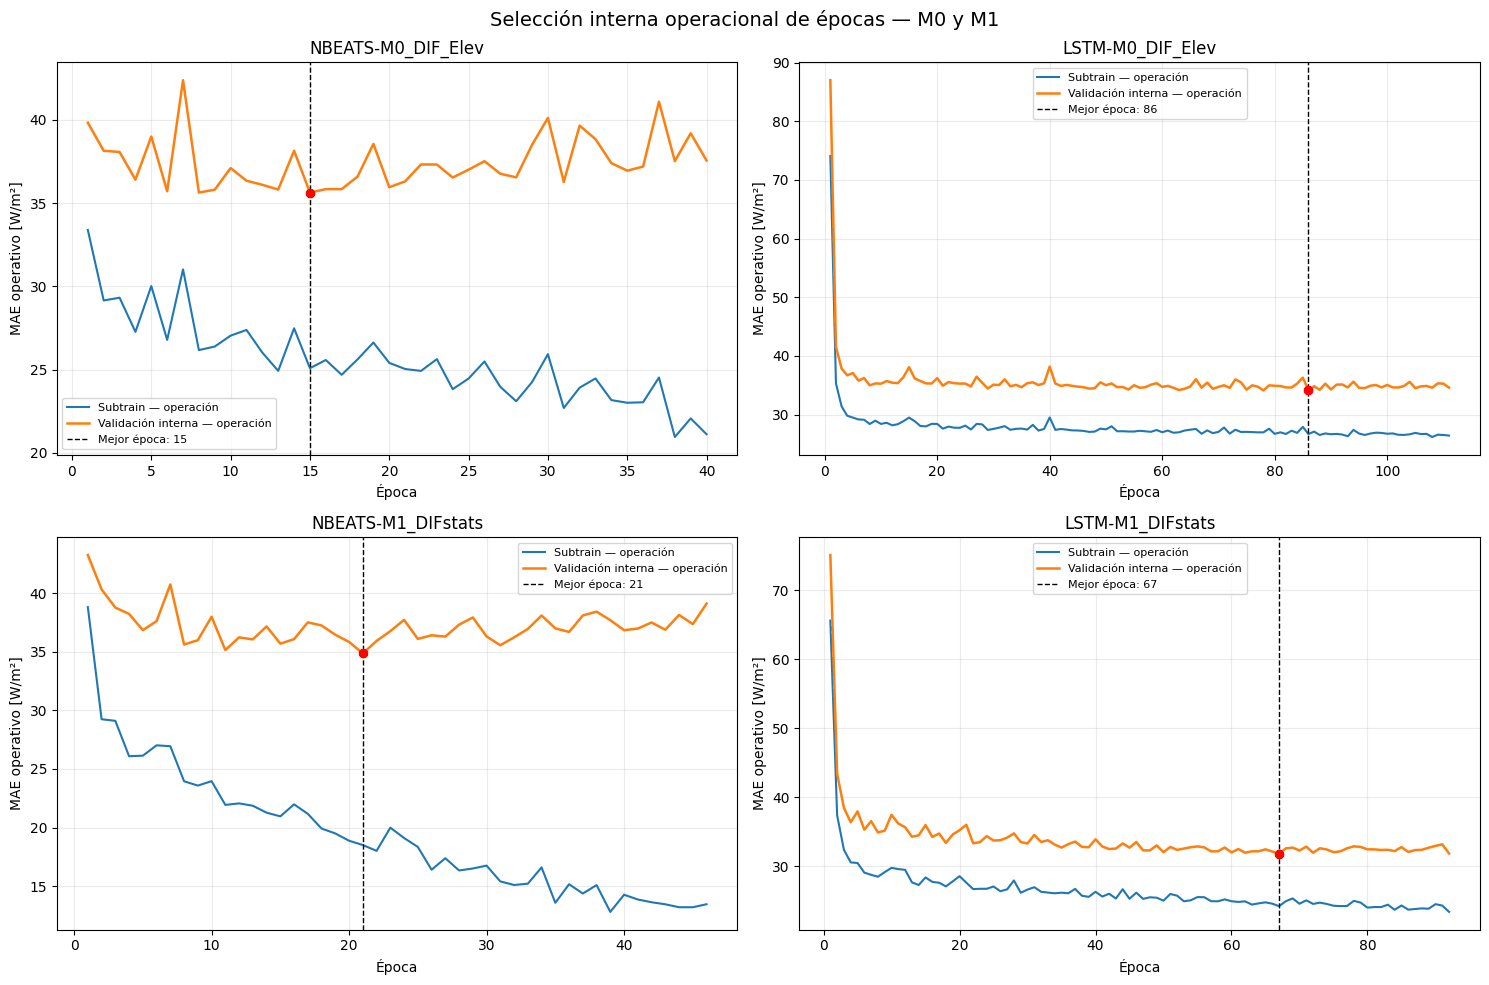


FASE 2B COMPLETADA


,modelo,mejor_epoca,MAE_interna_operacion,epocas_ejecutadas,tiempo_minutos
0,LSTM-M1_DIFstats,67,31.845491,92,2.094676
1,LSTM-M0_DIF_Elev,86,34.110268,111,2.583512
2,NBEATS-M1_DIFstats,21,34.849586,46,0.656626
3,NBEATS-M0_DIF_Elev,15,35.628086,40,0.833133



Validation externa utilizada: NO

Resultados guardados en:
/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/ingenieria_caracteristicas_operacional_20261007T091724Z/02_seleccion_epocas/M0_M1_operacional

Siguiente paso:
Fase 2C — reentrenar M0 y M1 con todo train durante las épocas seleccionadas y evaluar validation.


In [ ]:
from pathlib import Path
from datetime import datetime, timezone
from IPython.display import display
import copy
import json
import random
import time
import platform
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score

# 1. Configuración congelada
SEED = 42
N_SUBTRAIN = 4428
BATCH_SIZE = 128
MAX_EPOCHS = 300
PATIENCE = 25
MIN_DELTA = 1e-5
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-5
DEVICE = torch.device("cpu")
BASE_DIR = Path("/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado")
PUNTERO_OPERACIONAL = BASE_DIR / "resultados" / "ejecuciones" / "ULTIMA_INGENIERIA_OPERACIONAL.json"
with open(PUNTERO_OPERACIONAL, "r", encoding="utf-8") as archivo:
    puntero_operacional = json.load(archivo)

RUN_DIR = Path(puntero_operacional["run_dir"])
SELECCION_DIR = RUN_DIR / "02_seleccion_epocas" / "M0_M1_operacional"
FIGURAS_DIR = RUN_DIR / "06_figuras"
SELECCION_DIR.mkdir(parents=True, exist_ok=True)
FIGURAS_DIR.mkdir(parents=True, exist_ok=True)
RUTA_MATRICES = Path(puntero_operacional["matrices_M0_M1"])
print("Directorio de selección:")
print(SELECCION_DIR)
print("\nDispositivo:")
print(DEVICE)

# 2. Reproducibilidad
def fijar_semilla(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.use_deterministic_algorithms(True, warn_only=True)

fijar_semilla()

# 3. Cargar matrices preparadas
with np.load(RUTA_MATRICES, allow_pickle=False) as datos:
    X_train_M0_raw = datos["X_train_M0_raw"].copy()
    X_train_M1_raw = datos["X_train_M1_raw"].copy()
    y_train = datos["y_train"].astype(np.float32).reshape(-1)
    fechas_train = pd.DatetimeIndex(pd.to_datetime(datos["fechas_train"]))
    pesos_train = datos["pesos_train"].astype(np.float32).reshape(-1)

assert X_train_M0_raw.shape == (5149, 24, 2)
assert X_train_M1_raw.shape == (5149, 24, 4)
assert y_train.shape == (5149,)
assert pesos_train.shape == (5149,)
assert 0 < N_SUBTRAIN < len(y_train)

# Validation externa no se carga deliberadamente

# 4. Cargar regímenes de train alineados
ruta_mascara_alineada = RUN_DIR / "01_datos" / "mascara_train_alineada_M0_M1.csv"
mascara_train = pd.read_csv(ruta_mascara_alineada, parse_dates=["instante_objetivo"])
assert len(mascara_train) == len(y_train)

def convertir_bool(serie):
    if pd.api.types.is_bool_dtype(serie):
        return serie.to_numpy(dtype=bool)

    mapa = {"true": True, "false": False, "1": True, "0": False}
    resultado = serie.astype(str).str.strip().str.lower().map(mapa)
    if resultado.isna().any():
        raise ValueError(f"No se pudo interpretar como booleano: " f"{serie.name}")

    return resultado.to_numpy(dtype=bool)

es_operacion = convertir_bool(mascara_train["es_operacion"])
es_diurno = convertir_bool(mascara_train["es_completamente_diurno"])
es_transicion = convertir_bool(mascara_train["es_transicion"])
es_noche = convertir_bool(mascara_train["es_noche_completa"])
assert np.array_equal(pesos_train.astype(bool), es_operacion)

# 5. División cronológica interna
fechas_subtrain = fechas_train[:N_SUBTRAIN]
fechas_interna = fechas_train[N_SUBTRAIN:]
y_subtrain_raw = y_train[:N_SUBTRAIN]
y_interna_raw = y_train[N_SUBTRAIN:]
pesos_subtrain = pesos_train[:N_SUBTRAIN]
pesos_interna = pesos_train[N_SUBTRAIN:]
regimenes_subtrain = {
    "operacion": es_operacion[:N_SUBTRAIN],
    "completamente_diurno": es_diurno[:N_SUBTRAIN],
    "transicion": es_transicion[:N_SUBTRAIN],
    "noche": es_noche[:N_SUBTRAIN],
}
regimenes_interna = {
    "operacion": es_operacion[N_SUBTRAIN:],
    "completamente_diurno": es_diurno[N_SUBTRAIN:],
    "transicion": es_transicion[N_SUBTRAIN:],
    "noche": es_noche[N_SUBTRAIN:],
}
resumen_division = pd.DataFrame(
    [
        {
            "conjunto": "subtrain",
            "n_total": N_SUBTRAIN,
            "inicio": fechas_subtrain.min(),
            "fin": fechas_subtrain.max(),
            "n_operacion": int(regimenes_subtrain["operacion"].sum()),
            "n_diurno": int(regimenes_subtrain["completamente_diurno"].sum()),
            "n_transicion": int(regimenes_subtrain["transicion"].sum()),
            "n_noche": int(regimenes_subtrain["noche"].sum()),
        },
        {
            "conjunto": "validacion_interna",
            "n_total": len(y_interna_raw),
            "inicio": fechas_interna.min(),
            "fin": fechas_interna.max(),
            "n_operacion": int(regimenes_interna["operacion"].sum()),
            "n_diurno": int(regimenes_interna["completamente_diurno"].sum()),
            "n_transicion": int(regimenes_interna["transicion"].sum()),
            "n_noche": int(regimenes_interna["noche"].sum()),
        },
    ]
)
print("\n=== DIVISIÓN CRONOLÓGICA INTERNA ===")
display(resumen_division)
resumen_division.to_csv(SELECCION_DIR / "division_cronologica_interna.csv", index=False)

# 6. Arquitecturas históricas
class NBEATSBlockMultivariante(nn.Module):
    def __init__(self, n_features, window=24, horizon=1, hidden_size=128, n_dense_layers=3):
        super().__init__()
        input_size = window * n_features
        capas = [nn.Linear(input_size, hidden_size), nn.ReLU()]
        for _ in range(n_dense_layers - 1):
            capas.extend([nn.Linear(hidden_size, hidden_size), nn.ReLU()])

        self.fc = nn.Sequential(*capas)
        self.backcast_head = nn.Linear(hidden_size, window)
        self.forecast_head = nn.Linear(hidden_size, horizon)

    def forward(self, x):
        h = self.fc(x)
        return (self.backcast_head(h), self.forecast_head(h))

class NBEATSMultivariante(nn.Module):
    def __init__(
        self,
        n_features,
        window=24,
        horizon=1,
        n_stacks=2,
        blocks_per_stack=3,
        hidden_size=128,
        n_dense_layers=3,
    ):
        super().__init__()
        self.horizon = horizon
        self.blocks = nn.ModuleList(
            [
                NBEATSBlockMultivariante(
                    n_features=n_features,
                    window=window,
                    horizon=horizon,
                    hidden_size=hidden_size,
                    n_dense_layers=n_dense_layers,
                )
                for _ in range(n_stacks * blocks_per_stack)
            ]
        )

    def forward(self, x):
        # Residuo únicamente sobre DIF
        residual_dif = x[:, :, 0]

        # Las covariables permanecen fijas
        covariables = x[:, :, 1:]
        forecast_total = torch.zeros((x.shape[0], self.horizon), device=x.device, dtype=x.dtype)
        for bloque in self.blocks:
            entrada = torch.cat([residual_dif.unsqueeze(-1), covariables], dim=2).reshape(
                x.shape[0], -1
            )
            backcast, forecast = bloque(entrada)
            residual_dif = residual_dif - backcast
            forecast_total = forecast_total + forecast

        return forecast_total.squeeze(-1)

class LSTMMultivariante(nn.Module):
    def __init__(self, n_features, hidden_size=64, num_layers=1):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=n_features, hidden_size=hidden_size, num_layers=num_layers, batch_first=True
        )
        self.head = nn.Sequential(nn.Linear(hidden_size, 32), nn.ReLU(), nn.Linear(32, 1))

    def forward(self, x):
        salida, _ = self.lstm(x)
        return self.head(salida[:, -1, :]).squeeze(-1)

def contar_parametros(modelo):
    return sum(parametro.numel() for parametro in modelo.parameters() if parametro.requires_grad)


# 7. Métricas
def metricas_originales(y_real, y_predicho, mascara, ambito):
    mascara = np.asarray(mascara, dtype=bool)
    real = np.asarray(y_real)[mascara]
    predicho = np.asarray(y_predicho)[mascara]
    if len(real) == 0:
        return {
            "ambito": ambito,
            "n": 0,
            "DIF_media": np.nan,
            "DIF_mediana": np.nan,
            "MAE": np.nan,
            "nMAE_pct": np.nan,
            "RMSE": np.nan,
            "R2": np.nan,
            "sesgo": np.nan,
        }

    errores = real - predicho
    mae = float(np.mean(np.abs(errores)))
    rmse = float(np.sqrt(np.mean(errores**2)))
    sesgo = float(np.mean(predicho - real))
    dif_media = float(np.mean(real))
    dif_mediana = float(np.median(real))
    if len(real) > 1 and np.var(real) > 0:
        r2 = float(r2_score(real, predicho))
    else:
        r2 = np.nan

    nmae = float(100 * mae / dif_media) if ambito != "noche" and dif_media > 1.0 else np.nan
    return {
        "ambito": ambito,
        "n": len(real),
        "DIF_media": dif_media,
        "DIF_mediana": dif_mediana,
        "MAE": mae,
        "nMAE_pct": nmae,
        "RMSE": rmse,
        "R2": r2,
        "sesgo": sesgo,
    }


# 8. Predicción
def predecir_original(modelo, X_scaled, scaler_y):
    modelo.eval()
    predicciones = []
    loader = DataLoader(
        TensorDataset(torch.from_numpy(X_scaled)),
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0,
    )
    with torch.no_grad():
        for (xb,) in loader:
            pred = modelo(xb.to(DEVICE)).cpu().numpy()
            predicciones.append(pred)

    pred_scaled = np.concatenate(predicciones).reshape(-1, 1)
    return scaler_y.inverse_transform(pred_scaled).reshape(-1)


# 9. Preparación y selección para una configuración
def seleccionar_configuracion(codigo_modelo, X_train_raw, canales):
    print("\n" + "=" * 78)
    print(f"PREPARACIÓN DE {codigo_modelo}: " f"{canales}")
    print("=" * 78)
    X_sub_raw = np.asarray(X_train_raw[:N_SUBTRAIN], dtype=np.float32)
    X_int_raw = np.asarray(X_train_raw[N_SUBTRAIN:], dtype=np.float32)
    mascara_operacion_sub = pesos_subtrain > 0

    # Los escaladores se ajustan solo con las
    # muestras cuyo objetivo pertenece a operación.
    scaler_X = StandardScaler()
    scaler_y = StandardScaler()
    n_features = X_sub_raw.shape[2]
    scaler_X.fit(X_sub_raw[mascara_operacion_sub].reshape(-1, n_features))
    scaler_y.fit(y_subtrain_raw[mascara_operacion_sub].reshape(-1, 1))

    def transformar_X(X):
        forma = X.shape
        return scaler_X.transform(X.reshape(-1, forma[2])).reshape(forma).astype(np.float32)

    X_sub = transformar_X(X_sub_raw)
    X_int = transformar_X(X_int_raw)
    y_sub = scaler_y.transform(y_subtrain_raw.reshape(-1, 1)).reshape(-1).astype(np.float32)
    y_int = scaler_y.transform(y_interna_raw.reshape(-1, 1)).reshape(-1).astype(np.float32)
    carpeta_configuracion = SELECCION_DIR / codigo_modelo
    carpeta_configuracion.mkdir(parents=True, exist_ok=True)
    joblib.dump(scaler_X, carpeta_configuracion / "scaler_X_subtrain.joblib")
    joblib.dump(scaler_y, carpeta_configuracion / "scaler_y_subtrain.joblib")
    resultados_configuracion = []
    arquitecturas = {
        "NBEATS": lambda: (
            NBEATSMultivariante(
                n_features=n_features,
                window=24,
                horizon=1,
                n_stacks=2,
                blocks_per_stack=3,
                hidden_size=128,
                n_dense_layers=3,
            )
        ),
        "LSTM": lambda: (LSTMMultivariante(n_features=n_features, hidden_size=64, num_layers=1)),
    }
    for arquitectura, fabrica in arquitecturas.items():
        fijar_semilla(SEED)
        modelo = fabrica().to(DEVICE)
        nombre_completo = f"{arquitectura}-{codigo_modelo}"
        print("\n" + "-" * 72)
        print(nombre_completo)
        print("Parámetros entrenables:", contar_parametros(modelo))
        print("-" * 72)
        dataset_sub = TensorDataset(
            torch.from_numpy(X_sub),
            torch.from_numpy(y_sub),
            torch.from_numpy(pesos_subtrain.astype(np.float32)),
        )
        generador = torch.Generator()
        generador.manual_seed(SEED)
        loader_sub = DataLoader(
            dataset_sub, batch_size=BATCH_SIZE, shuffle=True, generator=generador, num_workers=0
        )
        criterio_individual = nn.L1Loss(reduction="none")
        optimizador = torch.optim.Adam(
            modelo.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
        )
        mejor_mae_operacion = np.inf
        mejor_epoca = None
        mejor_estado = None
        epocas_sin_mejora = 0
        historial = []
        inicio_entrenamiento = time.perf_counter()
        for epoca in range(1, MAX_EPOCHS + 1):
            modelo.train()
            suma_loss = 0.0
            suma_pesos = 0.0
            for xb, yb, wb in loader_sub:
                xb = xb.to(DEVICE)
                yb = yb.to(DEVICE)
                wb = wb.to(DEVICE)
                peso_batch = wb.sum()

                # Es improbable, pero un batch podría
                # contener únicamente objetivos nocturnos.
                if peso_batch.item() == 0:
                    continue

                optimizador.zero_grad(set_to_none=True)
                pred = modelo(xb)
                errores = criterio_individual(pred, yb)
                loss = (errores * wb).sum() / peso_batch
                loss.backward()
                torch.nn.utils.clip_grad_norm_(modelo.parameters(), max_norm=1.0)
                optimizador.step()
                suma_loss += loss.item() * peso_batch.item()
                suma_pesos += peso_batch.item()

            loss_train = suma_loss / suma_pesos
            pred_sub = predecir_original(modelo, X_sub, scaler_y)
            pred_int = predecir_original(modelo, X_int, scaler_y)
            met_sub = metricas_originales(
                y_subtrain_raw, pred_sub, regimenes_subtrain["operacion"], "operacion"
            )
            met_int = metricas_originales(
                y_interna_raw, pred_int, regimenes_interna["operacion"], "operacion"
            )
            mae_sub = met_sub["MAE"]
            mae_int = met_int["MAE"]
            historial.append(
                {
                    "epoca": epoca,
                    "loss_escalada_ponderada": (loss_train),
                    "MAE_subtrain_operacion": (mae_sub),
                    "MAE_interna_operacion": (mae_int),
                }
            )
            if mae_int < mejor_mae_operacion - MIN_DELTA:
                mejor_mae_operacion = mae_int
                mejor_epoca = epoca
                mejor_estado = copy.deepcopy(modelo.state_dict())
                epocas_sin_mejora = 0
                indicador = " <-- nuevo mínimo"
            else:
                epocas_sin_mejora += 1
                indicador = ""

            if epoca == 1 or epoca % 5 == 0 or indicador:
                print(
                    f"Época {epoca:03d} | "
                    f"MAE subtrain operación: "
                    f"{mae_sub:.6f} | "
                    f"MAE interna operación: "
                    f"{mae_int:.6f}"
                    f"{indicador}"
                )

            if epocas_sin_mejora >= PATIENCE:
                print(f"\nEarly stopping: " f"{PATIENCE} épocas sin mejora.")
                break

        tiempo_segundos = time.perf_counter() - inicio_entrenamiento
        if mejor_estado is None:
            raise RuntimeError(f"No se guardó un estado para " f"{nombre_completo}.")

        modelo.load_state_dict(mejor_estado)

        # Predicciones del mejor checkpoint
        pred_sub_mejor = predecir_original(modelo, X_sub, scaler_y)
        pred_int_mejor = predecir_original(modelo, X_int, scaler_y)
        filas_metricas = []
        for conjunto, reales, predichos, regimenes in [
            ("subtrain", y_subtrain_raw, pred_sub_mejor, regimenes_subtrain),
            ("validacion_interna", y_interna_raw, pred_int_mejor, regimenes_interna),
        ]:
            for ambito in ["operacion", "completamente_diurno", "transicion", "noche"]:
                metrica = metricas_originales(reales, predichos, regimenes[ambito], ambito)
                metrica.update(
                    {
                        "modelo": nombre_completo,
                        "arquitectura": arquitectura,
                        "configuracion": codigo_modelo,
                        "conjunto": conjunto,
                        "epoca_seleccionada": (mejor_epoca),
                    }
                )
                filas_metricas.append(metrica)

        df_metricas = pd.DataFrame(filas_metricas)
        df_historial = pd.DataFrame(historial)
        df_historial.to_csv(
            carpeta_configuracion / f"historial_{arquitectura.lower()}.csv", index=False
        )
        df_metricas.to_csv(
            carpeta_configuracion / f"metricas_mejor_{arquitectura.lower()}.csv", index=False
        )
        torch.save(
            {
                "model_state_dict": mejor_estado,
                "modelo": nombre_completo,
                "arquitectura": arquitectura,
                "configuracion": codigo_modelo,
                "n_features": n_features,
                "canales": canales,
                "lookback": 24,
                "mejor_epoca": mejor_epoca,
                "mejor_MAE_interna_operacion": (mejor_mae_operacion),
                "patience": PATIENCE,
                "seed": SEED,
                "n_subtrain": N_SUBTRAIN,
                "n_parametros": (contar_parametros(modelo)),
                "tiempo_entrenamiento_segundos": (tiempo_segundos),
                "criterio_seleccion": ("MAE_validacion_interna_operacion"),
            },
            carpeta_configuracion / f"mejor_checkpoint_{arquitectura.lower()}.pt",
        )
        resultados_configuracion.append(
            {
                "modelo": nombre_completo,
                "arquitectura": arquitectura,
                "configuracion": codigo_modelo,
                "n_features": n_features,
                "n_parametros": (contar_parametros(modelo)),
                "mejor_epoca": mejor_epoca,
                "MAE_interna_operacion": (mejor_mae_operacion),
                "epocas_ejecutadas": len(df_historial),
                "tiempo_segundos": (tiempo_segundos),
                "tiempo_minutos": (tiempo_segundos / 60),
                "historial": df_historial,
                "metricas": df_metricas,
            }
        )
        print(
            f"\n{nombre_completo}: "
            f"mejor época={mejor_epoca}, "
            f"MAE interna operación="
            f"{mejor_mae_operacion:.6f}, "
            f"tiempo={tiempo_segundos/60:.2f} min"
        )

    return resultados_configuracion


# 10. Ejecutar M0 y M1
resultados_M0 = seleccionar_configuracion(
    codigo_modelo="M0_DIF_Elev", X_train_raw=X_train_M0_raw, canales=["DIF_media", "elevacion"]
)
resultados_M1 = seleccionar_configuracion(
    codigo_modelo="M1_DIFstats",
    X_train_raw=X_train_M1_raw,
    canales=["DIF_media", "elevacion", "DIF_std", "DIF_rango"],
)
resultados = resultados_M0 + resultados_M1

# 11. Tabla resumen
tabla_seleccion = (
    pd.DataFrame(
        [
            {
                clave: valor
                for clave, valor in resultado.items()
                if clave not in {"historial", "metricas"}
            }
            for resultado in resultados
        ]
    )
    .sort_values("MAE_interna_operacion")
    .reset_index(drop=True)
)
print("\n=== SELECCIÓN INTERNA OPERACIONAL ===")
display(tabla_seleccion.round(6))
tabla_seleccion.to_csv(SELECCION_DIR / "resumen_seleccion_epocas_M0_M1.csv", index=False)
metricas_completas = pd.concat(
    [resultado["metricas"] for resultado in resultados], ignore_index=True
)
columnas_metricas = [
    "modelo",
    "conjunto",
    "ambito",
    "n",
    "DIF_media",
    "DIF_mediana",
    "MAE",
    "nMAE_pct",
    "RMSE",
    "R2",
    "sesgo",
    "epoca_seleccionada",
]
print("\n=== MÉTRICAS DEL MEJOR CHECKPOINT POR RÉGIMEN ===")
display(metricas_completas[columnas_metricas].sort_values(["conjunto", "ambito", "MAE"]).round(6))
metricas_completas.to_csv(SELECCION_DIR / "metricas_mejores_checkpoints_M0_M1.csv", index=False)

# 12. Curvas de aprendizaje
fig, ejes = plt.subplots(2, 2, figsize=(15, 10), sharex=False)
for eje, resultado in zip(ejes.ravel(), resultados):
    historial = resultado["historial"]
    eje.plot(
        historial["epoca"],
        historial["MAE_subtrain_operacion"],
        label="Subtrain — operación",
        linewidth=1.5,
    )
    eje.plot(
        historial["epoca"],
        historial["MAE_interna_operacion"],
        label="Validación interna — operación",
        linewidth=1.8,
    )
    eje.axvline(
        resultado["mejor_epoca"],
        color="black",
        linestyle="--",
        linewidth=1,
        label=(f"Mejor época: " f"{resultado['mejor_epoca']}"),
    )
    eje.scatter(resultado["mejor_epoca"], resultado["MAE_interna_operacion"], color="red", zorder=5)
    eje.set_title(resultado["modelo"])
    eje.set_xlabel("Época")
    eje.set_ylabel("MAE operativo [W/m²]")
    eje.grid(alpha=0.25)
    eje.legend(fontsize=8)

fig.suptitle("Selección interna operacional de épocas — M0 y M1", fontsize=14)
fig.tight_layout()
ruta_figura = FIGURAS_DIR / "seleccion_interna_operacional_M0_M1.png"
plt.savefig(ruta_figura, dpi=180, bbox_inches="tight")
plt.show()

# 13. Configuración y puntero
configuracion_seleccion = {
    "fase": "2B_seleccion_interna_M0_M1",
    "seed": SEED,
    "n_subtrain": N_SUBTRAIN,
    "n_validacion_interna": (len(y_train) - N_SUBTRAIN),
    "batch_size": BATCH_SIZE,
    "max_epochs": MAX_EPOCHS,
    "patience": PATIENCE,
    "min_delta": MIN_DELTA,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "device": str(DEVICE),
    "criterio_entrenamiento": ("MAE escalado con peso 0 en noche"),
    "criterio_early_stopping": ("MAE original de operación en validación interna"),
    "validation_externa_utilizada": False,
    "arquitecturas": {
        "NBEATS": {"stacks": 2, "blocks_per_stack": 3, "hidden_size": 128, "dense_layers": 3},
        "LSTM": {"hidden_size": 64, "num_layers": 1, "head_hidden": 32},
    },
    "entorno": {
        "python": platform.python_version(),
        "torch": torch.__version__,
        "dispositivo": str(DEVICE),
    },
}
with open(SELECCION_DIR / "configuracion_seleccion_M0_M1.json", "w", encoding="utf-8") as archivo:
    json.dump(configuracion_seleccion, archivo, ensure_ascii=False, indent=2)

puntero_operacional["estado"] = "fase_2B_epocas_M0_M1_seleccionadas"
puntero_operacional["siguiente_fase"] = "fase_2C_reentrenamiento_completo_M0_M1"
puntero_operacional["seleccion_M0_M1"] = str(SELECCION_DIR)
puntero_operacional["epocas_M0_M1"] = {
    fila["modelo"]: int(fila["mejor_epoca"]) for _, fila in tabla_seleccion.iterrows()
}
with open(PUNTERO_OPERACIONAL, "w", encoding="utf-8") as archivo:
    json.dump(puntero_operacional, archivo, ensure_ascii=False, indent=2)

print("\n" + "=" * 72)
print("FASE 2B COMPLETADA")
print("=" * 72)
display(
    tabla_seleccion[
        ["modelo", "mejor_epoca", "MAE_interna_operacion", "epocas_ejecutadas", "tiempo_minutos"]
    ].round(6)
)
print("\nValidation externa utilizada: NO")
print("\nResultados guardados en:")
print(SELECCION_DIR)
print("\nSiguiente paso:")
print(
    "Fase 2C — reentrenar M0 y M1 con todo train "
    "durante las épocas seleccionadas y evaluar validation."
)

**Resultados.** El menor MAE interno de operación corresponde a la LSTM-M1 (31,85 W/m², época 67), seguida de la LSTM-M0 (34,11 W/m², época 86), la N-BEATS-M1 (34,85 W/m², época 21) y la N-BEATS-M0 (35,63 W/m², época 15). Sin fijar a cero la predicción nocturna, el MAE nocturno de la validación interna oscila entre 10,30 W/m² (LSTM-M1) y 18,62 W/m² (N-BEATS-M1).

### 3.3 Reentrenamiento con peso nocturno nulo

Los cuatro modelos se reentrenan con todo el conjunto de entrenamiento durante las épocas seleccionadas y se evalúan una sola vez en validación, con la predicción nocturna fijada a cero.

=== ÉPOCAS SELECCIONADAS ===


,modelo,mejor_epoca,MAE_interna_operacion
1,LSTM-M0_DIF_Elev,86,34.110268
0,LSTM-M1_DIFstats,67,31.845491
3,NBEATS-M0_DIF_Elev,15,35.628086
2,NBEATS-M1_DIFstats,21,34.849586



REENTRENANDO NBEATS-M0_DIF_Elev DURANTE 15 ÉPOCAS
Época 001/015 | loss operacional: 0.378291
Época 010/015 | loss operacional: 0.249266
Época 015/015 | loss operacional: 0.236831

REENTRENANDO LSTM-M0_DIF_Elev DURANTE 86 ÉPOCAS
Época 001/086 | loss operacional: 0.754240
Época 010/086 | loss operacional: 0.253558
Época 020/086 | loss operacional: 0.248953
Época 030/086 | loss operacional: 0.249198
Época 040/086 | loss operacional: 0.246778
Época 050/086 | loss operacional: 0.247889
Época 060/086 | loss operacional: 0.247606
Época 070/086 | loss operacional: 0.243875
Época 080/086 | loss operacional: 0.244790
Época 086/086 | loss operacional: 0.240462

REENTRENANDO NBEATS-M1_DIFstats DURANTE 21 ÉPOCAS
Época 001/021 | loss operacional: 0.395771
Época 010/021 | loss operacional: 0.218513
Época 020/021 | loss operacional: 0.185340
Época 021/021 | loss operacional: 0.189648

REENTRENANDO LSTM-M1_DIFstats DURANTE 67 ÉPOCAS
Época 001/067 | loss operacional: 0.699932
Época 010/067 | loss opera

,modelo,ambito,n,DIF_media,DIF_mediana,MAE,nMAE_pct,RMSE,R2,sesgo
15,LSTM-M1_DIFstats,total_con_mascara_nocturna,1464,85.233276,30.591667,15.989876,18.760133,32.691456,0.908573,1.316040
0,NBEATS-M0_DIF_Elev,total_con_mascara_nocturna,1464,85.233276,30.591667,17.248209,20.236473,32.692520,0.908567,2.301924
5,LSTM-M0_DIF_Elev,total_con_mascara_nocturna,1464,85.233276,30.591667,17.325529,20.327189,33.181110,0.905814,3.497514
10,NBEATS-M1_DIFstats,total_con_mascara_nocturna,1464,85.233276,30.591667,19.068712,22.372380,35.813648,0.890276,7.321920
16,LSTM-M1_DIFstats,operacion,884,141.797562,127.733337,25.837492,18.221394,42.062344,0.843193,1.537500
1,NBEATS-M0_DIF_Elev,operacion,884,141.797562,127.733337,27.921432,19.691053,42.063717,0.843183,3.170230
6,LSTM-M0_DIF_Elev,operacion,884,141.797562,127.733337,28.049480,19.781356,42.692604,0.838459,5.150256
11,NBEATS-M1_DIFstats,operacion,884,141.797562,127.733337,30.936384,21.817289,46.081009,0.811799,11.483889
17,LSTM-M1_DIFstats,completamente_diurno,765,162.723083,145.683334,29.329180,18.023982,45.183998,0.791194,1.942371
2,NBEATS-M0_DIF_Elev,completamente_diurno,765,162.723083,145.683334,31.219250,19.185508,45.095966,0.792007,2.944436



=== RANKING EN OPERACIÓN ===


,modelo,ambito,n,DIF_media,DIF_mediana,MAE,nMAE_pct,RMSE,R2,sesgo
0,LSTM-M1_DIFstats,operacion,884,141.797562,127.733337,25.837492,18.221394,42.062344,0.843193,1.537500
1,NBEATS-M0_DIF_Elev,operacion,884,141.797562,127.733337,27.921432,19.691053,42.063717,0.843183,3.170230
2,LSTM-M0_DIF_Elev,operacion,884,141.797562,127.733337,28.049480,19.781356,42.692604,0.838459,5.150256
3,NBEATS-M1_DIFstats,operacion,884,141.797562,127.733337,30.936384,21.817289,46.081009,0.811799,11.483889


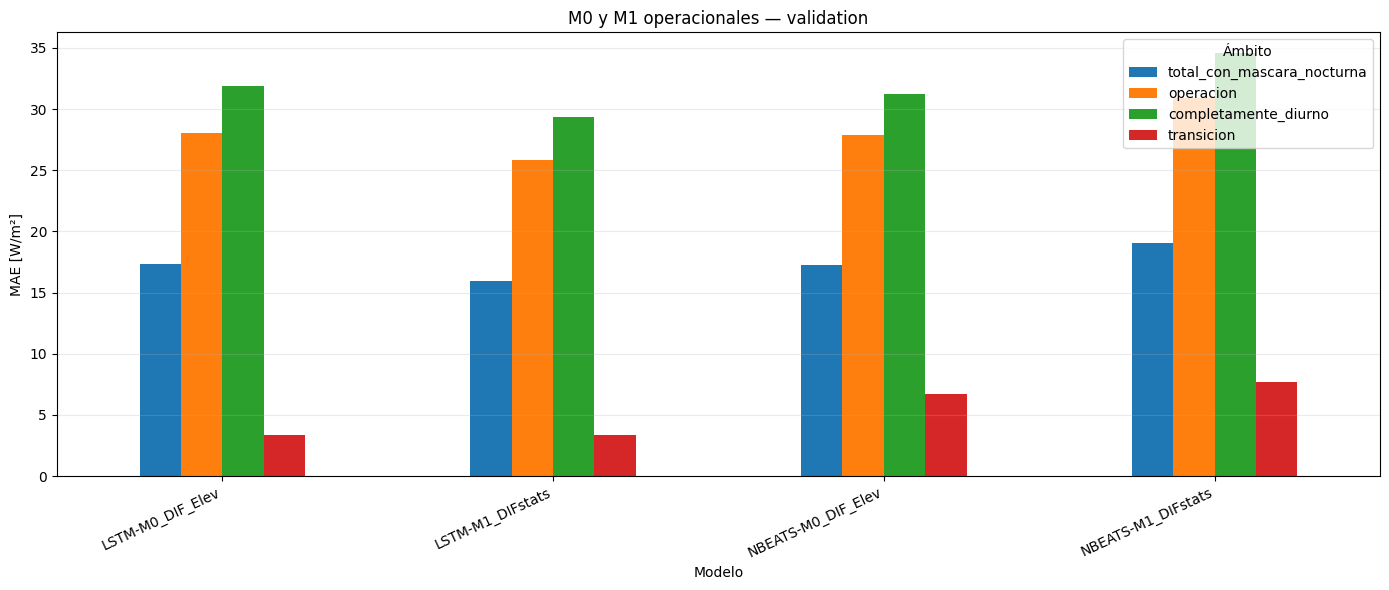


FASE 2C COMPLETADA


,modelo,arquitectura,configuracion,epocas,n_features,n_parametros,tiempo_minutos,ruta_modelo
0,NBEATS-M0_DIF_Elev,NBEATS,M0_DIF_Elev,15,2,255126,0.3780,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...
1,LSTM-M0_DIF_Elev,LSTM,M0_DIF_Elev,86,2,19521,1.6046,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...
2,NBEATS-M1_DIFstats,NBEATS,M1_DIFstats,21,4,291990,0.2827,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...
3,LSTM-M1_DIFstats,LSTM,M1_DIFstats,67,4,20033,1.2630,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...



Test utilizado: NO

Resultados guardados en:
/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/ingenieria_caracteristicas_operacional_20261007T091724Z/05_metricas/M0_M1_operacional

Siguiente fase:
Preparación de M2 = DIFstats + SWD.


In [ ]:
from pathlib import Path
from IPython.display import display
import json
import random
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score

# 1. Configuración
SEED = 42
BATCH_SIZE = 128
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-5
DEVICE = torch.device("cpu")
BASE_DIR = Path("/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado")
PUNTERO_OPERACIONAL = BASE_DIR / "resultados" / "ejecuciones" / "ULTIMA_INGENIERIA_OPERACIONAL.json"
with open(PUNTERO_OPERACIONAL, "r", encoding="utf-8") as archivo:
    puntero = json.load(archivo)

RUN_DIR = Path(puntero["run_dir"])
RUTA_MATRICES = Path(puntero["matrices_M0_M1"])
SELECCION_DIR = Path(puntero["seleccion_M0_M1"])
MODELOS_DIR = RUN_DIR / "03_modelos" / "M0_M1_operacional"
PREDICCIONES_DIR = RUN_DIR / "04_predicciones" / "M0_M1_operacional"
METRICAS_DIR = RUN_DIR / "05_metricas" / "M0_M1_operacional"
FIGURAS_DIR = RUN_DIR / "06_figuras"
for ruta in [MODELOS_DIR, PREDICCIONES_DIR, METRICAS_DIR, FIGURAS_DIR]:
    ruta.mkdir(parents=True, exist_ok=True)

# 2. Semilla
def fijar_semilla(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.use_deterministic_algorithms(True, warn_only=True)


# 3. Cargar matrices
with np.load(RUTA_MATRICES, allow_pickle=False) as datos:
    X_train_M0_raw = datos["X_train_M0_raw"].copy()
    X_validation_M0_raw = datos["X_validation_M0_raw"].copy()
    X_train_M1_raw = datos["X_train_M1_raw"].copy()
    X_validation_M1_raw = datos["X_validation_M1_raw"].copy()
    y_train = datos["y_train"].astype(np.float32).reshape(-1)
    y_validation = datos["y_validation"].astype(np.float32).reshape(-1)
    fechas_train = pd.DatetimeIndex(pd.to_datetime(datos["fechas_train"]))
    fechas_validation = pd.DatetimeIndex(pd.to_datetime(datos["fechas_validation"]))
    pesos_train = datos["pesos_train"].astype(np.float32).reshape(-1)

assert X_train_M0_raw.shape == (5149, 24, 2)
assert X_validation_M0_raw.shape == (1464, 24, 2)
assert X_train_M1_raw.shape == (5149, 24, 4)
assert X_validation_M1_raw.shape == (1464, 24, 4)

# 4. Cargar regímenes de validation
ruta_mascara_validation = RUN_DIR / "01_datos" / "mascara_validation_alineada_M0_M1.csv"
mascara_validation = pd.read_csv(ruta_mascara_validation, parse_dates=["instante_objetivo"])
assert len(mascara_validation) == 1464

def convertir_bool(serie):
    if pd.api.types.is_bool_dtype(serie):
        return serie.to_numpy(dtype=bool)

    resultado = (
        serie.astype(str)
        .str.strip()
        .str.lower()
        .map({"true": True, "false": False, "1": True, "0": False})
    )
    if resultado.isna().any():
        raise ValueError(f"No se pudo interpretar {serie.name}.")

    return resultado.to_numpy(dtype=bool)

mascaras_validation = {
    "total_con_mascara_nocturna": np.ones(len(y_validation), dtype=bool),
    "operacion": convertir_bool(mascara_validation["es_operacion"]),
    "completamente_diurno": convertir_bool(mascara_validation["es_completamente_diurno"]),
    "transicion": convertir_bool(mascara_validation["es_transicion"]),
    "noche": convertir_bool(mascara_validation["es_noche_completa"]),
}
mascara_noche_validation = mascaras_validation["noche"]
assert mascaras_validation["operacion"].sum() == 884
assert mascaras_validation["noche"].sum() == 580

# 5. Recuperar épocas seleccionadas
ruta_seleccion = SELECCION_DIR / "resumen_seleccion_epocas_M0_M1.csv"
tabla_seleccion = pd.read_csv(ruta_seleccion)
print("=== ÉPOCAS SELECCIONADAS ===")
display(tabla_seleccion[["modelo", "mejor_epoca", "MAE_interna_operacion"]].sort_values("modelo"))

# 6. Arquitecturas
class NBEATSBlockMultivariante(nn.Module):
    def __init__(self, n_features, window=24, horizon=1, hidden_size=128, n_dense_layers=3):
        super().__init__()
        input_size = window * n_features
        capas = [nn.Linear(input_size, hidden_size), nn.ReLU()]
        for _ in range(n_dense_layers - 1):
            capas.extend([nn.Linear(hidden_size, hidden_size), nn.ReLU()])

        self.fc = nn.Sequential(*capas)
        self.backcast_head = nn.Linear(hidden_size, window)
        self.forecast_head = nn.Linear(hidden_size, horizon)

    def forward(self, x):
        h = self.fc(x)
        return (self.backcast_head(h), self.forecast_head(h))

class NBEATSMultivariante(nn.Module):
    def __init__(
        self,
        n_features,
        window=24,
        horizon=1,
        n_stacks=2,
        blocks_per_stack=3,
        hidden_size=128,
        n_dense_layers=3,
    ):
        super().__init__()
        self.horizon = horizon
        self.blocks = nn.ModuleList(
            [
                NBEATSBlockMultivariante(
                    n_features=n_features,
                    window=window,
                    horizon=horizon,
                    hidden_size=hidden_size,
                    n_dense_layers=n_dense_layers,
                )
                for _ in range(n_stacks * blocks_per_stack)
            ]
        )

    def forward(self, x):
        residual_dif = x[:, :, 0]
        covariables = x[:, :, 1:]
        forecast_total = torch.zeros((x.shape[0], self.horizon), device=x.device, dtype=x.dtype)
        for bloque in self.blocks:
            entrada = torch.cat([residual_dif.unsqueeze(-1), covariables], dim=2).reshape(
                x.shape[0], -1
            )
            backcast, forecast = bloque(entrada)
            residual_dif = residual_dif - backcast
            forecast_total = forecast_total + forecast

        return forecast_total.squeeze(-1)

class LSTMMultivariante(nn.Module):
    def __init__(self, n_features, hidden_size=64, num_layers=1):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=n_features, hidden_size=hidden_size, num_layers=num_layers, batch_first=True
        )
        self.head = nn.Sequential(nn.Linear(hidden_size, 32), nn.ReLU(), nn.Linear(32, 1))

    def forward(self, x):
        salida, _ = self.lstm(x)
        return self.head(salida[:, -1, :]).squeeze(-1)

def contar_parametros(modelo):
    return sum(parametro.numel() for parametro in modelo.parameters() if parametro.requires_grad)


# 7. Métricas oficiales
def calcular_metricas(y_real, y_predicho, mascara, ambito):
    mascara = np.asarray(mascara, dtype=bool)
    real = np.asarray(y_real)[mascara]
    predicho = np.asarray(y_predicho)[mascara]
    errores = real - predicho
    mae = float(np.mean(np.abs(errores)))
    rmse = float(np.sqrt(np.mean(errores**2)))
    sesgo = float(np.mean(predicho - real))
    dif_media = float(np.mean(real))
    dif_mediana = float(np.median(real))
    r2 = float(r2_score(real, predicho)) if len(real) > 1 and np.var(real) > 0 else np.nan
    nmae = float(100 * mae / dif_media) if ambito != "noche" and dif_media > 1.0 else np.nan
    return {
        "ambito": ambito,
        "n": len(real),
        "DIF_media": dif_media,
        "DIF_mediana": dif_mediana,
        "MAE": mae,
        "nMAE_pct": nmae,
        "RMSE": rmse,
        "R2": r2,
        "sesgo": sesgo,
    }


# 8. Configuraciones
CONFIGURACIONES = {
    "M0_DIF_Elev": {
        "X_train": X_train_M0_raw,
        "X_validation": X_validation_M0_raw,
        "canales": ["DIF_media", "elevacion"],
    },
    "M1_DIFstats": {
        "X_train": X_train_M1_raw,
        "X_validation": X_validation_M1_raw,
        "canales": ["DIF_media", "elevacion", "DIF_std", "DIF_rango"],
    },
}
ARQUITECTURAS = ["NBEATS", "LSTM"]

# 9. Reentrenamiento
todas_metricas = []
resumen_modelos = []
todas_predicciones = []
for codigo, configuracion in CONFIGURACIONES.items():
    X_train_raw = np.asarray(configuracion["X_train"], dtype=np.float32)
    X_validation_raw = np.asarray(configuracion["X_validation"], dtype=np.float32)
    canales = configuracion["canales"]
    n_features = X_train_raw.shape[2]

    # Escalado ajustado solo con objetivos operativos
    mascara_operacion_train = pesos_train > 0
    scaler_X = StandardScaler()
    scaler_y = StandardScaler()
    scaler_X.fit(X_train_raw[mascara_operacion_train].reshape(-1, n_features))
    scaler_y.fit(y_train[mascara_operacion_train].reshape(-1, 1))

    def transformar_X(X):
        forma = X.shape
        return scaler_X.transform(X.reshape(-1, forma[2])).reshape(forma).astype(np.float32)

    X_train_scaled = transformar_X(X_train_raw)
    X_validation_scaled = transformar_X(X_validation_raw)
    y_train_scaled = scaler_y.transform(y_train.reshape(-1, 1)).reshape(-1).astype(np.float32)
    for arquitectura in ARQUITECTURAS:
        nombre_modelo = f"{arquitectura}-{codigo}"
        fila_epoca = tabla_seleccion.loc[tabla_seleccion["modelo"] == nombre_modelo]
        if len(fila_epoca) != 1:
            raise ValueError(f"No se encontró una época única para " f"{nombre_modelo}.")

        epocas = int(fila_epoca["mejor_epoca"].iloc[0])
        fijar_semilla(SEED)
        if arquitectura == "NBEATS":
            modelo = NBEATSMultivariante(
                n_features=n_features,
                window=24,
                horizon=1,
                n_stacks=2,
                blocks_per_stack=3,
                hidden_size=128,
                n_dense_layers=3,
            )
        else:
            modelo = LSTMMultivariante(n_features=n_features, hidden_size=64, num_layers=1)

        modelo = modelo.to(DEVICE)
        dataset_train = TensorDataset(
            torch.from_numpy(X_train_scaled),
            torch.from_numpy(y_train_scaled),
            torch.from_numpy(pesos_train.astype(np.float32)),
        )
        generador = torch.Generator()
        generador.manual_seed(SEED)
        loader_train = DataLoader(
            dataset_train, batch_size=BATCH_SIZE, shuffle=True, generator=generador, num_workers=0
        )
        criterio = nn.L1Loss(reduction="none")
        optimizador = torch.optim.Adam(
            modelo.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
        )
        historial = []
        inicio = time.perf_counter()
        print("\n" + "=" * 72)
        print(f"REENTRENANDO {nombre_modelo} " f"DURANTE {epocas} ÉPOCAS")
        print("=" * 72)
        for epoca in range(1, epocas + 1):
            modelo.train()
            suma_loss = 0.0
            suma_pesos = 0.0
            for xb, yb, wb in loader_train:
                xb = xb.to(DEVICE)
                yb = yb.to(DEVICE)
                wb = wb.to(DEVICE)
                peso_batch = wb.sum()
                if peso_batch.item() == 0:
                    continue

                optimizador.zero_grad(set_to_none=True)
                pred = modelo(xb)
                errores = criterio(pred, yb)
                loss = (errores * wb).sum() / peso_batch
                loss.backward()
                torch.nn.utils.clip_grad_norm_(modelo.parameters(), max_norm=1.0)
                optimizador.step()
                suma_loss += loss.item() * peso_batch.item()
                suma_pesos += peso_batch.item()

            loss_epoca = suma_loss / suma_pesos
            historial.append({"epoca": epoca, "loss_operacional_escalada": (loss_epoca)})
            if epoca == 1 or epoca % 10 == 0 or epoca == epocas:
                print(
                    f"Época {epoca:03d}/{epocas:03d} | " f"loss operacional: " f"{loss_epoca:.6f}"
                )

        tiempo_segundos = time.perf_counter() - inicio

        # Predicción de validation
        modelo.eval()
        predicciones_scaled = []
        loader_validation = DataLoader(
            TensorDataset(torch.from_numpy(X_validation_scaled)),
            batch_size=BATCH_SIZE,
            shuffle=False,
            num_workers=0,
        )
        with torch.no_grad():
            for (xb,) in loader_validation:
                pred = modelo(xb.to(DEVICE)).cpu().numpy()
                predicciones_scaled.append(pred)

        pred_scaled = np.concatenate(predicciones_scaled).reshape(-1, 1)
        pred_raw = scaler_y.inverse_transform(pred_scaled).reshape(-1)

        # Máscara física nocturna
        pred_final = np.where(mascara_noche_validation, 0.0, pred_raw)

        # Métricas por ámbito
        metricas_modelo = []
        for ambito, mascara in mascaras_validation.items():
            metrica = calcular_metricas(y_validation, pred_final, mascara, ambito)
            metrica.update(
                {
                    "modelo": nombre_modelo,
                    "arquitectura": arquitectura,
                    "configuracion": codigo,
                    "epocas": epocas,
                    "seed": SEED,
                    "tiempo_entrenamiento_segundos": (tiempo_segundos),
                    "tiempo_entrenamiento_minutos": (tiempo_segundos / 60),
                    "n_parametros": (contar_parametros(modelo)),
                    "mascara_nocturna": True,
                }
            )
            metricas_modelo.append(metrica)

        todas_metricas.extend(metricas_modelo)

        # Guardar predicciones
        df_predicciones = pd.DataFrame(
            {
                "instante_objetivo": (fechas_validation),
                "y_real": y_validation,
                "prediccion_sin_mascara": (pred_raw),
                "prediccion_final": (pred_final),
                "error": (pred_final - y_validation),
                "error_absoluto": np.abs(pred_final - y_validation),
                "regimen_solar": (mascara_validation["regimen_pvlib"].to_numpy()),
                "es_operacion": (mascaras_validation["operacion"]),
                "es_noche": (mascara_noche_validation),
                "modelo": nombre_modelo,
            }
        )
        df_predicciones.to_csv(PREDICCIONES_DIR / f"predicciones_{nombre_modelo}.csv", index=False)
        todas_predicciones.append(df_predicciones)

        # Guardar modelo y escaladores
        carpeta_modelo = MODELOS_DIR / nombre_modelo
        carpeta_modelo.mkdir(parents=True, exist_ok=True)
        ruta_scaler_X = carpeta_modelo / "scaler_X_train_completo.joblib"
        ruta_scaler_y = carpeta_modelo / "scaler_y_train_completo.joblib"
        joblib.dump(scaler_X, ruta_scaler_X)
        joblib.dump(scaler_y, ruta_scaler_y)
        torch.save(
            {
                "model_state_dict": (modelo.state_dict()),
                "modelo": nombre_modelo,
                "arquitectura": arquitectura,
                "configuracion": codigo,
                "canales": canales,
                "n_features": n_features,
                "lookback": 24,
                "horizon": 1,
                "epocas": epocas,
                "seed": SEED,
                "n_parametros": (contar_parametros(modelo)),
                "tiempo_entrenamiento_segundos": (tiempo_segundos),
                "entrenamiento_operacional": True,
                "mascara_nocturna": True,
            },
            carpeta_modelo / "modelo_final.pt",
        )
        pd.DataFrame(historial).to_csv(carpeta_modelo / "historial_train_completo.csv", index=False)
        pd.DataFrame(metricas_modelo).to_csv(
            carpeta_modelo / "metricas_validation.csv", index=False
        )
        resumen_modelos.append(
            {
                "modelo": nombre_modelo,
                "arquitectura": arquitectura,
                "configuracion": codigo,
                "epocas": epocas,
                "n_features": n_features,
                "n_parametros": (contar_parametros(modelo)),
                "tiempo_minutos": (tiempo_segundos / 60),
                "ruta_modelo": str(carpeta_modelo / "modelo_final.pt"),
            }
        )

# 10. Tablas consolidadas
df_metricas = pd.DataFrame(todas_metricas)
df_resumen_modelos = pd.DataFrame(resumen_modelos)
df_predicciones_todas = pd.concat(todas_predicciones, ignore_index=True)
df_metricas.to_csv(METRICAS_DIR / "metricas_validation_M0_M1_operacional.csv", index=False)
df_resumen_modelos.to_csv(METRICAS_DIR / "resumen_modelos_M0_M1_operacional.csv", index=False)
df_predicciones_todas.to_csv(PREDICCIONES_DIR / "predicciones_consolidadas_M0_M1.csv", index=False)

# 11. Mostrar resultados
orden_ambitos = [
    "total_con_mascara_nocturna",
    "operacion",
    "completamente_diurno",
    "transicion",
    "noche",
]
df_metricas["ambito"] = pd.Categorical(
    df_metricas["ambito"], categories=orden_ambitos, ordered=True
)
columnas_mostrar = [
    "modelo",
    "ambito",
    "n",
    "DIF_media",
    "DIF_mediana",
    "MAE",
    "nMAE_pct",
    "RMSE",
    "R2",
    "sesgo",
]
print("\n=== MÉTRICAS VALIDATION ===")
display(df_metricas[columnas_mostrar].sort_values(["ambito", "MAE"]).round(6))
print("\n=== RANKING EN OPERACIÓN ===")
ranking_operacion = (
    df_metricas.loc[df_metricas["ambito"] == "operacion", columnas_mostrar]
    .sort_values("MAE")
    .reset_index(drop=True)
)
display(ranking_operacion.round(6))

# 12. Figura comparativa
ambitos_figura = ["total_con_mascara_nocturna", "operacion", "completamente_diurno", "transicion"]
tabla_figura = (
    df_metricas.loc[df_metricas["ambito"].isin(ambitos_figura)]
    .pivot(index="modelo", columns="ambito", values="MAE")
    .reindex(columns=ambitos_figura)
)
ax = tabla_figura.plot(kind="bar", figsize=(14, 6))
ax.set_title("M0 y M1 operacionales — validation")
ax.set_xlabel("Modelo")
ax.set_ylabel("MAE [W/m²]")
ax.grid(axis="y", alpha=0.25)
ax.legend(title="Ámbito")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
ruta_figura = FIGURAS_DIR / "comparacion_validation_M0_M1_operacional.png"
plt.savefig(ruta_figura, dpi=180, bbox_inches="tight")
plt.show()

# 13. Actualizar puntero
puntero["estado"] = "fase_2C_M0_M1_reentrenados_y_evaluados"
puntero["siguiente_fase"] = "fase_3_preparacion_DIFstats_SWD"
puntero["modelos_M0_M1_operacionales"] = str(MODELOS_DIR)
puntero["metricas_M0_M1_operacionales"] = str(
    METRICAS_DIR / "metricas_validation_M0_M1_operacional.csv"
)
puntero["predicciones_M0_M1_operacionales"] = str(
    PREDICCIONES_DIR / "predicciones_consolidadas_M0_M1.csv"
)
with open(PUNTERO_OPERACIONAL, "w", encoding="utf-8") as archivo:
    json.dump(puntero, archivo, ensure_ascii=False, indent=2)

print("\n" + "=" * 72)
print("FASE 2C COMPLETADA")
print("=" * 72)
display(df_resumen_modelos.round(4))
print("\nTest utilizado: NO")
print("\nResultados guardados en:")
print(METRICAS_DIR)
print("\nSiguiente fase:")
print("Preparación de M2 = DIFstats + SWD.")

**Resultados.** En operación, la LSTM-M1 obtiene el menor MAE (25,84 W/m²), seguida de la N-BEATS-M0 (27,92 W/m²), la LSTM-M0 (28,05 W/m²) y la N-BEATS-M1 (30,94 W/m²); el mismo orden se mantiene en el total con máscara, encabezado por la LSTM-M1 (15,99 W/m²). En transición, las dos LSTM alcanzan 3,39 W/m², frente a 6,72 W/m² (N-BEATS-M0) y 7,70 W/m² (N-BEATS-M1). En noche, el MAE es 0,98 W/m² en los cuatro modelos, porque la predicción nula se compara con la DIF nocturna observada.

### 3.4 Objetivo nocturno igual a cero

Como variante del análisis, se sustituyen por cero la DIF, su desviación intraminutal y su rango en las posiciones nocturnas de las ventanas, así como la DIF objetivo de las horas nocturnas; la elevación solar y las horas de transición no se modifican. En el entrenamiento siguiente, las horas nocturnas vuelven a tener peso unitario.

In [ ]:
from pathlib import Path
from IPython.display import display
import subprocess
import sys
import json
import numpy as np
import pandas as pd

try:
    import pvlib
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "pvlib"])
    import pvlib

# 1. Rutas
BASE_DIR = Path("/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado")
PUNTERO_OPERACIONAL = BASE_DIR / "resultados" / "ejecuciones" / "ULTIMA_INGENIERIA_OPERACIONAL.json"
with open(PUNTERO_OPERACIONAL, "r", encoding="utf-8") as archivo:
    puntero = json.load(archivo)

RUN_DIR = Path(puntero["run_dir"])
RUTA_MATRICES = Path(puntero["matrices_M0_M1"])
DATOS_DIR = RUN_DIR / "01_datos"
LOGS_DIR = RUN_DIR / "08_logs"

# 2. Cargar matrices originales
with np.load(RUTA_MATRICES, allow_pickle=False) as datos:
    X_train_M0_original = datos["X_train_M0_raw"].astype(np.float32)
    X_validation_M0_original = datos["X_validation_M0_raw"].astype(np.float32)
    X_train_M1_original = datos["X_train_M1_raw"].astype(np.float32)
    X_validation_M1_original = datos["X_validation_M1_raw"].astype(np.float32)
    y_train_original = datos["y_train"].astype(np.float32).reshape(-1)
    y_validation_original = datos["y_validation"].astype(np.float32).reshape(-1)
    fechas_train = pd.DatetimeIndex(pd.to_datetime(datos["fechas_train"]))
    fechas_validation = pd.DatetimeIndex(pd.to_datetime(datos["fechas_validation"]))

assert X_train_M0_original.shape == (5149, 24, 2)
assert X_validation_M0_original.shape == (1464, 24, 2)
assert X_train_M1_original.shape == (5149, 24, 4)
assert X_validation_M1_original.shape == (1464, 24, 4)
if fechas_train.tz is None:
    fechas_train_utc = fechas_train.tz_localize("UTC")
else:
    fechas_train_utc = fechas_train.tz_convert("UTC")

if fechas_validation.tz is None:
    fechas_validation_utc = fechas_validation.tz_localize("UTC")
else:
    fechas_validation_utc = fechas_validation.tz_convert("UTC")

# 3. Configuración solar histórica exacta
LATITUD = 51.971
LONGITUD = 4.927
ALTITUD = 0
ZONA_HORARIA = "UTC"

# La ventana más antigua comienza en T-24
inicio_geometria = min(fechas_train_utc.min(), fechas_validation_utc.min()).floor(
    "h"
) - pd.Timedelta(hours=24)
fin_geometria_exclusivo = max(fechas_train_utc.max(), fechas_validation_utc.max()).floor(
    "h"
) + pd.Timedelta(hours=1)
tiempos_minutales = pd.date_range(
    start=inicio_geometria,
    end=fin_geometria_exclusivo,
    freq="min",
    inclusive="left",
    tz=ZONA_HORARIA,
)
posicion_solar = pvlib.solarposition.get_solarposition(
    time=tiempos_minutales,
    latitude=LATITUD,
    longitude=LONGITUD,
    altitude=ALTITUD,
    method="nrel_numpy",
)
geometria_minutal = pd.DataFrame(
    {"elevacion_solar": (posicion_solar["apparent_elevation"].to_numpy())}, index=tiempos_minutales
)
geometria_minutal["minuto_diurno"] = (geometria_minutal["elevacion_solar"] > 0).astype(float)
geometria_horaria = geometria_minutal.resample("h", closed="left", label="left").agg(
    elevacion_media=("elevacion_solar", "mean"),
    elevacion_minima=("elevacion_solar", "min"),
    elevacion_maxima=("elevacion_solar", "max"),
    fraccion_diurna=("minuto_diurno", "mean"),
    numero_minutos=("elevacion_solar", "size"),
)
assert (geometria_horaria["numero_minutos"] == 60).all()
geometria_horaria["es_noche_completa"] = geometria_horaria["fraccion_diurna"] == 0

# 4. Construir las horas T-24 ... T-1 de cada ventana
retardos = pd.to_timedelta(np.arange(24, 0, -1), unit="h")

def construir_horas_ventana(fechas_objetivo):
    fechas_objetivo = pd.DatetimeIndex(fechas_objetivo)
    matriz_horas = np.empty((len(fechas_objetivo), 24), dtype="datetime64[ns]")
    for posicion, retardo in enumerate(retardos):
        matriz_horas[:, posicion] = (
            (fechas_objetivo - retardo).tz_localize(None).to_numpy(dtype="datetime64[ns]")
        )

    return matriz_horas

horas_ventana_train = construir_horas_ventana(fechas_train_utc)
horas_ventana_validation = construir_horas_ventana(fechas_validation_utc)

# 5. Extraer máscara nocturna histórica
def extraer_geometria_ventanas(matriz_horas):
    indice_plano = pd.DatetimeIndex(matriz_horas.reshape(-1)).tz_localize("UTC")
    geometria = geometria_horaria.reindex(indice_plano)
    if geometria["es_noche_completa"].isna().any():
        faltantes = indice_plano[geometria["es_noche_completa"].isna()]
        raise ValueError("Faltan horas de geometría:\n" f"{list(faltantes[:20])}")

    mascara_noche = geometria["es_noche_completa"].to_numpy(dtype=bool).reshape(matriz_horas.shape)
    elevacion_media = (
        geometria["elevacion_media"].to_numpy(dtype=np.float32).reshape(matriz_horas.shape)
    )
    return mascara_noche, elevacion_media

noche_ventanas_train, elevacion_reconstruida_train = extraer_geometria_ventanas(horas_ventana_train)
noche_ventanas_validation, elevacion_reconstruida_validation = extraer_geometria_ventanas(
    horas_ventana_validation
)
assert noche_ventanas_train.shape == (5149, 24)
assert noche_ventanas_validation.shape == (1464, 24)

# 6. Validar que la geometría coincide con el canal existente
diferencia_elev_train = np.abs(X_train_M0_original[:, :, 1] - elevacion_reconstruida_train)
diferencia_elev_validation = np.abs(
    X_validation_M0_original[:, :, 1] - elevacion_reconstruida_validation
)
coincide_elev_train = np.allclose(
    X_train_M0_original[:, :, 1], elevacion_reconstruida_train, rtol=1e-6, atol=1e-5
)
coincide_elev_validation = np.allclose(
    X_validation_M0_original[:, :, 1], elevacion_reconstruida_validation, rtol=1e-6, atol=1e-5
)
auditoria_elevacion = pd.DataFrame(
    [
        {
            "split": "train",
            "coincide": coincide_elev_train,
            "diferencia_maxima": float(diferencia_elev_train.max()),
            "diferencia_media": float(diferencia_elev_train.mean()),
        },
        {
            "split": "validation",
            "coincide": coincide_elev_validation,
            "diferencia_maxima": float(diferencia_elev_validation.max()),
            "diferencia_media": float(diferencia_elev_validation.mean()),
        },
    ]
)
print("=== VALIDACIÓN DE LAS VENTANAS SOLARES ===")
display(auditoria_elevacion)
if not (coincide_elev_train and coincide_elev_validation):
    raise AssertionError(
        "La geometría reconstruida no coincide con el canal histórico de elevación."
    )

# 7. Cargar la máscara de las horas objetivo
mascara_train_objetivo = pd.read_csv(DATOS_DIR / "mascara_train_alineada_M0_M1.csv")
mascara_validation_objetivo = pd.read_csv(DATOS_DIR / "mascara_validation_alineada_M0_M1.csv")

def convertir_bool(serie):
    if pd.api.types.is_bool_dtype(serie):
        return serie.to_numpy(dtype=bool)

    resultado = (
        serie.astype(str)
        .str.strip()
        .str.lower()
        .map({"true": True, "false": False, "1": True, "0": False})
    )
    if resultado.isna().any():
        raise ValueError(f"No se pudo interpretar {serie.name}.")

    return resultado.to_numpy(dtype=bool)

noche_objetivo_train = convertir_bool(mascara_train_objetivo["es_noche_completa"])
noche_objetivo_validation = convertir_bool(mascara_validation_objetivo["es_noche_completa"])

# 8. Corregir las ventanas históricas
X_train_M0_fisico = X_train_M0_original.copy()
X_validation_M0_fisico = X_validation_M0_original.copy()
X_train_M1_fisico = X_train_M1_original.copy()
X_validation_M1_fisico = X_validation_M1_original.copy()

# M0:
# canal 0 = DIF media
X_train_M0_fisico[:, :, 0][noche_ventanas_train] = 0.0
X_validation_M0_fisico[:, :, 0][noche_ventanas_validation] = 0.0

# M1:
# canal 0 = DIF media
# canal 1 = elevación, NO se modifica
# canal 2 = DIF std
# canal 3 = DIF rango
CANALES_DIF_M1 = [0, 2, 3]
for canal in CANALES_DIF_M1:
    X_train_M1_fisico[:, :, canal][noche_ventanas_train] = 0.0
    X_validation_M1_fisico[:, :, canal][noche_ventanas_validation] = 0.0

# El canal de elevación debe permanecer idéntico
assert np.array_equal(X_train_M0_fisico[:, :, 1], X_train_M0_original[:, :, 1])
assert np.array_equal(X_train_M1_fisico[:, :, 1], X_train_M1_original[:, :, 1])

# 9. Corregir los objetivos nocturnos
y_train_fisico = y_train_original.copy()
y_validation_fisico = y_validation_original.copy()
y_train_fisico[noche_objetivo_train] = 0.0
y_validation_fisico[noche_objetivo_validation] = 0.0

# Operación permanece intacta
assert np.array_equal(
    y_train_fisico[~noche_objetivo_train], y_train_original[~noche_objetivo_train]
)
assert np.array_equal(
    y_validation_fisico[~noche_objetivo_validation],
    y_validation_original[~noche_objetivo_validation],
)

# 10. Comprobaciones estrictas
assert np.all(X_train_M0_fisico[:, :, 0][noche_ventanas_train] == 0)
assert np.all(X_validation_M0_fisico[:, :, 0][noche_ventanas_validation] == 0)
for canal in CANALES_DIF_M1:
    assert np.all(X_train_M1_fisico[:, :, canal][noche_ventanas_train] == 0)
    assert np.all(X_validation_M1_fisico[:, :, canal][noche_ventanas_validation] == 0)

assert np.all(y_train_fisico[noche_objetivo_train] == 0)
assert np.all(y_validation_fisico[noche_objetivo_validation] == 0)

# Los valores diurnos y de transición no cambian
assert np.array_equal(
    X_train_M0_fisico[:, :, 0][~noche_ventanas_train],
    X_train_M0_original[:, :, 0][~noche_ventanas_train],
)
assert np.array_equal(
    X_validation_M0_fisico[:, :, 0][~noche_ventanas_validation],
    X_validation_M0_original[:, :, 0][~noche_ventanas_validation],
)

# 11. Auditoría de valores modificados
def auditar_canal(split, modelo, canal, original, corregido, mascara_noche):
    antes = original[mascara_noche]
    despues = corregido[mascara_noche]
    return {
        "split": split,
        "modelo": modelo,
        "canal": canal,
        "n_posiciones_nocturnas": int(mascara_noche.sum()),
        "n_valores_modificados": int(np.sum(antes != despues)),
        "media_antes": float(np.mean(antes)),
        "mediana_antes": float(np.median(antes)),
        "minimo_antes": float(np.min(antes)),
        "maximo_antes": float(np.max(antes)),
        "media_despues": float(np.mean(despues)),
        "maximo_absoluto_despues": float(np.max(np.abs(despues))),
    }

filas_auditoria = []
for split, original, corregido, mascara in [
    ("train", X_train_M0_original[:, :, 0], X_train_M0_fisico[:, :, 0], noche_ventanas_train),
    (
        "validation",
        X_validation_M0_original[:, :, 0],
        X_validation_M0_fisico[:, :, 0],
        noche_ventanas_validation,
    ),
]:
    filas_auditoria.append(auditar_canal(split, "M0", "DIF_media", original, corregido, mascara))

nombres_canales_M1 = {0: "DIF_media", 2: "DIF_std", 3: "DIF_rango"}
for canal, nombre in nombres_canales_M1.items():
    for split, original, corregido, mascara in [
        (
            "train",
            X_train_M1_original[:, :, canal],
            X_train_M1_fisico[:, :, canal],
            noche_ventanas_train,
        ),
        (
            "validation",
            X_validation_M1_original[:, :, canal],
            X_validation_M1_fisico[:, :, canal],
            noche_ventanas_validation,
        ),
    ]:
        filas_auditoria.append(auditar_canal(split, "M1", nombre, original, corregido, mascara))

auditoria_correccion = pd.DataFrame(filas_auditoria)
print("\n=== CORRECCIÓN DE LAS VENTANAS HISTÓRICAS ===")
display(auditoria_correccion.round(6))
auditoria_objetivos = pd.DataFrame(
    [
        {
            "split": "train",
            "n_objetivos_nocturnos": int(noche_objetivo_train.sum()),
            "media_original_noche": float(y_train_original[noche_objetivo_train].mean()),
            "mediana_original_noche": float(np.median(y_train_original[noche_objetivo_train])),
            "media_corregida_noche": float(y_train_fisico[noche_objetivo_train].mean()),
        },
        {
            "split": "validation",
            "n_objetivos_nocturnos": int(noche_objetivo_validation.sum()),
            "media_original_noche": float(y_validation_original[noche_objetivo_validation].mean()),
            "mediana_original_noche": float(
                np.median(y_validation_original[noche_objetivo_validation])
            ),
            "media_corregida_noche": float(y_validation_fisico[noche_objetivo_validation].mean()),
        },
    ]
)
print("\n=== CORRECCIÓN DE LOS OBJETIVOS ===")
display(auditoria_objetivos.round(6))

# 12. Guardar nuevos conjuntos
ruta_matrices_fisicas = DATOS_DIR / "matrices_M0_M1_fisicas_ventanas_y_objetivo.npz"
np.savez_compressed(
    ruta_matrices_fisicas,
    X_train_M0_fisico=X_train_M0_fisico,
    X_validation_M0_fisico=(X_validation_M0_fisico),
    X_train_M1_fisico=X_train_M1_fisico,
    X_validation_M1_fisico=(X_validation_M1_fisico),
    y_train_fisico=y_train_fisico,
    y_validation_fisico=(y_validation_fisico),
    # Se conservan para auditar
    y_train_original=y_train_original,
    y_validation_original=(y_validation_original),
    fechas_train=fechas_train.to_numpy(dtype="datetime64[ns]"),
    fechas_validation=(fechas_validation.to_numpy(dtype="datetime64[ns]")),
    noche_ventanas_train=(noche_ventanas_train),
    noche_ventanas_validation=(noche_ventanas_validation),
    noche_objetivo_train=(noche_objetivo_train),
    noche_objetivo_validation=(noche_objetivo_validation),
    # Todas las muestras participarán
    # en el nuevo entrenamiento.
    pesos_train_fisico=np.ones(len(y_train_fisico), dtype=np.float32),
)
auditoria_correccion.to_csv(LOGS_DIR / "auditoria_correccion_ventanas_nocturnas.csv", index=False)
auditoria_objetivos.to_csv(LOGS_DIR / "auditoria_correccion_objetivos_nocturnos.csv", index=False)
configuracion = {
    "fase": ("2D_A_correccion_fisica_ventanas_objetivo"),
    "regla_hora_nocturna": ("fraccion de minutos con elevacion aparente > 0 igual a cero"),
    "orden_ventana": "T-24 hasta T-1",
    "M0_canales_corregidos": ["DIF_media"],
    "M1_canales_corregidos": ["DIF_media", "DIF_std", "DIF_rango"],
    "canales_no_modificados": ["elevacion"],
    "objetivo_nocturno": 0,
    "peso_entrenamiento_nocturno": 1,
    "transiciones_modificadas": False,
    "imputacion": False,
}
with open(
    DATOS_DIR / "configuracion_correccion_fisica_M0_M1.json", "w", encoding="utf-8"
) as archivo:
    json.dump(configuracion, archivo, ensure_ascii=False, indent=2)

# 13. Actualizar puntero
puntero["estado"] = "fase_2D_A_ventanas_y_objetivos_corregidos"
puntero["siguiente_fase"] = "fase_2D_B_seleccion_interna_M0_M1_fisicos"
puntero["matrices_M0_M1_fisicas"] = str(ruta_matrices_fisicas)
with open(PUNTERO_OPERACIONAL, "w", encoding="utf-8") as archivo:
    json.dump(puntero, archivo, ensure_ascii=False, indent=2)

print("\n" + "=" * 72)
print("FASE 2D-A CORREGIDA COMPLETADA")
print("=" * 72)
print("Ventanas M0 corregidas:", X_train_M0_fisico.shape)
print("Ventanas M1 corregidas:", X_train_M1_fisico.shape)
print("Objetivos nocturnos train:", int(noche_objetivo_train.sum()))
print("Objetivos nocturnos validation:", int(noche_objetivo_validation.sum()))
print("Elevación modificada: NO")
print("Transiciones modificadas: NO")
print("Peso nocturno en próximo entrenamiento: 1")
print("\nMatrices guardadas en:")
print(ruta_matrices_fisicas)
print("\nSiguiente paso:")
print("Fase 2D-B — selección interna de épocas con ventanas y objetivos físicamente corregidos.")

=== VALIDACIÓN DE LAS VENTANAS SOLARES ===


,split,coincide,diferencia_maxima,diferencia_media
0,train,True,0.0,0.0
1,validation,True,0.0,0.0



=== CORRECCIÓN DE LAS VENTANAS HISTÓRICAS ===


,split,modelo,canal,n_posiciones_nocturnas,n_valores_modificados,media_antes,mediana_antes,minimo_antes,maximo_antes,media_despues,maximo_absoluto_despues
0,train,M0,DIF_media,50888,47965,-0.841996,-1.000000,-2.333333,0.366667,0.0,0.0
1,validation,M0,DIF_media,13876,13828,-0.982886,-1.000000,-3.000000,0.400000,0.0,0.0
2,train,M1,DIF_media,50888,47965,-0.841996,-1.000000,-2.333333,0.366667,0.0,0.0
3,validation,M1,DIF_media,13876,13828,-0.982886,-1.000000,-3.000000,0.400000,0.0,0.0
4,train,M1,DIF_std,50888,50888,0.071794,0.068333,0.011667,0.110000,0.0,0.0
5,validation,M1,DIF_std,13876,13876,0.097525,0.098333,0.088333,0.116667,0.0,0.0
6,train,M1,DIF_rango,50888,33639,0.767607,1.000000,0.000000,7.000000,0.0,0.0
7,validation,M1,DIF_rango,13876,5947,0.553113,0.000000,0.000000,10.000000,0.0,0.0



=== CORRECCIÓN DE LOS OBJETIVOS ===


,split,n_objetivos_nocturnos,media_original_noche,mediana_original_noche,media_corregida_noche
0,train,2122,-0.842892,-1.0,0.0
1,validation,580,-0.978506,-1.0,0.0



FASE 2D-A CORREGIDA COMPLETADA
Ventanas M0 corregidas: (5149, 24, 2)
Ventanas M1 corregidas: (5149, 24, 4)
Objetivos nocturnos train: 2122
Objetivos nocturnos validation: 580
Elevación modificada: NO
Transiciones modificadas: NO
Peso nocturno en próximo entrenamiento: 1

Matrices guardadas en:
/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/ingenieria_caracteristicas_operacional_20261007T091724Z/01_datos/matrices_M0_M1_fisicas_ventanas_y_objetivo.npz

Siguiente paso:
Fase 2D-B — selección interna de épocas con ventanas y objetivos físicamente corregidos.


**Resultados.** Se sustituyen 2.122 objetivos nocturnos en entrenamiento y 580 en validación, cuya media original era −0,84 W/m² y −0,98 W/m², respectivamente. En las ventanas se modifican 47.965 valores nocturnos de DIF en entrenamiento y 13.828 en validación.

### 3.5 Selección de épocas con objetivo nocturno nulo

Se repite la selección interna de épocas de los cuatro modelos con las ventanas y los objetivos modificados, con el mismo peso para todas las muestras y parada temprana según el MAE de operación de la validación interna.

=== DIVISIÓN INTERNA ===


,conjunto,n_total,n_operacion,n_diurno,n_transicion,n_noche
0,subtrain,4428,2518,2153,365,1910
1,validacion_interna,721,509,450,59,212



SELECCIÓN: NBEATS-M0_fisico
Época 001 | MAE sub op: 33.355778 | MAE int op: 40.503242 | MAE noche crudo: 2.212681 <-- nuevo mínimo
Época 002 | MAE sub op: 29.757698 | MAE int op: 37.796108 | MAE noche crudo: 3.343337 <-- nuevo mínimo
Época 003 | MAE sub op: 27.882856 | MAE int op: 36.022915 | MAE noche crudo: 1.830298 <-- nuevo mínimo
Época 005 | MAE sub op: 26.689714 | MAE int op: 35.421139 | MAE noche crudo: 1.210246 <-- nuevo mínimo
Época 006 | MAE sub op: 26.607691 | MAE int op: 35.292015 | MAE noche crudo: 2.616208 <-- nuevo mínimo
Época 010 | MAE sub op: 29.282393 | MAE int op: 40.415562 | MAE noche crudo: 1.054744
Época 015 | MAE sub op: 26.170835 | MAE int op: 38.236866 | MAE noche crudo: 0.850821
Época 016 | MAE sub op: 24.807453 | MAE int op: 35.173462 | MAE noche crudo: 1.306421 <-- nuevo mínimo
Época 020 | MAE sub op: 27.087759 | MAE int op: 37.372704 | MAE noche crudo: 1.289863
Época 025 | MAE sub op: 24.305527 | MAE int op: 36.115982 | MAE noche crudo: 0.651776
Época 030

,modelo,arquitectura,configuracion,mejor_epoca,MAE_interna_operacion,epocas_ejecutadas,tiempo_minutos,n_parametros
0,LSTM-M1_DIFstats_fisico,LSTM,M1_DIFstats_fisico,105,32.165562,130,2.912205,20033
1,LSTM-M0_fisico,LSTM,M0_fisico,48,34.043453,73,1.627962,19521
2,NBEATS-M1_DIFstats_fisico,NBEATS,M1_DIFstats_fisico,20,34.596527,45,0.650102,291990
3,NBEATS-M0_fisico,NBEATS,M0_fisico,16,35.173462,41,0.720708,255126



=== MEJORES CHECKPOINTS POR RÉGIMEN ===


,modelo,conjunto,ambito,n,DIF_media,DIF_mediana,MAE,nMAE_pct,RMSE,sesgo,epoca_seleccionada
22,NBEATS-M1_DIFstats_fisico,subtrain,completamente_diurno,2153,152.979706,125.900002,21.636505,14.143383,33.841671,-4.531300,20
32,LSTM-M1_DIFstats_fisico,subtrain,completamente_diurno,2153,152.979706,125.900002,27.572552,18.023666,42.063969,-6.519280,105
2,NBEATS-M0_fisico,subtrain,completamente_diurno,2153,152.979706,125.900002,28.486988,18.621416,42.620544,-4.331709,16
12,LSTM-M0_fisico,subtrain,completamente_diurno,2153,152.979706,125.900002,31.446445,20.555959,45.688496,-5.831996,48
4,NBEATS-M0_fisico,subtrain,noche,1910,0.000000,0.000000,0.000000,NaN,0.000000,0.000000,16
14,LSTM-M0_fisico,subtrain,noche,1910,0.000000,0.000000,0.000000,NaN,0.000000,0.000000,48
24,NBEATS-M1_DIFstats_fisico,subtrain,noche,1910,0.000000,0.000000,0.000000,NaN,0.000000,0.000000,20
34,LSTM-M1_DIFstats_fisico,subtrain,noche,1910,0.000000,0.000000,0.000000,NaN,0.000000,0.000000,105
21,NBEATS-M1_DIFstats_fisico,subtrain,operacion,2518,131.654816,102.349998,18.921604,14.372132,31.328770,-3.770294,20
31,LSTM-M1_DIFstats_fisico,subtrain,operacion,2518,131.654816,102.349998,23.960028,18.199127,38.923893,-5.505866,105


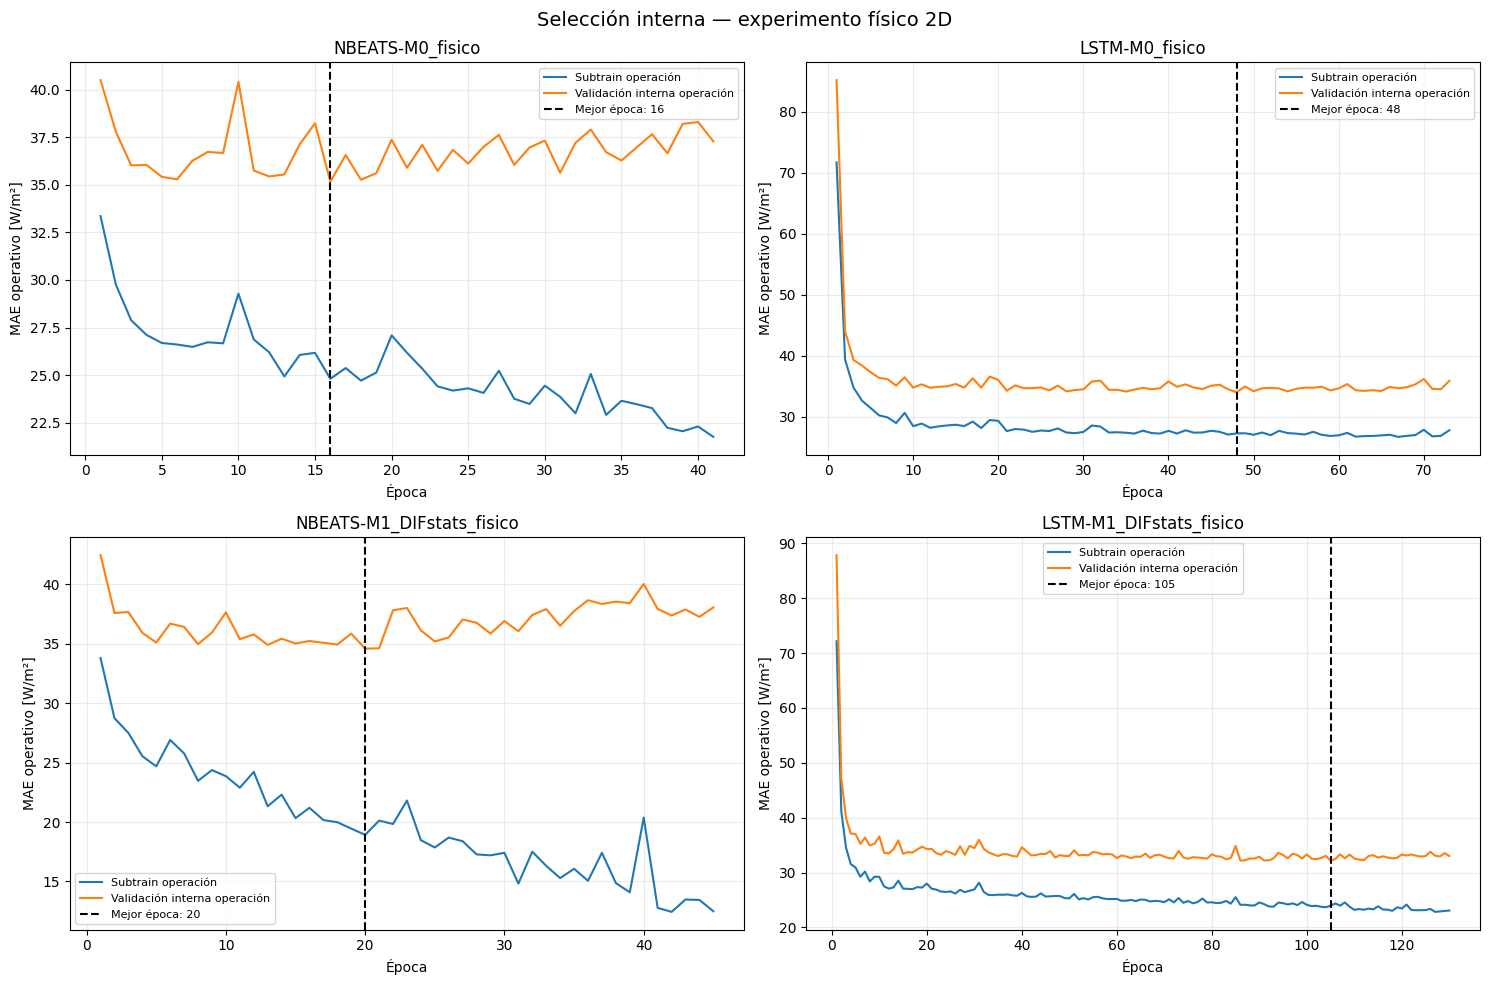


FASE 2D-B COMPLETADA


,modelo,mejor_epoca,MAE_interna_operacion,epocas_ejecutadas,tiempo_minutos
0,LSTM-M1_DIFstats_fisico,105,32.165562,130,2.912205
1,LSTM-M0_fisico,48,34.043453,73,1.627962
2,NBEATS-M1_DIFstats_fisico,20,34.596527,45,0.650102
3,NBEATS-M0_fisico,16,35.173462,41,0.720708



Validation externa utilizada: NO

Siguiente paso:
Fase 2D-C — reentrenamiento físico con todo train y evaluación en validation.


In [ ]:
from pathlib import Path
from IPython.display import display
import copy
import json
import random
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler

# 1. Comprobar que las arquitecturas están disponibles
objetos_necesarios = ["NBEATSMultivariante", "LSTMMultivariante"]
faltantes = [nombre for nombre in objetos_necesarios if nombre not in globals()]
if faltantes:
    raise RuntimeError(
        "Faltan las arquitecturas históricas: " f"{faltantes}. Ejecuta primero la fase 2B."
    )

# 2. Configuración
SEED = 42
N_SUBTRAIN = 4428
BATCH_SIZE = 128
MAX_EPOCHS = 300
PATIENCE = 25
MIN_DELTA = 1e-5
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-5
DEVICE = torch.device("cpu")
BASE_DIR = Path("/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado")
PUNTERO_OPERACIONAL = BASE_DIR / "resultados" / "ejecuciones" / "ULTIMA_INGENIERIA_OPERACIONAL.json"
with open(PUNTERO_OPERACIONAL, "r", encoding="utf-8") as archivo:
    puntero = json.load(archivo)

RUN_DIR = Path(puntero["run_dir"])
RUTA_MATRICES = Path(puntero["matrices_M0_M1_fisicas"])
SELECCION_FISICA_DIR = RUN_DIR / "02_seleccion_epocas" / "M0_M1_fisico"
FIGURAS_DIR = RUN_DIR / "06_figuras"
SELECCION_FISICA_DIR.mkdir(parents=True, exist_ok=True)

# 3. Reproducibilidad
def fijar_semilla_fisica(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.use_deterministic_algorithms(True, warn_only=True)


# 4. Cargar matrices físicas
with np.load(RUTA_MATRICES, allow_pickle=False) as datos:
    X_train_M0_fisico = datos["X_train_M0_fisico"].copy()
    X_train_M1_fisico = datos["X_train_M1_fisico"].copy()
    y_train_fisico = datos["y_train_fisico"].astype(np.float32).reshape(-1)
    fechas_train = pd.DatetimeIndex(pd.to_datetime(datos["fechas_train"]))
    noche_objetivo_train = datos["noche_objetivo_train"].astype(bool)

assert X_train_M0_fisico.shape == (5149, 24, 2)
assert X_train_M1_fisico.shape == (5149, 24, 4)
assert y_train_fisico.shape == (5149,)
assert noche_objetivo_train.shape == (5149,)
assert np.all(y_train_fisico[noche_objetivo_train] == 0)

# 5. Regímenes de train
mascara_train = pd.read_csv(RUN_DIR / "01_datos" / "mascara_train_alineada_M0_M1.csv")

def convertir_bool(serie):
    if pd.api.types.is_bool_dtype(serie):
        return serie.to_numpy(dtype=bool)

    resultado = (
        serie.astype(str)
        .str.strip()
        .str.lower()
        .map({"true": True, "false": False, "1": True, "0": False})
    )
    if resultado.isna().any():
        raise ValueError(f"No se pudo interpretar {serie.name}.")

    return resultado.to_numpy(dtype=bool)

es_operacion = convertir_bool(mascara_train["es_operacion"])
es_diurno = convertir_bool(mascara_train["es_completamente_diurno"])
es_transicion = convertir_bool(mascara_train["es_transicion"])
es_noche = convertir_bool(mascara_train["es_noche_completa"])
assert np.array_equal(es_noche, noche_objetivo_train)

# 6. División cronológica
y_sub_raw = y_train_fisico[:N_SUBTRAIN]
y_int_raw = y_train_fisico[N_SUBTRAIN:]
regimenes_sub = {
    "total_fisico": np.ones(N_SUBTRAIN, dtype=bool),
    "operacion": es_operacion[:N_SUBTRAIN],
    "completamente_diurno": (es_diurno[:N_SUBTRAIN]),
    "transicion": es_transicion[:N_SUBTRAIN],
    "noche": es_noche[:N_SUBTRAIN],
}
regimenes_int = {
    "total_fisico": np.ones(len(y_int_raw), dtype=bool),
    "operacion": es_operacion[N_SUBTRAIN:],
    "completamente_diurno": (es_diurno[N_SUBTRAIN:]),
    "transicion": es_transicion[N_SUBTRAIN:],
    "noche": es_noche[N_SUBTRAIN:],
}
resumen_division = pd.DataFrame(
    [
        {
            "conjunto": "subtrain",
            "n_total": N_SUBTRAIN,
            "n_operacion": int(regimenes_sub["operacion"].sum()),
            "n_diurno": int(regimenes_sub["completamente_diurno"].sum()),
            "n_transicion": int(regimenes_sub["transicion"].sum()),
            "n_noche": int(regimenes_sub["noche"].sum()),
        },
        {
            "conjunto": "validacion_interna",
            "n_total": len(y_int_raw),
            "n_operacion": int(regimenes_int["operacion"].sum()),
            "n_diurno": int(regimenes_int["completamente_diurno"].sum()),
            "n_transicion": int(regimenes_int["transicion"].sum()),
            "n_noche": int(regimenes_int["noche"].sum()),
        },
    ]
)
print("=== DIVISIÓN INTERNA ===")
display(resumen_division)

# 7. Funciones auxiliares
def predecir_original(modelo, X_scaled, scaler_y):
    modelo.eval()
    loader = DataLoader(
        TensorDataset(torch.from_numpy(X_scaled)),
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0,
    )
    predicciones = []
    with torch.no_grad():
        for (xb,) in loader:
            pred = modelo(xb.to(DEVICE)).cpu().numpy()
            predicciones.append(pred)

    pred_scaled = np.concatenate(predicciones).reshape(-1, 1)
    return scaler_y.inverse_transform(pred_scaled).reshape(-1)

def calcular_metricas(y_real, y_pred, mascara, ambito):
    real = np.asarray(y_real)[mascara]
    pred = np.asarray(y_pred)[mascara]
    errores = real - pred
    mae = float(np.mean(np.abs(errores)))
    rmse = float(np.sqrt(np.mean(errores**2)))
    dif_media = float(np.mean(real))
    dif_mediana = float(np.median(real))
    nmae = float(100 * mae / dif_media) if ambito != "noche" and dif_media > 1.0 else np.nan
    return {
        "ambito": ambito,
        "n": len(real),
        "DIF_media": dif_media,
        "DIF_mediana": dif_mediana,
        "MAE": mae,
        "nMAE_pct": nmae,
        "RMSE": rmse,
        "sesgo": float(np.mean(pred - real)),
    }

def contar_parametros_fisico(modelo):
    return sum(parametro.numel() for parametro in modelo.parameters() if parametro.requires_grad)


# 8. Selección de una configuración
def seleccionar_fisico(codigo, X_train, canales):
    X_sub_raw = np.asarray(X_train[:N_SUBTRAIN], dtype=np.float32)
    X_int_raw = np.asarray(X_train[N_SUBTRAIN:], dtype=np.float32)
    n_features = X_train.shape[2]

    # En esta prueba todas las muestras participan
    scaler_X = StandardScaler()
    scaler_y = StandardScaler()
    scaler_X.fit(X_sub_raw.reshape(-1, n_features))
    scaler_y.fit(y_sub_raw.reshape(-1, 1))

    def transformar_X(X):
        forma = X.shape
        return scaler_X.transform(X.reshape(-1, n_features)).reshape(forma).astype(np.float32)

    X_sub = transformar_X(X_sub_raw)
    X_int = transformar_X(X_int_raw)
    y_sub = scaler_y.transform(y_sub_raw.reshape(-1, 1)).reshape(-1).astype(np.float32)
    carpeta = SELECCION_FISICA_DIR / codigo
    carpeta.mkdir(parents=True, exist_ok=True)
    joblib.dump(scaler_X, carpeta / "scaler_X_subtrain.joblib")
    joblib.dump(scaler_y, carpeta / "scaler_y_subtrain.joblib")
    arquitecturas = {
        "NBEATS": lambda: (
            NBEATSMultivariante(
                n_features=n_features,
                window=24,
                horizon=1,
                n_stacks=2,
                blocks_per_stack=3,
                hidden_size=128,
                n_dense_layers=3,
            )
        ),
        "LSTM": lambda: (LSTMMultivariante(n_features=n_features, hidden_size=64, num_layers=1)),
    }
    resultados = []
    for arquitectura, fabrica in arquitecturas.items():
        fijar_semilla_fisica()
        modelo = fabrica().to(DEVICE)
        nombre = f"{arquitectura}-{codigo}"
        dataset = TensorDataset(torch.from_numpy(X_sub), torch.from_numpy(y_sub))
        generador = torch.Generator()
        generador.manual_seed(SEED)
        loader = DataLoader(
            dataset, batch_size=BATCH_SIZE, shuffle=True, generator=generador, num_workers=0
        )
        optimizador = torch.optim.Adam(
            modelo.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
        )
        criterio = nn.L1Loss()
        mejor_mae = np.inf
        mejor_epoca = None
        mejor_estado = None
        sin_mejora = 0
        historial = []
        inicio = time.perf_counter()
        print("\n" + "=" * 72)
        print("SELECCIÓN:", nombre)
        print("=" * 72)
        for epoca in range(1, MAX_EPOCHS + 1):
            modelo.train()
            suma_loss = 0.0
            n_muestras = 0
            for xb, yb in loader:
                xb = xb.to(DEVICE)
                yb = yb.to(DEVICE)
                optimizador.zero_grad(set_to_none=True)
                pred = modelo(xb)
                loss = criterio(pred, yb)
                loss.backward()
                torch.nn.utils.clip_grad_norm_(modelo.parameters(), 1.0)
                optimizador.step()
                suma_loss += loss.item() * len(xb)
                n_muestras += len(xb)

            loss_epoca = suma_loss / n_muestras
            pred_sub_raw = predecir_original(modelo, X_sub, scaler_y)
            pred_int_raw = predecir_original(modelo, X_int, scaler_y)

            # La máscara se aplica únicamente después
            # de que el modelo haya generado su salida.
            pred_sub_final = pred_sub_raw.copy()
            pred_int_final = pred_int_raw.copy()
            pred_sub_final[regimenes_sub["noche"]] = 0.0
            pred_int_final[regimenes_int["noche"]] = 0.0
            mae_sub_operacion = float(
                np.mean(
                    np.abs(
                        y_sub_raw[regimenes_sub["operacion"]]
                        - pred_sub_final[regimenes_sub["operacion"]]
                    )
                )
            )
            mae_int_operacion = float(
                np.mean(
                    np.abs(
                        y_int_raw[regimenes_int["operacion"]]
                        - pred_int_final[regimenes_int["operacion"]]
                    )
                )
            )
            mae_int_noche_sin_mascara = float(
                np.mean(
                    np.abs(y_int_raw[regimenes_int["noche"]] - pred_int_raw[regimenes_int["noche"]])
                )
            )
            historial.append(
                {
                    "epoca": epoca,
                    "loss_train_fisica": (loss_epoca),
                    "MAE_subtrain_operacion": (mae_sub_operacion),
                    "MAE_interna_operacion": (mae_int_operacion),
                    "MAE_interna_noche_sin_mascara": (mae_int_noche_sin_mascara),
                }
            )
            if mae_int_operacion < mejor_mae - MIN_DELTA:
                mejor_mae = mae_int_operacion
                mejor_epoca = epoca
                mejor_estado = copy.deepcopy(modelo.state_dict())
                sin_mejora = 0
                indicador = " <-- nuevo mínimo"
            else:
                sin_mejora += 1
                indicador = ""

            if epoca == 1 or epoca % 5 == 0 or indicador:
                print(
                    f"Época {epoca:03d} | "
                    f"MAE sub op: "
                    f"{mae_sub_operacion:.6f} | "
                    f"MAE int op: "
                    f"{mae_int_operacion:.6f} | "
                    f"MAE noche crudo: "
                    f"{mae_int_noche_sin_mascara:.6f}"
                    f"{indicador}"
                )

            if sin_mejora >= PATIENCE:
                print(f"\nEarly stopping: {PATIENCE} " "épocas sin mejora.")
                break

        tiempo = time.perf_counter() - inicio
        modelo.load_state_dict(mejor_estado)
        pred_sub_raw = predecir_original(modelo, X_sub, scaler_y)
        pred_int_raw = predecir_original(modelo, X_int, scaler_y)
        pred_sub_final = pred_sub_raw.copy()
        pred_int_final = pred_int_raw.copy()
        pred_sub_final[regimenes_sub["noche"]] = 0.0
        pred_int_final[regimenes_int["noche"]] = 0.0
        metricas = []
        for conjunto, reales, predichos, regimenes in [
            ("subtrain", y_sub_raw, pred_sub_final, regimenes_sub),
            ("validacion_interna", y_int_raw, pred_int_final, regimenes_int),
        ]:
            for ambito, mascara in regimenes.items():
                fila = calcular_metricas(reales, predichos, mascara, ambito)
                fila.update(
                    {"modelo": nombre, "conjunto": conjunto, "epoca_seleccionada": (mejor_epoca)}
                )
                metricas.append(fila)

        historial = pd.DataFrame(historial)
        metricas = pd.DataFrame(metricas)
        historial.to_csv(carpeta / f"historial_{arquitectura.lower()}.csv", index=False)
        metricas.to_csv(carpeta / f"metricas_{arquitectura.lower()}.csv", index=False)
        torch.save(
            {
                "model_state_dict": mejor_estado,
                "modelo": nombre,
                "arquitectura": arquitectura,
                "configuracion": codigo,
                "canales": canales,
                "mejor_epoca": mejor_epoca,
                "mejor_MAE_interna_operacion": (mejor_mae),
                "seed": SEED,
                "tiempo_segundos": tiempo,
                "n_parametros": (contar_parametros_fisico(modelo)),
                "correccion_fisica": True,
            },
            carpeta / f"mejor_checkpoint_{arquitectura.lower()}.pt",
        )
        resultados.append(
            {
                "modelo": nombre,
                "arquitectura": arquitectura,
                "configuracion": codigo,
                "mejor_epoca": mejor_epoca,
                "MAE_interna_operacion": (mejor_mae),
                "epocas_ejecutadas": (len(historial)),
                "tiempo_minutos": tiempo / 60,
                "n_parametros": (contar_parametros_fisico(modelo)),
                "historial": historial,
                "metricas": metricas,
            }
        )

    return resultados


# 9. Ejecutar M0 y M1 físicos
resultados_M0 = seleccionar_fisico(
    "M0_fisico", X_train_M0_fisico, ["DIF_media_fisica", "elevacion"]
)
resultados_M1 = seleccionar_fisico(
    "M1_DIFstats_fisico",
    X_train_M1_fisico,
    ["DIF_media_fisica", "elevacion", "DIF_std_fisica", "DIF_rango_fisico"],
)
resultados = resultados_M0 + resultados_M1

# 10. Resultados
tabla_seleccion_fisica = (
    pd.DataFrame(
        [
            {
                clave: valor
                for clave, valor in resultado.items()
                if clave not in {"historial", "metricas"}
            }
            for resultado in resultados
        ]
    )
    .sort_values("MAE_interna_operacion")
    .reset_index(drop=True)
)
metricas_fisicas = pd.concat([resultado["metricas"] for resultado in resultados], ignore_index=True)
print("\n=== SELECCIÓN INTERNA FÍSICA ===")
display(tabla_seleccion_fisica.round(6))
print("\n=== MEJORES CHECKPOINTS POR RÉGIMEN ===")
display(
    metricas_fisicas[
        [
            "modelo",
            "conjunto",
            "ambito",
            "n",
            "DIF_media",
            "DIF_mediana",
            "MAE",
            "nMAE_pct",
            "RMSE",
            "sesgo",
            "epoca_seleccionada",
        ]
    ]
    .sort_values(["conjunto", "ambito", "MAE"])
    .round(6)
)
tabla_seleccion_fisica.to_csv(SELECCION_FISICA_DIR / "resumen_seleccion_fisica.csv", index=False)
metricas_fisicas.to_csv(SELECCION_FISICA_DIR / "metricas_seleccion_fisica.csv", index=False)

# 11. Curvas
fig, ejes = plt.subplots(2, 2, figsize=(15, 10))
for eje, resultado in zip(ejes.ravel(), resultados):
    historial = resultado["historial"]
    eje.plot(historial["epoca"], historial["MAE_subtrain_operacion"], label="Subtrain operación")
    eje.plot(
        historial["epoca"], historial["MAE_interna_operacion"], label="Validación interna operación"
    )
    eje.axvline(
        resultado["mejor_epoca"],
        color="black",
        linestyle="--",
        label=(f"Mejor época: " f"{resultado['mejor_epoca']}"),
    )
    eje.set_title(resultado["modelo"])
    eje.set_xlabel("Época")
    eje.set_ylabel("MAE operativo [W/m²]")
    eje.grid(alpha=0.25)
    eje.legend(fontsize=8)

fig.suptitle("Selección interna — experimento físico 2D", fontsize=14)
fig.tight_layout()
plt.savefig(FIGURAS_DIR / "seleccion_interna_M0_M1_fisicos.png", dpi=180, bbox_inches="tight")
plt.show()

# 12. Actualizar puntero
puntero["estado"] = "fase_2D_B_epocas_fisicas_seleccionadas"
puntero["siguiente_fase"] = "fase_2D_C_reentrenamiento_fisico_completo"
puntero["seleccion_M0_M1_fisica"] = str(SELECCION_FISICA_DIR)
puntero["epocas_M0_M1_fisicas"] = {
    fila["modelo"]: int(fila["mejor_epoca"]) for _, fila in tabla_seleccion_fisica.iterrows()
}
with open(PUNTERO_OPERACIONAL, "w", encoding="utf-8") as archivo:
    json.dump(puntero, archivo, ensure_ascii=False, indent=2)

print("\n" + "=" * 72)
print("FASE 2D-B COMPLETADA")
print("=" * 72)
display(
    tabla_seleccion_fisica[
        ["modelo", "mejor_epoca", "MAE_interna_operacion", "epocas_ejecutadas", "tiempo_minutos"]
    ].round(6)
)
print("\nValidation externa utilizada: NO")
print("\nSiguiente paso:")
print("Fase 2D-C — reentrenamiento físico con todo train y evaluación en validation.")

**Resultados.** La LSTM-M1 alcanza el menor MAE interno de operación (32,17 W/m², época 105), seguida de la LSTM-M0 (34,04 W/m², época 48), la N-BEATS-M1 (34,60 W/m², época 20) y la N-BEATS-M0 (35,17 W/m², época 16).

### 3.6 Reentrenamiento con objetivo nocturno nulo

Los cuatro modelos se reentrenan con todo el conjunto de entrenamiento durante las épocas seleccionadas y se evalúan en validación con el objetivo nocturno igual a cero y la predicción nocturna fijada a cero.

=== ÉPOCAS SELECCIONADAS ===


,modelo,mejor_epoca,MAE_interna_operacion
1,LSTM-M0_fisico,48,34.043453
0,LSTM-M1_DIFstats_fisico,105,32.165562
3,NBEATS-M0_fisico,16,35.173462
2,NBEATS-M1_DIFstats_fisico,20,34.596527



REENTRENANDO NBEATS-M0_fisico: 16 épocas
Época 001/016 | loss: 0.288812
Época 010/016 | loss: 0.152504
Época 016/016 | loss: 0.152675

REENTRENANDO LSTM-M0_fisico: 48 épocas
Época 001/048 | loss: 0.681895
Época 010/048 | loss: 0.166705
Época 020/048 | loss: 0.158167
Época 030/048 | loss: 0.158792
Época 040/048 | loss: 0.153981
Época 048/048 | loss: 0.152727

REENTRENANDO NBEATS-M1_DIFstats_fisico: 20 épocas
Época 001/020 | loss: 0.276631
Época 010/020 | loss: 0.137357
Época 020/020 | loss: 0.124806

REENTRENANDO LSTM-M1_DIFstats_fisico: 105 épocas
Época 001/105 | loss: 0.611102
Época 010/105 | loss: 0.153584
Época 020/105 | loss: 0.149348
Época 030/105 | loss: 0.148170
Época 040/105 | loss: 0.143771
Época 050/105 | loss: 0.143677
Época 060/105 | loss: 0.140345
Época 070/105 | loss: 0.136836
Época 080/105 | loss: 0.138559
Época 090/105 | loss: 0.136308
Época 100/105 | loss: 0.135355
Época 105/105 | loss: 0.132747

=== MÉTRICAS OFICIALES EN VALIDATION ===


,modelo,version_objetivo,ambito,n,DIF_media,DIF_mediana,MAE,nMAE_pct,RMSE,R2,sesgo
15,LSTM-M1_DIFstats_fisico,fisico_nocturno,total,1464,85.620934,30.591667,16.025757,18.717101,32.217999,0.910693,-2.881896
5,LSTM-M0_fisico,fisico_nocturno,total,1464,85.620934,30.591667,16.853697,19.684084,33.238037,0.904948,3.143189
0,NBEATS-M0_fisico,fisico_nocturno,total,1464,85.620934,30.591667,17.078016,19.946076,32.920361,0.906757,4.089033
10,NBEATS-M1_DIFstats_fisico,fisico_nocturno,total,1464,85.620934,30.591667,17.419342,20.344723,34.776550,0.895945,1.857550
16,LSTM-M1_DIFstats_fisico,fisico_nocturno,operacion,884,141.797562,127.733337,26.540398,18.717104,41.461308,0.847643,-4.772733
6,LSTM-M0_fisico,fisico_nocturno,operacion,884,141.797562,127.733337,27.911552,19.684085,42.773994,0.837843,5.205462
1,NBEATS-M0_fisico,fisico_nocturno,operacion,884,141.797562,127.733337,28.283049,19.946075,42.365173,0.840927,6.771882
11,NBEATS-M1_DIFstats_fisico,fisico_nocturno,operacion,884,141.797562,127.733337,28.848322,20.344724,44.753899,0.822483,3.076304
17,LSTM-M1_DIFstats_fisico,fisico_nocturno,completamente_diurno,765,162.723083,145.683334,30.124300,18.512616,44.523460,0.797254,-5.102948
2,NBEATS-M0_fisico,fisico_nocturno,completamente_diurno,765,162.723083,145.683334,31.757940,19.516555,45.453999,0.788691,6.957338



=== RANKING EN OPERACIÓN ===


,modelo,version_objetivo,ambito,n,DIF_media,DIF_mediana,MAE,nMAE_pct,RMSE,R2,sesgo
0,LSTM-M1_DIFstats_fisico,fisico_nocturno,operacion,884,141.797562,127.733337,26.540398,18.717104,41.461308,0.847643,-4.772733
1,LSTM-M0_fisico,fisico_nocturno,operacion,884,141.797562,127.733337,27.911552,19.684085,42.773994,0.837843,5.205462
2,NBEATS-M0_fisico,fisico_nocturno,operacion,884,141.797562,127.733337,28.283049,19.946075,42.365173,0.840927,6.771882
3,NBEATS-M1_DIFstats_fisico,fisico_nocturno,operacion,884,141.797562,127.733337,28.848322,20.344724,44.753899,0.822483,3.076304


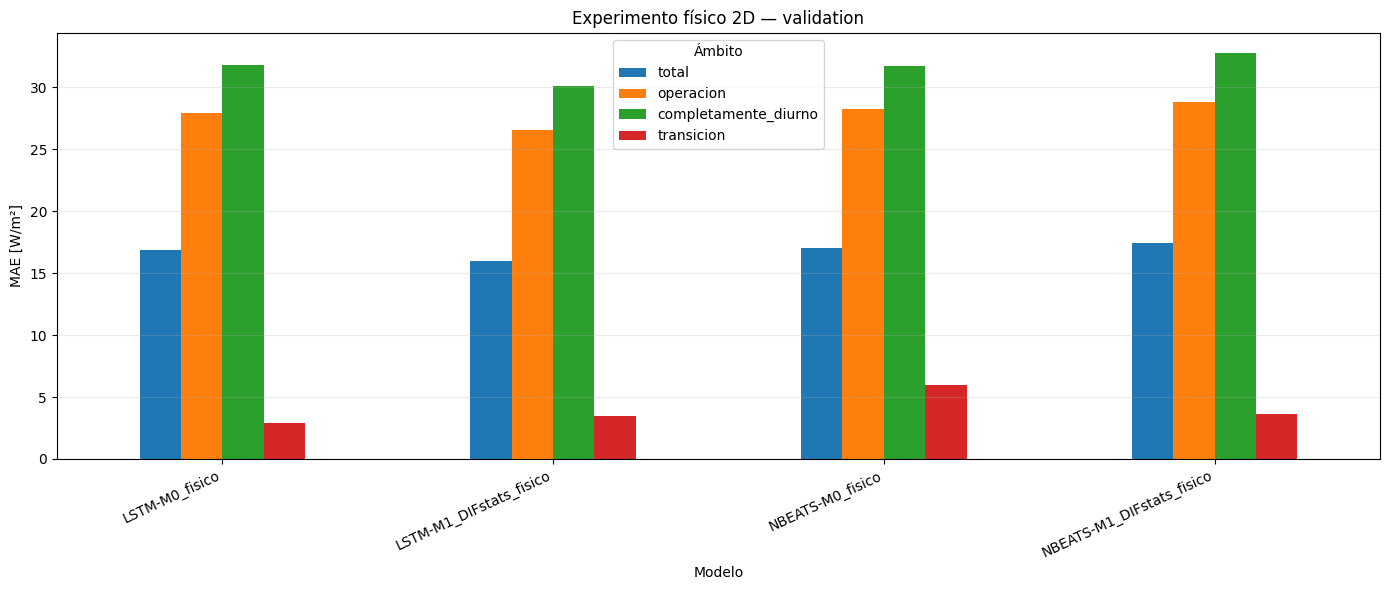


FASE 2D-C COMPLETADA


,modelo,arquitectura,configuracion,epocas,n_features,tiempo_minutos,ruta_modelo
0,NBEATS-M0_fisico,NBEATS,M0_fisico,16,2,0.2052,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...
1,LSTM-M0_fisico,LSTM,M0_fisico,48,2,0.8582,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...
2,NBEATS-M1_DIFstats_fisico,NBEATS,M1_DIFstats_fisico,20,4,0.2619,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...
3,LSTM-M1_DIFstats_fisico,LSTM,M1_DIFstats_fisico,105,4,1.9559,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...



Test utilizado: NO

Resultados guardados en:
/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/ingenieria_caracteristicas_operacional_20261007T091724Z/05_metricas/M0_M1_fisico


In [ ]:
from pathlib import Path
from IPython.display import display
import json
import random
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score

# 1. Comprobaciones
for nombre in ["NBEATSMultivariante", "LSTMMultivariante"]:
    if nombre not in globals():
        raise RuntimeError(f"No existe {nombre}. Ejecuta primero " "la fase 2B.")

# 2. Configuración
SEED = 42
BATCH_SIZE = 128
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-5
DEVICE = torch.device("cpu")
BASE_DIR = Path("/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado")
PUNTERO_OPERACIONAL = BASE_DIR / "resultados" / "ejecuciones" / "ULTIMA_INGENIERIA_OPERACIONAL.json"
with open(PUNTERO_OPERACIONAL, "r", encoding="utf-8") as archivo:
    puntero = json.load(archivo)

RUN_DIR = Path(puntero["run_dir"])
RUTA_MATRICES = Path(puntero["matrices_M0_M1_fisicas"])
SELECCION_DIR = Path(puntero["seleccion_M0_M1_fisica"])
MODELOS_DIR = RUN_DIR / "03_modelos" / "M0_M1_fisico"
PREDICCIONES_DIR = RUN_DIR / "04_predicciones" / "M0_M1_fisico"
METRICAS_DIR = RUN_DIR / "05_metricas" / "M0_M1_fisico"
FIGURAS_DIR = RUN_DIR / "06_figuras"
for ruta in [MODELOS_DIR, PREDICCIONES_DIR, METRICAS_DIR, FIGURAS_DIR]:
    ruta.mkdir(parents=True, exist_ok=True)

# 3. Reproducibilidad
def fijar_semilla_fisica(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.use_deterministic_algorithms(True, warn_only=True)


# 4. Cargar matrices físicas
with np.load(RUTA_MATRICES, allow_pickle=False) as datos:
    X_train_M0 = datos["X_train_M0_fisico"].copy()
    X_validation_M0 = datos["X_validation_M0_fisico"].copy()
    X_train_M1 = datos["X_train_M1_fisico"].copy()
    X_validation_M1 = datos["X_validation_M1_fisico"].copy()
    y_train = datos["y_train_fisico"].astype(np.float32).reshape(-1)
    y_validation = datos["y_validation_fisico"].astype(np.float32).reshape(-1)
    fechas_validation = pd.DatetimeIndex(pd.to_datetime(datos["fechas_validation"]))
    noche_validation = datos["noche_objetivo_validation"].astype(bool)

assert X_train_M0.shape == (5149, 24, 2)
assert X_validation_M0.shape == (1464, 24, 2)
assert X_train_M1.shape == (5149, 24, 4)
assert X_validation_M1.shape == (1464, 24, 4)
assert np.all(y_validation[noche_validation] == 0)

# 5. Regímenes de validation
mascara_validation = pd.read_csv(RUN_DIR / "01_datos" / "mascara_validation_alineada_M0_M1.csv")

def convertir_bool(serie):
    if pd.api.types.is_bool_dtype(serie):
        return serie.to_numpy(dtype=bool)

    resultado = (
        serie.astype(str)
        .str.strip()
        .str.lower()
        .map({"true": True, "false": False, "1": True, "0": False})
    )
    if resultado.isna().any():
        raise ValueError(f"No se pudo interpretar {serie.name}.")

    return resultado.to_numpy(dtype=bool)

mascaras = {
    "total": np.ones(len(y_validation), dtype=bool),
    "operacion": convertir_bool(mascara_validation["es_operacion"]),
    "completamente_diurno": convertir_bool(mascara_validation["es_completamente_diurno"]),
    "transicion": convertir_bool(mascara_validation["es_transicion"]),
    "noche": convertir_bool(mascara_validation["es_noche_completa"]),
}
assert np.array_equal(mascaras["noche"], noche_validation)
assert mascaras["operacion"].sum() == 884
assert mascaras["completamente_diurno"].sum() == 765
assert mascaras["transicion"].sum() == 119
assert mascaras["noche"].sum() == 580

# 6. Épocas seleccionadas
tabla_epocas = pd.read_csv(SELECCION_DIR / "resumen_seleccion_fisica.csv")
print("=== ÉPOCAS SELECCIONADAS ===")
display(tabla_epocas[["modelo", "mejor_epoca", "MAE_interna_operacion"]].sort_values("modelo"))

# 7. Métricas oficiales
COLUMNAS_OFICIALES = [
    "modelo",
    "version_objetivo",
    "ambito",
    "n",
    "DIF_media",
    "DIF_mediana",
    "MAE",
    "nMAE_pct",
    "RMSE",
    "R2",
    "sesgo",
]
ORDEN_AMBITOS = ["total", "operacion", "completamente_diurno", "transicion", "noche"]

def calcular_metricas_oficiales(modelo, y_real, y_pred, mascara, ambito):
    real = np.asarray(y_real)[mascara]
    pred = np.asarray(y_pred)[mascara]
    errores = real - pred
    mae = float(np.mean(np.abs(errores)))
    rmse = float(np.sqrt(np.mean(errores**2)))
    dif_media = float(np.mean(real))
    dif_mediana = float(np.median(real))
    if len(real) > 1 and np.var(real) > 0:
        r2 = float(r2_score(real, pred))
    else:
        r2 = np.nan

    nmae = float(100 * mae / dif_media) if ambito != "noche" and dif_media > 1.0 else np.nan
    return {
        "modelo": modelo,
        "version_objetivo": ("fisico_nocturno"),
        "ambito": ambito,
        "n": len(real),
        "DIF_media": dif_media,
        "DIF_mediana": dif_mediana,
        "MAE": mae,
        "nMAE_pct": nmae,
        "RMSE": rmse,
        "R2": r2,
        "sesgo": float(np.mean(pred - real)),
    }


# 8. Configuraciones
CONFIGURACIONES = {
    "M0_fisico": {
        "X_train": X_train_M0,
        "X_validation": X_validation_M0,
        "canales": ["DIF_media_fisica", "elevacion"],
    },
    "M1_DIFstats_fisico": {
        "X_train": X_train_M1,
        "X_validation": X_validation_M1,
        "canales": ["DIF_media_fisica", "elevacion", "DIF_std_fisica", "DIF_rango_fisico"],
    },
}
ARQUITECTURAS = ["NBEATS", "LSTM"]

# 9. Reentrenar
filas_metricas = []
filas_resumen = []
predicciones_consolidadas = []
diagnosticos_nocturnos = []
for codigo, configuracion in CONFIGURACIONES.items():
    X_train_raw = np.asarray(configuracion["X_train"], dtype=np.float32)
    X_validation_raw = np.asarray(configuracion["X_validation"], dtype=np.float32)
    canales = configuracion["canales"]
    n_features = X_train_raw.shape[2]

    # Todas las muestras participan
    scaler_X = StandardScaler()
    scaler_y = StandardScaler()
    scaler_X.fit(X_train_raw.reshape(-1, n_features))
    scaler_y.fit(y_train.reshape(-1, 1))

    def transformar_X(X):
        forma = X.shape
        return scaler_X.transform(X.reshape(-1, n_features)).reshape(forma).astype(np.float32)

    X_train_scaled = transformar_X(X_train_raw)
    X_validation_scaled = transformar_X(X_validation_raw)
    y_train_scaled = scaler_y.transform(y_train.reshape(-1, 1)).reshape(-1).astype(np.float32)
    for arquitectura in ARQUITECTURAS:
        nombre_modelo = f"{arquitectura}-{codigo}"
        fila_epoca = tabla_epocas.loc[tabla_epocas["modelo"] == nombre_modelo]
        if len(fila_epoca) != 1:
            raise ValueError(f"No se encontró la época de " f"{nombre_modelo}.")

        n_epocas = int(fila_epoca["mejor_epoca"].iloc[0])
        fijar_semilla_fisica()
        if arquitectura == "NBEATS":
            modelo = NBEATSMultivariante(
                n_features=n_features,
                window=24,
                horizon=1,
                n_stacks=2,
                blocks_per_stack=3,
                hidden_size=128,
                n_dense_layers=3,
            )
        else:
            modelo = LSTMMultivariante(n_features=n_features, hidden_size=64, num_layers=1)

        modelo = modelo.to(DEVICE)
        dataset = TensorDataset(torch.from_numpy(X_train_scaled), torch.from_numpy(y_train_scaled))
        generador = torch.Generator()
        generador.manual_seed(SEED)
        loader = DataLoader(
            dataset, batch_size=BATCH_SIZE, shuffle=True, generator=generador, num_workers=0
        )
        optimizador = torch.optim.Adam(
            modelo.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
        )
        criterio = nn.L1Loss()
        historial = []
        inicio = time.perf_counter()
        print("\n" + "=" * 72)
        print(f"REENTRENANDO {nombre_modelo}: " f"{n_epocas} épocas")
        print("=" * 72)
        for epoca in range(1, n_epocas + 1):
            modelo.train()
            suma_loss = 0.0
            n_muestras = 0
            for xb, yb in loader:
                xb = xb.to(DEVICE)
                yb = yb.to(DEVICE)
                optimizador.zero_grad(set_to_none=True)
                pred = modelo(xb)
                loss = criterio(pred, yb)
                loss.backward()
                torch.nn.utils.clip_grad_norm_(modelo.parameters(), 1.0)
                optimizador.step()
                suma_loss += loss.item() * len(xb)
                n_muestras += len(xb)

            loss_epoca = suma_loss / n_muestras
            historial.append({"epoca": epoca, "loss_train": loss_epoca})
            if epoca == 1 or epoca % 10 == 0 or epoca == n_epocas:
                print(f"Época {epoca:03d}/" f"{n_epocas:03d} | " f"loss: {loss_epoca:.6f}")

        tiempo_segundos = time.perf_counter() - inicio

        # Predicción validation
        modelo.eval()
        loader_validation = DataLoader(
            TensorDataset(torch.from_numpy(X_validation_scaled)),
            batch_size=BATCH_SIZE,
            shuffle=False,
            num_workers=0,
        )
        pred_scaled = []
        with torch.no_grad():
            for (xb,) in loader_validation:
                pred = modelo(xb.to(DEVICE)).cpu().numpy()
                pred_scaled.append(pred)

        pred_scaled = np.concatenate(pred_scaled).reshape(-1, 1)
        pred_sin_mascara = scaler_y.inverse_transform(pred_scaled).reshape(-1)

        # Diagnóstico guardado, no mostrado
        mae_nocturno_crudo = float(np.mean(np.abs(pred_sin_mascara[noche_validation])))

        # Regla física final
        pred_final = pred_sin_mascara.copy()
        pred_final[noche_validation] = 0.0
        assert np.all(pred_final[noche_validation] == 0)

        # Métricas oficiales
        for ambito in ORDEN_AMBITOS:
            fila = calcular_metricas_oficiales(
                nombre_modelo, y_validation, pred_final, mascaras[ambito], ambito
            )
            fila.update(
                {
                    "arquitectura": arquitectura,
                    "configuracion": codigo,
                    "epocas": n_epocas,
                    "seed": SEED,
                    "n_features": n_features,
                    "tiempo_minutos": (tiempo_segundos / 60),
                }
            )
            filas_metricas.append(fila)

        diagnosticos_nocturnos.append(
            {
                "modelo": nombre_modelo,
                "MAE_nocturno_sin_mascara": (mae_nocturno_crudo),
                "MAE_nocturno_final": 0.0,
            }
        )

        # Predicciones
        df_pred = pd.DataFrame(
            {
                "instante_objetivo": (fechas_validation),
                "y_real_fisico": y_validation,
                "prediccion_sin_mascara": (pred_sin_mascara),
                "prediccion_final": (pred_final),
                "error": (pred_final - y_validation),
                "error_absoluto": np.abs(pred_final - y_validation),
                "regimen_solar": (mascara_validation["regimen_pvlib"].to_numpy()),
                "modelo": nombre_modelo,
            }
        )
        df_pred.to_csv(PREDICCIONES_DIR / f"predicciones_{nombre_modelo}.csv", index=False)
        predicciones_consolidadas.append(df_pred)

        # Guardar modelo
        carpeta_modelo = MODELOS_DIR / nombre_modelo
        carpeta_modelo.mkdir(parents=True, exist_ok=True)
        joblib.dump(scaler_X, carpeta_modelo / "scaler_X_train.joblib")
        joblib.dump(scaler_y, carpeta_modelo / "scaler_y_train.joblib")
        torch.save(
            {
                "model_state_dict": (modelo.state_dict()),
                "modelo": nombre_modelo,
                "arquitectura": arquitectura,
                "configuracion": codigo,
                "canales": canales,
                "n_features": n_features,
                "lookback": 24,
                "horizon": 1,
                "epocas": n_epocas,
                "seed": SEED,
                "correccion_fisica": True,
                "mascara_nocturna_final": True,
                "tiempo_segundos": (tiempo_segundos),
            },
            carpeta_modelo / "modelo_final.pt",
        )
        pd.DataFrame(historial).to_csv(carpeta_modelo / "historial_train.csv", index=False)
        filas_resumen.append(
            {
                "modelo": nombre_modelo,
                "arquitectura": arquitectura,
                "configuracion": codigo,
                "epocas": n_epocas,
                "n_features": n_features,
                "tiempo_minutos": (tiempo_segundos / 60),
                "ruta_modelo": str(carpeta_modelo / "modelo_final.pt"),
            }
        )

# 10. Consolidar
metricas_fisicas = pd.DataFrame(filas_metricas)
resumen_modelos = pd.DataFrame(filas_resumen)
diagnostico_nocturno = pd.DataFrame(diagnosticos_nocturnos)
predicciones_fisicas = pd.concat(predicciones_consolidadas, ignore_index=True)
metricas_fisicas["ambito"] = pd.Categorical(
    metricas_fisicas["ambito"], categories=ORDEN_AMBITOS, ordered=True
)
metricas_fisicas.to_csv(METRICAS_DIR / "metricas_validation_M0_M1_fisicos.csv", index=False)
resumen_modelos.to_csv(METRICAS_DIR / "resumen_modelos_M0_M1_fisicos.csv", index=False)
diagnostico_nocturno.to_csv(METRICAS_DIR / "diagnostico_nocturno_crudo.csv", index=False)
predicciones_fisicas.to_csv(
    PREDICCIONES_DIR / "predicciones_consolidadas_M0_M1_fisicos.csv", index=False
)

# 11. Tabla oficial
print("\n=== MÉTRICAS OFICIALES EN VALIDATION ===")
display(metricas_fisicas[COLUMNAS_OFICIALES].sort_values(["ambito", "MAE"]).round(6))
print("\n=== RANKING EN OPERACIÓN ===")
display(
    metricas_fisicas.loc[metricas_fisicas["ambito"] == "operacion", COLUMNAS_OFICIALES]
    .sort_values("MAE")
    .reset_index(drop=True)
    .round(6)
)

# Comprobación nocturna
metricas_noche = metricas_fisicas.loc[metricas_fisicas["ambito"] == "noche"]
assert np.allclose(metricas_noche["MAE"], 0.0)
assert np.allclose(metricas_noche["RMSE"], 0.0)

# 12. Figura
ambitos_figura = ["total", "operacion", "completamente_diurno", "transicion"]
tabla_figura = (
    metricas_fisicas.loc[metricas_fisicas["ambito"].isin(ambitos_figura)]
    .pivot(index="modelo", columns="ambito", values="MAE")
    .reindex(columns=ambitos_figura)
)
ax = tabla_figura.plot(kind="bar", figsize=(14, 6))
ax.set_title("Experimento físico 2D — validation")
ax.set_xlabel("Modelo")
ax.set_ylabel("MAE [W/m²]")
ax.grid(axis="y", alpha=0.25)
ax.legend(title="Ámbito")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.savefig(FIGURAS_DIR / "comparacion_validation_M0_M1_fisicos.png", dpi=180, bbox_inches="tight")
plt.show()

# 13. Actualizar puntero
puntero["estado"] = "fase_2D_C_reentrenamiento_fisico_completado"
puntero["siguiente_fase"] = "comparar_experimento_fisico_con_protocolos_anteriores"
puntero["modelos_M0_M1_fisicos"] = str(MODELOS_DIR)
puntero["metricas_M0_M1_fisicos"] = str(METRICAS_DIR / "metricas_validation_M0_M1_fisicos.csv")
puntero["predicciones_M0_M1_fisicas"] = str(
    PREDICCIONES_DIR / "predicciones_consolidadas_M0_M1_fisicos.csv"
)
with open(PUNTERO_OPERACIONAL, "w", encoding="utf-8") as archivo:
    json.dump(puntero, archivo, ensure_ascii=False, indent=2)

print("\n" + "=" * 72)
print("FASE 2D-C COMPLETADA")
print("=" * 72)
display(resumen_modelos.round(4))
print("\nTest utilizado: NO")
print("\nResultados guardados en:")
print(METRICAS_DIR)

**Resultados.** Por construcción, el MAE nocturno es nulo.

- La LSTM-M1 obtiene el menor MAE total (16,03 W/m²), en operación (26,54 W/m²) y en horas completamente diurnas (30,12 W/m²), con sesgo negativo en operación (−4,77 W/m²).
- En transición, el menor MAE corresponde a la LSTM-M0 (2,92 W/m²) y el mayor, a la N-BEATS-M0 (5,94 W/m²).
- Frente al entrenamiento con peso nocturno nulo, el MAE de operación aumenta en la LSTM-M1 y la N-BEATS-M0 y disminuye en la LSTM-M0 y la N-BEATS-M1; el de transición disminuye en todos los modelos salvo en la LSTM-M1.

## 4. Combinaciones de los estadísticos de la DIF con otros bloques

> *Se utiliza en la memoria: apartado 5.3.1 e hipótesis H4 (variantes con más variables de radiación y meteorológicas que la LSTM-DIFstats).*

### 4.1 DIFstats con SWD

En esta parte se combinan con otros bloques de variables los estadísticos históricos de la DIF (DIFstats: DIF, elevación, desviación intraminutal y rango horario de la DIF) que utilizan la LSTM-DIFstats y la N-BEATS-DIFstats (M1), con el protocolo original: valores nocturnos observados y sin máscara. En primer lugar se construye M2 (DIFstats + SWD), que añade la media, la desviación intraminutal y el rango horarios de la irradiancia global descendente (SWD), hasta siete canales en ventanas de 24 horas.

> *La ejecución de esta celda se interrumpió al guardar las fechas, con el error que se muestra al final de su salida. Se conserva porque las celdas siguientes usan las matrices de M2 que construyó; la celda siguiente corrige el formato de las fechas y vuelve a guardarlas.*

In [ ]:
from google.colab import drive

drive.mount("/content/drive", force_remount=False)
import os
import re
import json
import glob
import unicodedata
from pathlib import Path
import numpy as np
import pandas as pd

# 1. Rutas generales
BASE_DIR = Path("/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado")
PUNTERO_EXP = BASE_DIR / "resultados/ejecuciones/ULTIMA_INGENIERIA_OPERACIONAL.json"
PUNTERO_CHECKPOINT = BASE_DIR / "documentacion/ULTIMO_CHECKPOINT_MODELADO.json"
PARQUET_CANDIDATOS = [
    Path("/content/drive/MyDrive/TFM Aghmir/TFM/radiation_data_completo.parquet"),
    BASE_DIR / "radiation_data_completo.parquet",
]
assert PUNTERO_EXP.exists(), f"No existe el puntero del experimento:\n{PUNTERO_EXP}"
with open(PUNTERO_EXP, "r", encoding="utf-8") as f:
    puntero = json.load(f)

def buscar_run_dir(diccionario):
    candidatos = [
        diccionario.get("run_dir"),
        diccionario.get("RUN_DIR"),
        diccionario.get("directorio_ejecucion"),
        diccionario.get("ruta_ejecucion"),
    ]
    for ruta in candidatos:
        if ruta and Path(ruta).exists():
            return Path(ruta)

    # El propio puntero puede contener alguna ruta situada dentro del run.
    for valor in diccionario.values():
        if isinstance(valor, str):
            p = Path(valor)
            if p.exists():
                partes = list(p.parents)
                for padre in partes:
                    if padre.name.startswith("ingenieria_caracteristicas_operacional_"):
                        return padre

    raise FileNotFoundError("No se ha podido reconstruir RUN_DIR desde el puntero.")

RUN_DIR = buscar_run_dir(puntero)
DIR_DATOS = RUN_DIR / "01_datos"
DIR_DATOS.mkdir(parents=True, exist_ok=True)
print("BASE_DIR:", BASE_DIR)
print("RUN_DIR:", RUN_DIR)


# 2. Localizar las matrices originales M0/M1
npz_preferido = DIR_DATOS / "matrices_operacionales_M0_M1.npz"
candidatos_npz = []
if npz_preferido.exists():
    candidatos_npz.append(npz_preferido)

# Rutas registradas en el puntero
for valor in puntero.values():
    if isinstance(valor, str):
        p = Path(valor)
        if (
            p.exists()
            and p.suffix.lower() == ".npz"
            and "fisic" not in p.name.lower()
            and "noche" not in p.name.lower()
        ):
            candidatos_npz.append(p)

# Alternativas dentro del directorio de datos
for p in DIR_DATOS.glob("*.npz"):
    if "fisic" not in p.name.lower() and "noche" not in p.name.lower():
        candidatos_npz.append(p)

candidatos_npz = list(dict.fromkeys(candidatos_npz))

def contiene_m1_original(ruta):
    try:
        with np.load(ruta, allow_pickle=True) as z:
            arrays_3d = [np.asarray(z[k]) for k in z.files if np.asarray(z[k]).ndim == 3]
            tiene_train = any(a.shape == (5149, 24, 4) for a in arrays_3d)
            tiene_validation = any(a.shape == (1464, 24, 4) for a in arrays_3d)
            return tiene_train and tiene_validation

    except Exception:
        return False

RUTA_M1 = None
for candidato in candidatos_npz:
    if contiene_m1_original(candidato):
        RUTA_M1 = candidato
        break

if RUTA_M1 is None:
    raise FileNotFoundError(
        "No se ha localizado el NPZ original con las matrices "
        "M1 de formas (5149,24,4) y (1464,24,4)."
    )

print("\nMatrices M1 originales:")
print(RUTA_M1)


# 3. Cargar M1 e identificar los arrays por forma
with np.load(RUTA_M1, allow_pickle=True) as z:
    contenido_npz = {clave: np.asarray(z[clave]) for clave in z.files}

print("\nClaves encontradas en el NPZ:")
for clave, valor in contenido_npz.items():
    print(f"  {clave}: {valor.shape} — {valor.dtype}")

def array_por_forma(contenido, forma):
    encontrados = [(clave, valor) for clave, valor in contenido.items() if valor.shape == forma]
    if len(encontrados) != 1:
        raise ValueError(
            f"Se esperaba un único array con forma {forma}, "
            f"pero se encontraron: "
            f"{[(k, v.shape) for k, v in encontrados]}"
        )

    return encontrados[0]

clave_X_train_M1, X_train_M1 = array_por_forma(contenido_npz, (5149, 24, 4))
clave_X_validation_M1, X_validation_M1 = array_por_forma(contenido_npz, (1464, 24, 4))


# Identificar y_train e y_validation por tamaño.
# Se admiten formas (n,) y (n,1).
def seleccionar_objetivo(contenido, n, texto_split):
    candidatos = []
    for clave, valor in contenido.items():
        a = np.asarray(valor)
        if a.ndim in (1, 2) and a.size == n:
            nombre = clave.lower()

            # Evitar timestamps, máscaras y variables auxiliares.
            if any(
                token in nombre
                for token in [
                    "timestamp",
                    "fecha",
                    "instante",
                    "mask",
                    "mascara",
                    "regimen",
                    "elev",
                ]
            ):
                continue

            prioridad = 0 if nombre.startswith("y") else 1
            candidatos.append((prioridad, clave, a.reshape(-1)))

    if not candidatos:
        return None, None

    candidatos.sort(key=lambda x: (x[0], x[1]))
    _, clave, array = candidatos[0]
    return clave, array.astype(np.float32)

clave_y_train, y_train_npz = seleccionar_objetivo(contenido_npz, 5149, "train")
clave_y_validation, y_validation_npz = seleccionar_objetivo(contenido_npz, 1464, "validation")
print("\nArrays M1 seleccionados:")
print("Train:", clave_X_train_M1, X_train_M1.shape)
print("Validation:", clave_X_validation_M1, X_validation_M1.shape)


# 4. Recuperar train_hgb y validation_hgb
assert PUNTERO_CHECKPOINT.exists(), f"No existe el puntero del checkpoint:\n{PUNTERO_CHECKPOINT}"
with open(PUNTERO_CHECKPOINT, "r", encoding="utf-8") as f:
    checkpoint = json.load(f)

def extraer_strings(obj):
    resultado = []
    if isinstance(obj, dict):
        for valor in obj.values():
            resultado.extend(extraer_strings(valor))

    elif isinstance(obj, (list, tuple)):
        for valor in obj:
            resultado.extend(extraer_strings(valor))

    elif isinstance(obj, str):
        resultado.append(obj)

    return resultado

strings_checkpoint = extraer_strings(checkpoint)

def cargar_tabla_checkpoint(nombre_base):
    extensiones = [".parquet", ".pkl", ".pickle", ".csv"]
    candidatos = []
    for texto in strings_checkpoint:
        p = Path(texto)
        if p.is_file():
            if p.stem.lower() == nombre_base.lower() and p.suffix.lower() in extensiones:
                candidatos.append(p)

        elif p.is_dir():
            for extension in extensiones:
                q = p / f"{nombre_base}{extension}"
                if q.exists():
                    candidatos.append(q)

    # Carpetas registradas explícitamente como checkpoint
    for clave, valor in checkpoint.items():
        if isinstance(valor, str):
            p = Path(valor)
            if p.is_dir():
                for extension in extensiones:
                    q = p / f"{nombre_base}{extension}"
                    if q.exists():
                        candidatos.append(q)

    candidatos = list(dict.fromkeys(candidatos))
    if not candidatos:
        # Fallback limitado a documentación/resultados
        patrones = [
            BASE_DIR / "documentacion" / "**" / f"{nombre_base}.*",
            BASE_DIR / "resultados" / "**" / f"{nombre_base}.*",
        ]
        for patron in patrones:
            candidatos.extend(
                Path(x)
                for x in glob.glob(str(patron), recursive=True)
                if Path(x).suffix.lower() in extensiones
            )

        candidatos = list(dict.fromkeys(candidatos))

    if not candidatos:
        raise FileNotFoundError(f"No se ha encontrado {nombre_base} " "en el checkpoint.")

    candidatos.sort(key=lambda p: (p.suffix.lower() != ".parquet", -p.stat().st_mtime))
    ruta = candidatos[0]
    if ruta.suffix.lower() == ".parquet":
        df = pd.read_parquet(ruta)
    elif ruta.suffix.lower() in [".pkl", ".pickle"]:
        df = pd.read_pickle(ruta)
    else:
        df = pd.read_csv(ruta)

    return df, ruta

train_hgb, ruta_train_hgb = cargar_tabla_checkpoint("train_hgb")
validation_hgb, ruta_validation_hgb = cargar_tabla_checkpoint("validation_hgb")
print("\nTablas de referencia:")
print("Train:", ruta_train_hgb, train_hgb.shape)
print("Validation:", ruta_validation_hgb, validation_hgb.shape)
assert len(train_hgb) == 5149
assert len(validation_hgb) == 1464


# 5. Instantes objetivo y objetivos originales
COLUMNA_TIEMPO = "instante_objetivo"
COLUMNA_OBJETIVO = "DIF_objetivo_t1"
assert COLUMNA_TIEMPO in train_hgb.columns
assert COLUMNA_TIEMPO in validation_hgb.columns
assert COLUMNA_OBJETIVO in train_hgb.columns
assert COLUMNA_OBJETIVO in validation_hgb.columns

def convertir_utc_naive(serie):
    return pd.to_datetime(serie, utc=True, errors="raise").dt.tz_convert(None)

t_train = pd.DatetimeIndex(convertir_utc_naive(train_hgb[COLUMNA_TIEMPO]))
t_validation = pd.DatetimeIndex(convertir_utc_naive(validation_hgb[COLUMNA_TIEMPO]))
y_train_tabla = pd.to_numeric(train_hgb[COLUMNA_OBJETIVO], errors="raise").to_numpy(
    dtype=np.float32
)
y_validation_tabla = pd.to_numeric(validation_hgb[COLUMNA_OBJETIVO], errors="raise").to_numpy(
    dtype=np.float32
)

# Si el NPZ contenía objetivos, auditar su correspondencia.
if y_train_npz is not None:
    diferencia = np.max(np.abs(y_train_npz - y_train_tabla))
    print("\nDiferencia máxima y_train NPZ vs tabla:", diferencia)
    assert diferencia < 1e-5

if y_validation_npz is not None:
    diferencia = np.max(np.abs(y_validation_npz - y_validation_tabla))
    print("Diferencia máxima y_validation NPZ vs tabla:", diferencia)
    assert diferencia < 1e-5

y_train = y_train_tabla
y_validation = y_validation_tabla


# 6. Cargar radiation_data_completo.parquet
RUTA_PARQUET = next((p for p in PARQUET_CANDIDATOS if p.exists()), None)
if RUTA_PARQUET is None:
    raise FileNotFoundError(
        "No se encuentra radiation_data_completo.parquet en ninguna de las rutas previstas."
    )

df_original = pd.read_parquet(RUTA_PARQUET)
print("\nParquet original:")
print(RUTA_PARQUET)
print("Forma:", df_original.shape)


# 7. Detectar correctamente el tiempo del parquet
def normalizar_nombre(texto):
    texto = unicodedata.normalize("NFKD", str(texto))
    texto = "".join(c for c in texto if not unicodedata.combining(c))
    return re.sub(r"[^a-z0-9]+", "", texto.lower())

def extraer_tiempo_dataframe(df):
    if isinstance(df.index, pd.DatetimeIndex):
        tiempo = pd.to_datetime(df.index, utc=True, errors="coerce").tz_convert(None)
        if tiempo.notna().mean() > 0.99:
            return pd.DatetimeIndex(tiempo), "__index__"

    candidatos = []
    for columna in df.columns:
        nombre = normalizar_nombre(columna)
        if any(
            token in nombre
            for token in ["timestamp", "datetime", "fecha", "date", "time", "instante"]
        ):
            candidatos.append(columna)

    for columna in candidatos:
        convertido = pd.to_datetime(df[columna], utc=True, errors="coerce")
        if convertido.notna().mean() > 0.99:
            return (pd.DatetimeIndex(convertido.dt.tz_convert(None)), columna)

    raise ValueError(
        "No se ha podido detectar la columna temporal. "
        f"Columnas disponibles:\n{list(df.columns)}"
    )

tiempo_original, columna_tiempo = extraer_tiempo_dataframe(df_original)
print("Origen temporal detectado:", columna_tiempo)
print("Primera fecha:", tiempo_original.min())
print("Última fecha:", tiempo_original.max())


# 8. Identificar las cuatro columnas SWD
columnas_swd = [columna for columna in df_original.columns if "swd" in normalizar_nombre(columna)]
print("\nColumnas candidatas SWD:")
for columna in columnas_swd:
    print(" -", columna)

def seleccionar_columna_swd(tipo):
    candidatos = []
    for columna in columnas_swd:
        nombre = normalizar_nombre(columna)
        tiene_max = "max" in nombre
        tiene_min = "min" in nombre
        tiene_std = any(token in nombre for token in ["std", "sdt", "desviacion"])
        if tipo == "media":
            valido = not tiene_max and not tiene_min and not tiene_std
        elif tipo == "max":
            valido = tiene_max
        elif tipo == "min":
            valido = tiene_min
        elif tipo == "std":
            valido = tiene_std
        else:
            raise ValueError(tipo)

        if valido:
            candidatos.append(columna)

    if len(candidatos) != 1:
        raise ValueError(
            f"No se pudo identificar de forma unívoca " f"SWD {tipo}. Candidatos: {candidatos}"
        )

    return candidatos[0]

COL_SWD = seleccionar_columna_swd("media")
COL_SWD_MAX = seleccionar_columna_swd("max")
COL_SWD_MIN = seleccionar_columna_swd("min")
COL_SWD_STD = seleccionar_columna_swd("std")
print("\nColumnas SWD seleccionadas:")
print("SWD media original:", COL_SWD)
print("SWD max:", COL_SWD_MAX)
print("SWD min:", COL_SWD_MIN)
print("SWD std dev:", COL_SWD_STD)


# 9. Construir los estadísticos horarios SWD
swd_minutal = pd.DataFrame(
    {
        "instante": tiempo_original,
        "SWD": pd.to_numeric(df_original[COL_SWD], errors="coerce").to_numpy(),
        "SWD_max": pd.to_numeric(df_original[COL_SWD_MAX], errors="coerce").to_numpy(),
        "SWD_min": pd.to_numeric(df_original[COL_SWD_MIN], errors="coerce").to_numpy(),
        "SWD_std_original": pd.to_numeric(df_original[COL_SWD_STD], errors="coerce").to_numpy(),
    }
)
swd_minutal = swd_minutal.dropna(subset=["instante"]).sort_values("instante")
swd_minutal["hora"] = swd_minutal["instante"].dt.floor("h")
agrupado_swd = swd_minutal.groupby("hora", sort=True)
swd_horario = pd.DataFrame(
    {
        "SWD_media": agrupado_swd["SWD"].mean(),
        "SWD_std": agrupado_swd["SWD_std_original"].mean(),
        "SWD_max_horario": agrupado_swd["SWD_max"].max(),
        "SWD_min_horario": agrupado_swd["SWD_min"].min(),
        "n_SWD": agrupado_swd["SWD"].count(),
        "n_SWD_std": agrupado_swd["SWD_std_original"].count(),
    }
)
swd_horario["SWD_rango"] = swd_horario["SWD_max_horario"] - swd_horario["SWD_min_horario"]
swd_horario = swd_horario[["SWD_media", "SWD_std", "SWD_rango", "n_SWD", "n_SWD_std"]].sort_index()
print("\nResumen horario SWD:")
display(swd_horario[["SWD_media", "SWD_std", "SWD_rango"]].describe().T)
print("\nDisponibilidad por hora:")
display(swd_horario[["n_SWD", "n_SWD_std"]].describe().T)


# 10. Crear ventanas históricas [T-24, ..., T-1]
CANALES_SWD = ["SWD_media", "SWD_std", "SWD_rango"]

def construir_ventanas_swd(instantes_objetivo, tabla_horaria):
    instantes_objetivo = pd.DatetimeIndex(instantes_objetivo)
    offsets = pd.to_timedelta(np.arange(24, 0, -1), unit="h")
    matriz_tiempos = instantes_objetivo.to_numpy()[:, None] - offsets.to_numpy()[None, :]
    tiempos_planos = pd.DatetimeIndex(matriz_tiempos.reshape(-1))
    valores = tabla_horaria[CANALES_SWD].reindex(tiempos_planos)
    matriz = valores.to_numpy(dtype=np.float32).reshape(
        len(instantes_objetivo), 24, len(CANALES_SWD)
    )
    return matriz, matriz_tiempos

X_train_SWD, tiempos_ventana_train = construir_ventanas_swd(t_train, swd_horario)
X_validation_SWD, tiempos_ventana_validation = construir_ventanas_swd(t_validation, swd_horario)
print("\nMatrices SWD:")
print("Train:", X_train_SWD.shape)
print("Validation:", X_validation_SWD.shape)


# 11. Comprobar nulos antes de combinar
def informe_nulos(nombre, matriz, tiempos_objetivo):
    print(f"\nNulos en {nombre}:")
    total_nulos = np.isnan(matriz).sum(axis=(0, 1))
    filas_afectadas = np.isnan(matriz).any(axis=(1, 2))
    for canal, nulos in zip(CANALES_SWD, total_nulos):
        print(f"  {canal}: {int(nulos)}")

    print("  Muestras objetivo afectadas:", int(filas_afectadas.sum()))
    if filas_afectadas.any():
        ejemplos = pd.DataFrame({"instante_objetivo": tiempos_objetivo[filas_afectadas][:10]})
        display(ejemplos)

    return filas_afectadas

nulos_train = informe_nulos("X_train_SWD", X_train_SWD, t_train)
nulos_validation = informe_nulos("X_validation_SWD", X_validation_SWD, t_validation)
if nulos_train.any() or nulos_validation.any():
    raise ValueError(
        "Hay nulos en las ventanas SWD. No se guardará M2 "
        "hasta estudiar exactamente las horas afectadas."
    )


# 12. Auditoría temporal con los lags de train_hgb
def diferencia_maxima(a, b):
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)
    mascara = np.isfinite(a) & np.isfinite(b)
    if not mascara.any():
        return np.nan

    return np.max(np.abs(a[mascara] - b[mascara]))

auditoria = []
for lag in [1, 2, 3, 24]:
    columna = f"SWD_media_lag{lag}"
    if columna in train_hgb.columns:
        indice_ventana = 24 - lag
        diferencia = diferencia_maxima(
            X_train_SWD[:, indice_ventana, 0],
            pd.to_numeric(train_hgb[columna], errors="coerce").to_numpy(),
        )
        auditoria.append(
            {
                "variable": columna,
                "canal_M2": "SWD_media",
                "posicion_ventana": indice_ventana,
                "diferencia_maxima": diferencia,
            }
        )

auditoria_lags = pd.DataFrame(auditoria)
print("\nAuditoría de alineación temporal SWD:")
display(auditoria_lags)
if not auditoria_lags.empty:
    assert (auditoria_lags["diferencia_maxima"] < 1e-4).all(), (
        "La construcción SWD no coincide con los lags históricos de train_hgb."
    )


# 13. Construir M2 = M1 + SWD
X_train_M2 = np.concatenate([X_train_M1.astype(np.float32), X_train_SWD.astype(np.float32)], axis=2)
X_validation_M2 = np.concatenate(
    [X_validation_M1.astype(np.float32), X_validation_SWD.astype(np.float32)], axis=2
)
CANALES_M2 = ["DIF_media", "elevacion", "DIF_std", "DIF_rango", "SWD_media", "SWD_std", "SWD_rango"]
assert X_train_M2.shape == (5149, 24, 7)
assert X_validation_M2.shape == (1464, 24, 7)
assert not np.isnan(X_train_M2).any()
assert not np.isnan(X_validation_M2).any()
print("\nM2 construido correctamente:")
print("X_train_M2:", X_train_M2.shape)
print("X_validation_M2:", X_validation_M2.shape)
print("y_train:", y_train.shape)
print("y_validation:", y_validation.shape)
print("Canales:", CANALES_M2)


# 14. Resumen descriptivo de los canales
def resumen_canales(matriz, nombres, split):
    filas = []
    for j, nombre in enumerate(nombres):
        valores = matriz[:, :, j].reshape(-1)
        filas.append(
            {
                "split": split,
                "canal": nombre,
                "media": np.mean(valores),
                "std": np.std(valores),
                "min": np.min(valores),
                "mediana": np.median(valores),
                "max": np.max(valores),
                "n_nulos": np.isnan(valores).sum(),
            }
        )

    return pd.DataFrame(filas)

resumen_M2 = pd.concat(
    [
        resumen_canales(X_train_M2, CANALES_M2, "train"),
        resumen_canales(X_validation_M2, CANALES_M2, "validation"),
    ],
    ignore_index=True,
)
print("\nResumen de M2:")
display(resumen_M2)


# 15. Guardar matrices y auditorías
RUTA_M2 = DIR_DATOS / "matrices_M2_DIFstats_SWD_original.npz"
RUTA_RESUMEN = DIR_DATOS / "resumen_M2_DIFstats_SWD_original.csv"
RUTA_AUDITORIA = DIR_DATOS / "auditoria_lags_M2_SWD_original.csv"
RUTA_CANALES = DIR_DATOS / "canales_M2_DIFstats_SWD_original.json"
np.savez_compressed(
    RUTA_M2,
    X_train_M2=X_train_M2.astype(np.float32),
    X_validation_M2=X_validation_M2.astype(np.float32),
    y_train=y_train.astype(np.float32),
    y_validation=y_validation.astype(np.float32),
    timestamps_train=t_train.astype(str).to_numpy(),
    timestamps_validation=t_validation.astype(str).to_numpy(),
    canales_M2=np.asarray(CANALES_M2, dtype=str),
)
resumen_M2.to_csv(RUTA_RESUMEN, index=False)
auditoria_lags.to_csv(RUTA_AUDITORIA, index=False)
with open(RUTA_CANALES, "w", encoding="utf-8") as f:
    json.dump(
        {
            "modelo": "M2_DIFstats_SWD",
            "protocolo": "original_sin_mascara_nocturna",
            "n_lags": 24,
            "canales": CANALES_M2,
            "definiciones_SWD": {
                "SWD_media": (f"media horaria de {COL_SWD}"),
                "SWD_std": (f"media horaria de {COL_SWD_STD}"),
                "SWD_rango": (f"max horario de {COL_SWD_MAX} " f"- min horario de {COL_SWD_MIN}"),
            },
        },
        f,
        ensure_ascii=False,
        indent=2,
    )


# 16. Actualizar el puntero del experimento
puntero["matrices_M2_original"] = str(RUTA_M2)
puntero["resumen_M2_original"] = str(RUTA_RESUMEN)
puntero["auditoria_M2_original"] = str(RUTA_AUDITORIA)
puntero["canales_M2_original"] = str(RUTA_CANALES)
puntero["fase_actual"] = "fase_3A_M2_preparado"
with open(PUNTERO_EXP, "w", encoding="utf-8") as f:
    json.dump(puntero, f, ensure_ascii=False, indent=2)


# 17. Verificación de recarga
with np.load(RUTA_M2, allow_pickle=False) as comprobacion:
    print("\nArchivo guardado y recargado correctamente:")
    for clave in comprobacion.files:
        print(f"  {clave}: " f"{comprobacion[clave].shape}")

print("\nRutas guardadas:")
print("Matrices:", RUTA_M2)
print("Resumen:", RUTA_RESUMEN)
print("Auditoría:", RUTA_AUDITORIA)
print("Canales:", RUTA_CANALES)
print("\nFASE 3A COMPLETADA")
print("Siguiente paso: selección interna de épocas para M2")
print("Modelos siguientes: NBEATS-M2 y LSTM-M2")

BASE_DIR: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado
RUN_DIR: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/ingenieria_caracteristicas_operacional_20261007T091724Z

Matrices M1 originales:
/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/ingenieria_caracteristicas_operacional_20261007T091724Z/01_datos/matrices_operacionales_M0_M1.npz

Claves encontradas en el NPZ:
  X_train_M0_raw: (5149, 24, 2) — float32
  X_validation_M0_raw: (1464, 24, 2) — float32
  X_train_M1_raw: (5149, 24, 4) — float32
  X_validation_M1_raw: (1464, 24, 4) — float32
  y_train: (5149,) — float32
  y_validation: (1464,) — float32
  fechas_train: (5149,) — datetime64[ns]
  fechas_validation: (1464,) — datetime64[ns]
  pesos_train: (5149,) — float32
  pesos_validation: (1464,) — float32
  noche_train: (5149,) — bool
  noche_validation: (1464,) — bool

Arrays M1 seleccionados:
T

,count,mean,std,min,25%,50%,75%,max
SWD_media,9503.0,114.460448,191.165636,-3.000000,-0.966667,3.150000,154.183333,929.033333
SWD_std,9503.0,5.353767,14.569409,0.008333,0.065000,0.123333,2.047895,159.581667
SWD_rango,9503.0,128.305798,224.497472,0.000000,1.000000,12.000000,145.000000,1367.000000



Disponibilidad por hora:


,count,mean,std,min,25%,50%,75%,max
n_SWD,9504.0,59.902252,1.376514,0.0,60.0,60.0,60.0,60.0
n_SWD_std,9504.0,59.902252,1.376514,0.0,60.0,60.0,60.0,60.0



Matrices SWD:
Train: (5149, 24, 3)
Validation: (1464, 24, 3)

Nulos en X_train_SWD:
  SWD_media: 0
  SWD_std: 0
  SWD_rango: 0
  Muestras objetivo afectadas: 0

Nulos en X_validation_SWD:
  SWD_media: 0
  SWD_std: 0
  SWD_rango: 0
  Muestras objetivo afectadas: 0

Auditoría de alineación temporal SWD:


,variable,canal_M2,posicion_ventana,diferencia_maxima
0,SWD_media_lag1,SWD_media,23,0.00003
1,SWD_media_lag2,SWD_media,22,0.00003
2,SWD_media_lag3,SWD_media,21,0.00003
3,SWD_media_lag24,SWD_media,0,0.00003



M2 construido correctamente:
X_train_M2: (5149, 24, 7)
X_validation_M2: (1464, 24, 7)
y_train: (5149,)
y_validation: (1464,)
Canales: ['DIF_media', 'elevacion', 'DIF_std', 'DIF_rango', 'SWD_media', 'SWD_std', 'SWD_rango']

Resumen de M2:


,split,canal,media,std,min,mediana,max,n_nulos
0,train,DIF_media,80.138748,111.875435,-2.333333,15.883333,555.150024,0
1,train,elevacion,4.618471,29.917120,-60.932575,4.056854,61.184086,0
2,train,DIF_std,1.259215,2.268661,0.011667,0.165000,25.073334,0
3,train,DIF_rango,69.813881,103.334183,0.000000,21.000000,673.000000,0
4,train,SWD_media,138.460663,210.112076,-2.583333,16.866667,929.033325,0
5,train,SWD_std,6.987225,17.077860,0.020000,0.275000,159.581665,0
6,train,SWD_rango,162.885620,259.723297,0.000000,31.000000,1367.000000,0
7,validation,DIF_media,86.243027,109.101700,-3.000000,31.750000,507.100006,0
8,validation,elevacion,7.260175,26.813503,-40.796177,6.969198,55.774712,0
9,validation,DIF_std,1.101331,1.895647,0.088333,0.178333,16.053333,0



Archivo guardado y recargado correctamente:
  X_train_M2: (5149, 24, 7)
  X_validation_M2: (1464, 24, 7)
  y_train: (5149,)
  y_validation: (1464,)


ValueError: Object arrays cannot be loaded when allow_pickle=False

In [ ]:
timestamps_train_seguras = np.asarray(
    pd.DatetimeIndex(t_train).strftime("%Y-%m-%dT%H:%M:%S"), dtype="U19"
)
timestamps_validation_seguras = np.asarray(
    pd.DatetimeIndex(t_validation).strftime("%Y-%m-%dT%H:%M:%S"), dtype="U19"
)
canales_M2_seguros = np.asarray(CANALES_M2, dtype="U32")

# Sobrescribir únicamente el NPZ ya construido
np.savez_compressed(
    RUTA_M2,
    X_train_M2=X_train_M2.astype(np.float32),
    X_validation_M2=X_validation_M2.astype(np.float32),
    y_train=y_train.astype(np.float32),
    y_validation=y_validation.astype(np.float32),
    timestamps_train=timestamps_train_seguras,
    timestamps_validation=timestamps_validation_seguras,
    canales_M2=canales_M2_seguros,
)

# Verificación segura sin pickle
with np.load(RUTA_M2, allow_pickle=False) as comprobacion:
    print("Archivo M2 corregido y recargado correctamente:\n")
    for clave in comprobacion.files:
        array = comprobacion[clave]
        print(f"{clave}: forma={array.shape}, dtype={array.dtype}")

    assert comprobacion["X_train_M2"].shape == (5149, 24, 7)
    assert comprobacion["X_validation_M2"].shape == (1464, 24, 7)
    assert comprobacion["y_train"].shape == (5149,)
    assert comprobacion["y_validation"].shape == (1464,)

print("\nFASE 3A COMPLETADA CORRECTAMENTE")
print("Ruta:", RUTA_M2)
print("Siguiente paso: subtrain de NBEATS-M2 y LSTM-M2")

Archivo M2 corregido y recargado correctamente:

X_train_M2: forma=(5149, 24, 7), dtype=float32
X_validation_M2: forma=(1464, 24, 7), dtype=float32
y_train: forma=(5149,), dtype=float32
y_validation: forma=(1464,), dtype=float32
timestamps_train: forma=(5149,), dtype=<U19
timestamps_validation: forma=(1464,), dtype=<U19
canales_M2: forma=(7,), dtype=<U32

FASE 3A COMPLETADA CORRECTAMENTE
Ruta: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/ingenieria_caracteristicas_operacional_20261007T091724Z/01_datos/matrices_M2_DIFstats_SWD_original.npz
Siguiente paso: subtrain de NBEATS-M2 y LSTM-M2


### 4.2 Selección de épocas con DIFstats y SWD

Las épocas de la LSTM y la N-BEATS de M2 se seleccionan en la partición cronológica interna del conjunto de entrenamiento (4.428 muestras de subentrenamiento y 721 de validación interna), según el MAE global de la validación interna y con parada temprana de paciencia 25.

Dispositivo: cpu
Matrices: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/ingenieria_caracteristicas_operacional_20261007T091724Z/01_datos/matrices_M2_DIFstats_SWD_original.npz
Selección: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/ingenieria_caracteristicas_operacional_20261007T091724Z/02_seleccion_epocas/M2_DIFstats_SWD_original

Datos cargados:
X_train: (5149, 24, 7)
y_train: (5149,)
Canales: ['DIF_media', 'elevacion', 'DIF_std', 'DIF_rango', 'SWD_media', 'SWD_std', 'SWD_rango']

División temporal:
Subtrain: (4428, 24, 7) 2023-12-30 00:00:00 → 2024-07-01 22:00:00
Validación interna: (721, 24, 7) 2024-07-01 23:00:00 → 2024-07-31 23:00:00
Validation externa reservada: (1464, 24, 7)

Escalado:
DIF_media       media=   74.2614 std=  107.4090
elevacion       media=    2.3595 std=   29.8877
DIF_std         media=    1.1700 std=    2.1727
DIF_rango       media=   65.0804 std=   99

,modelo,epoca_seleccionada,MAE_interno_minimo,ultima_epoca_ejecutada,patience,tiempo_minutos,ruta_historial,ruta_checkpoint_subtrain
1,LSTM-M2_DIFstats_SWD,27,23.277035,52,25,0.849898,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...
0,NBEATS-M2_DIFstats_SWD,13,26.040358,38,25,0.647802,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...


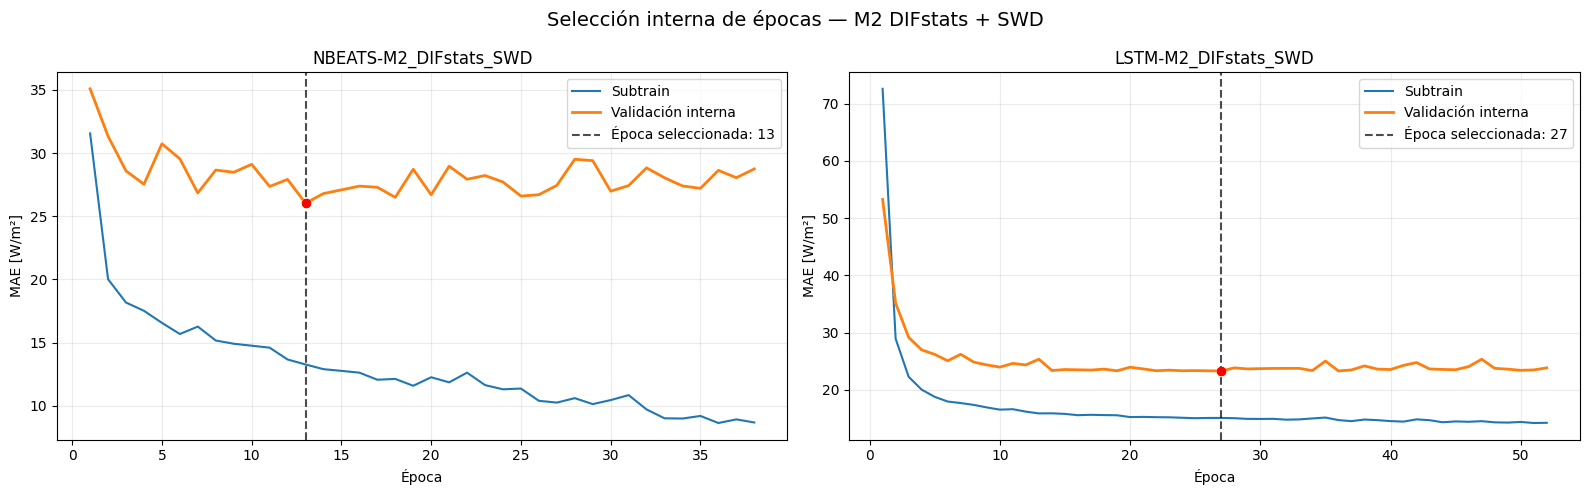


FASE 3B COMPLETADA
Resumen: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/ingenieria_caracteristicas_operacional_20261007T091724Z/02_seleccion_epocas/M2_DIFstats_SWD_original/resumen_seleccion_M2.csv
Figura: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/ingenieria_caracteristicas_operacional_20261007T091724Z/06_figuras/M2_DIFstats_SWD_original/seleccion_epocas_M2_DIFstats_SWD.png
Validation externa utilizada: NO


In [ ]:
import os
import json
import time
import copy
import random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# 1. Configuración
SEED = 42
N_SUBTRAIN = 4428
BATCH_SIZE = 128
MAX_EPOCHS = 300
PATIENCE = 25
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-5
CLIP_GRAD = 1.0
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", DEVICE)

def fijar_semilla(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

fijar_semilla(SEED)


# 2. Recuperar rutas
BASE_DIR = Path("/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado")
PUNTERO_EXP = BASE_DIR / "resultados/ejecuciones/ULTIMA_INGENIERIA_OPERACIONAL.json"
with open(PUNTERO_EXP, "r", encoding="utf-8") as f:
    puntero = json.load(f)

RUTA_M2 = Path(puntero["matrices_M2_original"])
if not RUTA_M2.exists():
    raise FileNotFoundError(RUTA_M2)

RUN_DIR = RUTA_M2.parents[1]
DIR_SELECCION = RUN_DIR / "02_seleccion_epocas" / "M2_DIFstats_SWD_original"
DIR_FIGURAS = RUN_DIR / "06_figuras" / "M2_DIFstats_SWD_original"
DIR_SELECCION.mkdir(parents=True, exist_ok=True)
DIR_FIGURAS.mkdir(parents=True, exist_ok=True)
print("Matrices:", RUTA_M2)
print("Selección:", DIR_SELECCION)


# 3. Cargar M2
with np.load(RUTA_M2, allow_pickle=False) as datos:
    X_train = datos["X_train_M2"].astype(np.float32)
    X_validation_externa = datos["X_validation_M2"].astype(np.float32)
    y_train = datos["y_train"].astype(np.float32)
    y_validation_externa = datos["y_validation"].astype(np.float32)
    fechas_train = pd.to_datetime(datos["timestamps_train"])
    canales_M2 = datos["canales_M2"].astype(str).tolist()

assert X_train.shape == (5149, 24, 7)
assert y_train.shape == (5149,)
assert len(fechas_train) == 5149
print("\nDatos cargados:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("Canales:", canales_M2)


# 4. División temporal interna
X_subtrain_raw = X_train[:N_SUBTRAIN]
y_subtrain_raw = y_train[:N_SUBTRAIN]
X_interna_raw = X_train[N_SUBTRAIN:]
y_interna_raw = y_train[N_SUBTRAIN:]
fechas_subtrain = fechas_train[:N_SUBTRAIN]
fechas_interna = fechas_train[N_SUBTRAIN:]
assert len(X_subtrain_raw) == 4428
assert len(X_interna_raw) == 721
print("\nDivisión temporal:")
print("Subtrain:", X_subtrain_raw.shape, fechas_subtrain.min(), "→", fechas_subtrain.max())
print("Validación interna:", X_interna_raw.shape, fechas_interna.min(), "→", fechas_interna.max())
print("Validation externa reservada:", X_validation_externa.shape)


# 5. Escalado ajustado exclusivamente con subtrain
media_X = X_subtrain_raw.mean(axis=(0, 1), keepdims=True).astype(np.float32)
std_X = X_subtrain_raw.std(axis=(0, 1), keepdims=True).astype(np.float32)
std_X = np.where(std_X < 1e-8, 1.0, std_X)
media_y = np.float32(y_subtrain_raw.mean())
std_y = np.float32(y_subtrain_raw.std())
if std_y < 1e-8:
    std_y = np.float32(1.0)

X_subtrain = ((X_subtrain_raw - media_X) / std_X).astype(np.float32)
X_interna = ((X_interna_raw - media_X) / std_X).astype(np.float32)
y_subtrain = ((y_subtrain_raw - media_y) / std_y).astype(np.float32)
y_interna = ((y_interna_raw - media_y) / std_y).astype(np.float32)
print("\nEscalado:")
for nombre, media, desviacion in zip(canales_M2, media_X.reshape(-1), std_X.reshape(-1)):
    print(f"{nombre:15s} " f"media={media:10.4f} " f"std={desviacion:10.4f}")

print(f"Objetivo: media={media_y:.4f}, std={std_y:.4f}")


# 6. DataLoaders
dataset_subtrain = TensorDataset(torch.from_numpy(X_subtrain), torch.from_numpy(y_subtrain))
generador = torch.Generator()
generador.manual_seed(SEED)
loader_subtrain = DataLoader(
    dataset_subtrain,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=generador,
    num_workers=0,
    drop_last=False,
)
X_interna_tensor = torch.from_numpy(X_interna)
y_interna_tensor = torch.from_numpy(y_interna)


# 7. Arquitectura LSTM
class LSTMRegresor(nn.Module):
    def __init__(self, n_features, hidden_size=64, num_layers=1):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=n_features, hidden_size=hidden_size, num_layers=num_layers, batch_first=True
        )
        self.cabeza = nn.Sequential(nn.Linear(hidden_size, 32), nn.ReLU(), nn.Linear(32, 1))

    def forward(self, x):
        salida, _ = self.lstm(x)
        ultimo = salida[:, -1, :]
        return self.cabeza(ultimo).squeeze(-1)


# 8. Arquitectura N-BEATS multivariante
class NBeatsBlock(nn.Module):
    def __init__(self, input_size, horizon=24, hidden_size=128, n_dense_layers=3):
        super().__init__()
        capas = []
        dimension = input_size
        for _ in range(n_dense_layers):
            capas.extend([nn.Linear(dimension, hidden_size), nn.ReLU()])
            dimension = hidden_size

        self.red = nn.Sequential(*capas)
        self.backcast = nn.Linear(hidden_size, horizon)
        self.forecast = nn.Linear(hidden_size, 1)

    def forward(self, x):
        h = self.red(x)
        backcast = self.backcast(h)
        forecast = self.forecast(h).squeeze(-1)
        return backcast, forecast

class NBeatsMultivariante(nn.Module):
    def __init__(
        self,
        n_features,
        horizon=24,
        n_stacks=2,
        blocks_per_stack=3,
        hidden_size=128,
        n_dense_layers=3,
    ):
        super().__init__()
        self.n_features = n_features
        self.horizon = horizon
        n_blocks = n_stacks * blocks_per_stack
        self.blocks = nn.ModuleList(
            [
                NBeatsBlock(
                    input_size=horizon * n_features,
                    horizon=horizon,
                    hidden_size=hidden_size,
                    n_dense_layers=n_dense_layers,
                )
                for _ in range(n_blocks)
            ]
        )

    def forward(self, x):
        residual = x
        forecast_total = torch.zeros(x.shape[0], device=x.device, dtype=x.dtype)
        for bloque in self.blocks:
            entrada_plana = residual.reshape(residual.shape[0], -1)
            backcast, forecast = bloque(entrada_plana)

            # El residual se aplica exclusivamente al canal DIF.
            residual_DIF = residual[:, :, 0] - backcast
            residual = torch.cat([residual_DIF.unsqueeze(-1), residual[:, :, 1:]], dim=2)
            forecast_total = forecast_total + forecast

        return forecast_total


# 9. Predicción por lotes
@torch.no_grad()
def predecir_escalado(modelo, X_tensor, batch_size=512):
    modelo.eval()
    predicciones = []
    for inicio in range(0, len(X_tensor), batch_size):
        lote = X_tensor[inicio : inicio + batch_size].to(DEVICE)
        prediccion = modelo(lote)
        predicciones.append(prediccion.detach().cpu().numpy())

    return np.concatenate(predicciones)


# 10. Entrenamiento con early stopping
def seleccionar_epoca(nombre_modelo, constructor_modelo):
    fijar_semilla(SEED)
    modelo = constructor_modelo().to(DEVICE)
    optimizador = torch.optim.Adam(modelo.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    criterio = nn.L1Loss()
    mejor_mae = np.inf
    mejor_epoca = None
    mejor_estado = None
    sin_mejora = 0
    historial = []
    inicio_total = time.perf_counter()
    for epoca in range(1, MAX_EPOCHS + 1):
        modelo.train()
        suma_error = 0.0
        n_observaciones = 0
        for X_lote, y_lote in loader_subtrain:
            X_lote = X_lote.to(DEVICE)
            y_lote = y_lote.to(DEVICE)
            optimizador.zero_grad(set_to_none=True)
            prediccion = modelo(X_lote)
            perdida = criterio(prediccion, y_lote)
            perdida.backward()
            torch.nn.utils.clip_grad_norm_(modelo.parameters(), CLIP_GRAD)
            optimizador.step()
            suma_error += perdida.item() * len(X_lote)
            n_observaciones += len(X_lote)

        # MAE de entrenamiento expresado en W/m²
        train_mae = (suma_error / n_observaciones) * float(std_y)

        # Validación interna en unidades originales
        pred_interna_escalada = predecir_escalado(modelo, X_interna_tensor)
        pred_interna = pred_interna_escalada * std_y + media_y
        validation_mae = np.mean(np.abs(y_interna_raw - pred_interna))
        historial.append(
            {
                "modelo": nombre_modelo,
                "epoca": epoca,
                "train_MAE": train_mae,
                "validation_interna_MAE": validation_mae,
            }
        )
        mejora = validation_mae < mejor_mae - 1e-8
        if mejora:
            mejor_mae = float(validation_mae)
            mejor_epoca = int(epoca)
            mejor_estado = {
                clave: valor.detach().cpu().clone() for clave, valor in modelo.state_dict().items()
            }
            sin_mejora = 0
        else:
            sin_mejora += 1

        if epoca == 1 or epoca % 10 == 0 or sin_mejora >= PATIENCE:
            print(
                f"{nombre_modelo:20s} | "
                f"época {epoca:3d} | "
                f"train={train_mae:8.4f} | "
                f"val={validation_mae:8.4f} | "
                f"mínimo={mejor_mae:8.4f} "
                f"(época {mejor_epoca}) | "
                f"sin mejora={sin_mejora:2d}"
            )

        if sin_mejora >= PATIENCE:
            break

    tiempo_minutos = (time.perf_counter() - inicio_total) / 60
    modelo.load_state_dict(mejor_estado)
    historial = pd.DataFrame(historial)
    ruta_historial = DIR_SELECCION / f"historial_{nombre_modelo}.csv"
    historial.to_csv(ruta_historial, index=False)
    ruta_checkpoint = DIR_SELECCION / f"checkpoint_subtrain_{nombre_modelo}.pt"
    torch.save(
        {
            "modelo": nombre_modelo,
            "epoca_seleccionada": mejor_epoca,
            "validation_interna_MAE": mejor_mae,
            "model_state_dict": mejor_estado,
            "media_X": media_X,
            "std_X": std_X,
            "media_y": media_y,
            "std_y": std_y,
            "canales": canales_M2,
            "n_subtrain": N_SUBTRAIN,
            "patience": PATIENCE,
            "seed": SEED,
            "protocolo": "original_sin_mascara_nocturna",
        },
        ruta_checkpoint,
    )
    return {
        "modelo": nombre_modelo,
        "epoca_seleccionada": mejor_epoca,
        "MAE_interno_minimo": mejor_mae,
        "ultima_epoca_ejecutada": int(historial["epoca"].max()),
        "patience": PATIENCE,
        "tiempo_minutos": tiempo_minutos,
        "ruta_historial": str(ruta_historial),
        "ruta_checkpoint_subtrain": str(ruta_checkpoint),
    }, historial


# 11. Seleccionar épocas de NBEATS-M2 y LSTM-M2
constructores = {
    "NBEATS-M2_DIFstats_SWD": lambda: NBeatsMultivariante(
        n_features=7, horizon=24, n_stacks=2, blocks_per_stack=3, hidden_size=128, n_dense_layers=3
    ),
    "LSTM-M2_DIFstats_SWD": lambda: LSTMRegresor(n_features=7, hidden_size=64, num_layers=1),
}
resultados = []
historiales = {}
for nombre, constructor in constructores.items():
    print("\n" + "=" * 80)
    print("SELECCIÓN:", nombre)
    print("=" * 80)
    resultado, historial = seleccionar_epoca(nombre, constructor)
    resultados.append(resultado)
    historiales[nombre] = historial


# 12. Resumen y figuras
resumen_seleccion = pd.DataFrame(resultados).sort_values("MAE_interno_minimo")
RUTA_RESUMEN = DIR_SELECCION / "resumen_seleccion_M2.csv"
resumen_seleccion.to_csv(RUTA_RESUMEN, index=False)
print("\nRESUMEN DE SELECCIÓN:")
display(resumen_seleccion)
fig, ejes = plt.subplots(1, 2, figsize=(16, 5))
for eje, (nombre, historial) in zip(ejes, historiales.items()):
    eje.plot(historial["epoca"], historial["train_MAE"], label="Subtrain", linewidth=1.5)
    eje.plot(
        historial["epoca"],
        historial["validation_interna_MAE"],
        label="Validación interna",
        linewidth=2,
    )
    fila_modelo = resumen_seleccion[resumen_seleccion["modelo"] == nombre].iloc[0]
    mejor_epoca = int(fila_modelo["epoca_seleccionada"])
    mejor_mae = float(fila_modelo["MAE_interno_minimo"])
    eje.axvline(
        mejor_epoca,
        color="black",
        linestyle="--",
        alpha=0.7,
        label=f"Época seleccionada: {mejor_epoca}",
    )
    eje.scatter([mejor_epoca], [mejor_mae], color="red", zorder=5)
    eje.set_title(nombre)
    eje.set_xlabel("Época")
    eje.set_ylabel("MAE [W/m²]")
    eje.grid(alpha=0.25)
    eje.legend()

fig.suptitle("Selección interna de épocas — M2 DIFstats + SWD", fontsize=14)
plt.tight_layout()
RUTA_FIGURA = DIR_FIGURAS / "seleccion_epocas_M2_DIFstats_SWD.png"
plt.savefig(RUTA_FIGURA, dpi=180, bbox_inches="tight")
plt.show()


# 13. Actualizar puntero
puntero["seleccion_M2_original"] = str(RUTA_RESUMEN)
puntero["figura_seleccion_M2_original"] = str(RUTA_FIGURA)
puntero["fase_actual"] = "fase_3B_seleccion_epocas_M2_completada"
with open(PUNTERO_EXP, "w", encoding="utf-8") as f:
    json.dump(puntero, f, ensure_ascii=False, indent=2)

print("\nFASE 3B COMPLETADA")
print("Resumen:", RUTA_RESUMEN)
print("Figura:", RUTA_FIGURA)
print("Validation externa utilizada: NO")

In [ ]:
print("Comprobación del escalado del subtrain:\n")
for j, canal in enumerate(canales_M2):
    valores = X_subtrain[:, :, j]
    print(
        f"{canal:15s} "
        f"media={valores.mean(): .6f} | "
        f"std={valores.std(): .6f} | "
        f"min={valores.min(): .3f} | "
        f"max={valores.max(): .3f}"
    )

Comprobación del escalado del subtrain:

DIF_media       media= 0.000022 | std= 0.999981 | min=-0.713 | max= 4.477
elevacion       media= 0.000002 | std= 1.000027 | min=-2.118 | max= 1.968
DIF_std         media=-0.000038 | std= 0.999927 | min=-0.533 | max= 11.002
DIF_rango       media= 0.000000 | std= 1.000080 | min=-0.657 | max= 6.133
SWD_media       media=-0.000005 | std= 0.999962 | min=-0.643 | max= 3.959
SWD_std         media=-0.000023 | std= 0.999979 | min=-0.390 | max= 9.335
SWD_rango       media=-0.000000 | std= 1.000034 | min=-0.599 | max= 4.873


**Resultados.** La LSTM alcanza el mínimo en la época 27 (MAE interno de 23,28 W/m²) y la N-BEATS, en la época 13 (26,04 W/m²).

### 4.3 Validación de DIFstats con SWD

La LSTM y la N-BEATS de M2 se reentrenan con todo el conjunto de entrenamiento durante 27 y 13 épocas, respectivamente, y se evalúan una sola vez en validación por ámbito.

Dispositivo: cpu

Datos cargados:
Train: (5149, 24, 7) (5149,)
Validation: (1464, 24, 7) (1464,)
Canales: ['DIF_media', 'elevacion', 'DIF_std', 'DIF_rango', 'SWD_media', 'SWD_std', 'SWD_rango']

Épocas seleccionadas:
NBEATS-M2: 13
LSTM-M2: 27

Comprobación del escalado de train:
DIF_media       media= 0.000020 | std= 1.000091
elevacion       media= 0.000001 | std= 1.000031
DIF_std         media= 0.000023 | std= 1.000026
DIF_rango       media=-0.000000 | std= 1.000020
SWD_media       media=-0.000003 | std= 0.999959
SWD_std         media=-0.000038 | std= 1.000025
SWD_rango       media= 0.000053 | std= 1.000037

Conteos por ámbito: {'total': 1464, 'operacion': 884, 'completamente_diurno': 765, 'transicion': 119, 'noche': 580}

REENTRENAMIENTO: NBEATS-M2_DIFstats_SWD
NBEATS-M2_DIFstats_SWD   | época   1/13 | MAE train= 30.6744
NBEATS-M2_DIFstats_SWD   | época   5/13 | MAE train= 17.5023
NBEATS-M2_DIFstats_SWD   | época  10/13 | MAE train= 15.4269
NBEATS-M2_DIFstats_SWD   | época  13/13 | M

,modelo,arquitectura,configuracion,epocas,n_features,tiempo_minutos,ruta_modelo,ruta_historial
0,NBEATS-M2_DIFstats_SWD,NBEATS,M2_DIFstats_SWD,13,7,0.530429,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...
1,LSTM-M2_DIFstats_SWD,LSTM,M2_DIFstats_SWD,27,7,0.594524,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...



MÉTRICAS OFICIALES EN VALIDATION:


,modelo,version_objetivo,ambito,n,DIF_media,DIF_mediana,MAE,nMAE_pct,RMSE,R2,sesgo
0,LSTM-M2_DIFstats_SWD,original,total,1464,85.233276,30.591667,16.200361,19.007085,32.286994,0.910821,-1.785709
1,NBEATS-M2_DIFstats_SWD,original,total,1464,85.233276,30.591667,18.167908,21.315510,34.376245,0.898907,3.063601
2,LSTM-M2_DIFstats_SWD,original,operacion,884,141.797562,127.733337,26.109875,18.413486,41.537970,0.847079,-3.646645
3,NBEATS-M2_DIFstats_SWD,original,operacion,884,141.797562,127.733337,29.338593,20.690477,44.218119,0.826708,4.464390
4,LSTM-M2_DIFstats_SWD,original,completamente_diurno,765,162.723083,145.683334,29.501268,18.129738,44.603579,0.796524,-4.820042
5,NBEATS-M2_DIFstats_SWD,original,completamente_diurno,765,162.723083,145.683334,33.037609,20.302964,47.441733,0.769805,4.563361
6,LSTM-M2_DIFstats_SWD,original,transicion,119,7.276421,4.850000,4.308057,59.205718,5.269693,0.447603,3.896617
7,NBEATS-M2_DIFstats_SWD,original,transicion,119,7.276421,4.850000,5.559233,76.400646,7.466889,-0.109072,3.828147
8,LSTM-M2_DIFstats_SWD,original,noche,580,-0.978506,-1.000000,1.096895,NaN,1.239098,-14.256647,1.050615
9,NBEATS-M2_DIFstats_SWD,original,noche,580,-0.978506,-1.000000,1.142241,NaN,1.667691,-26.636238,0.928606


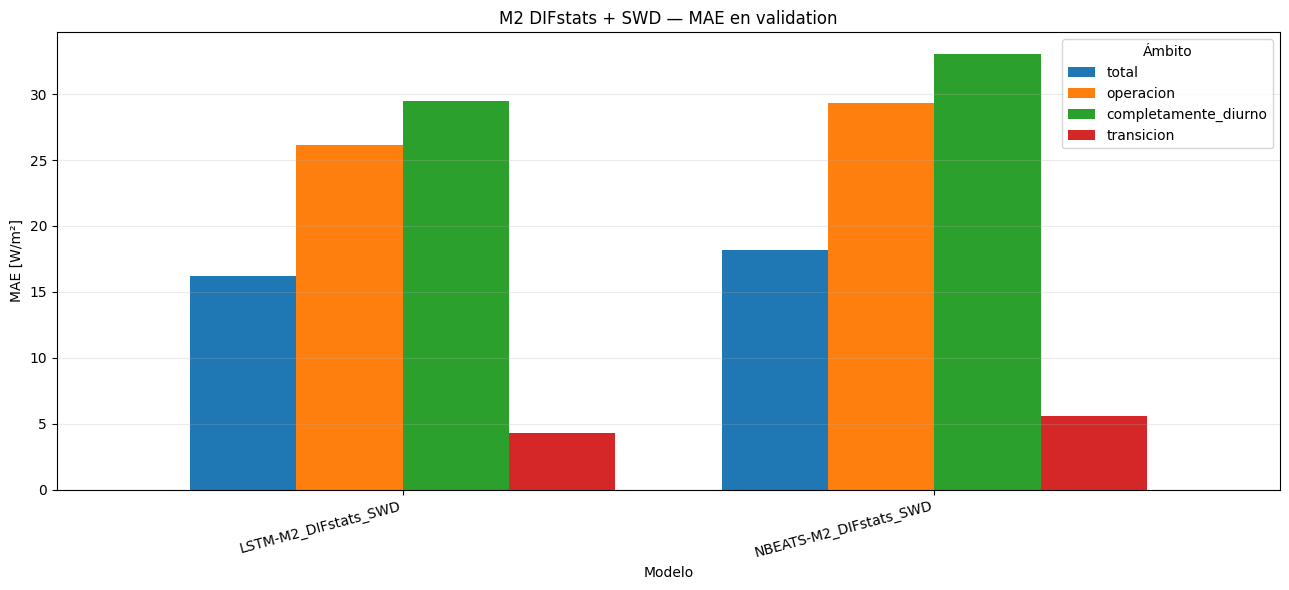


FASE 3C COMPLETADA
Modelos: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/ingenieria_caracteristicas_operacional_20261007T091724Z/03_modelos/M2_DIFstats_SWD_original
Predicciones: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/ingenieria_caracteristicas_operacional_20261007T091724Z/04_predicciones/M2_DIFstats_SWD_original/predicciones_validation_M2_DIFstats_SWD.csv
Métricas: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/ingenieria_caracteristicas_operacional_20261007T091724Z/05_metricas/M2_DIFstats_SWD_original/metricas_validation_M2_DIFstats_SWD.csv
Tiempos: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/ingenieria_caracteristicas_operacional_20261007T091724Z/08_logs/M2_DIFstats_SWD_original/resumen_reentrenamiento_M2.csv
Figura: /content/drive/MyDrive/TFM Aghmir/TFM/02

In [ ]:
import os
import re
import json
import time
import random
import unicodedata
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Configuración
SEED = 42
BATCH_SIZE = 128
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-5
CLIP_GRAD = 1.0
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", DEVICE)

def fijar_semilla(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

fijar_semilla(SEED)


# 2. Rutas y datos
BASE_DIR = Path("/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado")
PUNTERO_EXP = BASE_DIR / "resultados/ejecuciones/ULTIMA_INGENIERIA_OPERACIONAL.json"
with open(PUNTERO_EXP, "r", encoding="utf-8") as f:
    puntero = json.load(f)

RUTA_M2 = Path(puntero["matrices_M2_original"])
RUTA_SELECCION = Path(puntero["seleccion_M2_original"])
RUN_DIR = RUTA_M2.parents[1]
DIR_MODELOS = RUN_DIR / "03_modelos" / "M2_DIFstats_SWD_original"
DIR_PREDICCIONES = RUN_DIR / "04_predicciones" / "M2_DIFstats_SWD_original"
DIR_METRICAS = RUN_DIR / "05_metricas" / "M2_DIFstats_SWD_original"
DIR_FIGURAS = RUN_DIR / "06_figuras" / "M2_DIFstats_SWD_original"
DIR_LOGS = RUN_DIR / "08_logs" / "M2_DIFstats_SWD_original"
for directorio in [DIR_MODELOS, DIR_PREDICCIONES, DIR_METRICAS, DIR_FIGURAS, DIR_LOGS]:
    directorio.mkdir(parents=True, exist_ok=True)

with np.load(RUTA_M2, allow_pickle=False) as datos:
    X_train_raw = datos["X_train_M2"].astype(np.float32)
    X_validation_raw = datos["X_validation_M2"].astype(np.float32)
    y_train_raw = datos["y_train"].astype(np.float32)
    y_validation_raw = datos["y_validation"].astype(np.float32)
    fechas_train = pd.to_datetime(datos["timestamps_train"])
    fechas_validation = pd.to_datetime(datos["timestamps_validation"])
    canales_M2 = datos["canales_M2"].astype(str).tolist()

assert X_train_raw.shape == (5149, 24, 7)
assert X_validation_raw.shape == (1464, 24, 7)
assert y_train_raw.shape == (5149,)
assert y_validation_raw.shape == (1464,)
print("\nDatos cargados:")
print("Train:", X_train_raw.shape, y_train_raw.shape)
print("Validation:", X_validation_raw.shape, y_validation_raw.shape)
print("Canales:", canales_M2)


# 3. Recuperar épocas seleccionadas
seleccion = pd.read_csv(RUTA_SELECCION)
epocas = dict(zip(seleccion["modelo"], seleccion["epoca_seleccionada"].astype(int)))
EPOCAS_NBEATS = int(epocas["NBEATS-M2_DIFstats_SWD"])
EPOCAS_LSTM = int(epocas["LSTM-M2_DIFstats_SWD"])
print("\nÉpocas seleccionadas:")
print("NBEATS-M2:", EPOCAS_NBEATS)
print("LSTM-M2:", EPOCAS_LSTM)
assert EPOCAS_NBEATS == 13
assert EPOCAS_LSTM == 27


# 4. Escalado ajustado con todo train
media_X = X_train_raw.mean(axis=(0, 1), keepdims=True).astype(np.float32)
std_X = X_train_raw.std(axis=(0, 1), keepdims=True).astype(np.float32)
std_X = np.where(std_X < 1e-8, 1.0, std_X)
media_y = np.float32(y_train_raw.mean())
std_y = np.float32(y_train_raw.std())
if std_y < 1e-8:
    std_y = np.float32(1.0)

X_train = ((X_train_raw - media_X) / std_X).astype(np.float32)
X_validation = ((X_validation_raw - media_X) / std_X).astype(np.float32)
y_train = ((y_train_raw - media_y) / std_y).astype(np.float32)
print("\nComprobación del escalado de train:")
for j, canal in enumerate(canales_M2):
    valores = X_train[:, :, j]
    print(f"{canal:15s} " f"media={valores.mean(): .6f} | " f"std={valores.std(): .6f}")


# 5. Regímenes solares de validation
RUTA_VALIDATION_HGB = (
    BASE_DIR
    / "documentacion"
    / "checkpoint_continuidad_modelado_20261006_125123"
    / "validation_hgb.parquet"
)
if not RUTA_VALIDATION_HGB.exists():
    raise FileNotFoundError(RUTA_VALIDATION_HGB)

validation_hgb = pd.read_parquet(RUTA_VALIDATION_HGB)
assert len(validation_hgb) == len(y_validation_raw)
assert "regimen_solar_objetivo" in validation_hgb.columns

def normalizar_texto(texto):
    texto = unicodedata.normalize("NFKD", str(texto))
    texto = "".join(c for c in texto if not unicodedata.combining(c))
    return re.sub(r"[^a-z0-9]+", "_", texto.lower()).strip("_")

regimen = validation_hgb["regimen_solar_objetivo"].map(normalizar_texto).to_numpy()
mascara_noche = np.array(["noche" in x for x in regimen])
mascara_transicion = np.array(["trans" in x for x in regimen])
mascara_diurno = np.array([("complet" in x and "diurn" in x) for x in regimen])
mascara_operacion = ~mascara_noche
mascaras = {
    "total": np.ones(len(y_validation_raw), dtype=bool),
    "operacion": mascara_operacion,
    "completamente_diurno": mascara_diurno,
    "transicion": mascara_transicion,
    "noche": mascara_noche,
}
conteos = {nombre: int(mascara.sum()) for nombre, mascara in mascaras.items()}
print("\nConteos por ámbito:", conteos)
assert conteos == {
    "total": 1464,
    "operacion": 884,
    "completamente_diurno": 765,
    "transicion": 119,
    "noche": 580,
}


# 6. DataLoader de train completo
dataset_train = TensorDataset(torch.from_numpy(X_train), torch.from_numpy(y_train))

def crear_loader_train():
    generador = torch.Generator()
    generador.manual_seed(SEED)
    return DataLoader(
        dataset_train,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=generador,
        num_workers=0,
        drop_last=False,
    )

X_validation_tensor = torch.from_numpy(X_validation)


# 7. Arquitecturas
class LSTMRegresor(nn.Module):
    def __init__(self, n_features, hidden_size=64, num_layers=1):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=n_features, hidden_size=hidden_size, num_layers=num_layers, batch_first=True
        )
        self.cabeza = nn.Sequential(nn.Linear(hidden_size, 32), nn.ReLU(), nn.Linear(32, 1))

    def forward(self, x):
        salida, _ = self.lstm(x)
        ultimo = salida[:, -1, :]
        return self.cabeza(ultimo).squeeze(-1)

class NBeatsBlock(nn.Module):
    def __init__(self, input_size, horizon=24, hidden_size=128, n_dense_layers=3):
        super().__init__()
        capas = []
        dimension = input_size
        for _ in range(n_dense_layers):
            capas.extend([nn.Linear(dimension, hidden_size), nn.ReLU()])
            dimension = hidden_size

        self.red = nn.Sequential(*capas)
        self.backcast = nn.Linear(hidden_size, horizon)
        self.forecast = nn.Linear(hidden_size, 1)

    def forward(self, x):
        h = self.red(x)
        return (self.backcast(h), self.forecast(h).squeeze(-1))

class NBeatsMultivariante(nn.Module):
    def __init__(
        self,
        n_features,
        horizon=24,
        n_stacks=2,
        blocks_per_stack=3,
        hidden_size=128,
        n_dense_layers=3,
    ):
        super().__init__()
        n_blocks = n_stacks * blocks_per_stack
        self.blocks = nn.ModuleList(
            [
                NBeatsBlock(
                    input_size=horizon * n_features,
                    horizon=horizon,
                    hidden_size=hidden_size,
                    n_dense_layers=n_dense_layers,
                )
                for _ in range(n_blocks)
            ]
        )

    def forward(self, x):
        residual = x
        forecast_total = torch.zeros(x.shape[0], device=x.device, dtype=x.dtype)
        for bloque in self.blocks:
            entrada = residual.reshape(residual.shape[0], -1)
            backcast, forecast = bloque(entrada)
            residual_DIF = residual[:, :, 0] - backcast
            residual = torch.cat([residual_DIF.unsqueeze(-1), residual[:, :, 1:]], dim=2)
            forecast_total = forecast_total + forecast

        return forecast_total


# 8. Entrenamiento completo
@torch.no_grad()
def predecir_modelo(modelo, X_tensor):
    modelo.eval()
    predicciones = []
    for inicio in range(0, len(X_tensor), 512):
        lote = X_tensor[inicio : inicio + 512].to(DEVICE)
        predicciones.append(modelo(lote).cpu().numpy())

    prediccion_escalada = np.concatenate(predicciones)
    return (prediccion_escalada * std_y + media_y).astype(np.float32)

def entrenar_completo(nombre_modelo, constructor, numero_epocas):
    fijar_semilla(SEED)
    modelo = constructor().to(DEVICE)
    loader = crear_loader_train()
    optimizador = torch.optim.Adam(modelo.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    criterio = nn.L1Loss()
    historial = []
    inicio_total = time.perf_counter()
    for epoca in range(1, numero_epocas + 1):
        inicio_epoca = time.perf_counter()
        modelo.train()
        suma_perdida = 0.0
        n_observaciones = 0
        for X_lote, y_lote in loader:
            X_lote = X_lote.to(DEVICE)
            y_lote = y_lote.to(DEVICE)
            optimizador.zero_grad(set_to_none=True)
            prediccion = modelo(X_lote)
            perdida = criterio(prediccion, y_lote)
            perdida.backward()
            torch.nn.utils.clip_grad_norm_(modelo.parameters(), CLIP_GRAD)
            optimizador.step()
            suma_perdida += perdida.item() * len(X_lote)
            n_observaciones += len(X_lote)

        train_mae = (suma_perdida / n_observaciones) * float(std_y)
        tiempo_epoca = time.perf_counter() - inicio_epoca
        historial.append(
            {
                "modelo": nombre_modelo,
                "epoca": epoca,
                "train_MAE": train_mae,
                "tiempo_epoca_segundos": tiempo_epoca,
            }
        )
        if epoca == 1 or epoca % 5 == 0 or epoca == numero_epocas:
            print(
                f"{nombre_modelo:24s} | "
                f"época {epoca:3d}/{numero_epocas} | "
                f"MAE train={train_mae:8.4f}"
            )

    tiempo_minutos = (time.perf_counter() - inicio_total) / 60
    pred_validation = predecir_modelo(modelo, X_validation_tensor)
    historial = pd.DataFrame(historial)
    ruta_historial = DIR_LOGS / f"historial_reentrenamiento_{nombre_modelo}.csv"
    historial.to_csv(ruta_historial, index=False)
    estado_cpu = {clave: valor.detach().cpu() for clave, valor in modelo.state_dict().items()}
    ruta_modelo = DIR_MODELOS / f"{nombre_modelo}.pt"
    torch.save(
        {
            "modelo": nombre_modelo,
            "arquitectura": ("LSTM" if nombre_modelo.startswith("LSTM") else "NBEATS"),
            "configuracion": "M2_DIFstats_SWD",
            "epocas": numero_epocas,
            "n_features": 7,
            "model_state_dict": estado_cpu,
            "media_X": media_X,
            "std_X": std_X,
            "media_y": media_y,
            "std_y": std_y,
            "canales": canales_M2,
            "seed": SEED,
            "batch_size": BATCH_SIZE,
            "learning_rate": LEARNING_RATE,
            "weight_decay": WEIGHT_DECAY,
            "clip_grad": CLIP_GRAD,
            "tiempo_minutos": tiempo_minutos,
            "protocolo": "original_sin_mascara_nocturna",
        },
        ruta_modelo,
    )
    return (
        {
            "modelo": nombre_modelo,
            "arquitectura": ("LSTM" if nombre_modelo.startswith("LSTM") else "NBEATS"),
            "configuracion": "M2_DIFstats_SWD",
            "epocas": numero_epocas,
            "n_features": 7,
            "tiempo_minutos": tiempo_minutos,
            "ruta_modelo": str(ruta_modelo),
            "ruta_historial": str(ruta_historial),
        },
        pred_validation,
        historial,
    )


# 9. Reentrenar los dos modelos
configuraciones = {
    "NBEATS-M2_DIFstats_SWD": {
        "constructor": lambda: NBeatsMultivariante(
            n_features=7,
            horizon=24,
            n_stacks=2,
            blocks_per_stack=3,
            hidden_size=128,
            n_dense_layers=3,
        ),
        "epocas": EPOCAS_NBEATS,
    },
    "LSTM-M2_DIFstats_SWD": {
        "constructor": lambda: LSTMRegresor(n_features=7, hidden_size=64, num_layers=1),
        "epocas": EPOCAS_LSTM,
    },
}
resumen_entrenamiento = []
predicciones = {}
historiales = {}
for nombre, configuracion in configuraciones.items():
    print("\n" + "=" * 80)
    print("REENTRENAMIENTO:", nombre)
    print("=" * 80)
    resultado, prediccion, historial = entrenar_completo(
        nombre_modelo=nombre,
        constructor=configuracion["constructor"],
        numero_epocas=configuracion["epocas"],
    )
    resumen_entrenamiento.append(resultado)
    predicciones[nombre] = prediccion
    historiales[nombre] = historial

resumen_entrenamiento = pd.DataFrame(resumen_entrenamiento)
RUTA_RESUMEN_ENTRENAMIENTO = DIR_LOGS / "resumen_reentrenamiento_M2.csv"
resumen_entrenamiento.to_csv(RUTA_RESUMEN_ENTRENAMIENTO, index=False)
print("\nResumen del reentrenamiento:")
display(resumen_entrenamiento)


# 10. Métricas oficiales
def calcular_metricas(modelo, y_real, y_pred, mascaras):
    filas = []
    for ambito in ["total", "operacion", "completamente_diurno", "transicion", "noche"]:
        mascara = mascaras[ambito]
        real = y_real[mascara]
        pred = y_pred[mascara]
        dif_media = float(np.mean(real))
        dif_mediana = float(np.median(real))
        mae = float(mean_absolute_error(real, pred))
        rmse = float(np.sqrt(mean_squared_error(real, pred)))
        r2 = float(r2_score(real, pred))
        sesgo = float(np.mean(pred - real))

        # El nMAE nocturno no es interpretable:
        # DIF media es negativa y próxima a cero.
        if ambito == "noche" or dif_media <= 0:
            nmae = np.nan
        else:
            nmae = 100.0 * mae / dif_media

        filas.append(
            {
                "modelo": modelo,
                "version_objetivo": "original",
                "ambito": ambito,
                "n": int(mascara.sum()),
                "DIF_media": dif_media,
                "DIF_mediana": dif_mediana,
                "MAE": mae,
                "nMAE_pct": nmae,
                "RMSE": rmse,
                "R2": r2,
                "sesgo": sesgo,
            }
        )

    return pd.DataFrame(filas)

metricas = pd.concat(
    [
        calcular_metricas(
            modelo=nombre, y_real=y_validation_raw, y_pred=prediccion, mascaras=mascaras
        )
        for nombre, prediccion in predicciones.items()
    ],
    ignore_index=True,
)
orden_ambitos = {"total": 0, "operacion": 1, "completamente_diurno": 2, "transicion": 3, "noche": 4}
metricas["orden_ambito"] = metricas["ambito"].map(orden_ambitos)
metricas = (
    metricas.sort_values(["orden_ambito", "MAE"])
    .drop(columns="orden_ambito")
    .reset_index(drop=True)
)
RUTA_METRICAS = DIR_METRICAS / "metricas_validation_M2_DIFstats_SWD.csv"
metricas.to_csv(RUTA_METRICAS, index=False)
print("\nMÉTRICAS OFICIALES EN VALIDATION:")
display(metricas)


# 11. Guardar predicciones
predicciones_df = pd.DataFrame(
    {"instante_objetivo": fechas_validation, "DIF_real": y_validation_raw, "regimen_solar": regimen}
)
for nombre, prediccion in predicciones.items():
    predicciones_df[f"pred_{nombre}"] = prediccion

RUTA_PREDICCIONES = DIR_PREDICCIONES / "predicciones_validation_M2_DIFstats_SWD.csv"
predicciones_df.to_csv(RUTA_PREDICCIONES, index=False)


# 12. Figura comparativa de MAE
ambitos_figura = ["total", "operacion", "completamente_diurno", "transicion"]
tabla_figura = (
    metricas[metricas["ambito"].isin(ambitos_figura)]
    .pivot(index="modelo", columns="ambito", values="MAE")
    .reindex(columns=ambitos_figura)
)
ax = tabla_figura.plot(kind="bar", figsize=(13, 6), width=0.8)
ax.set_title("M2 DIFstats + SWD — MAE en validation")
ax.set_xlabel("Modelo")
ax.set_ylabel("MAE [W/m²]")
ax.grid(axis="y", alpha=0.25)
ax.legend(title="Ámbito")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
RUTA_FIGURA = DIR_FIGURAS / "comparacion_MAE_validation_M2.png"
plt.savefig(RUTA_FIGURA, dpi=180, bbox_inches="tight")
plt.show()


# 13. Actualizar puntero
puntero["modelos_M2_original"] = str(DIR_MODELOS)
puntero["predicciones_M2_original"] = str(RUTA_PREDICCIONES)
puntero["metricas_M2_original"] = str(RUTA_METRICAS)
puntero["resumen_entrenamiento_M2_original"] = str(RUTA_RESUMEN_ENTRENAMIENTO)
puntero["figura_M2_original"] = str(RUTA_FIGURA)
puntero["fase_actual"] = "fase_3C_M2_reentrenado_y_validado"
with open(PUNTERO_EXP, "w", encoding="utf-8") as f:
    json.dump(puntero, f, ensure_ascii=False, indent=2)

print("\nFASE 3C COMPLETADA")
print("Modelos:", DIR_MODELOS)
print("Predicciones:", RUTA_PREDICCIONES)
print("Métricas:", RUTA_METRICAS)
print("Tiempos:", RUTA_RESUMEN_ENTRENAMIENTO)
print("Figura:", RUTA_FIGURA)
print("\nTest utilizado: NO")

**Resultados.** La LSTM de M2 obtiene un MAE de 16,20 W/m² en total, 26,11 W/m² en operación, 29,50 W/m² en horas completamente diurnas y 4,31 W/m² en transición, con sesgo positivo en transición (3,90 W/m²). La N-BEATS de M2 alcanza 18,17, 29,34, 33,04 y 5,56 W/m² en esos mismos ámbitos. En ambas arquitecturas estos valores superan los de M1; la única reducción respecto a M1 es el MAE nocturno de la N-BEATS (1,14 W/m²).

### 4.4 DIFstats con SWD y DIR

M3 (DIFstats + SWD + DIR) añade a M2 la media, la desviación intraminutal y el rango horarios de la irradiancia directa (DIR), hasta diez canales. Se seleccionan las épocas en la partición interna, se reentrenan la LSTM y la N-BEATS con todo el conjunto de entrenamiento y se comparan en validación con M1 y M2.

In [ ]:
from google.colab import drive

drive.mount("/content/drive", force_remount=False)
import json
from pathlib import Path
import numpy as np
import pandas as pd

# 1. Rutas
BASE_DIR = Path("/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado")
PUNTERO = BASE_DIR / "resultados/ejecuciones/ULTIMA_INGENIERIA_OPERACIONAL.json"
PARQUET_ORIGINAL = Path("/content/drive/MyDrive/TFM Aghmir/TFM/radiation_data_completo.parquet")
RUTA_TRAIN_HGB = (
    BASE_DIR / "documentacion/checkpoint_continuidad_modelado_20261006_125123/train_hgb.parquet"
)
with open(PUNTERO, "r", encoding="utf-8") as f:
    puntero = json.load(f)

RUTA_M2 = Path(puntero["matrices_M2_original"])
RUN_DIR = RUTA_M2.parents[1]
DIR_DATOS = RUN_DIR / "01_datos"
print("M2:", RUTA_M2)
print("RUN_DIR:", RUN_DIR)


# 2. Recuperar M2 desde Drive
with np.load(RUTA_M2, allow_pickle=False) as z:
    X_train_M2 = z["X_train_M2"].astype(np.float32)
    X_validation_M2 = z["X_validation_M2"].astype(np.float32)
    y_train = z["y_train"].astype(np.float32)
    y_validation = z["y_validation"].astype(np.float32)
    fechas_train = pd.DatetimeIndex(pd.to_datetime(z["timestamps_train"]))
    fechas_validation = pd.DatetimeIndex(pd.to_datetime(z["timestamps_validation"]))
    canales_M2 = z["canales_M2"].astype(str).tolist()

assert X_train_M2.shape == (5149, 24, 7)
assert X_validation_M2.shape == (1464, 24, 7)
print("\nM2 recuperado:")
print("Train:", X_train_M2.shape)
print("Validation:", X_validation_M2.shape)


# 3. Cargar únicamente las columnas necesarias del parquet
columnas_necesarias = [
    "Date/Time",
    "DIR [W/m**2]",
    "DIR std dev [W/m**2]",
    "DIR min [W/m**2]",
    "DIR max [W/m**2]",
]
df = pd.read_parquet(PARQUET_ORIGINAL, columns=columnas_necesarias)
df["instante"] = pd.to_datetime(df["Date/Time"], utc=True, errors="raise").dt.tz_convert(None)
df["hora"] = df["instante"].dt.floor("h")
for columna in columnas_necesarias[1:]:
    df[columna] = pd.to_numeric(df[columna], errors="coerce")


# 4. Estadísticos horarios de DIR
g = df.groupby("hora", sort=True)
DIR_horario = pd.DataFrame(
    {
        "DIR_media": g["DIR [W/m**2]"].mean(),
        "DIR_std": g["DIR std dev [W/m**2]"].mean(),
        "DIR_max_horario": g["DIR max [W/m**2]"].max(),
        "DIR_min_horario": g["DIR min [W/m**2]"].min(),
    }
)
DIR_horario["DIR_rango"] = DIR_horario["DIR_max_horario"] - DIR_horario["DIR_min_horario"]
DIR_horario = DIR_horario[["DIR_media", "DIR_std", "DIR_rango"]]
print("\nResumen horario DIR:")
display(DIR_horario.describe().T)


# 5. Ventanas [T-24, ..., T-1]
def crear_ventanas_DIR(fechas_objetivo):
    offsets = pd.to_timedelta(np.arange(24, 0, -1), unit="h")
    tiempos = fechas_objetivo.to_numpy()[:, None] - offsets.to_numpy()[None, :]
    valores = DIR_horario.reindex(pd.DatetimeIndex(tiempos.reshape(-1)))
    return valores.to_numpy(dtype=np.float32).reshape(len(fechas_objetivo), 24, 3)

X_train_DIR = crear_ventanas_DIR(fechas_train)
X_validation_DIR = crear_ventanas_DIR(fechas_validation)
print("\nMatrices DIR:")
print("Train:", X_train_DIR.shape)
print("Validation:", X_validation_DIR.shape)
print("Nulos train:", int(np.isnan(X_train_DIR).sum()))
print("Nulos validation:", int(np.isnan(X_validation_DIR).sum()))
if np.isnan(X_train_DIR).any() or np.isnan(X_validation_DIR).any():
    raise ValueError("Se han encontrado nulos en las ventanas DIR. No se ha guardado M3.")


# 6. Auditoría rápida contra los lags ya existentes
train_hgb = pd.read_parquet(RUTA_TRAIN_HGB)
auditoria = []
for lag in [1, 2, 3, 24]:
    columna = f"DIR_media_lag{lag}"
    posicion = 24 - lag
    diferencia = np.max(
        np.abs(X_train_DIR[:, posicion, 0] - train_hgb[columna].to_numpy(dtype=np.float32))
    )
    auditoria.append({"lag": lag, "diferencia_maxima": float(diferencia)})

auditoria = pd.DataFrame(auditoria)
print("\nAuditoría de alineación DIR:")
display(auditoria)
assert (
    auditoria["diferencia_maxima"] < 1e-4
).all(), "La alineación temporal de DIR no es correcta."


# 7. Construir M3
X_train_M3 = np.concatenate([X_train_M2, X_train_DIR], axis=2).astype(np.float32)
X_validation_M3 = np.concatenate([X_validation_M2, X_validation_DIR], axis=2).astype(np.float32)
canales_M3 = canales_M2 + ["DIR_media", "DIR_std", "DIR_rango"]
assert X_train_M3.shape == (5149, 24, 10)
assert X_validation_M3.shape == (1464, 24, 10)
print("\nM3 construido:")
print("X_train_M3:", X_train_M3.shape)
print("X_validation_M3:", X_validation_M3.shape)
print("Canales:", canales_M3)


# 8. Guardar en Drive
RUTA_M3 = DIR_DATOS / "matrices_M3_DIFstats_SWD_DIR_original.npz"
timestamps_train = np.asarray(fechas_train.strftime("%Y-%m-%dT%H:%M:%S"), dtype="U19")
timestamps_validation = np.asarray(fechas_validation.strftime("%Y-%m-%dT%H:%M:%S"), dtype="U19")
np.savez_compressed(
    RUTA_M3,
    X_train_M3=X_train_M3,
    X_validation_M3=X_validation_M3,
    y_train=y_train,
    y_validation=y_validation,
    timestamps_train=timestamps_train,
    timestamps_validation=timestamps_validation,
    canales_M3=np.asarray(canales_M3, dtype="U32"),
)

# Comprobación de recarga
with np.load(RUTA_M3, allow_pickle=False) as z:
    assert z["X_train_M3"].shape == (5149, 24, 10)
    assert z["X_validation_M3"].shape == (1464, 24, 10)

puntero["matrices_M3_original"] = str(RUTA_M3)
puntero["fase_actual"] = "fase_4A_M3_preparado"
with open(PUNTERO, "w", encoding="utf-8") as f:
    json.dump(puntero, f, ensure_ascii=False, indent=2)

print("\nFASE 4A COMPLETADA")
print("Archivo:", RUTA_M3)
print("Siguiente paso: subtrain de NBEATS-M3 y LSTM-M3")

M2: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/ingenieria_caracteristicas_operacional_20261007T091724Z/01_datos/matrices_M2_DIFstats_SWD_original.npz
RUN_DIR: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/ingenieria_caracteristicas_operacional_20261007T091724Z

M2 recuperado:
Train: (5149, 24, 7)
Validation: (1464, 24, 7)

Resumen horario DIR:


,count,mean,std,min,25%,50%,75%,max
DIR_media,9320.0,98.213690,206.174487,-1.300000,0.083333,1.000000,48.32500,948.316667
DIR_std,9320.0,8.170489,20.692607,0.003333,0.035000,0.101667,2.94625,177.440000
DIR_rango,9320.0,158.815451,274.709768,0.000000,1.000000,1.000000,208.00000,972.000000



Matrices DIR:
Train: (5149, 24, 3)
Validation: (1464, 24, 3)
Nulos train: 0
Nulos validation: 0

Auditoría de alineación DIR:


,lag,diferencia_maxima
0,1,0.0
1,2,0.0
2,3,0.0
3,24,0.0



M3 construido:
X_train_M3: (5149, 24, 10)
X_validation_M3: (1464, 24, 10)
Canales: ['DIF_media', 'elevacion', 'DIF_std', 'DIF_rango', 'SWD_media', 'SWD_std', 'SWD_rango', 'DIR_media', 'DIR_std', 'DIR_rango']

FASE 4A COMPLETADA
Archivo: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/ingenieria_caracteristicas_operacional_20261007T091724Z/01_datos/matrices_M3_DIFstats_SWD_DIR_original.npz
Siguiente paso: subtrain de NBEATS-M3 y LSTM-M3


Dispositivo: cpu
M3: (5149, 24, 10)
Canales: ['DIF_media', 'elevacion', 'DIF_std', 'DIF_rango', 'SWD_media', 'SWD_std', 'SWD_rango', 'DIR_media', 'DIR_std', 'DIR_rango']

Subtrain: (4428, 24, 10) 2023-12-30 00:00:00 → 2024-07-01 22:00:00
Validación interna: (721, 24, 10) 2024-07-01 23:00:00 → 2024-07-31 23:00:00
Validation externa utilizada: NO

NBEATS-M3_DIFstats_SWD_DIR
NBEATS-M3_DIFstats_SWD_DIR | época=  1 | train= 32.460 | val= 38.378 | mínimo= 38.378 (época 1) | sin mejora=0
NBEATS-M3_DIFstats_SWD_DIR | época= 10 | train= 13.913 | val= 28.796 | mínimo= 27.749 (época 7) | sin mejora=3
NBEATS-M3_DIFstats_SWD_DIR | época= 20 | train= 11.369 | val= 28.665 | mínimo= 27.366 (época 15) | sin mejora=5
NBEATS-M3_DIFstats_SWD_DIR | época= 30 | train=  8.775 | val= 30.953 | mínimo= 27.366 (época 15) | sin mejora=15
NBEATS-M3_DIFstats_SWD_DIR | época= 40 | train=  7.210 | val= 29.638 | mínimo= 27.366 (época 15) | sin mejora=25

LSTM-M3_DIFstats_SWD_DIR
LSTM-M3_DIFstats_SWD_DIR   | época=  1 

,modelo,epoca_seleccionada,MAE_interno_minimo,ultima_epoca_ejecutada,patience,tiempo_minutos,ruta_historial,ruta_checkpoint
1,LSTM-M3_DIFstats_SWD_DIR,26,23.522514,51,25,0.857124,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...
0,NBEATS-M3_DIFstats_SWD_DIR,15,27.365513,40,25,0.832582,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...


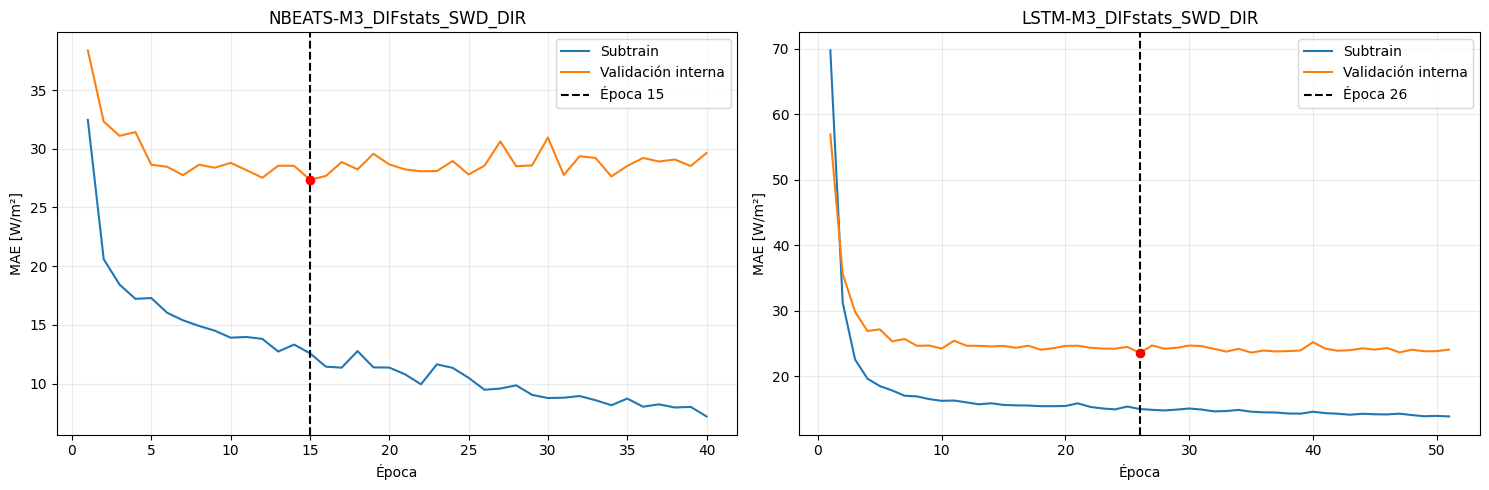


FASE 4B COMPLETADA
Resumen: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/ingenieria_caracteristicas_operacional_20261007T091724Z/02_seleccion_epocas/M3_DIFstats_SWD_DIR_original/resumen_seleccion_M3.csv
Validation externa utilizada: NO


In [ ]:
from google.colab import drive

drive.mount("/content/drive", force_remount=False)
import json
import time
import random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# 1. Configuración y carga desde Drive
SEED = 42
N_SUBTRAIN = 4428
BATCH_SIZE = 128
MAX_EPOCHS = 300
PATIENCE = 25
LR = 1e-3
WEIGHT_DECAY = 1e-5
CLIP = 1.0
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BASE_DIR = Path("/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado")
PUNTERO = BASE_DIR / "resultados/ejecuciones/ULTIMA_INGENIERIA_OPERACIONAL.json"
with open(PUNTERO, "r", encoding="utf-8") as f:
    puntero = json.load(f)

RUTA_M3 = Path(puntero["matrices_M3_original"])
RUN_DIR = RUTA_M3.parents[1]
DIR_SELECCION = RUN_DIR / "02_seleccion_epocas" / "M3_DIFstats_SWD_DIR_original"
DIR_FIGURAS = RUN_DIR / "06_figuras" / "M3_DIFstats_SWD_DIR_original"
DIR_SELECCION.mkdir(parents=True, exist_ok=True)
DIR_FIGURAS.mkdir(parents=True, exist_ok=True)
with np.load(RUTA_M3, allow_pickle=False) as z:
    X = z["X_train_M3"].astype(np.float32)
    y = z["y_train"].astype(np.float32)
    fechas = pd.to_datetime(z["timestamps_train"])
    canales = z["canales_M3"].astype(str).tolist()

assert X.shape == (5149, 24, 10)
assert y.shape == (5149,)
print("Dispositivo:", DEVICE)
print("M3:", X.shape)
print("Canales:", canales)


# 2. Subtrain y validación interna temporal
X_sub_raw = X[:N_SUBTRAIN]
y_sub_raw = y[:N_SUBTRAIN]
X_int_raw = X[N_SUBTRAIN:]
y_int_raw = y[N_SUBTRAIN:]
fechas_sub = fechas[:N_SUBTRAIN]
fechas_int = fechas[N_SUBTRAIN:]

# Escaladores ajustados exclusivamente con subtrain
mx = X_sub_raw.mean(axis=(0, 1), keepdims=True).astype(np.float32)
sx = X_sub_raw.std(axis=(0, 1), keepdims=True).astype(np.float32)
sx = np.where(sx < 1e-8, 1.0, sx)
my = np.float32(y_sub_raw.mean())
sy = np.float32(y_sub_raw.std())
X_sub = ((X_sub_raw - mx) / sx).astype(np.float32)
X_int = ((X_int_raw - mx) / sx).astype(np.float32)
y_sub = ((y_sub_raw - my) / sy).astype(np.float32)
print("\nSubtrain:", X_sub.shape, fechas_sub.min(), "→", fechas_sub.max())
print("Validación interna:", X_int.shape, fechas_int.min(), "→", fechas_int.max())
print("Validation externa utilizada: NO")


# 3. Reproducibilidad
def fijar_semilla():
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


# 4. Arquitectura LSTM
class LSTMRegresor(nn.Module):
    def __init__(self, n_features):
        super().__init__()
        self.lstm = nn.LSTM(input_size=n_features, hidden_size=64, num_layers=1, batch_first=True)
        self.cabeza = nn.Sequential(nn.Linear(64, 32), nn.ReLU(), nn.Linear(32, 1))

    def forward(self, x):
        salida, _ = self.lstm(x)
        return self.cabeza(salida[:, -1, :]).squeeze(-1)


# 5. Arquitectura N-BEATS
class NBeatsBlock(nn.Module):
    def __init__(self, input_size):
        super().__init__()
        self.red = nn.Sequential(
            nn.Linear(input_size, 128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU(),
        )
        self.backcast = nn.Linear(128, 24)
        self.forecast = nn.Linear(128, 1)

    def forward(self, x):
        h = self.red(x)
        return (self.backcast(h), self.forecast(h).squeeze(-1))

class NBeatsMultivariante(nn.Module):
    def __init__(self, n_features):
        super().__init__()

        # 2 stacks × 3 bloques
        self.blocks = nn.ModuleList([NBeatsBlock(24 * n_features) for _ in range(6)])

    def forward(self, x):
        residual = x
        forecast_total = torch.zeros(x.shape[0], device=x.device, dtype=x.dtype)
        for bloque in self.blocks:
            backcast, forecast = bloque(residual.reshape(residual.shape[0], -1))

            # Residual aplicado solo al canal DIF
            residual_DIF = residual[:, :, 0] - backcast
            residual = torch.cat([residual_DIF.unsqueeze(-1), residual[:, :, 1:]], dim=2)
            forecast_total += forecast

        return forecast_total


# 6. Entrenamiento con paciencia 25
X_int_tensor = torch.from_numpy(X_int)

@torch.no_grad()
def predecir(modelo):
    modelo.eval()
    resultado = []
    for inicio in range(0, len(X_int_tensor), 512):
        lote = X_int_tensor[inicio : inicio + 512].to(DEVICE)
        resultado.append(modelo(lote).cpu().numpy())

    pred_escalada = np.concatenate(resultado)
    return pred_escalada * sy + my

def seleccionar(nombre, constructor):
    fijar_semilla()
    dataset = TensorDataset(torch.from_numpy(X_sub), torch.from_numpy(y_sub))
    generador = torch.Generator()
    generador.manual_seed(SEED)
    loader = DataLoader(
        dataset, batch_size=BATCH_SIZE, shuffle=True, generator=generador, num_workers=0
    )
    modelo = constructor().to(DEVICE)
    optimizador = torch.optim.Adam(modelo.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    criterio = nn.L1Loss()
    mejor_mae = np.inf
    mejor_epoca = 0
    mejor_estado = None
    sin_mejora = 0
    historial = []
    inicio = time.perf_counter()
    for epoca in range(1, MAX_EPOCHS + 1):
        modelo.train()
        suma = 0.0
        n = 0
        for xb, yb in loader:
            xb = xb.to(DEVICE)
            yb = yb.to(DEVICE)
            optimizador.zero_grad(set_to_none=True)
            pred = modelo(xb)
            perdida = criterio(pred, yb)
            perdida.backward()
            torch.nn.utils.clip_grad_norm_(modelo.parameters(), CLIP)
            optimizador.step()
            suma += perdida.item() * len(xb)
            n += len(xb)

        train_mae = (suma / n) * float(sy)
        pred_int = predecir(modelo)
        val_mae = float(np.mean(np.abs(y_int_raw - pred_int)))
        historial.append(
            {
                "modelo": nombre,
                "epoca": epoca,
                "train_MAE": train_mae,
                "validation_interna_MAE": val_mae,
            }
        )
        if val_mae < mejor_mae - 1e-8:
            mejor_mae = val_mae
            mejor_epoca = epoca
            sin_mejora = 0
            mejor_estado = {k: v.detach().cpu().clone() for k, v in modelo.state_dict().items()}
        else:
            sin_mejora += 1

        if epoca == 1 or epoca % 10 == 0 or sin_mejora == PATIENCE:
            print(
                f"{nombre:26s} | "
                f"época={epoca:3d} | "
                f"train={train_mae:7.3f} | "
                f"val={val_mae:7.3f} | "
                f"mínimo={mejor_mae:7.3f} "
                f"(época {mejor_epoca}) | "
                f"sin mejora={sin_mejora}"
            )

        if sin_mejora >= PATIENCE:
            break

    tiempo = (time.perf_counter() - inicio) / 60
    historial = pd.DataFrame(historial)
    ruta_historial = DIR_SELECCION / f"historial_{nombre}.csv"
    ruta_checkpoint = DIR_SELECCION / f"checkpoint_subtrain_{nombre}.pt"
    historial.to_csv(ruta_historial, index=False)
    torch.save(
        {
            "modelo": nombre,
            "epoca_seleccionada": mejor_epoca,
            "MAE_interno_minimo": mejor_mae,
            "model_state_dict": mejor_estado,
            "media_X": mx,
            "std_X": sx,
            "media_y": my,
            "std_y": sy,
            "canales": canales,
            "protocolo": "original",
            "seed": SEED,
        },
        ruta_checkpoint,
    )
    return {
        "modelo": nombre,
        "epoca_seleccionada": mejor_epoca,
        "MAE_interno_minimo": mejor_mae,
        "ultima_epoca_ejecutada": int(historial["epoca"].max()),
        "patience": PATIENCE,
        "tiempo_minutos": tiempo,
        "ruta_historial": str(ruta_historial),
        "ruta_checkpoint": str(ruta_checkpoint),
    }, historial


# 7. Ejecutar ambos modelos
configuraciones = {
    "NBEATS-M3_DIFstats_SWD_DIR": (lambda: NBeatsMultivariante(10)),
    "LSTM-M3_DIFstats_SWD_DIR": (lambda: LSTMRegresor(10)),
}
resultados = []
historiales = {}
for nombre, constructor in configuraciones.items():
    print("\n" + "=" * 75)
    print(nombre)
    print("=" * 75)
    resultado, historial = seleccionar(nombre, constructor)
    resultados.append(resultado)
    historiales[nombre] = historial


# 8. Guardar resumen y figura
resumen = pd.DataFrame(resultados).sort_values("MAE_interno_minimo")
RUTA_RESUMEN = DIR_SELECCION / "resumen_seleccion_M3.csv"
resumen.to_csv(RUTA_RESUMEN, index=False)
print("\nRESUMEN DE SELECCIÓN:")
display(resumen)
fig, ejes = plt.subplots(1, 2, figsize=(15, 5))
for eje, (nombre, historia) in zip(ejes, historiales.items()):
    fila = resumen[resumen["modelo"] == nombre].iloc[0]
    epoca_optima = int(fila["epoca_seleccionada"])
    mae_optimo = float(fila["MAE_interno_minimo"])
    eje.plot(historia["epoca"], historia["train_MAE"], label="Subtrain")
    eje.plot(historia["epoca"], historia["validation_interna_MAE"], label="Validación interna")
    eje.axvline(epoca_optima, color="black", linestyle="--", label=f"Época {epoca_optima}")
    eje.scatter(epoca_optima, mae_optimo, color="red", zorder=5)
    eje.set_title(nombre)
    eje.set_xlabel("Época")
    eje.set_ylabel("MAE [W/m²]")
    eje.grid(alpha=0.25)
    eje.legend()

plt.tight_layout()
RUTA_FIGURA = DIR_FIGURAS / "seleccion_epocas_M3.png"
plt.savefig(RUTA_FIGURA, dpi=160, bbox_inches="tight")
plt.show()


# 9. Actualizar puntero
puntero["seleccion_M3_original"] = str(RUTA_RESUMEN)
puntero["figura_seleccion_M3_original"] = str(RUTA_FIGURA)
puntero["fase_actual"] = "fase_4B_seleccion_epocas_M3_completada"
with open(PUNTERO, "w", encoding="utf-8") as f:
    json.dump(puntero, f, ensure_ascii=False, indent=2)

print("\nFASE 4B COMPLETADA")
print("Resumen:", RUTA_RESUMEN)
print("Validation externa utilizada: NO")


NBEATS-M3_DIFstats_SWD_DIR
NBEATS-M3_DIFstats_SWD_DIR   |  1/15 | MAE train=32.4153
NBEATS-M3_DIFstats_SWD_DIR   |  5/15 | MAE train=18.1989
NBEATS-M3_DIFstats_SWD_DIR   | 10/15 | MAE train=15.6853
NBEATS-M3_DIFstats_SWD_DIR   | 15/15 | MAE train=14.2616

LSTM-M3_DIFstats_SWD_DIR
LSTM-M3_DIFstats_SWD_DIR     |  1/26 | MAE train=68.5226
LSTM-M3_DIFstats_SWD_DIR     |  5/26 | MAE train=18.8195
LSTM-M3_DIFstats_SWD_DIR     | 10/26 | MAE train=17.0701
LSTM-M3_DIFstats_SWD_DIR     | 15/26 | MAE train=16.5686
LSTM-M3_DIFstats_SWD_DIR     | 20/26 | MAE train=16.2758
LSTM-M3_DIFstats_SWD_DIR     | 25/26 | MAE train=15.9527
LSTM-M3_DIFstats_SWD_DIR     | 26/26 | MAE train=15.9873

Reentrenamiento terminado:


,modelo,epocas,n_features,tiempo_minutos,ruta_modelo,ruta_historial
0,NBEATS-M3_DIFstats_SWD_DIR,15,10,0.449763,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...
1,LSTM-M3_DIFstats_SWD_DIR,26,10,0.524709,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...



MÉTRICAS OFICIALES EN VALIDATION:


,modelo,version_objetivo,ambito,n,DIF_media,DIF_mediana,MAE,nMAE_pct,RMSE,R2,sesgo
0,LSTM-M3_DIFstats_SWD_DIR,original,total,1464,85.233276,30.591667,15.851081,18.597292,32.192341,0.911344,1.003083
1,NBEATS-M3_DIFstats_SWD_DIR,original,total,1464,85.233276,30.591667,19.418417,22.782671,36.319618,0.887154,4.098596
2,LSTM-M3_DIFstats_SWD_DIR,original,operacion,884,141.797562,127.733337,25.894152,18.261352,41.424832,0.847911,1.889835
3,NBEATS-M3_DIFstats_SWD_DIR,original,operacion,884,141.797562,127.733337,31.569517,22.263794,46.729378,0.806466,6.428900
4,LSTM-M3_DIFstats_SWD_DIR,original,completamente_diurno,765,162.723083,145.683334,29.447914,18.096949,44.498211,0.797484,2.022014
5,NBEATS-M3_DIFstats_SWD_DIR,original,completamente_diurno,765,162.723083,145.683334,35.725552,21.954815,50.162692,0.742643,7.176986
6,LSTM-M3_DIFstats_SWD_DIR,original,transicion,119,7.276421,4.850000,3.048529,41.896000,4.289093,0.634059,1.040113
7,NBEATS-M3_DIFstats_SWD_DIR,original,transicion,119,7.276421,4.850000,4.852170,66.683476,6.715686,0.102858,1.619776
8,LSTM-M3_DIFstats_SWD_DIR,original,noche,580,-0.978506,-1.000000,0.544057,NaN,0.660420,-3.333992,-0.348449
9,NBEATS-M3_DIFstats_SWD_DIR,original,noche,580,-0.978506,-1.000000,0.898461,NaN,1.211145,-13.576068,0.546890


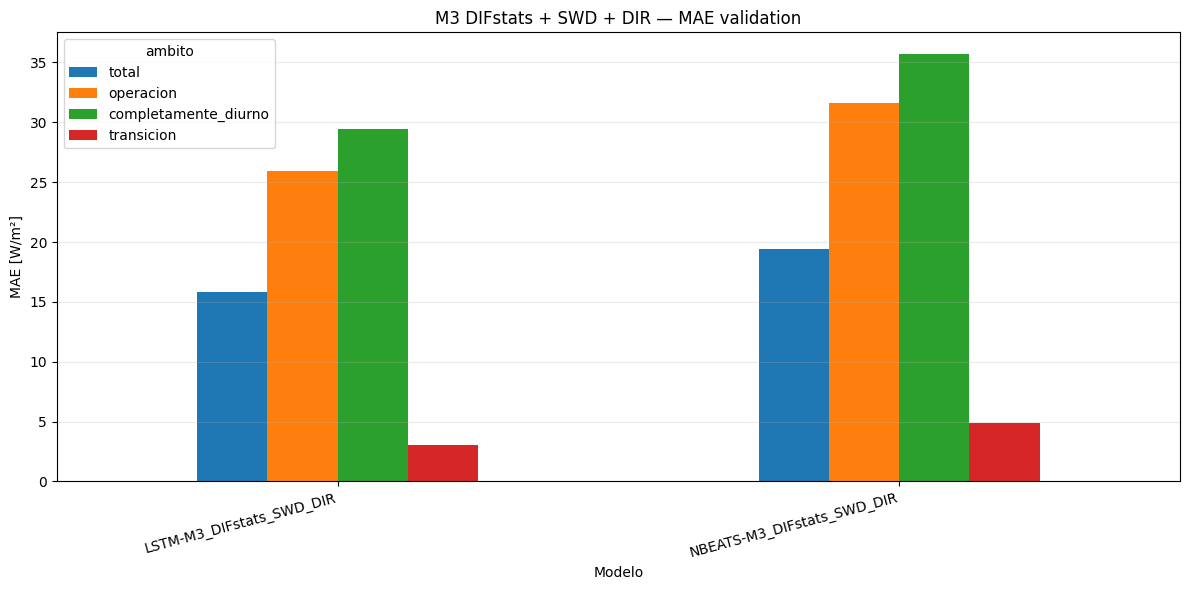


FASE 4C COMPLETADA
Métricas: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/ingenieria_caracteristicas_operacional_20261007T091724Z/05_metricas/M3_DIFstats_SWD_DIR_original/metricas_validation_M3_DIFstats_SWD_DIR.csv
Predicciones: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/ingenieria_caracteristicas_operacional_20261007T091724Z/04_predicciones/M3_DIFstats_SWD_DIR_original/predicciones_validation_M3.csv
Modelos: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/ingenieria_caracteristicas_operacional_20261007T091724Z/03_modelos/M3_DIFstats_SWD_DIR_original
Test utilizado: NO


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Épocas seleccionadas en el subtrain
EPOCAS_M3 = {"NBEATS-M3_DIFstats_SWD_DIR": 15, "LSTM-M3_DIFstats_SWD_DIR": 26}
assert "LSTMRegresor" in globals()
assert "NBeatsMultivariante" in globals()


# 1. Recuperar M3
with np.load(RUTA_M3, allow_pickle=False) as z:
    X_train_raw = z["X_train_M3"].astype(np.float32)
    X_val_raw = z["X_validation_M3"].astype(np.float32)
    y_train_raw = z["y_train"].astype(np.float32)
    y_val_raw = z["y_validation"].astype(np.float32)
    fechas_val = pd.to_datetime(z["timestamps_validation"])
    canales_M3 = z["canales_M3"].astype(str).tolist()

assert X_train_raw.shape == (5149, 24, 10)
assert X_val_raw.shape == (1464, 24, 10)


# 2. Escalado ajustado con todo train
mx_full = X_train_raw.mean(axis=(0, 1), keepdims=True).astype(np.float32)
sx_full = X_train_raw.std(axis=(0, 1), keepdims=True).astype(np.float32)
sx_full = np.where(sx_full < 1e-8, 1.0, sx_full)
my_full = np.float32(y_train_raw.mean())
sy_full = np.float32(y_train_raw.std())
X_train_full = ((X_train_raw - mx_full) / sx_full).astype(np.float32)
X_val = ((X_val_raw - mx_full) / sx_full).astype(np.float32)
y_train_full = ((y_train_raw - my_full) / sy_full).astype(np.float32)
dataset_train = TensorDataset(torch.from_numpy(X_train_full), torch.from_numpy(y_train_full))
X_val_tensor = torch.from_numpy(X_val)


# 3. Directorios
DIR_MODELOS = RUN_DIR / "03_modelos" / "M3_DIFstats_SWD_DIR_original"
DIR_PRED = RUN_DIR / "04_predicciones" / "M3_DIFstats_SWD_DIR_original"
DIR_METRICAS = RUN_DIR / "05_metricas" / "M3_DIFstats_SWD_DIR_original"
DIR_FIGURAS_M3 = RUN_DIR / "06_figuras" / "M3_DIFstats_SWD_DIR_original"
DIR_LOGS = RUN_DIR / "08_logs" / "M3_DIFstats_SWD_DIR_original"
for d in [DIR_MODELOS, DIR_PRED, DIR_METRICAS, DIR_FIGURAS_M3, DIR_LOGS]:
    d.mkdir(parents=True, exist_ok=True)


# 4. Entrenamiento completo
@torch.no_grad()
def predecir_validation(modelo):
    modelo.eval()
    predicciones = []
    for inicio in range(0, len(X_val_tensor), 512):
        lote = X_val_tensor[inicio : inicio + 512].to(DEVICE)
        predicciones.append(modelo(lote).cpu().numpy())

    pred_escalada = np.concatenate(predicciones)
    return (pred_escalada * sy_full + my_full).astype(np.float32)

def reentrenar(nombre, constructor, epocas):
    fijar_semilla()
    generador = torch.Generator()
    generador.manual_seed(SEED)
    loader = DataLoader(
        dataset_train, batch_size=128, shuffle=True, generator=generador, num_workers=0
    )
    modelo = constructor().to(DEVICE)
    optimizador = torch.optim.Adam(modelo.parameters(), lr=1e-3, weight_decay=1e-5)
    criterio = nn.L1Loss()
    historial = []
    inicio = time.perf_counter()
    for epoca in range(1, epocas + 1):
        modelo.train()
        suma = 0.0
        n = 0
        for xb, yb in loader:
            xb = xb.to(DEVICE)
            yb = yb.to(DEVICE)
            optimizador.zero_grad(set_to_none=True)
            pred = modelo(xb)
            perdida = criterio(pred, yb)
            perdida.backward()
            torch.nn.utils.clip_grad_norm_(modelo.parameters(), 1.0)
            optimizador.step()
            suma += perdida.item() * len(xb)
            n += len(xb)

        train_mae = (suma / n) * float(sy_full)
        historial.append({"modelo": nombre, "epoca": epoca, "train_MAE": train_mae})
        if epoca == 1 or epoca % 5 == 0 or epoca == epocas:
            print(f"{nombre:28s} | " f"{epoca:2d}/{epocas} | " f"MAE train={train_mae:.4f}")

    tiempo_minutos = (time.perf_counter() - inicio) / 60
    pred_val = predecir_validation(modelo)
    estado_cpu = {k: v.detach().cpu() for k, v in modelo.state_dict().items()}
    ruta_modelo = DIR_MODELOS / f"{nombre}.pt"
    torch.save(
        {
            "modelo": nombre,
            "configuracion": "M3_DIFstats_SWD_DIR",
            "epocas": epocas,
            "n_features": 10,
            "model_state_dict": estado_cpu,
            "media_X": mx_full,
            "std_X": sx_full,
            "media_y": my_full,
            "std_y": sy_full,
            "canales": canales_M3,
            "seed": SEED,
            "tiempo_minutos": tiempo_minutos,
            "protocolo": "original",
        },
        ruta_modelo,
    )
    historial = pd.DataFrame(historial)
    ruta_historial = DIR_LOGS / f"historial_{nombre}.csv"
    historial.to_csv(ruta_historial, index=False)
    return (
        modelo,
        pred_val,
        {
            "modelo": nombre,
            "epocas": epocas,
            "n_features": 10,
            "tiempo_minutos": tiempo_minutos,
            "ruta_modelo": str(ruta_modelo),
            "ruta_historial": str(ruta_historial),
        },
    )

configuraciones = {
    "NBEATS-M3_DIFstats_SWD_DIR": (lambda: NBeatsMultivariante(10)),
    "LSTM-M3_DIFstats_SWD_DIR": (lambda: LSTMRegresor(10)),
}
predicciones = {}
resumen_entrenamiento = []
for nombre, constructor in configuraciones.items():
    print("\n" + "=" * 75)
    print(nombre)
    print("=" * 75)
    _, pred, resumen = reentrenar(nombre, constructor, EPOCAS_M3[nombre])
    predicciones[nombre] = pred
    resumen_entrenamiento.append(resumen)

resumen_entrenamiento = pd.DataFrame(resumen_entrenamiento)
RUTA_RESUMEN = DIR_LOGS / "resumen_reentrenamiento_M3.csv"
resumen_entrenamiento.to_csv(RUTA_RESUMEN, index=False)
print("\nReentrenamiento terminado:")
display(resumen_entrenamiento)


# 5. Regímenes solares
RUTA_VALIDATION_HGB = (
    BASE_DIR / "documentacion/checkpoint_continuidad_modelado_20261006_125123/"
    "validation_hgb.parquet"
)
validation_hgb = pd.read_parquet(RUTA_VALIDATION_HGB)
regimen = validation_hgb["regimen_solar_objetivo"].astype(str).str.lower().to_numpy()
noche = np.array(["noche" in x for x in regimen])
transicion = np.array(["trans" in x for x in regimen])
diurno = np.array(["complet" in x and "diurn" in x for x in regimen])
mascaras = {
    "total": np.ones(1464, dtype=bool),
    "operacion": ~noche,
    "completamente_diurno": diurno,
    "transicion": transicion,
    "noche": noche,
}
assert {k: int(v.sum()) for k, v in mascaras.items()} == {
    "total": 1464,
    "operacion": 884,
    "completamente_diurno": 765,
    "transicion": 119,
    "noche": 580,
}


# 6. Métricas oficiales
def metricas_modelo(nombre, pred):
    filas = []
    for ambito, mascara in mascaras.items():
        real = y_val_raw[mascara]
        estimado = pred[mascara]
        media = float(real.mean())
        mediana = float(np.median(real))
        mae = float(mean_absolute_error(real, estimado))
        rmse = float(np.sqrt(mean_squared_error(real, estimado)))
        filas.append(
            {
                "modelo": nombre,
                "version_objetivo": "original",
                "ambito": ambito,
                "n": int(mascara.sum()),
                "DIF_media": media,
                "DIF_mediana": mediana,
                "MAE": mae,
                "nMAE_pct": (np.nan if ambito == "noche" or media <= 0 else 100 * mae / media),
                "RMSE": rmse,
                "R2": float(r2_score(real, estimado)),
                "sesgo": float(np.mean(estimado - real)),
            }
        )

    return pd.DataFrame(filas)

metricas = pd.concat(
    [metricas_modelo(nombre, pred) for nombre, pred in predicciones.items()], ignore_index=True
)
orden = {"total": 0, "operacion": 1, "completamente_diurno": 2, "transicion": 3, "noche": 4}
metricas["orden"] = metricas["ambito"].map(orden)
metricas = metricas.sort_values(["orden", "MAE"]).drop(columns="orden").reset_index(drop=True)
RUTA_METRICAS = DIR_METRICAS / "metricas_validation_M3_DIFstats_SWD_DIR.csv"
metricas.to_csv(RUTA_METRICAS, index=False)
print("\nMÉTRICAS OFICIALES EN VALIDATION:")
display(metricas)


# 7. Guardar predicciones
pred_df = pd.DataFrame(
    {"instante_objetivo": fechas_val, "DIF_real": y_val_raw, "regimen_solar": regimen}
)
for nombre, pred in predicciones.items():
    pred_df[f"pred_{nombre}"] = pred

RUTA_PRED = DIR_PRED / "predicciones_validation_M3.csv"
pred_df.to_csv(RUTA_PRED, index=False)


# 8. Figura y puntero
tabla = (
    metricas[metricas["ambito"].isin(["total", "operacion", "completamente_diurno", "transicion"])]
    .pivot(index="modelo", columns="ambito", values="MAE")
    .reindex(columns=["total", "operacion", "completamente_diurno", "transicion"])
)
ax = tabla.plot(kind="bar", figsize=(12, 6))
ax.set_title("M3 DIFstats + SWD + DIR — MAE validation")
ax.set_ylabel("MAE [W/m²]")
ax.set_xlabel("Modelo")
ax.grid(axis="y", alpha=0.25)
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
RUTA_FIGURA_M3 = DIR_FIGURAS_M3 / "comparacion_MAE_validation_M3.png"
plt.savefig(RUTA_FIGURA_M3, dpi=160, bbox_inches="tight")
plt.show()
puntero["modelos_M3_original"] = str(DIR_MODELOS)
puntero["predicciones_M3_original"] = str(RUTA_PRED)
puntero["metricas_M3_original"] = str(RUTA_METRICAS)
puntero["resumen_entrenamiento_M3_original"] = str(RUTA_RESUMEN)
puntero["fase_actual"] = "fase_4C_M3_reentrenado_y_validado"
with open(PUNTERO, "w", encoding="utf-8") as f:
    json.dump(puntero, f, ensure_ascii=False, indent=2)

print("\nFASE 4C COMPLETADA")
print("Métricas:", RUTA_METRICAS)
print("Predicciones:", RUTA_PRED)
print("Modelos:", DIR_MODELOS)
print("Test utilizado: NO")

In [ ]:
DIR_COMPARACION = RUN_DIR / "07_comparaciones" / "comparacion_M1_M2_M3"
DIR_COMPARACION.mkdir(parents=True, exist_ok=True)
ambitos = ["total", "operacion", "completamente_diurno", "transicion", "noche"]
valores = {
    "LSTM-M1_DIFstats": [15.6991575, 25.6981034, 29.2789374, 2.6784556, 0.4593849],
    "LSTM-M2_DIFstats_SWD": [16.200361, 26.109875, 29.501268, 4.308057, 1.096895],
    "LSTM-M3_DIFstats_SWD_DIR": [15.851081, 25.894152, 29.447914, 3.048529, 0.544057],
    "NBEATS-M1_DIFstats": [17.5847804, 28.3322988, 32.0474231, 4.4493571, 1.2040800],
    "NBEATS-M2_DIFstats_SWD": [18.167908, 29.338593, 33.037609, 5.559233, 1.142241],
    "NBEATS-M3_DIFstats_SWD_DIR": [19.418417, 31.569517, 35.725552, 4.852170, 0.898461],
}
filas = []
for modelo, maes in valores.items():
    arquitectura = "LSTM" if modelo.startswith("LSTM") else "NBEATS"
    referencia = valores[f"{arquitectura}-M1_DIFstats"]
    for ambito, mae, mae_base in zip(ambitos, maes, referencia):
        filas.append(
            {
                "modelo": modelo,
                "arquitectura": arquitectura,
                "ambito": ambito,
                "MAE": mae,
                "MAE_M1_referencia": mae_base,
                "diferencia_MAE_vs_M1": mae - mae_base,
                "cambio_pct_vs_M1": (100 * (mae / mae_base - 1)),
                "mejora_vs_M1": mae < mae_base,
            }
        )

comparacion = pd.DataFrame(filas)
RUTA_COMPARACION = DIR_COMPARACION / "comparacion_MAE_M1_M2_M3.csv"
comparacion.to_csv(RUTA_COMPARACION, index=False)
puntero["comparacion_M1_M2_M3"] = str(RUTA_COMPARACION)
puntero["decision_M3"] = "M3 no seleccionado; LSTM-DIFstats continúa como referencia."
with open(PUNTERO, "w", encoding="utf-8") as f:
    json.dump(puntero, f, ensure_ascii=False, indent=2)

display(comparacion.sort_values(["arquitectura", "ambito", "MAE"]))
print("Comparación guardada en:")
print(RUTA_COMPARACION)

,modelo,arquitectura,ambito,MAE,MAE_M1_referencia,diferencia_MAE_vs_M1,cambio_pct_vs_M1,mejora_vs_M1
2,LSTM-M1_DIFstats,LSTM,completamente_diurno,29.278937,29.278937,0.000000,0.000000,False
12,LSTM-M3_DIFstats_SWD_DIR,LSTM,completamente_diurno,29.447914,29.278937,0.168977,0.577127,False
7,LSTM-M2_DIFstats_SWD,LSTM,completamente_diurno,29.501268,29.278937,0.222331,0.759353,False
4,LSTM-M1_DIFstats,LSTM,noche,0.459385,0.459385,0.000000,0.000000,False
14,LSTM-M3_DIFstats_SWD_DIR,LSTM,noche,0.544057,0.459385,0.084672,18.431625,False
9,LSTM-M2_DIFstats_SWD,LSTM,noche,1.096895,0.459385,0.637510,138.774718,False
1,LSTM-M1_DIFstats,LSTM,operacion,25.698103,25.698103,0.000000,0.000000,False
11,LSTM-M3_DIFstats_SWD_DIR,LSTM,operacion,25.894152,25.698103,0.196049,0.762891,False
6,LSTM-M2_DIFstats_SWD,LSTM,operacion,26.109875,25.698103,0.411772,1.602342,False
0,LSTM-M1_DIFstats,LSTM,total,15.699158,15.699158,0.000000,0.000000,False


Comparación guardada en:
/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/ingenieria_caracteristicas_operacional_20261007T091724Z/07_comparaciones/comparacion_M1_M2_M3/comparacion_MAE_M1_M2_M3.csv


**Resultados.** Las épocas seleccionadas son 26 (LSTM) y 15 (N-BEATS).

- La LSTM de M3 obtiene un MAE de 25,89 W/m² en operación y de 3,05 W/m² en transición; reduce el error de M2 en todos los ámbitos, pero supera el de M1 en todos ellos (+0,97 % en total, +0,76 % en operación y +13,82 % en transición).
- La N-BEATS de M3 aumenta el MAE respecto a M1 en operación (31,57 W/m²; +11,43 %) y en transición (4,85 W/m²; +9,05 %), y solo lo reduce en noche (−25,38 %).

### 4.5 DIFstats con SWD, DIR y fracción difusa

M4 (DIFstats + SWD + DIR + fracción difusa) añade a M3 la fracción difusa histórica, cociente entre DIF y SWD, hasta once canales. Se siguen los mismos pasos: selección interna de épocas, reentrenamiento con todo el conjunto de entrenamiento y evaluación en validación.

In [ ]:
from google.colab import drive

drive.mount("/content/drive", force_remount=False)
import json
from pathlib import Path
import numpy as np
import pandas as pd

# 1. Rutas y recuperación de M3
BASE_DIR = Path("/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado")
PUNTERO = BASE_DIR / "resultados/ejecuciones/ULTIMA_INGENIERIA_OPERACIONAL.json"
with open(PUNTERO, "r", encoding="utf-8") as f:
    puntero = json.load(f)

RUTA_M3 = Path(puntero["matrices_M3_original"])
RUN_DIR = RUTA_M3.parents[1]
DIR_DATOS = RUN_DIR / "01_datos"
with np.load(RUTA_M3, allow_pickle=False) as z:
    X_train_M3 = z["X_train_M3"].astype(np.float32)
    X_validation_M3 = z["X_validation_M3"].astype(np.float32)
    y_train = z["y_train"].astype(np.float32)
    y_validation = z["y_validation"].astype(np.float32)
    fechas_train = pd.to_datetime(z["timestamps_train"])
    fechas_validation = pd.to_datetime(z["timestamps_validation"])
    canales_M3 = z["canales_M3"].astype(str).tolist()

assert X_train_M3.shape == (5149, 24, 10)
assert X_validation_M3.shape == (1464, 24, 10)
print("M3 recuperado:", X_train_M3.shape)
print("Canales:", canales_M3)


# 2. Buscar FD/Kd histórica ya calculada
directorios_busqueda = [
    BASE_DIR / "documentacion/checkpoint_continuidad_modelado_20261006_125123",
    RUN_DIR / "01_datos",
]
archivos_npz = []
for directorio in directorios_busqueda:
    if directorio.exists():
        archivos_npz.extend(directorio.rglob("*.npz"))

archivos_npz = list(dict.fromkeys(archivos_npz))

def normalizar_fd(array, n):
    array = np.asarray(array)
    if array.shape == (n, 24, 1):
        array = array[:, :, 0]

    if array.shape != (n, 24):
        return None

    array = array.astype(np.float32)
    if not np.isfinite(array).all():
        return None

    return array

def buscar_fd_guardada(archivos):
    tokens = ["kd", "fd", "fraccion_difusa", "fracciondifusa"]
    for ruta in archivos:
        try:
            with np.load(ruta, allow_pickle=True) as z:
                claves = z.files
                claves_train = [
                    k
                    for k in claves
                    if "train" in k.lower()
                    and any(token in k.lower() for token in tokens)
                    and "validation" not in k.lower()
                    and "val" not in k.lower()
                ]
                claves_validation = [
                    k
                    for k in claves
                    if ("validation" in k.lower() or "val" in k.lower())
                    and any(token in k.lower() for token in tokens)
                ]
                for kt in claves_train:
                    fd_train = normalizar_fd(z[kt], 5149)
                    if fd_train is None:
                        continue

                    for kv in claves_validation:
                        fd_validation = normalizar_fd(z[kv], 1464)
                        if fd_validation is not None:
                            return (fd_train, fd_validation, ruta, kt, kv)

        except Exception:
            continue

    return None

resultado_fd = buscar_fd_guardada(archivos_npz)


# 3. Recuperar o reconstruir FD
if resultado_fd is not None:
    FD_train, FD_validation, ruta_origen, clave_train, clave_validation = resultado_fd
    origen_fd = f"Recuperada de {ruta_origen}; " f"claves {clave_train}, {clave_validation}"
    print("\nFD histórica recuperada:")
    print("Archivo:", ruta_origen)
    print("Train:", clave_train)
    print("Validation:", clave_validation)

else:
    # En M3:
    # canal 0 = DIF_media
    # canal 4 = SWD_media
    DIF_train = X_train_M3[:, :, 0]
    SWD_train = X_train_M3[:, :, 4]
    DIF_validation = X_validation_M3[:, :, 0]
    SWD_validation = X_validation_M3[:, :, 4]
    FD_train = np.zeros_like(DIF_train, dtype=np.float32)
    FD_validation = np.zeros_like(DIF_validation, dtype=np.float32)
    np.divide(DIF_train, SWD_train, out=FD_train, where=SWD_train > 0)
    np.divide(DIF_validation, SWD_validation, out=FD_validation, where=SWD_validation > 0)
    FD_train = np.clip(FD_train, 0.0, 1.0).astype(np.float32)
    FD_validation = np.clip(FD_validation, 0.0, 1.0).astype(np.float32)
    origen_fd = (
        "Reconstruida como clip(DIF_media/SWD_media, 0, 1) "
        "cuando SWD_media > 0; en otro caso FD=0."
    )
    print("\nNo se encontró una matriz FD guardada.")
    print("FD reconstruida de forma determinista.")


# 4. Auditoría de FD
assert FD_train.shape == (5149, 24)
assert FD_validation.shape == (1464, 24)
assert np.isfinite(FD_train).all()
assert np.isfinite(FD_validation).all()
resumen_fd = pd.DataFrame(
    {
        "split": ["train", "validation"],
        "media": [FD_train.mean(), FD_validation.mean()],
        "std": [FD_train.std(), FD_validation.std()],
        "min": [FD_train.min(), FD_validation.min()],
        "mediana": [np.median(FD_train), np.median(FD_validation)],
        "max": [FD_train.max(), FD_validation.max()],
        "porcentaje_cero": [100 * np.mean(FD_train == 0), 100 * np.mean(FD_validation == 0)],
        "porcentaje_uno": [100 * np.mean(FD_train == 1), 100 * np.mean(FD_validation == 1)],
    }
)
print("\nOrigen de FD:")
print(origen_fd)
print("\nResumen de FD:")
display(resumen_fd)


# 5. Construir M4
X_train_M4 = np.concatenate([X_train_M3, FD_train[:, :, None]], axis=2).astype(np.float32)
X_validation_M4 = np.concatenate([X_validation_M3, FD_validation[:, :, None]], axis=2).astype(
    np.float32
)
canales_M4 = canales_M3 + ["fraccion_difusa"]
assert X_train_M4.shape == (5149, 24, 11)
assert X_validation_M4.shape == (1464, 24, 11)
assert not np.isnan(X_train_M4).any()
assert not np.isnan(X_validation_M4).any()
print("\nM4 construido:")
print("X_train_M4:", X_train_M4.shape)
print("X_validation_M4:", X_validation_M4.shape)
print("Canales:", canales_M4)


# 6. Guardar M4 y documentación
RUTA_M4 = DIR_DATOS / "matrices_M4_DIFstats_SWD_DIR_FD_original.npz"
RUTA_DOCUMENTACION_FD = DIR_DATOS / "documentacion_M4_fraccion_difusa.json"
np.savez_compressed(
    RUTA_M4,
    X_train_M4=X_train_M4,
    X_validation_M4=X_validation_M4,
    y_train=y_train,
    y_validation=y_validation,
    timestamps_train=np.asarray(fechas_train.strftime("%Y-%m-%dT%H:%M:%S"), dtype="U19"),
    timestamps_validation=np.asarray(fechas_validation.strftime("%Y-%m-%dT%H:%M:%S"), dtype="U19"),
    canales_M4=np.asarray(canales_M4, dtype="U32"),
)
with open(RUTA_DOCUMENTACION_FD, "w", encoding="utf-8") as f:
    json.dump(
        {
            "modelo": "M4_DIFstats_SWD_DIR_FD",
            "origen_fd": origen_fd,
            "formula_reconstruccion": (
                "clip(DIF_media / SWD_media, 0, 1) si SWD_media > 0; FD=0 en otro caso"
            ),
            "uso_temporal": ("Solo valores históricos T-24 a T-1"),
            "canales": canales_M4,
            "resumen": resumen_fd.to_dict(orient="records"),
        },
        f,
        ensure_ascii=False,
        indent=2,
    )

with np.load(RUTA_M4, allow_pickle=False) as z:
    assert z["X_train_M4"].shape == (5149, 24, 11)
    assert z["X_validation_M4"].shape == (1464, 24, 11)

puntero["matrices_M4_original"] = str(RUTA_M4)
puntero["documentacion_FD_M4"] = str(RUTA_DOCUMENTACION_FD)
puntero["fase_actual"] = "fase_5A_M4_preparado"
with open(PUNTERO, "w", encoding="utf-8") as f:
    json.dump(puntero, f, ensure_ascii=False, indent=2)

print("\nFASE 5A COMPLETADA")
print("Matrices:", RUTA_M4)
print("Documentación:", RUTA_DOCUMENTACION_FD)
print("Siguiente paso: subtrain NBEATS-M4 y LSTM-M4")

M3 recuperado: (5149, 24, 10)
Canales: ['DIF_media', 'elevacion', 'DIF_std', 'DIF_rango', 'SWD_media', 'SWD_std', 'SWD_rango', 'DIR_media', 'DIR_std', 'DIR_rango']

FD histórica recuperada:
Archivo: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/documentacion/checkpoint_continuidad_modelado_20261006_125123/estado_arrays_modelado.npz
Train: kd_train
Validation: kd_validation

Origen de FD:
Recuperada de /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/documentacion/checkpoint_continuidad_modelado_20261006_125123/estado_arrays_modelado.npz; claves kd_train, kd_validation

Resumen de FD:


,split,media,std,min,mediana,max,porcentaje_cero,porcentaje_uno
0,train,0.361719,0.415669,0.0,0.000000,1.172826,50.551078,0.252476
1,validation,0.330751,0.376652,0.0,0.202557,1.200000,47.424294,0.068306



M4 construido:
X_train_M4: (5149, 24, 11)
X_validation_M4: (1464, 24, 11)
Canales: ['DIF_media', 'elevacion', 'DIF_std', 'DIF_rango', 'SWD_media', 'SWD_std', 'SWD_rango', 'DIR_media', 'DIR_std', 'DIR_rango', 'fraccion_difusa']

FASE 5A COMPLETADA
Matrices: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/ingenieria_caracteristicas_operacional_20261007T091724Z/01_datos/matrices_M4_DIFstats_SWD_DIR_FD_original.npz
Documentación: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/ingenieria_caracteristicas_operacional_20261007T091724Z/01_datos/documentacion_M4_fraccion_difusa.json
Siguiente paso: subtrain NBEATS-M4 y LSTM-M4


Dispositivo: cpu
M4: (5149, 24, 11)
Validation externa utilizada: NO
Subtrain: (4428, 24, 11) 2023-12-30 00:00:00 → 2024-07-01 22:00:00
Validación interna: (721, 24, 11) 2024-07-01 23:00:00 → 2024-07-31 23:00:00

NBEATS-M4_DIFstats_SWD_DIR_FD
NBEATS-M4_DIFstats_SWD_DIR_FD  | época=  1 | train= 30.873 | val= 33.744 | mínimo= 33.744 (época 1) | sin mejora=0
NBEATS-M4_DIFstats_SWD_DIR_FD  | época= 10 | train= 14.255 | val= 28.567 | mínimo= 28.028 (época 5) | sin mejora=5
NBEATS-M4_DIFstats_SWD_DIR_FD  | época= 20 | train= 11.506 | val= 27.883 | mínimo= 27.307 (época 16) | sin mejora=4
NBEATS-M4_DIFstats_SWD_DIR_FD  | época= 30 | train=  9.224 | val= 28.857 | mínimo= 27.307 (época 16) | sin mejora=14
NBEATS-M4_DIFstats_SWD_DIR_FD  | época= 40 | train=  7.395 | val= 29.399 | mínimo= 27.307 (época 16) | sin mejora=24
NBEATS-M4_DIFstats_SWD_DIR_FD  | época= 41 | train=  7.009 | val= 28.890 | mínimo= 27.307 (época 16) | sin mejora=25

LSTM-M4_DIFstats_SWD_DIR_FD
LSTM-M4_DIFstats_SWD_DIR_FD    

,modelo,epoca_seleccionada,MAE_interno_minimo,ultima_epoca_ejecutada,patience,tiempo_minutos,ruta_historial,ruta_checkpoint
1,LSTM-M4_DIFstats_SWD_DIR_FD,35,23.590500,60,25,1.002069,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...
0,NBEATS-M4_DIFstats_SWD_DIR_FD,16,27.306995,41,25,0.800461,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...


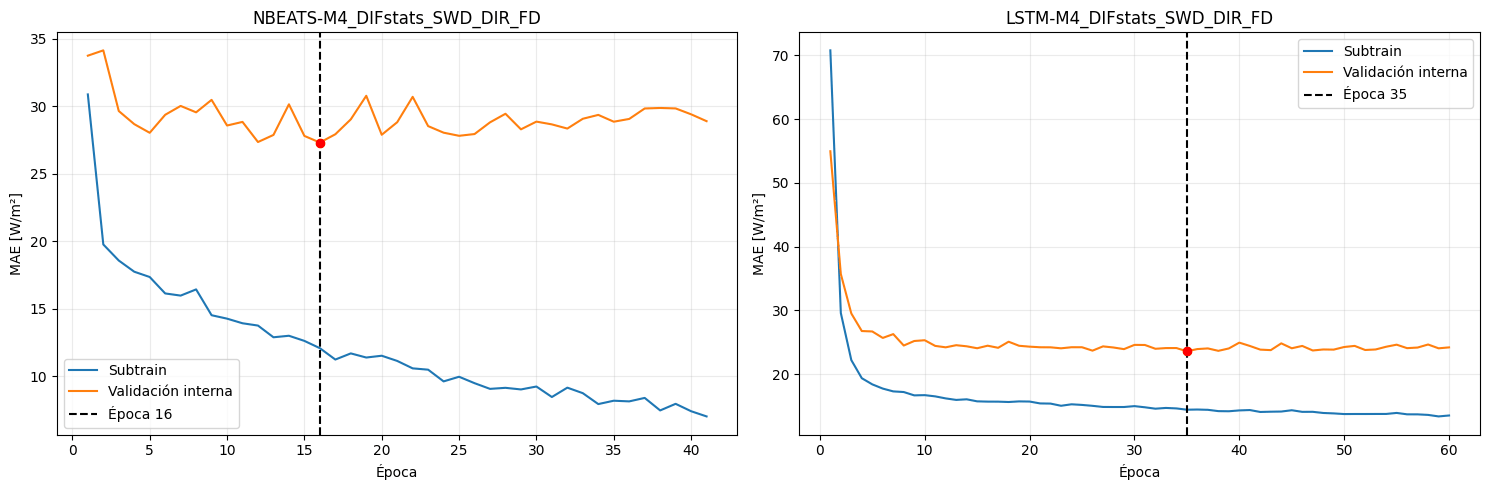


FASE 5B COMPLETADA
Resumen: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/ingenieria_caracteristicas_operacional_20261007T091724Z/02_seleccion_epocas/M4_DIFstats_SWD_DIR_FD_original/resumen_seleccion_M4.csv
Validation externa utilizada: NO


In [ ]:
import time
import random
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# 1. Configuración y carga de M4
SEED = 42
N_SUBTRAIN = 4428
BATCH_SIZE = 128
MAX_EPOCHS = 300
PATIENCE = 25
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
assert "LSTMRegresor" in globals()
assert "NBeatsMultivariante" in globals()
with open(PUNTERO, "r", encoding="utf-8") as f:
    puntero = json.load(f)

RUTA_M4 = Path(puntero["matrices_M4_original"])
RUN_DIR = RUTA_M4.parents[1]
DIR_SELECCION = RUN_DIR / "02_seleccion_epocas" / "M4_DIFstats_SWD_DIR_FD_original"
DIR_FIGURAS = RUN_DIR / "06_figuras" / "M4_DIFstats_SWD_DIR_FD_original"
DIR_SELECCION.mkdir(parents=True, exist_ok=True)
DIR_FIGURAS.mkdir(parents=True, exist_ok=True)
with np.load(RUTA_M4, allow_pickle=False) as z:
    X = z["X_train_M4"].astype(np.float32)
    y = z["y_train"].astype(np.float32)
    fechas = pd.to_datetime(z["timestamps_train"])
    canales_M4 = z["canales_M4"].astype(str).tolist()

assert X.shape == (5149, 24, 11)
assert y.shape == (5149,)
print("Dispositivo:", DEVICE)
print("M4:", X.shape)
print("Validation externa utilizada: NO")


# 2. División temporal interna y escalado
X_sub_raw = X[:N_SUBTRAIN]
y_sub_raw = y[:N_SUBTRAIN]
X_int_raw = X[N_SUBTRAIN:]
y_int_raw = y[N_SUBTRAIN:]
mx = X_sub_raw.mean(axis=(0, 1), keepdims=True).astype(np.float32)
sx = X_sub_raw.std(axis=(0, 1), keepdims=True).astype(np.float32)
sx = np.where(sx < 1e-8, 1.0, sx)
my = np.float32(y_sub_raw.mean())
sy = np.float32(y_sub_raw.std())
X_sub = ((X_sub_raw - mx) / sx).astype(np.float32)
X_int = ((X_int_raw - mx) / sx).astype(np.float32)
y_sub = ((y_sub_raw - my) / sy).astype(np.float32)
X_int_tensor = torch.from_numpy(X_int)
print("Subtrain:", X_sub.shape, fechas[:N_SUBTRAIN].min(), "→", fechas[:N_SUBTRAIN].max())
print("Validación interna:", X_int.shape, fechas[N_SUBTRAIN:].min(), "→", fechas[N_SUBTRAIN:].max())


# 3. Funciones de entrenamiento
def fijar_semilla_M4():
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

@torch.no_grad()
def predecir_interna_M4(modelo):
    modelo.eval()
    predicciones = []
    for inicio in range(0, len(X_int_tensor), 512):
        lote = X_int_tensor[inicio : inicio + 512].to(DEVICE)
        predicciones.append(modelo(lote).cpu().numpy())

    pred_escalada = np.concatenate(predicciones)
    return pred_escalada * sy + my

def seleccionar_M4(nombre, constructor):
    fijar_semilla_M4()
    dataset = TensorDataset(torch.from_numpy(X_sub), torch.from_numpy(y_sub))
    generador = torch.Generator()
    generador.manual_seed(SEED)
    loader = DataLoader(
        dataset, batch_size=BATCH_SIZE, shuffle=True, generator=generador, num_workers=0
    )
    modelo = constructor().to(DEVICE)
    optimizador = torch.optim.Adam(modelo.parameters(), lr=1e-3, weight_decay=1e-5)
    criterio = nn.L1Loss()
    mejor_mae = np.inf
    mejor_epoca = 0
    mejor_estado = None
    sin_mejora = 0
    historial = []
    inicio_total = time.perf_counter()
    for epoca in range(1, MAX_EPOCHS + 1):
        modelo.train()
        suma = 0.0
        n = 0
        for xb, yb in loader:
            xb = xb.to(DEVICE)
            yb = yb.to(DEVICE)
            optimizador.zero_grad(set_to_none=True)
            pred = modelo(xb)
            perdida = criterio(pred, yb)
            perdida.backward()
            torch.nn.utils.clip_grad_norm_(modelo.parameters(), 1.0)
            optimizador.step()
            suma += perdida.item() * len(xb)
            n += len(xb)

        train_mae = (suma / n) * float(sy)
        pred_interna = predecir_interna_M4(modelo)
        val_mae = float(np.mean(np.abs(y_int_raw - pred_interna)))
        historial.append(
            {
                "modelo": nombre,
                "epoca": epoca,
                "train_MAE": train_mae,
                "validation_interna_MAE": val_mae,
            }
        )
        if val_mae < mejor_mae - 1e-8:
            mejor_mae = val_mae
            mejor_epoca = epoca
            sin_mejora = 0
            mejor_estado = {k: v.detach().cpu().clone() for k, v in modelo.state_dict().items()}
        else:
            sin_mejora += 1

        if epoca == 1 or epoca % 10 == 0 or sin_mejora == PATIENCE:
            print(
                f"{nombre:30s} | "
                f"época={epoca:3d} | "
                f"train={train_mae:7.3f} | "
                f"val={val_mae:7.3f} | "
                f"mínimo={mejor_mae:7.3f} "
                f"(época {mejor_epoca}) | "
                f"sin mejora={sin_mejora}"
            )

        if sin_mejora >= PATIENCE:
            break

    tiempo_minutos = (time.perf_counter() - inicio_total) / 60
    historial = pd.DataFrame(historial)
    ruta_historial = DIR_SELECCION / f"historial_{nombre}.csv"
    ruta_checkpoint = DIR_SELECCION / f"checkpoint_subtrain_{nombre}.pt"
    historial.to_csv(ruta_historial, index=False)
    torch.save(
        {
            "modelo": nombre,
            "epoca_seleccionada": mejor_epoca,
            "MAE_interno_minimo": mejor_mae,
            "model_state_dict": mejor_estado,
            "media_X": mx,
            "std_X": sx,
            "media_y": my,
            "std_y": sy,
            "canales": canales_M4,
            "seed": SEED,
            "patience": PATIENCE,
            "protocolo": "original",
        },
        ruta_checkpoint,
    )
    return {
        "modelo": nombre,
        "epoca_seleccionada": mejor_epoca,
        "MAE_interno_minimo": mejor_mae,
        "ultima_epoca_ejecutada": int(historial["epoca"].max()),
        "patience": PATIENCE,
        "tiempo_minutos": tiempo_minutos,
        "ruta_historial": str(ruta_historial),
        "ruta_checkpoint": str(ruta_checkpoint),
    }, historial


# 4. Selección de los dos modelos
configuraciones = {
    "NBEATS-M4_DIFstats_SWD_DIR_FD": (lambda: NBeatsMultivariante(11)),
    "LSTM-M4_DIFstats_SWD_DIR_FD": (lambda: LSTMRegresor(11)),
}
resultados = []
historiales = {}
for nombre, constructor in configuraciones.items():
    print("\n" + "=" * 78)
    print(nombre)
    print("=" * 78)
    resultado, historial = seleccionar_M4(nombre, constructor)
    resultados.append(resultado)
    historiales[nombre] = historial


# 5. Guardar resumen y figura
resumen_M4 = pd.DataFrame(resultados).sort_values("MAE_interno_minimo")
RUTA_RESUMEN_M4 = DIR_SELECCION / "resumen_seleccion_M4.csv"
resumen_M4.to_csv(RUTA_RESUMEN_M4, index=False)
print("\nRESUMEN DE SELECCIÓN M4:")
display(resumen_M4)
fig, ejes = plt.subplots(1, 2, figsize=(15, 5))
for eje, (nombre, historia) in zip(ejes, historiales.items()):
    fila = resumen_M4[resumen_M4["modelo"] == nombre].iloc[0]
    epoca_optima = int(fila["epoca_seleccionada"])
    mae_optimo = float(fila["MAE_interno_minimo"])
    eje.plot(historia["epoca"], historia["train_MAE"], label="Subtrain")
    eje.plot(historia["epoca"], historia["validation_interna_MAE"], label="Validación interna")
    eje.axvline(epoca_optima, color="black", linestyle="--", label=f"Época {epoca_optima}")
    eje.scatter(epoca_optima, mae_optimo, color="red", zorder=5)
    eje.set_title(nombre)
    eje.set_xlabel("Época")
    eje.set_ylabel("MAE [W/m²]")
    eje.grid(alpha=0.25)
    eje.legend()

plt.tight_layout()
RUTA_FIGURA_M4 = DIR_FIGURAS / "seleccion_epocas_M4.png"
plt.savefig(RUTA_FIGURA_M4, dpi=160, bbox_inches="tight")
plt.show()


# 6. Actualizar puntero
puntero["seleccion_M4_original"] = str(RUTA_RESUMEN_M4)
puntero["figura_seleccion_M4_original"] = str(RUTA_FIGURA_M4)
puntero["fase_actual"] = "fase_5B_seleccion_epocas_M4_completada"
with open(PUNTERO, "w", encoding="utf-8") as f:
    json.dump(puntero, f, ensure_ascii=False, indent=2)

print("\nFASE 5B COMPLETADA")
print("Resumen:", RUTA_RESUMEN_M4)
print("Validation externa utilizada: NO")


NBEATS-M4_DIFstats_SWD_DIR_FD
NBEATS-M4_DIFstats_SWD_DIR_FD    |  1/16 | MAE train=30.9347
NBEATS-M4_DIFstats_SWD_DIR_FD    |  5/16 | MAE train=17.4875
NBEATS-M4_DIFstats_SWD_DIR_FD    | 10/16 | MAE train=15.3485
NBEATS-M4_DIFstats_SWD_DIR_FD    | 15/16 | MAE train=14.2960
NBEATS-M4_DIFstats_SWD_DIR_FD    | 16/16 | MAE train=13.0919

LSTM-M4_DIFstats_SWD_DIR_FD
LSTM-M4_DIFstats_SWD_DIR_FD      |  1/35 | MAE train=69.5411
LSTM-M4_DIFstats_SWD_DIR_FD      |  5/35 | MAE train=19.0165
LSTM-M4_DIFstats_SWD_DIR_FD      | 10/35 | MAE train=17.2609
LSTM-M4_DIFstats_SWD_DIR_FD      | 15/35 | MAE train=16.8037
LSTM-M4_DIFstats_SWD_DIR_FD      | 20/35 | MAE train=16.3547
LSTM-M4_DIFstats_SWD_DIR_FD      | 25/35 | MAE train=16.2604
LSTM-M4_DIFstats_SWD_DIR_FD      | 30/35 | MAE train=15.7288
LSTM-M4_DIFstats_SWD_DIR_FD      | 35/35 | MAE train=15.3562


,modelo,epocas,n_features,tiempo_minutos,ruta_modelo,ruta_historial
0,NBEATS-M4_DIFstats_SWD_DIR_FD,16,11,0.483453,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...
1,LSTM-M4_DIFstats_SWD_DIR_FD,35,11,0.676825,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...



MÉTRICAS OFICIALES EN VALIDATION:


,modelo,version_objetivo,ambito,n,DIF_media,DIF_mediana,MAE,nMAE_pct,RMSE,R2,sesgo
0,LSTM-M4_DIFstats_SWD_DIR_FD,original,total,1464,85.233276,30.591667,16.081457,18.867581,32.786614,0.908040,2.583636
1,NBEATS-M4_DIFstats_SWD_DIR_FD,original,total,1464,85.233276,30.591667,18.934723,22.215177,35.419633,0.892677,-1.005930
2,LSTM-M4_DIFstats_SWD_DIR_FD,original,operacion,884,141.797562,127.733337,26.185265,18.466654,42.182666,0.842295,3.883303
3,NBEATS-M4_DIFstats_SWD_DIR_FD,original,operacion,884,141.797562,127.733337,30.695801,21.647622,45.566208,0.815981,-1.611593
4,LSTM-M4_DIFstats_SWD_DIR_FD,original,completamente_diurno,765,162.723083,145.683334,29.440477,18.092379,45.270309,0.790395,3.739961
5,NBEATS-M4_DIFstats_SWD_DIR_FD,original,completamente_diurno,765,162.723083,145.683334,34.604855,21.266101,48.889561,0.755541,-1.972211
6,LSTM-M4_DIFstats_SWD_DIR_FD,original,transicion,119,7.276421,4.850000,5.258904,72.273216,6.596304,0.134471,4.804790
7,NBEATS-M4_DIFstats_SWD_DIR_FD,original,transicion,119,7.276421,4.850000,5.566171,76.495995,7.634506,-0.159424,0.706662
8,LSTM-M4_DIFstats_SWD_DIR_FD,original,noche,580,-0.978506,-1.000000,0.681863,NaN,1.155888,-12.276376,0.602763
9,NBEATS-M4_DIFstats_SWD_DIR_FD,original,noche,580,-0.978506,-1.000000,1.009214,NaN,1.456854,-20.090153,-0.082816


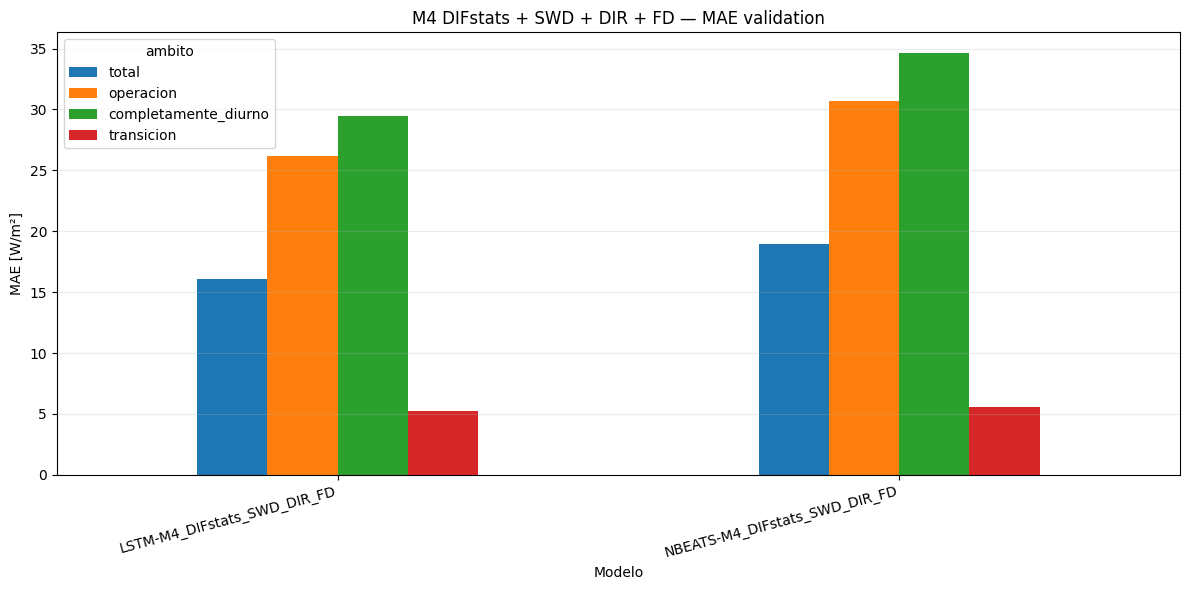


FASE 5C COMPLETADA
Métricas: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/ingenieria_caracteristicas_operacional_20261007T091724Z/05_metricas/M4_DIFstats_SWD_DIR_FD_original/metricas_validation_M4_DIFstats_SWD_DIR_FD.csv
Predicciones: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/ingenieria_caracteristicas_operacional_20261007T091724Z/04_predicciones/M4_DIFstats_SWD_DIR_FD_original/predicciones_validation_M4.csv
Modelos: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/ingenieria_caracteristicas_operacional_20261007T091724Z/03_modelos/M4_DIFstats_SWD_DIR_FD_original
Test utilizado: NO


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

EPOCAS_M4 = {"NBEATS-M4_DIFstats_SWD_DIR_FD": 16, "LSTM-M4_DIFstats_SWD_DIR_FD": 35}


# 1. Cargar M4 y ajustar escaladores con todo train
with np.load(RUTA_M4, allow_pickle=False) as z:
    X_train_raw = z["X_train_M4"].astype(np.float32)
    X_val_raw = z["X_validation_M4"].astype(np.float32)
    y_train_raw = z["y_train"].astype(np.float32)
    y_val_raw = z["y_validation"].astype(np.float32)
    fechas_val = pd.to_datetime(z["timestamps_validation"])
    canales_M4 = z["canales_M4"].astype(str).tolist()

assert X_train_raw.shape == (5149, 24, 11)
assert X_val_raw.shape == (1464, 24, 11)
mx_full = X_train_raw.mean(axis=(0, 1), keepdims=True).astype(np.float32)
sx_full = X_train_raw.std(axis=(0, 1), keepdims=True).astype(np.float32)
sx_full = np.where(sx_full < 1e-8, 1.0, sx_full)
my_full = np.float32(y_train_raw.mean())
sy_full = np.float32(y_train_raw.std())
X_train_full = ((X_train_raw - mx_full) / sx_full).astype(np.float32)
X_val = ((X_val_raw - mx_full) / sx_full).astype(np.float32)
y_train_full = ((y_train_raw - my_full) / sy_full).astype(np.float32)
dataset_train = TensorDataset(torch.from_numpy(X_train_full), torch.from_numpy(y_train_full))
X_val_tensor = torch.from_numpy(X_val)


# 2. Directorios
DIR_MODELOS_M4 = RUN_DIR / "03_modelos" / "M4_DIFstats_SWD_DIR_FD_original"
DIR_PRED_M4 = RUN_DIR / "04_predicciones" / "M4_DIFstats_SWD_DIR_FD_original"
DIR_METRICAS_M4 = RUN_DIR / "05_metricas" / "M4_DIFstats_SWD_DIR_FD_original"
DIR_FIGURAS_M4 = RUN_DIR / "06_figuras" / "M4_DIFstats_SWD_DIR_FD_original"
DIR_LOGS_M4 = RUN_DIR / "08_logs" / "M4_DIFstats_SWD_DIR_FD_original"
for d in [DIR_MODELOS_M4, DIR_PRED_M4, DIR_METRICAS_M4, DIR_FIGURAS_M4, DIR_LOGS_M4]:
    d.mkdir(parents=True, exist_ok=True)


# 3. Entrenamiento completo
@torch.no_grad()
def predecir_validation_M4(modelo):
    modelo.eval()
    resultado = []
    for inicio in range(0, len(X_val_tensor), 512):
        lote = X_val_tensor[inicio : inicio + 512].to(DEVICE)
        resultado.append(modelo(lote).cpu().numpy())

    pred_escalada = np.concatenate(resultado)
    return (pred_escalada * sy_full + my_full).astype(np.float32)

def reentrenar_M4(nombre, constructor, epocas):
    fijar_semilla_M4()
    generador = torch.Generator()
    generador.manual_seed(SEED)
    loader = DataLoader(
        dataset_train, batch_size=128, shuffle=True, generator=generador, num_workers=0
    )
    modelo = constructor().to(DEVICE)
    optimizador = torch.optim.Adam(modelo.parameters(), lr=1e-3, weight_decay=1e-5)
    criterio = nn.L1Loss()
    historial = []
    inicio_total = time.perf_counter()
    for epoca in range(1, epocas + 1):
        modelo.train()
        suma = 0.0
        n = 0
        for xb, yb in loader:
            xb = xb.to(DEVICE)
            yb = yb.to(DEVICE)
            optimizador.zero_grad(set_to_none=True)
            pred = modelo(xb)
            perdida = criterio(pred, yb)
            perdida.backward()
            torch.nn.utils.clip_grad_norm_(modelo.parameters(), 1.0)
            optimizador.step()
            suma += perdida.item() * len(xb)
            n += len(xb)

        train_mae = (suma / n) * float(sy_full)
        historial.append({"modelo": nombre, "epoca": epoca, "train_MAE": train_mae})
        if epoca == 1 or epoca % 5 == 0 or epoca == epocas:
            print(f"{nombre:32s} | " f"{epoca:2d}/{epocas} | " f"MAE train={train_mae:.4f}")

    tiempo_minutos = (time.perf_counter() - inicio_total) / 60
    pred_val = predecir_validation_M4(modelo)
    ruta_modelo = DIR_MODELOS_M4 / f"{nombre}.pt"
    estado_cpu = {k: v.detach().cpu() for k, v in modelo.state_dict().items()}
    torch.save(
        {
            "modelo": nombre,
            "configuracion": "M4_DIFstats_SWD_DIR_FD",
            "epocas": epocas,
            "n_features": 11,
            "model_state_dict": estado_cpu,
            "media_X": mx_full,
            "std_X": sx_full,
            "media_y": my_full,
            "std_y": sy_full,
            "canales": canales_M4,
            "seed": SEED,
            "tiempo_minutos": tiempo_minutos,
            "protocolo": "original",
        },
        ruta_modelo,
    )
    historial = pd.DataFrame(historial)
    ruta_historial = DIR_LOGS_M4 / f"historial_{nombre}.csv"
    historial.to_csv(ruta_historial, index=False)
    return pred_val, {
        "modelo": nombre,
        "epocas": epocas,
        "n_features": 11,
        "tiempo_minutos": tiempo_minutos,
        "ruta_modelo": str(ruta_modelo),
        "ruta_historial": str(ruta_historial),
    }

configuraciones = {
    "NBEATS-M4_DIFstats_SWD_DIR_FD": (lambda: NBeatsMultivariante(11)),
    "LSTM-M4_DIFstats_SWD_DIR_FD": (lambda: LSTMRegresor(11)),
}
predicciones_M4 = {}
resumen_entrenamiento_M4 = []
for nombre, constructor in configuraciones.items():
    print("\n" + "=" * 80)
    print(nombre)
    print("=" * 80)
    pred, resumen = reentrenar_M4(nombre, constructor, EPOCAS_M4[nombre])
    predicciones_M4[nombre] = pred
    resumen_entrenamiento_M4.append(resumen)

resumen_entrenamiento_M4 = pd.DataFrame(resumen_entrenamiento_M4)
RUTA_RESUMEN_M4 = DIR_LOGS_M4 / "resumen_reentrenamiento_M4.csv"
resumen_entrenamiento_M4.to_csv(RUTA_RESUMEN_M4, index=False)
display(resumen_entrenamiento_M4)


# 4. Regímenes solares
RUTA_VALIDATION_HGB = (
    BASE_DIR / "documentacion/checkpoint_continuidad_modelado_20261006_125123/"
    "validation_hgb.parquet"
)
validation_hgb = pd.read_parquet(RUTA_VALIDATION_HGB)
regimen = validation_hgb["regimen_solar_objetivo"].astype(str).str.lower().to_numpy()
noche = np.array(["noche" in x for x in regimen])
transicion = np.array(["trans" in x for x in regimen])
diurno = np.array(["complet" in x and "diurn" in x for x in regimen])
mascaras = {
    "total": np.ones(1464, dtype=bool),
    "operacion": ~noche,
    "completamente_diurno": diurno,
    "transicion": transicion,
    "noche": noche,
}
assert {k: int(v.sum()) for k, v in mascaras.items()} == {
    "total": 1464,
    "operacion": 884,
    "completamente_diurno": 765,
    "transicion": 119,
    "noche": 580,
}


# 5. Métricas oficiales
def calcular_metricas_M4(nombre, pred):
    filas = []
    for ambito, mascara in mascaras.items():
        real = y_val_raw[mascara]
        estimado = pred[mascara]
        media = float(real.mean())
        mae = float(mean_absolute_error(real, estimado))
        filas.append(
            {
                "modelo": nombre,
                "version_objetivo": "original",
                "ambito": ambito,
                "n": int(mascara.sum()),
                "DIF_media": media,
                "DIF_mediana": float(np.median(real)),
                "MAE": mae,
                "nMAE_pct": (np.nan if ambito == "noche" or media <= 0 else 100 * mae / media),
                "RMSE": float(np.sqrt(mean_squared_error(real, estimado))),
                "R2": float(r2_score(real, estimado)),
                "sesgo": float(np.mean(estimado - real)),
            }
        )

    return pd.DataFrame(filas)

metricas_M4 = pd.concat(
    [calcular_metricas_M4(nombre, pred) for nombre, pred in predicciones_M4.items()],
    ignore_index=True,
)
orden = {"total": 0, "operacion": 1, "completamente_diurno": 2, "transicion": 3, "noche": 4}
metricas_M4["orden"] = metricas_M4["ambito"].map(orden)
metricas_M4 = metricas_M4.sort_values(["orden", "MAE"]).drop(columns="orden").reset_index(drop=True)
RUTA_METRICAS_M4 = DIR_METRICAS_M4 / "metricas_validation_M4_DIFstats_SWD_DIR_FD.csv"
metricas_M4.to_csv(RUTA_METRICAS_M4, index=False)
print("\nMÉTRICAS OFICIALES EN VALIDATION:")
display(metricas_M4)


# 6. Guardar predicciones y figura
pred_df = pd.DataFrame(
    {"instante_objetivo": fechas_val, "DIF_real": y_val_raw, "regimen_solar": regimen}
)
for nombre, pred in predicciones_M4.items():
    pred_df[f"pred_{nombre}"] = pred

RUTA_PREDICCIONES_M4 = DIR_PRED_M4 / "predicciones_validation_M4.csv"
pred_df.to_csv(RUTA_PREDICCIONES_M4, index=False)
tabla = (
    metricas_M4[
        metricas_M4["ambito"].isin(["total", "operacion", "completamente_diurno", "transicion"])
    ]
    .pivot(index="modelo", columns="ambito", values="MAE")
    .reindex(columns=["total", "operacion", "completamente_diurno", "transicion"])
)
ax = tabla.plot(kind="bar", figsize=(12, 6))
ax.set_title("M4 DIFstats + SWD + DIR + FD — MAE validation")
ax.set_ylabel("MAE [W/m²]")
ax.set_xlabel("Modelo")
ax.grid(axis="y", alpha=0.25)
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
RUTA_FIGURA_M4_FINAL = DIR_FIGURAS_M4 / "comparacion_MAE_validation_M4.png"
plt.savefig(RUTA_FIGURA_M4_FINAL, dpi=160, bbox_inches="tight")
plt.show()


# 7. Actualizar puntero
puntero["modelos_M4_original"] = str(DIR_MODELOS_M4)
puntero["predicciones_M4_original"] = str(RUTA_PREDICCIONES_M4)
puntero["metricas_M4_original"] = str(RUTA_METRICAS_M4)
puntero["resumen_entrenamiento_M4_original"] = str(RUTA_RESUMEN_M4)
puntero["fase_actual"] = "fase_5C_M4_reentrenado_y_validado"
with open(PUNTERO, "w", encoding="utf-8") as f:
    json.dump(puntero, f, ensure_ascii=False, indent=2)

print("\nFASE 5C COMPLETADA")
print("Métricas:", RUTA_METRICAS_M4)
print("Predicciones:", RUTA_PREDICCIONES_M4)
print("Modelos:", DIR_MODELOS_M4)
print("Test utilizado: NO")

**Resultados.** Se seleccionan 35 épocas para la LSTM y 16 para la N-BEATS. La LSTM de M4 obtiene un MAE de 16,08 W/m² en total, 26,19 W/m² en operación, 29,44 W/m² en horas completamente diurnas y 5,26 W/m² en transición, con sesgo positivo en este último ámbito (4,80 W/m²). La N-BEATS de M4 alcanza 18,93, 30,70, 34,60 y 5,57 W/m², respectivamente. Respecto a M3, el MAE de transición aumenta en ambas arquitecturas.

### 4.6 Comparación de las combinaciones radiométricas

Se reúnen las métricas de validación de M1 (DIFstats), M2 (+ SWD), M3 (+ SWD y DIR) y M4 (+ SWD, DIR y fracción difusa) para la LSTM y la N-BEATS, y se calcula el cambio porcentual del MAE de cada combinación respecto a M1 en cada ámbito.

In [ ]:
import json
from pathlib import Path
import numpy as np
import pandas as pd

# 1. Recuperar rutas
BASE_DIR = Path("/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado")
PUNTERO = BASE_DIR / "resultados/ejecuciones/ULTIMA_INGENIERIA_OPERACIONAL.json"
with open(PUNTERO, "r", encoding="utf-8") as f:
    puntero = json.load(f)

RUTA_RANKING_HISTORICO = (
    BASE_DIR / "resultados/comparativas/"
    "rankings_completos_modelos_20261007T082325Z/"
    "ranking_completo_formato_largo.csv"
)
rutas_nuevas = {
    "M2": Path(puntero["metricas_M2_original"]),
    "M3": Path(puntero["metricas_M3_original"]),
    "M4": Path(puntero["metricas_M4_original"]),
}
assert RUTA_RANKING_HISTORICO.exists()
for bloque, ruta in rutas_nuevas.items():
    assert ruta.exists(), f"No existe {bloque}: {ruta}"


# 2. Recuperar M1-DIFstats histórico
ranking_historico = pd.read_csv(RUTA_RANKING_HISTORICO)
M1 = ranking_historico[
    ranking_historico["modelo"].isin(["LSTM-DIFstats", "NBEATS-DIFstats"])
].copy()
M1["ambito"] = M1["ambito"].replace({"global": "total"})
M1["bloque"] = "M1"
M1["configuracion"] = "DIFstats"
M1["version_objetivo"] = "original"
M1["arquitectura"] = np.where(M1["modelo"].str.startswith("LSTM"), "LSTM", "NBEATS")
if "bias" in M1.columns:
    M1["sesgo"] = M1["bias"]


# 3. Cargar M2, M3 y M4
tablas = []
for bloque, ruta in rutas_nuevas.items():
    df = pd.read_csv(ruta)
    df["bloque"] = bloque
    df["arquitectura"] = np.where(df["modelo"].str.startswith("LSTM"), "LSTM", "NBEATS")
    configuraciones = {
        "M2": "DIFstats + SWD",
        "M3": "DIFstats + SWD + DIR",
        "M4": "DIFstats + SWD + DIR + FD",
    }
    df["configuracion"] = configuraciones[bloque]
    tablas.append(df)

metricas_nuevas = pd.concat(tablas, ignore_index=True)


# 4. Añadir n, DIF media y DIF mediana a M1
referencia_ambitos = metricas_nuevas[metricas_nuevas["bloque"] == "M4"][
    ["ambito", "n", "DIF_media", "DIF_mediana"]
].drop_duplicates("ambito")
M1 = M1.merge(referencia_ambitos, on="ambito", how="left", suffixes=("", "_referencia"))

# Evitar nMAE nocturno, porque la media de DIF es negativa.
M1.loc[M1["ambito"] == "noche", "nMAE_pct"] = np.nan


# 5. Tabla completa unificada
columnas_oficiales = [
    "modelo",
    "arquitectura",
    "bloque",
    "configuracion",
    "version_objetivo",
    "ambito",
    "n",
    "DIF_media",
    "DIF_mediana",
    "MAE",
    "nMAE_pct",
    "RMSE",
    "R2",
    "sesgo",
]
tabla_completa = pd.concat(
    [M1[columnas_oficiales], metricas_nuevas[columnas_oficiales]], ignore_index=True
)
orden_bloques = {"M1": 1, "M2": 2, "M3": 3, "M4": 4}
orden_ambitos = {"total": 1, "operacion": 2, "completamente_diurno": 3, "transicion": 4, "noche": 5}
tabla_completa["orden_bloque"] = tabla_completa["bloque"].map(orden_bloques)
tabla_completa["orden_ambito"] = tabla_completa["ambito"].map(orden_ambitos)
tabla_completa = (
    tabla_completa.sort_values(["arquitectura", "orden_bloque", "orden_ambito"])
    .drop(columns=["orden_bloque", "orden_ambito"])
    .reset_index(drop=True)
)


# 6. Diferencias frente a M1 de la misma arquitectura
referencia_M1 = tabla_completa[tabla_completa["bloque"] == "M1"][
    ["arquitectura", "ambito", "MAE"]
].rename(columns={"MAE": "MAE_M1_referencia"})
comparacion = tabla_completa.merge(referencia_M1, on=["arquitectura", "ambito"], how="left")
comparacion["diferencia_MAE_vs_M1"] = comparacion["MAE"] - comparacion["MAE_M1_referencia"]
comparacion["cambio_pct_vs_M1"] = (
    100 * comparacion["diferencia_MAE_vs_M1"] / comparacion["MAE_M1_referencia"]
)
comparacion["resultado_vs_M1"] = np.select(
    [comparacion["diferencia_MAE_vs_M1"] < -1e-8, comparacion["diferencia_MAE_vs_M1"] > 1e-8],
    ["MEJORA", "EMPEORA"],
    default="IGUAL",
)


# 7. Tabla compacta de MAE
tabla_MAE = comparacion.pivot_table(
    index=["arquitectura", "bloque", "configuracion", "modelo"],
    columns="ambito",
    values="MAE",
    aggfunc="first",
).reset_index()
for columna in ["total", "operacion", "completamente_diurno", "transicion", "noche"]:
    if columna not in tabla_MAE.columns:
        tabla_MAE[columna] = np.nan

tabla_MAE = tabla_MAE[
    [
        "arquitectura",
        "bloque",
        "configuracion",
        "modelo",
        "total",
        "operacion",
        "completamente_diurno",
        "transicion",
        "noche",
    ]
].sort_values(["arquitectura", "bloque"])


# 8. Tabla compacta de cambio porcentual frente a M1
tabla_cambio = comparacion.pivot_table(
    index=["arquitectura", "bloque", "configuracion", "modelo"],
    columns="ambito",
    values="cambio_pct_vs_M1",
    aggfunc="first",
).reset_index()
tabla_cambio = tabla_cambio.rename(
    columns={
        "total": "cambio_total_pct",
        "operacion": "cambio_operacion_pct",
        "completamente_diurno": "cambio_diurno_pct",
        "transicion": "cambio_transicion_pct",
        "noche": "cambio_noche_pct",
    }
)


# 9. Mostrar tablas
print("TABLA COMPACTA DE MAE [W/m²]:")
display(
    tabla_MAE.style.format(
        {
            "total": "{:.3f}",
            "operacion": "{:.3f}",
            "completamente_diurno": "{:.3f}",
            "transicion": "{:.3f}",
            "noche": "{:.3f}",
        }
    )
)
print("\nCAMBIO PORCENTUAL FRENTE A M1 (negativo = mejora; positivo = empeora):")
display(
    tabla_cambio.style.format(
        {
            "cambio_total_pct": "{:+.2f}%",
            "cambio_operacion_pct": "{:+.2f}%",
            "cambio_diurno_pct": "{:+.2f}%",
            "cambio_transicion_pct": "{:+.2f}%",
            "cambio_noche_pct": "{:+.2f}%",
        }
    )
)
print("\nCOMPARACIÓN COMPLETA:")
display(
    comparacion[
        [
            "arquitectura",
            "bloque",
            "configuracion",
            "ambito",
            "MAE",
            "nMAE_pct",
            "RMSE",
            "R2",
            "sesgo",
            "diferencia_MAE_vs_M1",
            "cambio_pct_vs_M1",
            "resultado_vs_M1",
        ]
    ].style.format(
        {
            "MAE": "{:.3f}",
            "nMAE_pct": "{:.2f}",
            "RMSE": "{:.3f}",
            "R2": "{:.4f}",
            "sesgo": "{:.3f}",
            "diferencia_MAE_vs_M1": "{:+.3f}",
            "cambio_pct_vs_M1": "{:+.2f}%",
        }
    )
)


# 10. Guardar resultados
DIR_COMPARACION = RUN_DIR / "07_comparaciones" / "comparacion_M1_M2_M3_M4"
DIR_COMPARACION.mkdir(parents=True, exist_ok=True)
RUTA_COMPLETA = DIR_COMPARACION / "metricas_completas_M1_M2_M3_M4.csv"
RUTA_MAE = DIR_COMPARACION / "tabla_MAE_M1_M2_M3_M4.csv"
RUTA_CAMBIO = DIR_COMPARACION / "cambio_porcentual_vs_M1.csv"
RUTA_DETALLE = DIR_COMPARACION / "comparacion_detallada_vs_M1.csv"
tabla_completa.to_csv(RUTA_COMPLETA, index=False)
tabla_MAE.to_csv(RUTA_MAE, index=False)
tabla_cambio.to_csv(RUTA_CAMBIO, index=False)
comparacion.to_csv(RUTA_DETALLE, index=False)
puntero["comparacion_M1_M2_M3_M4"] = str(DIR_COMPARACION)
puntero["fase_actual"] = "comparacion_M1_M2_M3_M4_completada"
with open(PUNTERO, "w", encoding="utf-8") as f:
    json.dump(puntero, f, ensure_ascii=False, indent=2)

print("\nCOMPARACIÓN GUARDADA")
print("Tabla MAE:", RUTA_MAE)
print("Cambios vs M1:", RUTA_CAMBIO)
print("Detalle:", RUTA_DETALLE)

TABLA COMPACTA DE MAE [W/m²]:


ambito,arquitectura,bloque,configuracion,modelo,total,operacion,completamente_diurno,transicion,noche
0,LSTM,M1,DIFstats,LSTM-DIFstats,15.699,25.698,29.279,2.678,0.459
1,LSTM,M2,DIFstats + SWD,LSTM-M2_DIFstats_SWD,16.200,26.110,29.501,4.308,1.097
2,LSTM,M3,DIFstats + SWD + DIR,LSTM-M3_DIFstats_SWD_DIR,15.851,25.894,29.448,3.049,0.544
3,LSTM,M4,DIFstats + SWD + DIR + FD,LSTM-M4_DIFstats_SWD_DIR_FD,16.081,26.185,29.440,5.259,0.682
4,NBEATS,M1,DIFstats,NBEATS-DIFstats,17.585,28.332,32.047,4.449,1.204
5,NBEATS,M2,DIFstats + SWD,NBEATS-M2_DIFstats_SWD,18.168,29.339,33.038,5.559,1.142
6,NBEATS,M3,DIFstats + SWD + DIR,NBEATS-M3_DIFstats_SWD_DIR,19.418,31.570,35.726,4.852,0.898
7,NBEATS,M4,DIFstats + SWD + DIR + FD,NBEATS-M4_DIFstats_SWD_DIR_FD,18.935,30.696,34.605,5.566,1.009



CAMBIO PORCENTUAL FRENTE A M1 (negativo = mejora; positivo = empeora):


ambito,arquitectura,bloque,configuracion,modelo,cambio_diurno_pct,cambio_noche_pct,cambio_operacion_pct,cambio_total_pct,cambio_transicion_pct
0,LSTM,M1,DIFstats,LSTM-DIFstats,+0.00%,+0.00%,+0.00%,+0.00%,+0.00%
1,LSTM,M2,DIFstats + SWD,LSTM-M2_DIFstats_SWD,+0.76%,+138.77%,+1.60%,+3.19%,+60.84%
2,LSTM,M3,DIFstats + SWD + DIR,LSTM-M3_DIFstats_SWD_DIR,+0.58%,+18.43%,+0.76%,+0.97%,+13.82%
3,LSTM,M4,DIFstats + SWD + DIR + FD,LSTM-M4_DIFstats_SWD_DIR_FD,+0.55%,+48.43%,+1.90%,+2.44%,+96.34%
4,NBEATS,M1,DIFstats,NBEATS-DIFstats,+0.00%,+0.00%,+0.00%,+0.00%,+0.00%
5,NBEATS,M2,DIFstats + SWD,NBEATS-M2_DIFstats_SWD,+3.09%,-5.14%,+3.55%,+3.32%,+24.94%
6,NBEATS,M3,DIFstats + SWD + DIR,NBEATS-M3_DIFstats_SWD_DIR,+11.48%,-25.38%,+11.43%,+10.43%,+9.05%
7,NBEATS,M4,DIFstats + SWD + DIR + FD,NBEATS-M4_DIFstats_SWD_DIR_FD,+7.98%,-16.18%,+8.34%,+7.68%,+25.10%



COMPARACIÓN COMPLETA:


,arquitectura,bloque,configuracion,ambito,MAE,nMAE_pct,RMSE,R2,sesgo,diferencia_MAE_vs_M1,cambio_pct_vs_M1,resultado_vs_M1
0,LSTM,M1,DIFstats,total,15.699,18.25,31.880,0.9131,nan,+0.000,+0.00%,IGUAL
1,LSTM,M1,DIFstats,operacion,25.698,18.12,41.023,0.8508,-1.300,+0.000,+0.00%,IGUAL
2,LSTM,M1,DIFstats,completamente_diurno,29.279,17.99,44.073,0.8013,-1.399,+0.000,+0.00%,IGUAL
3,LSTM,M1,DIFstats,transicion,2.678,36.42,3.812,0.7109,-0.660,+0.000,+0.00%,IGUAL
4,LSTM,M1,DIFstats,noche,0.459,nan,nan,nan,nan,+0.000,+0.00%,IGUAL
5,LSTM,M2,DIFstats + SWD,total,16.200,19.01,32.287,0.9108,-1.786,+0.501,+3.19%,EMPEORA
6,LSTM,M2,DIFstats + SWD,operacion,26.110,18.41,41.538,0.8471,-3.647,+0.412,+1.60%,EMPEORA
7,LSTM,M2,DIFstats + SWD,completamente_diurno,29.501,18.13,44.604,0.7965,-4.820,+0.222,+0.76%,EMPEORA
8,LSTM,M2,DIFstats + SWD,transicion,4.308,59.21,5.270,0.4476,3.897,+1.630,+60.84%,EMPEORA
9,LSTM,M2,DIFstats + SWD,noche,1.097,nan,1.239,-14.2566,1.051,+0.638,+138.77%,EMPEORA



COMPARACIÓN GUARDADA
Tabla MAE: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/ingenieria_caracteristicas_operacional_20261007T091724Z/07_comparaciones/comparacion_M1_M2_M3_M4/tabla_MAE_M1_M2_M3_M4.csv
Cambios vs M1: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/ingenieria_caracteristicas_operacional_20261007T091724Z/07_comparaciones/comparacion_M1_M2_M3_M4/cambio_porcentual_vs_M1.csv
Detalle: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/ingenieria_caracteristicas_operacional_20261007T091724Z/07_comparaciones/comparacion_M1_M2_M3_M4/comparacion_detallada_vs_M1.csv


**Resultados.** Ninguna combinación reduce el MAE de M1 en total, operación, horas completamente diurnas o transición.

- En la LSTM, M3 es la más próxima a M1 (+0,97 % en total y +0,76 % en operación), y el MAE de transición aumenta un 13,82 % (M3), un 60,84 % (M2) y un 96,34 % (M4).
- En la N-BEATS, el MAE de operación aumenta entre un 3,55 % (M2) y un 11,43 % (M3); solo disminuye el nocturno (−5,14 %, −25,38 % y −16,18 % en M2, M3 y M4).

### 4.7 DIFstats con variables meteorológicas

Se evalúan, solo con LSTM, dos combinaciones de DIFstats con variables meteorológicas: M5, que añade la presión media (cinco canales), y M6, que añade la terna cuadrática (media, pendiente y curvatura) de la temperatura y de la humedad relativa, además de la presión media (once canales). Ambas siguen la selección interna de épocas, el reentrenamiento con todo el conjunto de entrenamiento y la evaluación en validación, y se incorporan a la comparación con M1.

In [ ]:
from google.colab import drive

drive.mount("/content/drive", force_remount=False)
import json
from pathlib import Path
import numpy as np
import pandas as pd

# 1. Rutas
BASE_DIR = Path("/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado")
PUNTERO = BASE_DIR / "resultados/ejecuciones/ULTIMA_INGENIERIA_OPERACIONAL.json"
DIR_PREPARACION_METEO = (
    BASE_DIR / "resultados/ejecuciones/preparacion_bloque_meteo_20261006T214805Z"
)
with open(PUNTERO, "r", encoding="utf-8") as f:
    puntero = json.load(f)

RUTA_REFERENCIA = Path(puntero["matrices_M4_original"])
RUN_DIR = RUTA_REFERENCIA.parents[1]
DIR_DATOS = RUN_DIR / "01_datos"
RUTA_M1 = DIR_DATOS / "matrices_operacionales_M0_M1.npz"
assert RUTA_M1.exists()
assert DIR_PREPARACION_METEO.exists()
print("Run activo:", RUN_DIR)
print("M1:", RUTA_M1)
print("Bloque meteorológico:", DIR_PREPARACION_METEO)


# 2. Localizar el NPZ meteorológico
claves_necesarias = {
    "X_train_DIF_elev_T2quad_raw",
    "X_validation_DIF_elev_T2quad_raw",
    "X_train_DIF_elev_RHquad_raw",
    "X_validation_DIF_elev_RHquad_raw",
    "X_train_DIF_elev_Pmedia_raw",
    "X_validation_DIF_elev_Pmedia_raw",
    "y_train",
    "y_validation",
}
RUTA_METEO = None
for ruta in DIR_PREPARACION_METEO.rglob("*.npz"):
    try:
        with np.load(ruta, allow_pickle=False) as z:
            if claves_necesarias.issubset(z.files):
                RUTA_METEO = ruta
                break
    except Exception:
        continue

if RUTA_METEO is None:
    raise FileNotFoundError(
        "No se ha encontrado el NPZ con las matrices meteorológicas preparadas."
    )

print("\nArchivo meteorológico encontrado:")
print(RUTA_METEO)


# 3. Cargar M1-DIFstats
with np.load(RUTA_M1, allow_pickle=False) as z:
    X_train_M1 = z["X_train_M1_raw"].astype(np.float32)
    X_validation_M1 = z["X_validation_M1_raw"].astype(np.float32)
    y_train = z["y_train"].astype(np.float32)
    y_validation = z["y_validation"].astype(np.float32)
    fechas_train = pd.to_datetime(z["fechas_train"])
    fechas_validation = pd.to_datetime(z["fechas_validation"])

assert X_train_M1.shape == (5149, 24, 4)
assert X_validation_M1.shape == (1464, 24, 4)


# 4. Cargar matrices meteorológicas
with np.load(RUTA_METEO, allow_pickle=False) as z:
    X_train_T2 = z["X_train_DIF_elev_T2quad_raw"].astype(np.float32)
    X_validation_T2 = z["X_validation_DIF_elev_T2quad_raw"].astype(np.float32)
    X_train_RH = z["X_train_DIF_elev_RHquad_raw"].astype(np.float32)
    X_validation_RH = z["X_validation_DIF_elev_RHquad_raw"].astype(np.float32)
    X_train_P = z["X_train_DIF_elev_Pmedia_raw"].astype(np.float32)
    X_validation_P = z["X_validation_DIF_elev_Pmedia_raw"].astype(np.float32)
    y_train_meteo = z["y_train"].astype(np.float32)
    y_validation_meteo = z["y_validation"].astype(np.float32)

print("\nFormas recuperadas:")
print("T2 train:", X_train_T2.shape)
print("RH train:", X_train_RH.shape)
print("Pmedia train:", X_train_P.shape)


# 5. Auditoría de objetivos y canales base
assert np.max(np.abs(y_train - y_train_meteo)) < 1e-5
assert np.max(np.abs(y_validation - y_validation_meteo)) < 1e-5

# Los dos primeros canales deben ser DIF y elevación
auditoria = []
for nombre, matriz_train, matriz_val in [
    ("T2quad", X_train_T2, X_validation_T2),
    ("RHquad", X_train_RH, X_validation_RH),
    ("Pmedia", X_train_P, X_validation_P),
]:
    diferencia_train = np.max(np.abs(matriz_train[:, :, :2] - X_train_M1[:, :, :2]))
    diferencia_validation = np.max(np.abs(matriz_val[:, :, :2] - X_validation_M1[:, :, :2]))
    auditoria.append(
        {
            "bloque": nombre,
            "diferencia_train": diferencia_train,
            "diferencia_validation": diferencia_validation,
        }
    )

auditoria = pd.DataFrame(auditoria)
print("\nAuditoría de alineación:")
display(auditoria)
assert (
    auditoria[["diferencia_train", "diferencia_validation"]].to_numpy() < 1e-4
).all(), "Las matrices meteorológicas no están alineadas con M1."


# 6. Extraer exclusivamente los canales meteorológicos

# Los dos primeros canales son DIF y elevación.
T2_train = X_train_T2[:, :, 2:]
T2_validation = X_validation_T2[:, :, 2:]
RH_train = X_train_RH[:, :, 2:]
RH_validation = X_validation_RH[:, :, 2:]
P_train = X_train_P[:, :, 2:]
P_validation = X_validation_P[:, :, 2:]
assert T2_train.shape == (5149, 24, 3)
assert RH_train.shape == (5149, 24, 3)
assert P_train.shape == (5149, 24, 1)
assert T2_validation.shape == (1464, 24, 3)
assert RH_validation.shape == (1464, 24, 3)
assert P_validation.shape == (1464, 24, 1)


# 7. Construir M5 = DIFstats + Pmedia
X_train_M5 = np.concatenate([X_train_M1, P_train], axis=2).astype(np.float32)
X_validation_M5 = np.concatenate([X_validation_M1, P_validation], axis=2).astype(np.float32)
canales_M5 = ["DIF_media", "elevacion", "DIF_std", "DIF_rango", "P_media"]
assert X_train_M5.shape == (5149, 24, 5)
assert X_validation_M5.shape == (1464, 24, 5)


# 8. Construir M6 = DIFstats + bloque meteorológico
X_train_M6 = np.concatenate([X_train_M1, T2_train, RH_train, P_train], axis=2).astype(np.float32)
X_validation_M6 = np.concatenate(
    [X_validation_M1, T2_validation, RH_validation, P_validation], axis=2
).astype(np.float32)
canales_M6 = [
    "DIF_media",
    "elevacion",
    "DIF_std",
    "DIF_rango",
    "T2_media",
    "T2_pendiente",
    "T2_curvatura",
    "RH_media",
    "RH_pendiente",
    "RH_curvatura",
    "P_media",
]
assert X_train_M6.shape == (5149, 24, 11)
assert X_validation_M6.shape == (1464, 24, 11)
assert np.isfinite(X_train_M5).all()
assert np.isfinite(X_validation_M5).all()
assert np.isfinite(X_train_M6).all()
assert np.isfinite(X_validation_M6).all()
print("\nM5:", X_train_M5.shape, X_validation_M5.shape)
print("M6:", X_train_M6.shape, X_validation_M6.shape)


# 9. Guardar ambas configuraciones
RUTA_M5 = DIR_DATOS / "matrices_M5_DIFstats_Pmedia_original.npz"
RUTA_M6 = DIR_DATOS / "matrices_M6_DIFstats_MeteoConjunto_original.npz"
timestamps_train = np.asarray(fechas_train.strftime("%Y-%m-%dT%H:%M:%S"), dtype="U19")
timestamps_validation = np.asarray(fechas_validation.strftime("%Y-%m-%dT%H:%M:%S"), dtype="U19")
np.savez_compressed(
    RUTA_M5,
    X_train_M5=X_train_M5,
    X_validation_M5=X_validation_M5,
    y_train=y_train,
    y_validation=y_validation,
    timestamps_train=timestamps_train,
    timestamps_validation=timestamps_validation,
    canales_M5=np.asarray(canales_M5, dtype="U32"),
)
np.savez_compressed(
    RUTA_M6,
    X_train_M6=X_train_M6,
    X_validation_M6=X_validation_M6,
    y_train=y_train,
    y_validation=y_validation,
    timestamps_train=timestamps_train,
    timestamps_validation=timestamps_validation,
    canales_M6=np.asarray(canales_M6, dtype="U32"),
)

# Verificación de recarga
with np.load(RUTA_M5, allow_pickle=False) as z:
    assert z["X_train_M5"].shape == (5149, 24, 5)

with np.load(RUTA_M6, allow_pickle=False) as z:
    assert z["X_train_M6"].shape == (5149, 24, 11)


# 10. Documentación y puntero
RUTA_DOCUMENTACION = DIR_DATOS / "documentacion_M5_M6_meteorologia.json"
with open(RUTA_DOCUMENTACION, "w", encoding="utf-8") as f:
    json.dump(
        {
            "M5": {
                "descripcion": "DIFstats + Pmedia",
                "canales": canales_M5,
                "forma_train": list(X_train_M5.shape),
                "forma_validation": list(X_validation_M5.shape),
            },
            "M6": {
                "descripcion": ("DIFstats + T2quad + RHquad + Pmedia"),
                "canales": canales_M6,
                "forma_train": list(X_train_M6.shape),
                "forma_validation": list(X_validation_M6.shape),
            },
            "origen_meteorologia": str(RUTA_METEO),
            "protocolo": "original_sin_mascara_nocturna",
        },
        f,
        ensure_ascii=False,
        indent=2,
    )

puntero["matrices_M5_original"] = str(RUTA_M5)
puntero["matrices_M6_original"] = str(RUTA_M6)
puntero["documentacion_M5_M6"] = str(RUTA_DOCUMENTACION)
puntero["fase_actual"] = "fase_6A_M5_M6_preparados"
with open(PUNTERO, "w", encoding="utf-8") as f:
    json.dump(puntero, f, ensure_ascii=False, indent=2)

print("\nFASE 6A COMPLETADA")
print("M5:", RUTA_M5)
print("M6:", RUTA_M6)
print("Siguiente paso: subtrain conjunto de LSTM-M5 y LSTM-M6")

Run activo: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/ingenieria_caracteristicas_operacional_20261007T091724Z
M1: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/ingenieria_caracteristicas_operacional_20261007T091724Z/01_datos/matrices_operacionales_M0_M1.npz
Bloque meteorológico: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/preparacion_bloque_meteo_20261006T214805Z

Archivo meteorológico encontrado:
/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/preparacion_bloque_meteo_20261006T214805Z/matrices_meteo_train_validation.npz

Formas recuperadas:
T2 train: (5149, 24, 5)
RH train: (5149, 24, 5)
Pmedia train: (5149, 24, 3)

Auditoría de alineación:


,bloque,diferencia_train,diferencia_validation
0,T2quad,0.0,0.0
1,RHquad,0.0,0.0
2,Pmedia,0.0,0.0



M5: (5149, 24, 5) (1464, 24, 5)
M6: (5149, 24, 11) (1464, 24, 11)

FASE 6A COMPLETADA
M5: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/ingenieria_caracteristicas_operacional_20261007T091724Z/01_datos/matrices_M5_DIFstats_Pmedia_original.npz
M6: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/ingenieria_caracteristicas_operacional_20261007T091724Z/01_datos/matrices_M6_DIFstats_MeteoConjunto_original.npz
Siguiente paso: subtrain conjunto de LSTM-M5 y LSTM-M6


Dispositivo: cpu
Validation externa utilizada: NO

LSTM-M5_DIFstats_Pmedia
LSTM-M5_DIFstats_Pmedia             | época=  1 | train= 75.778 | val= 69.492 | mínimo= 69.492 (época 1) | sin mejora=0
LSTM-M5_DIFstats_Pmedia             | época= 10 | train= 16.813 | val= 25.358 | mínimo= 24.859 (época 8) | sin mejora=2
LSTM-M5_DIFstats_Pmedia             | época= 20 | train= 15.822 | val= 24.609 | mínimo= 23.842 (época 16) | sin mejora=4
LSTM-M5_DIFstats_Pmedia             | época= 30 | train= 15.782 | val= 24.648 | mínimo= 23.411 (época 26) | sin mejora=4
LSTM-M5_DIFstats_Pmedia             | época= 40 | train= 14.869 | val= 24.319 | mínimo= 23.033 (época 39) | sin mejora=1
LSTM-M5_DIFstats_Pmedia             | época= 50 | train= 14.590 | val= 23.214 | mínimo= 22.898 (época 47) | sin mejora=3
LSTM-M5_DIFstats_Pmedia             | época= 60 | train= 14.198 | val= 22.987 | mínimo= 22.898 (época 47) | sin mejora=13
LSTM-M5_DIFstats_Pmedia             | época= 70 | train= 13.990 | val= 23.657 |

,modelo,configuracion,epoca_seleccionada,MAE_interno_minimo,ultima_epoca_ejecutada,n_features,patience,tiempo_minutos,ruta_historial,ruta_checkpoint
0,LSTM-M5_DIFstats_Pmedia,DIFstats + Pmedia,63,22.885202,88,5,25,1.679389,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...
1,LSTM-M6_DIFstats_MeteoConjunto,DIFstats + T2quad + RHquad + Pmedia,28,23.213842,53,11,25,0.914000,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...


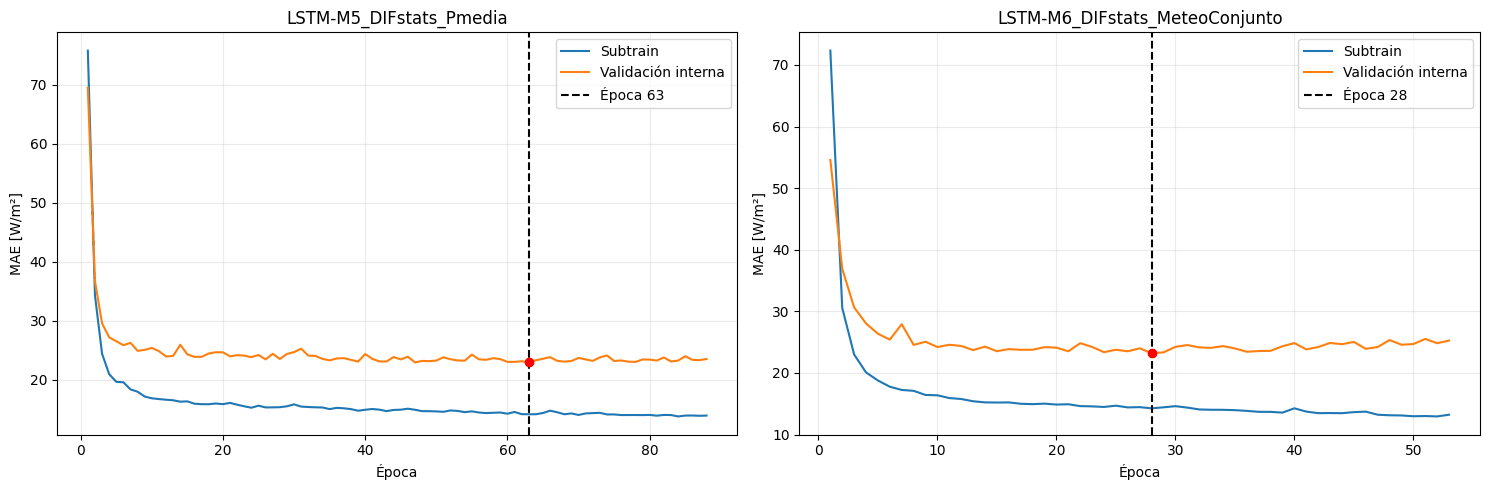


FASE 6B COMPLETADA
Resumen: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/ingenieria_caracteristicas_operacional_20261007T091724Z/02_seleccion_epocas/M5_M6_meteorologia/resumen_seleccion_M5_M6.csv
Validation externa utilizada: NO


In [ ]:
import time
import random
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# 1. Configuración
SEED = 42
N_SUBTRAIN = 4428
BATCH_SIZE = 128
MAX_EPOCHS = 300
PATIENCE = 25
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
assert "LSTMRegresor" in globals()
with open(PUNTERO, "r", encoding="utf-8") as f:
    puntero = json.load(f)

RUTA_M5 = Path(puntero["matrices_M5_original"])
RUTA_M6 = Path(puntero["matrices_M6_original"])
RUN_DIR = RUTA_M5.parents[1]
DIR_SELECCION = RUN_DIR / "02_seleccion_epocas" / "M5_M6_meteorologia"
DIR_FIGURAS = RUN_DIR / "06_figuras" / "M5_M6_meteorologia"
DIR_SELECCION.mkdir(parents=True, exist_ok=True)
DIR_FIGURAS.mkdir(parents=True, exist_ok=True)
print("Dispositivo:", DEVICE)
print("Validation externa utilizada: NO")


# 2. Reproducibilidad
def fijar_semilla_meteo():
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


# 3. Función genérica de selección
def seleccionar_epoca_lstm(nombre, ruta_npz, clave_X, clave_canales):
    with np.load(ruta_npz, allow_pickle=False) as z:
        X = z[clave_X].astype(np.float32)
        y = z["y_train"].astype(np.float32)
        fechas = pd.to_datetime(z["timestamps_train"])
        canales = z[clave_canales].astype(str).tolist()

    n_features = X.shape[2]
    X_sub_raw = X[:N_SUBTRAIN]
    y_sub_raw = y[:N_SUBTRAIN]
    X_int_raw = X[N_SUBTRAIN:]
    y_int_raw = y[N_SUBTRAIN:]

    # Escalado ajustado solo con subtrain
    mx = X_sub_raw.mean(axis=(0, 1), keepdims=True).astype(np.float32)
    sx = X_sub_raw.std(axis=(0, 1), keepdims=True).astype(np.float32)
    sx = np.where(sx < 1e-8, 1.0, sx)
    my = np.float32(y_sub_raw.mean())
    sy = np.float32(y_sub_raw.std())
    X_sub = ((X_sub_raw - mx) / sx).astype(np.float32)
    X_int = ((X_int_raw - mx) / sx).astype(np.float32)
    y_sub = ((y_sub_raw - my) / sy).astype(np.float32)
    dataset = TensorDataset(torch.from_numpy(X_sub), torch.from_numpy(y_sub))
    X_int_tensor = torch.from_numpy(X_int)
    fijar_semilla_meteo()
    generador = torch.Generator()
    generador.manual_seed(SEED)
    loader = DataLoader(
        dataset, batch_size=BATCH_SIZE, shuffle=True, generator=generador, num_workers=0
    )
    modelo = LSTMRegresor(n_features).to(DEVICE)
    optimizador = torch.optim.Adam(modelo.parameters(), lr=1e-3, weight_decay=1e-5)
    criterio = nn.L1Loss()
    mejor_mae = np.inf
    mejor_epoca = 0
    mejor_estado = None
    sin_mejora = 0
    historial = []
    inicio_total = time.perf_counter()
    for epoca in range(1, MAX_EPOCHS + 1):
        modelo.train()
        suma = 0.0
        n = 0
        for xb, yb in loader:
            xb = xb.to(DEVICE)
            yb = yb.to(DEVICE)
            optimizador.zero_grad(set_to_none=True)
            pred = modelo(xb)
            perdida = criterio(pred, yb)
            perdida.backward()
            torch.nn.utils.clip_grad_norm_(modelo.parameters(), 1.0)
            optimizador.step()
            suma += perdida.item() * len(xb)
            n += len(xb)

        train_mae = (suma / n) * float(sy)

        # Predicción de validación interna
        modelo.eval()
        predicciones = []
        with torch.no_grad():
            for inicio in range(0, len(X_int_tensor), 512):
                lote = X_int_tensor[inicio : inicio + 512].to(DEVICE)
                predicciones.append(modelo(lote).cpu().numpy())

        pred_int = np.concatenate(predicciones) * sy + my
        val_mae = float(np.mean(np.abs(y_int_raw - pred_int)))
        historial.append(
            {
                "modelo": nombre,
                "epoca": epoca,
                "train_MAE": train_mae,
                "validation_interna_MAE": val_mae,
            }
        )
        if val_mae < mejor_mae - 1e-8:
            mejor_mae = val_mae
            mejor_epoca = epoca
            sin_mejora = 0
            mejor_estado = {k: v.detach().cpu().clone() for k, v in modelo.state_dict().items()}
        else:
            sin_mejora += 1

        if epoca == 1 or epoca % 10 == 0 or sin_mejora == PATIENCE:
            print(
                f"{nombre:35s} | "
                f"época={epoca:3d} | "
                f"train={train_mae:7.3f} | "
                f"val={val_mae:7.3f} | "
                f"mínimo={mejor_mae:7.3f} "
                f"(época {mejor_epoca}) | "
                f"sin mejora={sin_mejora}"
            )

        if sin_mejora >= PATIENCE:
            break

    tiempo_minutos = (time.perf_counter() - inicio_total) / 60
    historial = pd.DataFrame(historial)
    ruta_historial = DIR_SELECCION / f"historial_{nombre}.csv"
    ruta_checkpoint = DIR_SELECCION / f"checkpoint_subtrain_{nombre}.pt"
    historial.to_csv(ruta_historial, index=False)
    torch.save(
        {
            "modelo": nombre,
            "epoca_seleccionada": mejor_epoca,
            "MAE_interno_minimo": mejor_mae,
            "model_state_dict": mejor_estado,
            "media_X": mx,
            "std_X": sx,
            "media_y": my,
            "std_y": sy,
            "canales": canales,
            "n_features": n_features,
            "seed": SEED,
            "patience": PATIENCE,
            "protocolo": "original",
        },
        ruta_checkpoint,
    )
    return {
        "modelo": nombre,
        "configuracion": (
            "DIFstats + Pmedia"
            if nombre.endswith("Pmedia")
            else "DIFstats + T2quad + RHquad + Pmedia"
        ),
        "epoca_seleccionada": mejor_epoca,
        "MAE_interno_minimo": mejor_mae,
        "ultima_epoca_ejecutada": int(historial["epoca"].max()),
        "n_features": n_features,
        "patience": PATIENCE,
        "tiempo_minutos": tiempo_minutos,
        "ruta_historial": str(ruta_historial),
        "ruta_checkpoint": str(ruta_checkpoint),
    }, historial


# 4. Ejecutar ambos modelos
experimentos = [
    {
        "nombre": "LSTM-M5_DIFstats_Pmedia",
        "ruta": RUTA_M5,
        "clave_X": "X_train_M5",
        "clave_canales": "canales_M5",
    },
    {
        "nombre": "LSTM-M6_DIFstats_MeteoConjunto",
        "ruta": RUTA_M6,
        "clave_X": "X_train_M6",
        "clave_canales": "canales_M6",
    },
]
resultados = []
historiales = {}
for experimento in experimentos:
    print("\n" + "=" * 82)
    print(experimento["nombre"])
    print("=" * 82)
    resultado, historial = seleccionar_epoca_lstm(
        nombre=experimento["nombre"],
        ruta_npz=experimento["ruta"],
        clave_X=experimento["clave_X"],
        clave_canales=experimento["clave_canales"],
    )
    resultados.append(resultado)
    historiales[experimento["nombre"]] = historial


# 5. Guardar resumen y curvas
resumen_seleccion = pd.DataFrame(resultados).sort_values("MAE_interno_minimo")
RUTA_RESUMEN_SELECCION = DIR_SELECCION / "resumen_seleccion_M5_M6.csv"
resumen_seleccion.to_csv(RUTA_RESUMEN_SELECCION, index=False)
print("\nRESUMEN DE SELECCIÓN:")
display(resumen_seleccion)
fig, ejes = plt.subplots(1, 2, figsize=(15, 5))
for eje, (nombre, historia) in zip(ejes, historiales.items()):
    fila = resumen_seleccion[resumen_seleccion["modelo"] == nombre].iloc[0]
    epoca_optima = int(fila["epoca_seleccionada"])
    mae_optimo = float(fila["MAE_interno_minimo"])
    eje.plot(historia["epoca"], historia["train_MAE"], label="Subtrain")
    eje.plot(historia["epoca"], historia["validation_interna_MAE"], label="Validación interna")
    eje.axvline(epoca_optima, color="black", linestyle="--", label=f"Época {epoca_optima}")
    eje.scatter(epoca_optima, mae_optimo, color="red", zorder=5)
    eje.set_title(nombre)
    eje.set_xlabel("Época")
    eje.set_ylabel("MAE [W/m²]")
    eje.grid(alpha=0.25)
    eje.legend()

plt.tight_layout()
RUTA_FIGURA = DIR_FIGURAS / "seleccion_epocas_M5_M6.png"
plt.savefig(RUTA_FIGURA, dpi=160, bbox_inches="tight")
plt.show()


# 6. Actualizar puntero
puntero["seleccion_M5_M6_original"] = str(RUTA_RESUMEN_SELECCION)
puntero["figura_seleccion_M5_M6"] = str(RUTA_FIGURA)
puntero["fase_actual"] = "fase_6B_seleccion_M5_M6_completada"
with open(PUNTERO, "w", encoding="utf-8") as f:
    json.dump(puntero, f, ensure_ascii=False, indent=2)

print("\nFASE 6B COMPLETADA")
print("Resumen:", RUTA_RESUMEN_SELECCION)
print("Validation externa utilizada: NO")


LSTM-M5_DIFstats_Pmedia
LSTM-M5_DIFstats_Pmedia                |   1/63 | MAE train=75.6481
LSTM-M5_DIFstats_Pmedia                |   5/63 | MAE train=20.2835
LSTM-M5_DIFstats_Pmedia                |  10/63 | MAE train=17.5836
LSTM-M5_DIFstats_Pmedia                |  15/63 | MAE train=16.9875
LSTM-M5_DIFstats_Pmedia                |  20/63 | MAE train=16.6900
LSTM-M5_DIFstats_Pmedia                |  25/63 | MAE train=16.3822
LSTM-M5_DIFstats_Pmedia                |  30/63 | MAE train=16.4837
LSTM-M5_DIFstats_Pmedia                |  35/63 | MAE train=15.9572
LSTM-M5_DIFstats_Pmedia                |  40/63 | MAE train=15.8241
LSTM-M5_DIFstats_Pmedia                |  45/63 | MAE train=15.5867
LSTM-M5_DIFstats_Pmedia                |  50/63 | MAE train=15.7335
LSTM-M5_DIFstats_Pmedia                |  55/63 | MAE train=15.6129
LSTM-M5_DIFstats_Pmedia                |  60/63 | MAE train=15.3965
LSTM-M5_DIFstats_Pmedia                |  63/63 | MAE train=15.7041

LSTM-M6_DIFstats_Meteo

,modelo,epocas,n_features,tiempo_minutos,ruta_modelo,ruta_historial
0,LSTM-M5_DIFstats_Pmedia,63,5,1.404032,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...
1,LSTM-M6_DIFstats_MeteoConjunto,28,11,0.524800,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...



MÉTRICAS OFICIALES EN VALIDATION:


,modelo,version_objetivo,ambito,n,DIF_media,DIF_mediana,MAE,nMAE_pct,RMSE,R2,sesgo
0,LSTM-M5_DIFstats_Pmedia,original,total,1464,85.233276,30.591667,15.711499,18.433527,32.189193,0.911361,-1.802432
1,LSTM-M6_DIFstats_MeteoConjunto,original,total,1464,85.233276,30.591667,16.645805,19.529703,33.390270,0.904623,-0.895740
2,LSTM-M5_DIFstats_Pmedia,original,operacion,884,141.797562,127.733337,25.621197,18.068856,41.420453,0.847943,-2.651244
3,LSTM-M6_DIFstats_MeteoConjunto,original,operacion,884,141.797562,127.733337,27.189985,19.175214,42.964656,0.836394,-1.631995
4,LSTM-M5_DIFstats_Pmedia,original,completamente_diurno,765,162.723083,145.683334,29.164705,17.922906,44.500060,0.797467,-3.103366
5,LSTM-M6_DIFstats_MeteoConjunto,original,completamente_diurno,765,162.723083,145.683334,30.741070,18.891647,46.127773,0.782380,-2.109083
6,LSTM-M5_DIFstats_Pmedia,original,transicion,119,7.276421,4.850000,2.841489,39.050644,3.826729,0.708703,0.255257
7,LSTM-M6_DIFstats_MeteoConjunto,original,transicion,119,7.276421,4.850000,4.361587,59.941371,5.858961,0.317156,1.435000
8,LSTM-M6_DIFstats_MeteoConjunto,original,noche,580,-0.978506,-1.000000,0.575022,NaN,0.828791,-5.825548,0.226415
9,LSTM-M5_DIFstats_Pmedia,original,noche,580,-0.978506,-1.000000,0.607757,NaN,0.691160,-3.746845,-0.508725


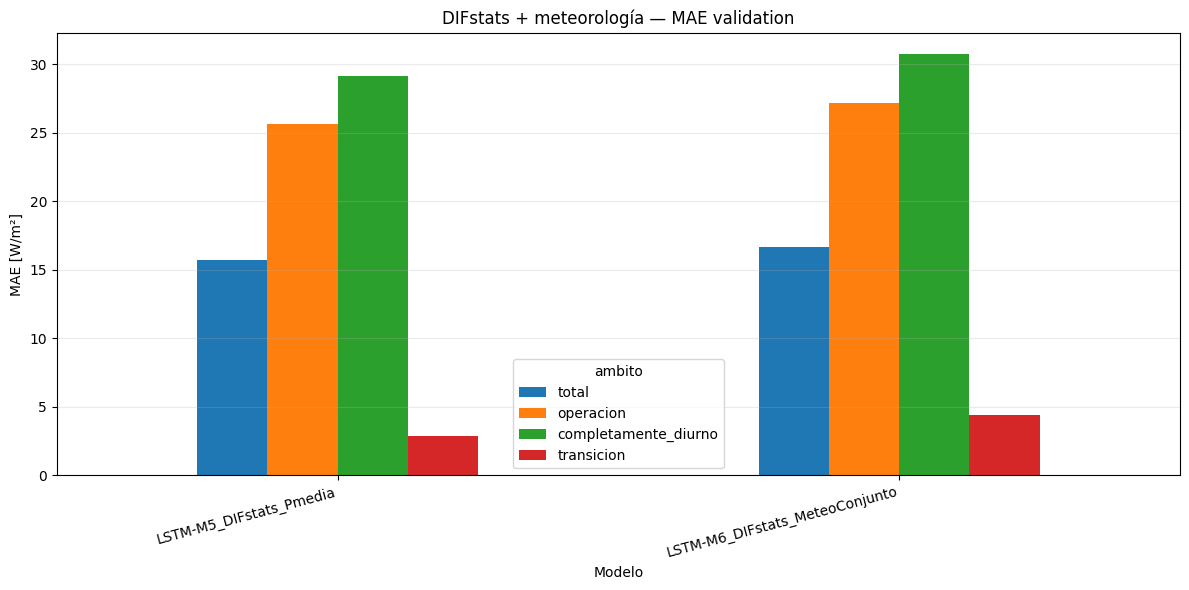


FASE 6C COMPLETADA
Métricas: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/ingenieria_caracteristicas_operacional_20261007T091724Z/05_metricas/M5_M6_meteorologia/metricas_validation_M5_M6.csv
Predicciones: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/ingenieria_caracteristicas_operacional_20261007T091724Z/04_predicciones/M5_M6_meteorologia/predicciones_validation_M5_M6.csv
Modelos: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/ingenieria_caracteristicas_operacional_20261007T091724Z/03_modelos/M5_M6_meteorologia
Test utilizado: NO


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

EPOCAS_METEO = {"LSTM-M5_DIFstats_Pmedia": 63, "LSTM-M6_DIFstats_MeteoConjunto": 28}
DIR_MODELOS = RUN_DIR / "03_modelos" / "M5_M6_meteorologia"
DIR_PREDICCIONES = RUN_DIR / "04_predicciones" / "M5_M6_meteorologia"
DIR_METRICAS = RUN_DIR / "05_metricas" / "M5_M6_meteorologia"
DIR_LOGS = RUN_DIR / "08_logs" / "M5_M6_meteorologia"
DIR_FIGURAS_FINAL = RUN_DIR / "06_figuras" / "M5_M6_meteorologia"
for directorio in [DIR_MODELOS, DIR_PREDICCIONES, DIR_METRICAS, DIR_LOGS, DIR_FIGURAS_FINAL]:
    directorio.mkdir(parents=True, exist_ok=True)


# 1. Función de reentrenamiento genérica
def reentrenar_lstm_meteo(
    nombre, ruta_npz, clave_X_train, clave_X_validation, clave_canales, epocas
):
    with np.load(ruta_npz, allow_pickle=False) as z:
        X_train_raw = z[clave_X_train].astype(np.float32)
        X_validation_raw = z[clave_X_validation].astype(np.float32)
        y_train_raw = z["y_train"].astype(np.float32)
        y_validation_raw = z["y_validation"].astype(np.float32)
        fechas_validation = pd.to_datetime(z["timestamps_validation"])
        canales = z[clave_canales].astype(str).tolist()

    n_features = X_train_raw.shape[2]

    # Escaladores ajustados con todo train
    mx = X_train_raw.mean(axis=(0, 1), keepdims=True).astype(np.float32)
    sx = X_train_raw.std(axis=(0, 1), keepdims=True).astype(np.float32)
    sx = np.where(sx < 1e-8, 1.0, sx)
    my = np.float32(y_train_raw.mean())
    sy = np.float32(y_train_raw.std())
    X_train = ((X_train_raw - mx) / sx).astype(np.float32)
    X_validation = ((X_validation_raw - mx) / sx).astype(np.float32)
    y_train = ((y_train_raw - my) / sy).astype(np.float32)
    dataset = TensorDataset(torch.from_numpy(X_train), torch.from_numpy(y_train))
    generador = torch.Generator()
    generador.manual_seed(SEED)
    loader = DataLoader(dataset, batch_size=128, shuffle=True, generator=generador, num_workers=0)
    fijar_semilla_meteo()
    modelo = LSTMRegresor(n_features).to(DEVICE)
    optimizador = torch.optim.Adam(modelo.parameters(), lr=1e-3, weight_decay=1e-5)
    criterio = nn.L1Loss()
    historial = []
    inicio_total = time.perf_counter()
    for epoca in range(1, epocas + 1):
        modelo.train()
        suma = 0.0
        n = 0
        for xb, yb in loader:
            xb = xb.to(DEVICE)
            yb = yb.to(DEVICE)
            optimizador.zero_grad(set_to_none=True)
            pred = modelo(xb)
            perdida = criterio(pred, yb)
            perdida.backward()
            torch.nn.utils.clip_grad_norm_(modelo.parameters(), 1.0)
            optimizador.step()
            suma += perdida.item() * len(xb)
            n += len(xb)

        train_mae = (suma / n) * float(sy)
        historial.append({"modelo": nombre, "epoca": epoca, "train_MAE": train_mae})
        if epoca == 1 or epoca % 5 == 0 or epoca == epocas:
            print(f"{nombre:38s} | " f"{epoca:3d}/{epocas} | " f"MAE train={train_mae:.4f}")

    tiempo_minutos = (time.perf_counter() - inicio_total) / 60

    # Predicción externa
    modelo.eval()
    X_validation_tensor = torch.from_numpy(X_validation)
    predicciones = []
    with torch.no_grad():
        for inicio in range(0, len(X_validation_tensor), 512):
            lote = X_validation_tensor[inicio : inicio + 512].to(DEVICE)
            predicciones.append(modelo(lote).cpu().numpy())

    pred_validation = (np.concatenate(predicciones) * sy + my).astype(np.float32)
    ruta_modelo = DIR_MODELOS / f"{nombre}.pt"
    torch.save(
        {
            "modelo": nombre,
            "epocas": epocas,
            "n_features": n_features,
            "model_state_dict": {k: v.detach().cpu() for k, v in modelo.state_dict().items()},
            "media_X": mx,
            "std_X": sx,
            "media_y": my,
            "std_y": sy,
            "canales": canales,
            "seed": SEED,
            "tiempo_minutos": tiempo_minutos,
            "protocolo": "original",
        },
        ruta_modelo,
    )
    historial = pd.DataFrame(historial)
    ruta_historial = DIR_LOGS / f"historial_{nombre}.csv"
    historial.to_csv(ruta_historial, index=False)
    return {
        "prediccion": pred_validation,
        "y_validation": y_validation_raw,
        "fechas_validation": fechas_validation,
        "resumen": {
            "modelo": nombre,
            "epocas": epocas,
            "n_features": n_features,
            "tiempo_minutos": tiempo_minutos,
            "ruta_modelo": str(ruta_modelo),
            "ruta_historial": str(ruta_historial),
        },
    }


# 2. Reentrenar M5 y M6
experimentos = [
    {
        "nombre": "LSTM-M5_DIFstats_Pmedia",
        "ruta": RUTA_M5,
        "X_train": "X_train_M5",
        "X_validation": "X_validation_M5",
        "canales": "canales_M5",
    },
    {
        "nombre": "LSTM-M6_DIFstats_MeteoConjunto",
        "ruta": RUTA_M6,
        "X_train": "X_train_M6",
        "X_validation": "X_validation_M6",
        "canales": "canales_M6",
    },
]
resultados = {}
resumen_entrenamiento = []
for experimento in experimentos:
    nombre = experimento["nombre"]
    print("\n" + "=" * 85)
    print(nombre)
    print("=" * 85)
    resultado = reentrenar_lstm_meteo(
        nombre=nombre,
        ruta_npz=experimento["ruta"],
        clave_X_train=experimento["X_train"],
        clave_X_validation=experimento["X_validation"],
        clave_canales=experimento["canales"],
        epocas=EPOCAS_METEO[nombre],
    )
    resultados[nombre] = resultado
    resumen_entrenamiento.append(resultado["resumen"])

resumen_entrenamiento = pd.DataFrame(resumen_entrenamiento)
RUTA_RESUMEN_ENTRENAMIENTO = DIR_LOGS / "resumen_reentrenamiento_M5_M6.csv"
resumen_entrenamiento.to_csv(RUTA_RESUMEN_ENTRENAMIENTO, index=False)
print("\nResumen de entrenamiento:")
display(resumen_entrenamiento)


# 3. Regímenes solares
RUTA_VALIDATION_HGB = (
    BASE_DIR / "documentacion/checkpoint_continuidad_modelado_20261006_125123/"
    "validation_hgb.parquet"
)
validation_hgb = pd.read_parquet(RUTA_VALIDATION_HGB)
regimen = validation_hgb["regimen_solar_objetivo"].astype(str).str.lower().to_numpy()
noche = np.array(["noche" in x for x in regimen])
transicion = np.array(["trans" in x for x in regimen])
diurno = np.array(["complet" in x and "diurn" in x for x in regimen])
mascaras = {
    "total": np.ones(1464, dtype=bool),
    "operacion": ~noche,
    "completamente_diurno": diurno,
    "transicion": transicion,
    "noche": noche,
}
assert {k: int(v.sum()) for k, v in mascaras.items()} == {
    "total": 1464,
    "operacion": 884,
    "completamente_diurno": 765,
    "transicion": 119,
    "noche": 580,
}


# 4. Métricas oficiales
def calcular_metricas(nombre, real, pred):
    filas = []
    for ambito, mascara in mascaras.items():
        y_real = real[mascara]
        y_pred = pred[mascara]
        media = float(y_real.mean())
        mae = float(mean_absolute_error(y_real, y_pred))
        filas.append(
            {
                "modelo": nombre,
                "version_objetivo": "original",
                "ambito": ambito,
                "n": int(mascara.sum()),
                "DIF_media": media,
                "DIF_mediana": float(np.median(y_real)),
                "MAE": mae,
                "nMAE_pct": (np.nan if ambito == "noche" or media <= 0 else 100 * mae / media),
                "RMSE": float(np.sqrt(mean_squared_error(y_real, y_pred))),
                "R2": float(r2_score(y_real, y_pred)),
                "sesgo": float(np.mean(y_pred - y_real)),
            }
        )

    return pd.DataFrame(filas)

metricas = pd.concat(
    [
        calcular_metricas(nombre, resultado["y_validation"], resultado["prediccion"])
        for nombre, resultado in resultados.items()
    ],
    ignore_index=True,
)
orden = {"total": 0, "operacion": 1, "completamente_diurno": 2, "transicion": 3, "noche": 4}
metricas["orden"] = metricas["ambito"].map(orden)
metricas = metricas.sort_values(["orden", "MAE"]).drop(columns="orden").reset_index(drop=True)
RUTA_METRICAS = DIR_METRICAS / "metricas_validation_M5_M6.csv"
metricas.to_csv(RUTA_METRICAS, index=False)
print("\nMÉTRICAS OFICIALES EN VALIDATION:")
display(metricas)


# 5. Guardar predicciones
primer_resultado = next(iter(resultados.values()))
predicciones_df = pd.DataFrame(
    {
        "instante_objetivo": (primer_resultado["fechas_validation"]),
        "DIF_real": (primer_resultado["y_validation"]),
        "regimen_solar": regimen,
    }
)
for nombre, resultado in resultados.items():
    predicciones_df[f"pred_{nombre}"] = resultado["prediccion"]

RUTA_PREDICCIONES = DIR_PREDICCIONES / "predicciones_validation_M5_M6.csv"
predicciones_df.to_csv(RUTA_PREDICCIONES, index=False)


# 6. Figura comparativa
tabla_figura = (
    metricas[metricas["ambito"].isin(["total", "operacion", "completamente_diurno", "transicion"])]
    .pivot(index="modelo", columns="ambito", values="MAE")
    .reindex(columns=["total", "operacion", "completamente_diurno", "transicion"])
)
ax = tabla_figura.plot(kind="bar", figsize=(12, 6))
ax.set_title("DIFstats + meteorología — MAE validation")
ax.set_xlabel("Modelo")
ax.set_ylabel("MAE [W/m²]")
ax.grid(axis="y", alpha=0.25)
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
RUTA_FIGURA = DIR_FIGURAS_FINAL / "comparacion_MAE_M5_M6.png"
plt.savefig(RUTA_FIGURA, dpi=160, bbox_inches="tight")
plt.show()


# 7. Actualizar puntero
puntero["modelos_M5_M6_original"] = str(DIR_MODELOS)
puntero["predicciones_M5_M6_original"] = str(RUTA_PREDICCIONES)
puntero["metricas_M5_M6_original"] = str(RUTA_METRICAS)
puntero["resumen_entrenamiento_M5_M6"] = str(RUTA_RESUMEN_ENTRENAMIENTO)
puntero["fase_actual"] = "fase_6C_M5_M6_reentrenados_y_validados"
with open(PUNTERO, "w", encoding="utf-8") as f:
    json.dump(puntero, f, ensure_ascii=False, indent=2)

print("\nFASE 6C COMPLETADA")
print("Métricas:", RUTA_METRICAS)
print("Predicciones:", RUTA_PREDICCIONES)
print("Modelos:", DIR_MODELOS)
print("Test utilizado: NO")

In [ ]:
import json
from pathlib import Path
import numpy as np
import pandas as pd

# 1. Recuperar comparación M1–M4 y métricas M5–M6
with open(PUNTERO, "r", encoding="utf-8") as f:
    puntero = json.load(f)

DIR_COMPARACION_ANTERIOR = Path(puntero["comparacion_M1_M2_M3_M4"])
RUTA_M1_M4 = DIR_COMPARACION_ANTERIOR / "metricas_completas_M1_M2_M3_M4.csv"
RUTA_M5_M6 = Path(puntero["metricas_M5_M6_original"])
tabla_M1_M4 = pd.read_csv(RUTA_M1_M4)
tabla_M5_M6 = pd.read_csv(RUTA_M5_M6)


# 2. Etiquetar M5 y M6
tabla_M5_M6["arquitectura"] = "LSTM"
tabla_M5_M6["bloque"] = np.where(tabla_M5_M6["modelo"].str.contains("M5"), "M5", "M6")
tabla_M5_M6["configuracion"] = np.where(
    tabla_M5_M6["bloque"] == "M5", "DIFstats + Pmedia", "DIFstats + T2quad + RHquad + Pmedia"
)
columnas = [
    "modelo",
    "arquitectura",
    "bloque",
    "configuracion",
    "version_objetivo",
    "ambito",
    "n",
    "DIF_media",
    "DIF_mediana",
    "MAE",
    "nMAE_pct",
    "RMSE",
    "R2",
    "sesgo",
]
tabla_completa = pd.concat([tabla_M1_M4[columnas], tabla_M5_M6[columnas]], ignore_index=True)

# Evitar duplicados si se ejecuta más de una vez
tabla_completa = tabla_completa.drop_duplicates(subset=["modelo", "ambito"], keep="last")


# 3. Ordenar
orden_bloques = {"M1": 1, "M2": 2, "M3": 3, "M4": 4, "M5": 5, "M6": 6}
orden_ambitos = {"total": 1, "operacion": 2, "completamente_diurno": 3, "transicion": 4, "noche": 5}
tabla_completa["orden_bloque"] = tabla_completa["bloque"].map(orden_bloques)
tabla_completa["orden_ambito"] = tabla_completa["ambito"].map(orden_ambitos)
tabla_completa = tabla_completa.sort_values(["arquitectura", "orden_bloque", "orden_ambito"])


# 4. Comparar cada modelo con M1 de su arquitectura
referencia = tabla_completa[tabla_completa["bloque"] == "M1"][
    ["arquitectura", "ambito", "MAE"]
].rename(columns={"MAE": "MAE_M1_referencia"})
comparacion = tabla_completa.merge(referencia, on=["arquitectura", "ambito"], how="left")
comparacion["diferencia_MAE_vs_M1"] = comparacion["MAE"] - comparacion["MAE_M1_referencia"]
comparacion["cambio_pct_vs_M1"] = (
    100 * comparacion["diferencia_MAE_vs_M1"] / comparacion["MAE_M1_referencia"]
)
comparacion["resultado_vs_M1"] = np.select(
    [comparacion["diferencia_MAE_vs_M1"] < -1e-8, comparacion["diferencia_MAE_vs_M1"] > 1e-8],
    ["MEJORA", "EMPEORA"],
    default="IGUAL",
)


# 5. Tabla compacta de MAE
tabla_MAE = comparacion.pivot_table(
    index=["arquitectura", "bloque", "configuracion", "modelo"],
    columns="ambito",
    values="MAE",
    aggfunc="first",
).reset_index()
columnas_MAE = ["total", "operacion", "completamente_diurno", "transicion", "noche"]
for columna in columnas_MAE:
    if columna not in tabla_MAE.columns:
        tabla_MAE[columna] = np.nan

tabla_MAE = tabla_MAE[
    ["arquitectura", "bloque", "configuracion", "modelo"] + columnas_MAE
].sort_values(["arquitectura", "bloque"])


# 6. Tabla de cambio porcentual
tabla_cambio = (
    comparacion.pivot_table(
        index=["arquitectura", "bloque", "configuracion", "modelo"],
        columns="ambito",
        values="cambio_pct_vs_M1",
        aggfunc="first",
    )
    .reset_index()
    .rename(
        columns={
            "total": "cambio_total_pct",
            "operacion": "cambio_operacion_pct",
            "completamente_diurno": "cambio_diurno_pct",
            "transicion": "cambio_transicion_pct",
            "noche": "cambio_noche_pct",
        }
    )
)


# 7. Mostrar resultados
print("TABLA MAE M1–M6:")
display(
    tabla_MAE.style.format(
        {
            "total": "{:.3f}",
            "operacion": "{:.3f}",
            "completamente_diurno": "{:.3f}",
            "transicion": "{:.3f}",
            "noche": "{:.3f}",
        }
    )
)
print("\nCAMBIO FRENTE A M1 (negativo = mejora; positivo = empeora):")
display(
    tabla_cambio.style.format(
        {
            "cambio_total_pct": "{:+.2f}%",
            "cambio_operacion_pct": "{:+.2f}%",
            "cambio_diurno_pct": "{:+.2f}%",
            "cambio_transicion_pct": "{:+.2f}%",
            "cambio_noche_pct": "{:+.2f}%",
        }
    )
)
print("\nMÉTRICAS COMPLETAS M5 Y M6:")
display(
    comparacion[comparacion["bloque"].isin(["M5", "M6"])][
        [
            "modelo",
            "ambito",
            "MAE",
            "nMAE_pct",
            "RMSE",
            "R2",
            "sesgo",
            "diferencia_MAE_vs_M1",
            "cambio_pct_vs_M1",
            "resultado_vs_M1",
        ]
    ].style.format(
        {
            "MAE": "{:.3f}",
            "nMAE_pct": "{:.2f}",
            "RMSE": "{:.3f}",
            "R2": "{:.4f}",
            "sesgo": "{:.3f}",
            "diferencia_MAE_vs_M1": "{:+.3f}",
            "cambio_pct_vs_M1": "{:+.2f}%",
        }
    )
)


# 8. Guardar en Drive
DIR_COMPARACION = RUN_DIR / "07_comparaciones" / "comparacion_M1_M2_M3_M4_M5_M6"
DIR_COMPARACION.mkdir(parents=True, exist_ok=True)
RUTA_COMPLETA = DIR_COMPARACION / "metricas_completas_M1_M6.csv"
RUTA_TABLA_MAE = DIR_COMPARACION / "tabla_MAE_M1_M6.csv"
RUTA_CAMBIO = DIR_COMPARACION / "cambio_porcentual_vs_M1_M1_M6.csv"
RUTA_DETALLE = DIR_COMPARACION / "comparacion_detallada_M1_M6.csv"
tabla_completa.drop(columns=["orden_bloque", "orden_ambito"], errors="ignore").to_csv(
    RUTA_COMPLETA, index=False
)
tabla_MAE.to_csv(RUTA_TABLA_MAE, index=False)
tabla_cambio.to_csv(RUTA_CAMBIO, index=False)
comparacion.to_csv(RUTA_DETALLE, index=False)
puntero["comparacion_M1_M6"] = str(DIR_COMPARACION)
puntero["fase_actual"] = "comparacion_M1_M6_completada"
with open(PUNTERO, "w", encoding="utf-8") as f:
    json.dump(puntero, f, ensure_ascii=False, indent=2)

print("\nCOMPARACIÓN ACTUALIZADA")
print("Tabla MAE:", RUTA_TABLA_MAE)
print("Cambios:", RUTA_CAMBIO)
print("Detalle:", RUTA_DETALLE)

TABLA MAE M1–M6:


ambito,arquitectura,bloque,configuracion,modelo,total,operacion,completamente_diurno,transicion,noche
0,LSTM,M1,DIFstats,LSTM-DIFstats,15.699,25.698,29.279,2.678,0.459
1,LSTM,M2,DIFstats + SWD,LSTM-M2_DIFstats_SWD,16.200,26.110,29.501,4.308,1.097
2,LSTM,M3,DIFstats + SWD + DIR,LSTM-M3_DIFstats_SWD_DIR,15.851,25.894,29.448,3.049,0.544
3,LSTM,M4,DIFstats + SWD + DIR + FD,LSTM-M4_DIFstats_SWD_DIR_FD,16.081,26.185,29.440,5.259,0.682
4,LSTM,M5,DIFstats + Pmedia,LSTM-M5_DIFstats_Pmedia,15.711,25.621,29.165,2.841,0.608
5,LSTM,M6,DIFstats + T2quad + RHquad + Pmedia,LSTM-M6_DIFstats_MeteoConjunto,16.646,27.190,30.741,4.362,0.575
6,NBEATS,M1,DIFstats,NBEATS-DIFstats,17.585,28.332,32.047,4.449,1.204
7,NBEATS,M2,DIFstats + SWD,NBEATS-M2_DIFstats_SWD,18.168,29.339,33.038,5.559,1.142
8,NBEATS,M3,DIFstats + SWD + DIR,NBEATS-M3_DIFstats_SWD_DIR,19.418,31.570,35.726,4.852,0.898
9,NBEATS,M4,DIFstats + SWD + DIR + FD,NBEATS-M4_DIFstats_SWD_DIR_FD,18.935,30.696,34.605,5.566,1.009



CAMBIO FRENTE A M1 (negativo = mejora; positivo = empeora):


ambito,arquitectura,bloque,configuracion,modelo,cambio_diurno_pct,cambio_noche_pct,cambio_operacion_pct,cambio_total_pct,cambio_transicion_pct
0,LSTM,M1,DIFstats,LSTM-DIFstats,+0.00%,+0.00%,+0.00%,+0.00%,+0.00%
1,LSTM,M2,DIFstats + SWD,LSTM-M2_DIFstats_SWD,+0.76%,+138.77%,+1.60%,+3.19%,+60.84%
2,LSTM,M3,DIFstats + SWD + DIR,LSTM-M3_DIFstats_SWD_DIR,+0.58%,+18.43%,+0.76%,+0.97%,+13.82%
3,LSTM,M4,DIFstats + SWD + DIR + FD,LSTM-M4_DIFstats_SWD_DIR_FD,+0.55%,+48.43%,+1.90%,+2.44%,+96.34%
4,LSTM,M5,DIFstats + Pmedia,LSTM-M5_DIFstats_Pmedia,-0.39%,+32.30%,-0.30%,+0.08%,+6.09%
5,LSTM,M6,DIFstats + T2quad + RHquad + Pmedia,LSTM-M6_DIFstats_MeteoConjunto,+4.99%,+25.17%,+5.81%,+6.03%,+62.84%
6,NBEATS,M1,DIFstats,NBEATS-DIFstats,+0.00%,+0.00%,+0.00%,+0.00%,+0.00%
7,NBEATS,M2,DIFstats + SWD,NBEATS-M2_DIFstats_SWD,+3.09%,-5.14%,+3.55%,+3.32%,+24.94%
8,NBEATS,M3,DIFstats + SWD + DIR,NBEATS-M3_DIFstats_SWD_DIR,+11.48%,-25.38%,+11.43%,+10.43%,+9.05%
9,NBEATS,M4,DIFstats + SWD + DIR + FD,NBEATS-M4_DIFstats_SWD_DIR_FD,+7.98%,-16.18%,+8.34%,+7.68%,+25.10%



MÉTRICAS COMPLETAS M5 Y M6:


,modelo,ambito,MAE,nMAE_pct,RMSE,R2,sesgo,diferencia_MAE_vs_M1,cambio_pct_vs_M1,resultado_vs_M1
20,LSTM-M5_DIFstats_Pmedia,total,15.711,18.43,32.189,0.9114,-1.802,+0.012,+0.08%,EMPEORA
21,LSTM-M5_DIFstats_Pmedia,operacion,25.621,18.07,41.420,0.8479,-2.651,-0.077,-0.30%,MEJORA
22,LSTM-M5_DIFstats_Pmedia,completamente_diurno,29.165,17.92,44.500,0.7975,-3.103,-0.114,-0.39%,MEJORA
23,LSTM-M5_DIFstats_Pmedia,transicion,2.841,39.05,3.827,0.7087,0.255,+0.163,+6.09%,EMPEORA
24,LSTM-M5_DIFstats_Pmedia,noche,0.608,nan,0.691,-3.7468,-0.509,+0.148,+32.30%,EMPEORA
25,LSTM-M6_DIFstats_MeteoConjunto,total,16.646,19.53,33.390,0.9046,-0.896,+0.947,+6.03%,EMPEORA
26,LSTM-M6_DIFstats_MeteoConjunto,operacion,27.190,19.18,42.965,0.8364,-1.632,+1.492,+5.81%,EMPEORA
27,LSTM-M6_DIFstats_MeteoConjunto,completamente_diurno,30.741,18.89,46.128,0.7824,-2.109,+1.462,+4.99%,EMPEORA
28,LSTM-M6_DIFstats_MeteoConjunto,transicion,4.362,59.94,5.859,0.3172,1.435,+1.683,+62.84%,EMPEORA
29,LSTM-M6_DIFstats_MeteoConjunto,noche,0.575,nan,0.829,-5.8255,0.226,+0.116,+25.17%,EMPEORA



COMPARACIÓN ACTUALIZADA
Tabla MAE: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/ingenieria_caracteristicas_operacional_20261007T091724Z/07_comparaciones/comparacion_M1_M2_M3_M4_M5_M6/tabla_MAE_M1_M6.csv
Cambios: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/ingenieria_caracteristicas_operacional_20261007T091724Z/07_comparaciones/comparacion_M1_M2_M3_M4_M5_M6/cambio_porcentual_vs_M1_M1_M6.csv
Detalle: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/ingenieria_caracteristicas_operacional_20261007T091724Z/07_comparaciones/comparacion_M1_M2_M3_M4_M5_M6/comparacion_detallada_M1_M6.csv


**Resultados.** Se seleccionan 63 épocas para M5 y 28 para M6.

- La LSTM de M5 es la única combinación que reduce el MAE de M1 en operación (25,62 W/m²; −0,30 %) y en horas completamente diurnas (29,16 W/m²; −0,39 %), con sesgo negativo en operación (−2,65 W/m²); el MAE total apenas varía (15,71 W/m²; +0,08 %) y aumenta en transición (+6,09 %) y en noche (+32,30 %).
- La LSTM de M6 aumenta el MAE en todos los ámbitos: +6,03 % en total, +5,81 % en operación y +62,84 % en transición.